In [52]:
print("hello world")

hello world


# Vérification des images ACTIF et PASSIF


===== BILAN ACTIF =====
Dimensions : (2478, 3500)
Format : PNG
Mode : RGB


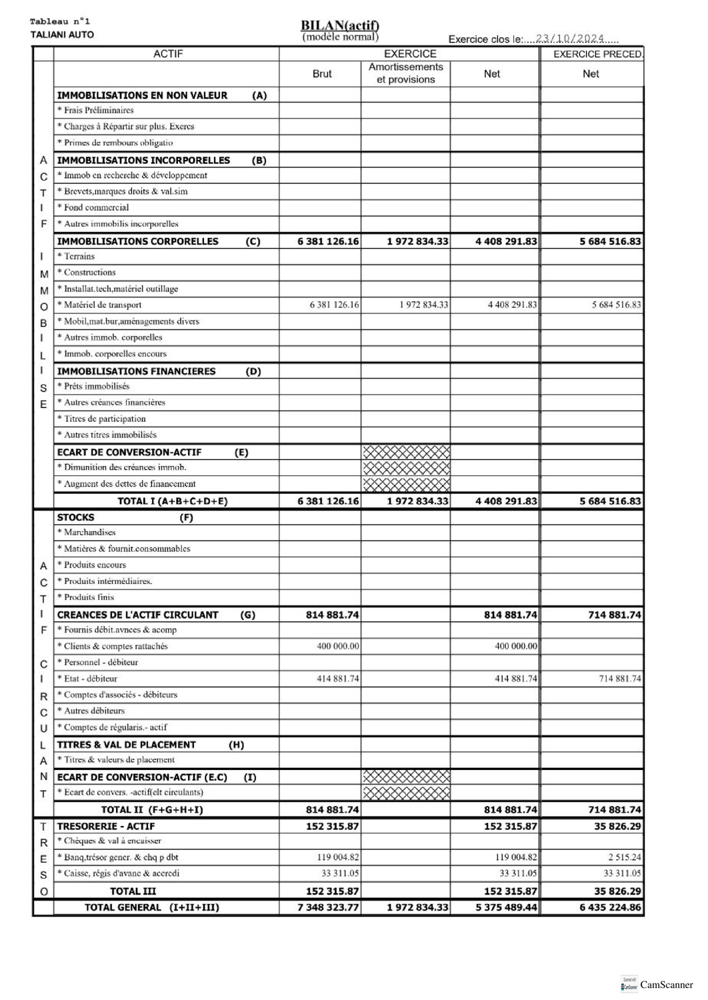


===== BILAN PASSIF =====
Dimensions : (2478, 3500)
Format : PNG
Mode : RGB


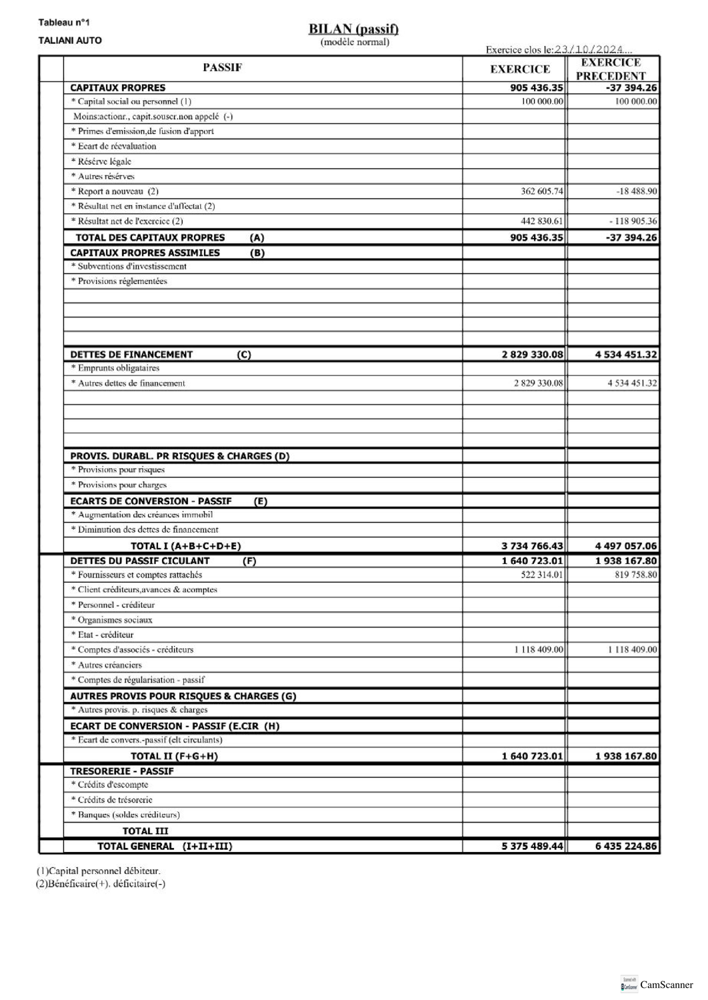


Les deux images sont disponibles.


In [53]:

# CELLULE 1 — Vérification des images du bilan

from pathlib import Path
from PIL import Image
from IPython.display import display

# Chemins des deux images
images = {
    "ACTIF": Path("/kaggle/working/images/page_1.png"),
    "PASSIF": Path("/kaggle/working/images/page_2.png")
}

for nom, chemin in images.items():

    # Vérifier l'existence du fichier
    if not chemin.is_file():
        raise FileNotFoundError(f"Image introuvable : {chemin}")

    # Ouvrir et vérifier l'image
    with Image.open(chemin) as img:
        img.verify()

    with Image.open(chemin) as img:
        print(f"\n===== BILAN {nom} =====")
        print("Dimensions :", img.size)
        print("Format :", img.format)
        print("Mode :", img.mode)

        # Aperçu (ne modifie pas l'image originale)
        preview = img.copy()
        preview.thumbnail((1100, 1500))
        display(preview)

print("\nLes deux images sont disponibles.")


# Découpage des images pour Qwen2.5-VL


===== ACTIF =====
Bande 1 : ACTIF_bande_1.png
Dimensions : (2478, 1376)


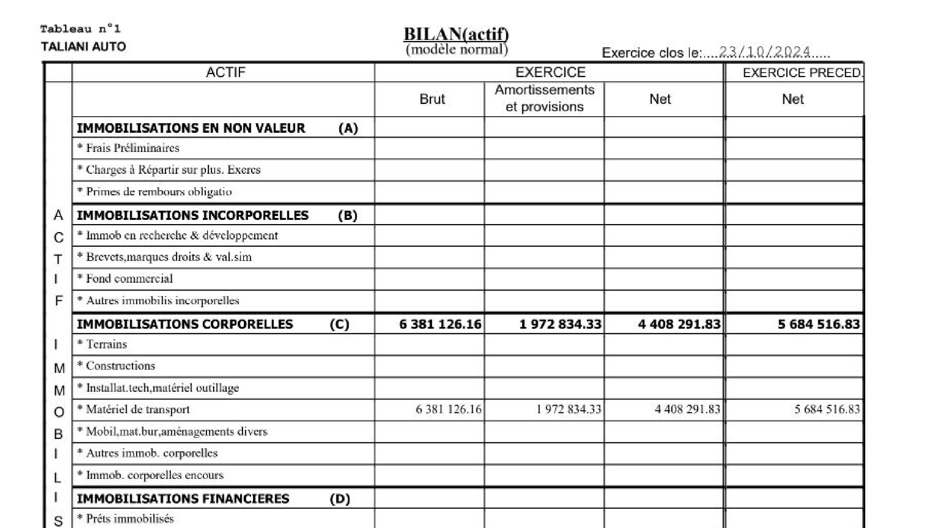

Bande 2 : ACTIF_bande_2.png
Dimensions : (2478, 1587)


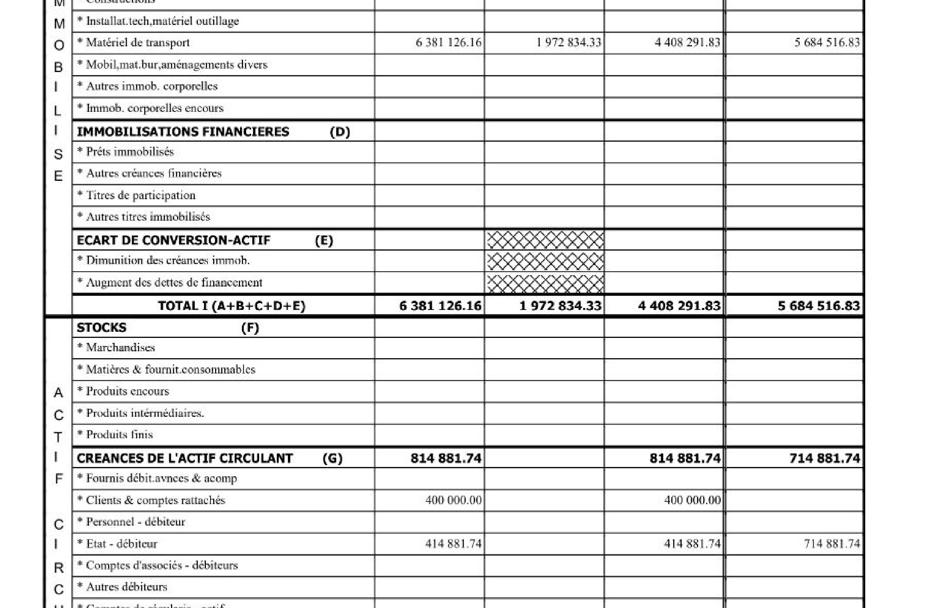

Bande 3 : ACTIF_bande_3.png
Dimensions : (2478, 1377)


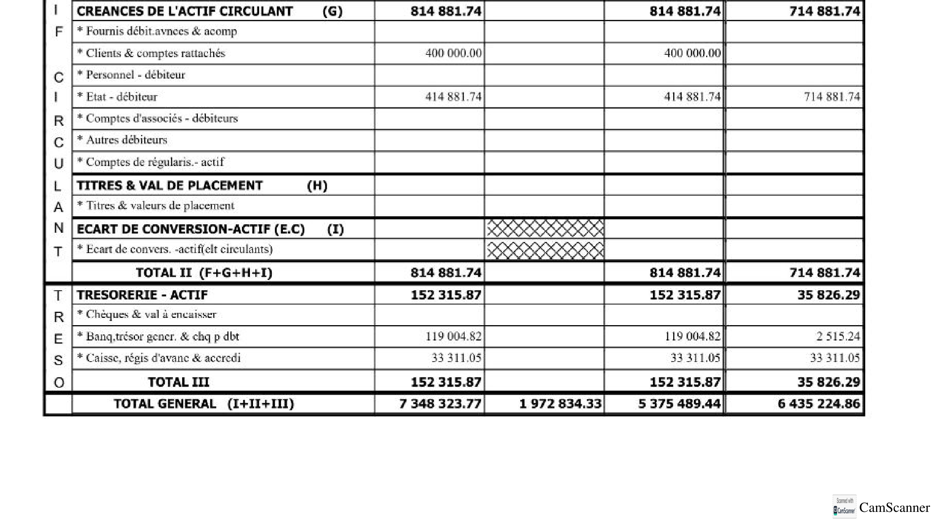


===== PASSIF =====
Bande 1 : PASSIF_bande_1.png
Dimensions : (2478, 1376)


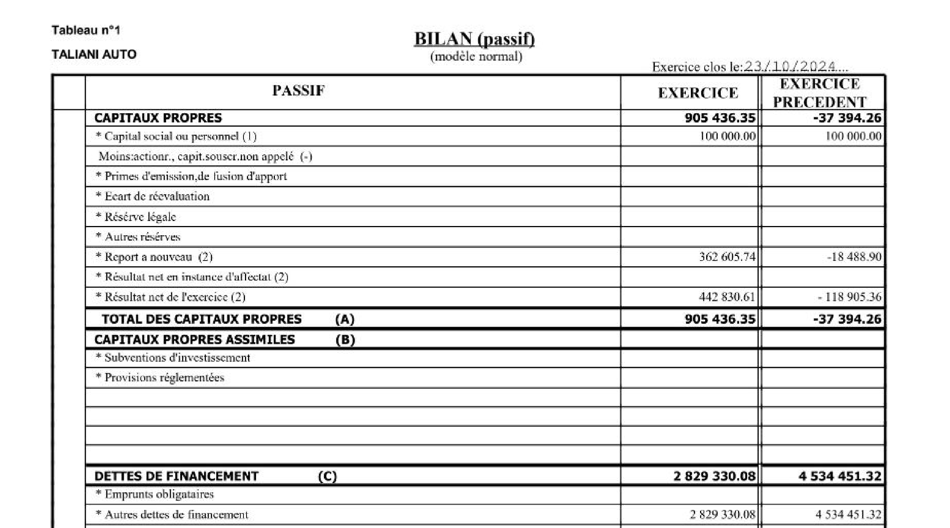

Bande 2 : PASSIF_bande_2.png
Dimensions : (2478, 1587)


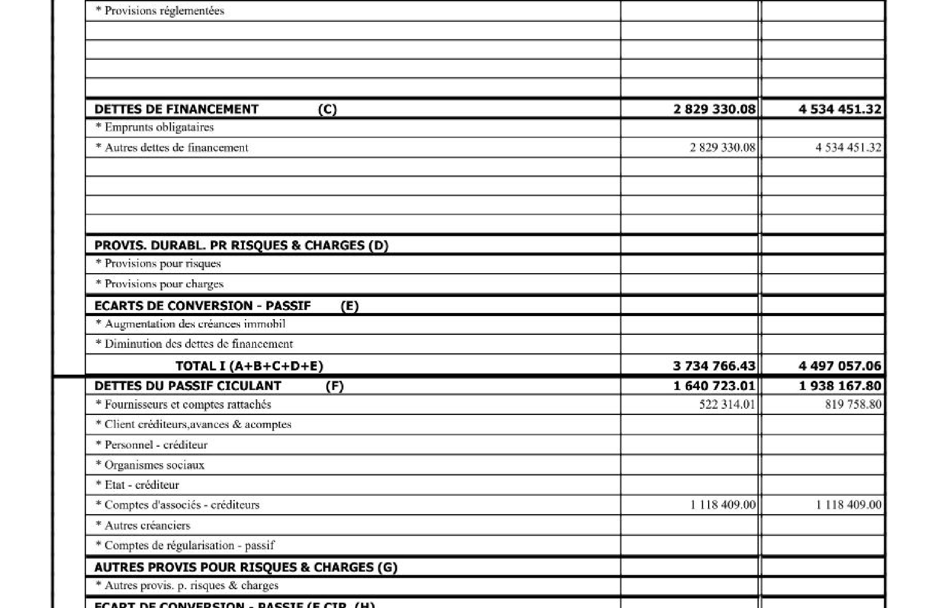

Bande 3 : PASSIF_bande_3.png
Dimensions : (2478, 1377)


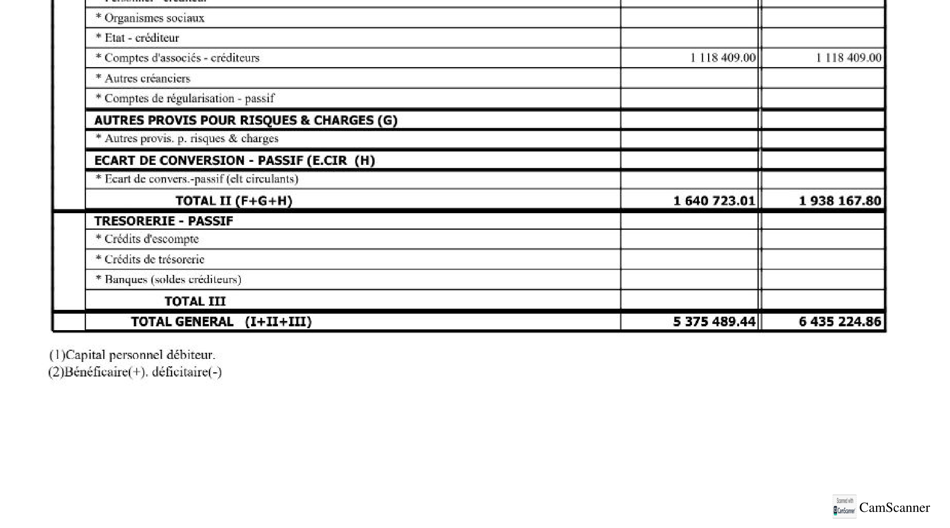


Découpage terminé !
Images ACTIF : 3
Images PASSIF : 3


In [54]:

# CELLULE 2 — Découpage en bandes avec chevauchement

from PIL import Image
from pathlib import Path
from IPython.display import display

output_dir = Path("/kaggle/working/decoupage")
output_dir.mkdir(parents=True, exist_ok=True)

# Images préparées dans la cellule 1
pages = {
    "ACTIF": "/kaggle/working/images/page_1.png",
    "PASSIF": "/kaggle/working/images/page_2.png"
}

nombre_bandes = 3
chevauchement = 0.06  # 6 % de la hauteur de chaque côté

# Nous conserverons les chemins pour l'extraction VLM
bandes_images = {}

for type_bilan, image_path in pages.items():

    image = Image.open(image_path).convert("RGB")
    largeur, hauteur = image.size

    bandes_images[type_bilan] = []

    print(f"\n===== {type_bilan} =====")

    for i in range(nombre_bandes):

        # Calculer les limites verticales
        debut = max(
            0,
            int((i / nombre_bandes - chevauchement) * hauteur)
        )

        fin = min(
            hauteur,
            int(((i + 1) / nombre_bandes + chevauchement) * hauteur)
        )

        # Conserver toute la largeur du tableau
        bande = image.crop((0, debut, largeur, fin))

        # Enregistrer l'image découpée
        chemin = output_dir / f"{type_bilan}_bande_{i+1}.png"
        bande.save(chemin)

        bandes_images[type_bilan].append(str(chemin))

        print(f"Bande {i+1} : {chemin.name}")
        print(f"Dimensions : {bande.size}")

        # Afficher un aperçu
        apercu = bande.copy()
        apercu.thumbnail((950, 950))
        display(apercu)

print("\nDécoupage terminé !")
print("Images ACTIF :", len(bandes_images["ACTIF"]))
print("Images PASSIF :", len(bandes_images["PASSIF"]))


# Créer le prompt d'extraction complète de l'ACTIF

In [55]:

# CELLULE 3 — Prompt d'extraction complète de l'ACTIF

from pathlib import Path

def construire_messages_actif(chemin_image, numero_bande):

    instructions = """
Tu analyses une partie d'un BILAN ACTIF marocain scanné.

OBJECTIF :
Reconstruire fidèlement le tableau visible dans l'image.

ARCHITECTURE DU TABLEAU :
- Colonne 1 : Désignation du poste comptable
- Colonne 2 : Exercice actuel - BRUT
- Colonne 3 : Exercice actuel - AMORTISSEMENTS ET PROVISIONS
- Colonne 4 : Exercice actuel - NET
- Colonne 5 : Exercice précédent - NET

TRAVAIL DEMANDÉ :
1. Lire le tableau ligne par ligne, de haut en bas.
2. Extraire toutes les lignes comptables visibles.
3. Conserver l'ordre original des lignes.
4. Extraire chaque montant dans sa colonne exacte.
5. Conserver les rubriques, détails, sous-totaux et totaux.
6. Conserver les noms tels qu'ils apparaissent dans l'image.
7. Ne pas fusionner deux lignes différentes.
8. Ne pas inventer de postes ou de montants.
9. Une cellule vide ou illisible doit contenir null.
10. Ne pas transformer une cellule vide en zéro.
11. Ne pas calculer ou corriger les montants.
12. Ne pas inclure les lignes de titre des colonnes
    comme des postes comptables.
13. Si une ligne est coupée et illisible, ne pas
    inventer son contenu.
14. Une ligne visible dans plusieurs bandes pourra
    être dédupliquée plus tard par Python.

FORMAT NUMÉRIQUE :
- 1 250 000,50 devient 1250000.50
- -15 000,25 devient -15000.25
- Les nombres doivent être numériques, pas des chaînes.
- Les cellules vides deviennent null.

TYPE DE LIGNE :
- section : titre de grande partie
- rubrique : groupe de postes
- detail : poste comptable détaillé
- sous_total : ligne de sous-total
- total_general : TOTAL GENERAL du bilan

FORMAT JSON OBLIGATOIRE :
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom exact de la ligne",
      "type_ligne": "detail",
      "brut_N": null,
      "amortissements_provisions_N": null,
      "net_N": null,
      "net_N1": null
    }
  ]
}

Remplacer les valeurs null par les montants lus.
Garder null lorsqu'une cellule est vide ou illisible.

Retourner uniquement un objet JSON valide.
Ne pas écrire de texte en dehors du JSON.
"""

    return [
        {
            "role": "system",
            "content": (
                "Tu es un système de reconnaissance de tableaux "
                "comptables marocains. Tu transcris exactement "
                "les cellules visibles, sans inventer de valeurs."
            )
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin_image).resolve().as_uri(),
                    "max_pixels": 1280 * 28 * 28
                },
                {
                    "type": "text",
                    "text": (
                        f"Ceci est la bande {numero_bande} "
                        "de la page ACTIF.\n\n"
                        + instructions
                    )
                }
            ]
        }
    ]


# Préparer les trois bandes ACTIF
messages_actif_bandes = []

for i, chemin in enumerate(bandes_images["ACTIF"], start=1):

    messages = construire_messages_actif(
        chemin_image=chemin,
        numero_bande=i
    )

    messages_actif_bandes.append(messages)

    print(f"Prompt ACTIF bande {i} : OK")

print("\nNombre de prompts :", len(messages_actif_bandes))


Prompt ACTIF bande 1 : OK
Prompt ACTIF bande 2 : OK
Prompt ACTIF bande 3 : OK

Nombre de prompts : 3


# Créer le prompt d'extraction complète du PASSIF

In [56]:

# CELLULE 4 — Prompt d'extraction complète du PASSIF

from pathlib import Path

def construire_messages_passif(chemin_image, numero_bande):

    instructions = """
Tu analyses une partie d'un BILAN PASSIF marocain scanné.

OBJECTIF :
Reconstruire fidèlement le tableau visible dans l'image.

ARCHITECTURE DU TABLEAU :
- Colonne 1 : Désignation du poste comptable
- Colonne 2 : Montant de l'exercice actuel (N)
- Colonne 3 : Montant de l'exercice précédent (N-1)

Le PASSIF est organisé en trois grandes parties :
I. FINANCEMENT PERMANENT
II. PASSIF CIRCULANT
III. TRESORERIE-PASSIF

TRAVAIL DEMANDÉ :
1. Lire le tableau ligne par ligne, de haut en bas.
2. Extraire toutes les lignes comptables visibles.
3. Conserver exactement l'ordre original des lignes.
4. Extraire les montants dans leurs colonnes respectives.
5. Conserver les sections, rubriques, détails et totaux.
6. Conserver les noms tels qu'ils apparaissent.
7. Ne pas fusionner deux lignes différentes.
8. Ne pas inventer de postes ou de montants.
9. Une cellule vide ou illisible doit contenir null.
10. Ne jamais remplacer une cellule vide par zéro.
11. Ne pas calculer ou corriger les montants.
12. Ne pas inclure les en-têtes des colonnes comme postes.
13. Si une ligne est partiellement coupée,
    ne pas inventer les informations manquantes.
14. Des lignes peuvent apparaître dans plusieurs bandes.
    Leur déduplication sera effectuée plus tard.
15. Extraire TOTAL GENERAL si cette ligne est visible.

FORMAT NUMÉRIQUE :
- 1 250 000,50 devient 1250000.50
- -15 000,25 devient -15000.25
- Les nombres sont des valeurs JSON numériques.
- Les cellules vides ou illisibles deviennent null.

TYPE DE LIGNE :
- section : titre de grande partie
- rubrique : catégorie de postes
- detail : poste comptable détaillé
- sous_total : sous-total comptable, y compris TOTAL I,
  TOTAL II et TOTAL III
- total_general : TOTAL GENERAL du bilan

FORMAT JSON OBLIGATOIRE :
{
  "type_bilan": "PASSIF",
  "lignes": [
    {
      "poste": "nom exact de la ligne",
      "type_ligne": "detail",
      "montant_N": null,
      "montant_N1": null
    }
  ]
}

Remplacer les valeurs null par les montants lus.
Conserver null si la cellule est vide ou illisible.

Retourner uniquement un objet JSON valide.
Ne pas écrire de texte en dehors du JSON.
"""

    return [
        {
            "role": "system",
            "content": (
                "Tu es un système de reconnaissance de tableaux "
                "comptables marocains. Tu transcris fidèlement "
                "les cellules visibles sans inventer de valeurs."
            )
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin_image).resolve().as_uri(),
                    "max_pixels": 1280 * 28 * 28
                },
                {
                    "type": "text",
                    "text": (
                        f"Ceci est la bande {numero_bande} "
                        "de la page PASSIF.\n\n"
                        + instructions
                    )
                }
            ]
        }
    ]


# Préparer les trois bandes PASSIF
messages_passif_bandes = []

for i, chemin in enumerate(bandes_images["PASSIF"], start=1):

    messages = construire_messages_passif(
        chemin_image=chemin,
        numero_bande=i
    )

    messages_passif_bandes.append(messages)

    print(f"Prompt PASSIF bande {i} : OK")

print("\nNombre de prompts :", len(messages_passif_bandes))


Prompt PASSIF bande 1 : OK
Prompt PASSIF bande 2 : OK
Prompt PASSIF bande 3 : OK

Nombre de prompts : 3


# Créer la fonction d'extraction avec Qwen2.5-VL

In [57]:

# CELLULE 5 — Fonction réutilisable d'extraction VLM

import torch
import json
import re
import time

from qwen_vl_utils import process_vision_info

model.eval()

def extraire_avec_vlm(messages, max_tokens=2600):

    # 1. Préparer le prompt
    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # 2. Préparer l'image
    image_inputs, video_inputs = process_vision_info(messages)

    # 3. Construire les tenseurs
    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to("cuda:0")

    # 4. Exécuter Qwen2.5-VL
    debut = time.perf_counter()

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            num_beams=1
        )

    torch.cuda.synchronize()
    duree = time.perf_counter() - debut

    # 5. Récupérer les nouveaux tokens
    new_tokens = generated_ids[
        :, inputs.input_ids.shape[1]:
    ]

    nb_tokens = new_tokens.shape[1]

    # 6. Décoder la réponse
    texte = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )[0].strip()

    # 7. Nettoyer les éventuelles balises Markdown
    texte_json = re.sub(
        r"^\s*```(?:json)?\s*",
        "",
        texte,
        flags=re.IGNORECASE
    )

    texte_json = re.sub(
        r"\s*```\s*$",
        "",
        texte_json
    ).strip()

    # 8. Vérifier la validité du JSON
    donnees = None
    erreur = None

    try:
        donnees = json.loads(texte_json)

        if not isinstance(donnees, dict):
            raise ValueError("La racine doit être un objet JSON.")

        if not isinstance(donnees.get("lignes"), list):
            raise ValueError("Le champ 'lignes' est absent ou invalide.")

        if donnees.get("type_bilan") not in ("ACTIF", "PASSIF"):
            raise ValueError("Type de bilan invalide.")

    except (json.JSONDecodeError, ValueError) as e:
        donnees = None
        erreur = str(e)

    # 9. Détecter une possible troncature
    tronque = nb_tokens >= max_tokens

    # 10. Déterminer le statut
    statut = "OK"

    if erreur:
        statut = "JSON_INVALIDE"
    elif tronque:
        statut = "LIMITE_TOKENS_ATTEINTE"

    # 11. Nettoyer la mémoire GPU
    del inputs, generated_ids, new_tokens
    torch.cuda.empty_cache()

    return {
        "statut": statut,
        "donnees": donnees,
        "texte_brut": texte,
        "erreur": erreur,
        "tronque": tronque,
        "nombre_tokens": nb_tokens,
        "temps_secondes": round(duree, 2)
    }


# Dictionnaires pour conserver les extractions
resultats_actif = {}
resultats_passif = {}

print("Fonction extraire_avec_vlm() prête !")
print("Stockage des résultats initialisé.")


Fonction extraire_avec_vlm() prête !
Stockage des résultats initialisé.


# Extraire toutes les lignes et colonnes de l'ACTIF avec Qwen2.5-VL


In [58]:

# CELLULE 6 — Extraction complète de l'ACTIF

import pandas as pd
import time
start_time = time.time()

# Vérifier que les 3 prompts existent
assert len(messages_actif_bandes) == 3, (
    "Il faut exactement 3 prompts ACTIF."
)

# Réinitialiser les résultats ACTIF
resultats_actif = {}

# Extraire chaque bande
for i, messages in enumerate(messages_actif_bandes, start=1):

    print(f"\n{'=' * 50}")
    print(f"EXTRACTION ACTIF — BANDE {i}/3")
    print(f"{'=' * 50}")

    # Appeler Qwen2.5-VL
    resultat = extraire_avec_vlm(
        messages,
        max_tokens=2600
    )

    # Stocker le résultat
    resultats_actif[i] = resultat

    # Afficher les informations
    print("Statut :", resultat["statut"])
    print("Temps :", resultat["temps_secondes"], "secondes")
    print("Tokens générés :", resultat["nombre_tokens"])

    if resultat["donnees"] is not None:

        lignes = resultat["donnees"]["lignes"]

        print("Nombre de lignes extraites :", len(lignes))

        # Prévisualiser les premières lignes
        df_apercu = pd.DataFrame(lignes)

        display(df_apercu.head(10))

    else:
        print("Erreur JSON :", resultat["erreur"])
        print("Derniers caractères de la réponse :")
        print(resultat["texte_brut"][-500:])

# Résumé général
print("\n========== RÉSUMÉ ACTIF ==========")

total_lignes = 0
toutes_bandes_ok = True

for i, resultat in resultats_actif.items():

    valide = resultat["statut"] == "OK"

    if not valide:
        toutes_bandes_ok = False

    nb_lignes = (
        len(resultat["donnees"]["lignes"])
        if resultat["donnees"] is not None
        else 0
    )

    total_lignes += nb_lignes

    print(
        f"Bande {i} : {resultat['statut']} "
        f"| {nb_lignes} lignes"
    )

print("\nTotal des lignes extraites :", total_lignes)

if toutes_bandes_ok:
    print("Les 3 réponses JSON ont été récupérées.")
    print("Prochaine étape : reconstruction et validation.")
else:
    print("ATTENTION : au moins une extraction doit être corrigée.")

print("Aucun CSV final n'a été créé.")

end_time = time.time()
elapsed_time = end_time - start_time

print(f"Elapsed time: {elapsed_time:.2f} seconds")


EXTRACTION ACTIF — BANDE 1/3
Statut : OK
Temps : 76.7 secondes
Tokens générés : 1307
Nombre de lignes extraites : 19


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,IMMOBILISATIONS EN NON VALEUR (A),section,NaN,NaN,NaN,NaN
1,* Frais Préliminaires,detail,NaN,NaN,NaN,NaN
2,* Charges à Répartir sur plus. Exercs,detail,NaN,NaN,NaN,NaN
3,* Primes de rembours obligatio,detail,NaN,NaN,NaN,NaN
4,IMMOBILISATIONS INCORPORELLES (B),section,NaN,NaN,NaN,NaN
5,* Immob en recherche & développement,detail,NaN,NaN,NaN,NaN
6,"* Brevets,marques droits & val.sim",detail,NaN,NaN,NaN,NaN
7,* Fond commercial,detail,NaN,NaN,NaN,NaN
8,* Autres immobilis incorporelles,detail,NaN,NaN,NaN,NaN
9,IMMOBILISATIONS CORPORELLES (C),section,6381126.16,1972834.33,4408291.83,5684516.83



EXTRACTION ACTIF — BANDE 2/3
Statut : OK
Temps : 120.05 secondes
Tokens générés : 1934
Nombre de lignes extraites : 28


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,* Installat.tech.matériel outillage,detail,NaN,NaN,NaN,NaN
1,* Matériel de transport,detail,6381126.16,1972834.33,4408291.83,5684516.83
2,* Mobil.mat.bur.aménagements divers,detail,NaN,NaN,NaN,NaN
3,* Autres immob. corporelles,detail,NaN,NaN,NaN,NaN
4,* Immob. corporelles encours,detail,NaN,NaN,NaN,NaN
5,IMMOBILISATIONS FINANCIERES (D),section,NaN,NaN,NaN,NaN
6,* Prêts immobilisés,detail,NaN,NaN,NaN,NaN
7,* Autres créances financières,detail,NaN,NaN,NaN,NaN
8,* Titres de participation,detail,NaN,NaN,NaN,NaN
9,* Autres titres immobilisés,detail,NaN,NaN,NaN,NaN



EXTRACTION ACTIF — BANDE 3/3
Statut : OK
Temps : 59.91 secondes
Tokens générés : 1045
Nombre de lignes extraites : 15


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,Fournis débit. avances & acomp,detail,814881.74,None,None,None
1,Clients & comptes rattachés,detail,400000.00,None,None,None
2,Personnel - débiteur,detail,NaN,None,None,None
3,Etat - débiteur,detail,414881.74,None,None,None
4,Comptes associés - débiteurs,detail,NaN,None,None,None
5,Autres débiteurs,detail,NaN,None,None,None
6,Comptes régularis. - actif,detail,NaN,None,None,None
7,Titres & valeurs de placement,detail,NaN,None,None,None
8,Ecart conversion - actif (E.C),detail,NaN,None,None,None
9,Tresorerie - actif,detail,152315.87,None,None,None



========== RÉSUMÉ ACTIF ==========
Bande 1 : OK | 19 lignes
Bande 2 : OK | 28 lignes
Bande 3 : OK | 15 lignes

Total des lignes extraites : 62
Les 3 réponses JSON ont été récupérées.
Prochaine étape : reconstruction et validation.
Aucun CSV final n'a été créé.
Elapsed time: 257.08 seconds


# Extraire toutes les lignes et colonnes du PASSIF avec Qwen2.5-VL

In [59]:

# CELLULE 7 — Extraction complète du PASSIF

import pandas as pd

# Vérifier que les trois prompts PASSIF sont préparés
assert len(messages_passif_bandes) == 3, (
    "Il faut exactement 3 prompts PASSIF."
)

# Réinitialiser les résultats
resultats_passif = {}

# Extraction des trois bandes
for i, messages in enumerate(messages_passif_bandes, start=1):

    print(f"\n{'=' * 50}")
    print(f"EXTRACTION PASSIF — BANDE {i}/3")
    print(f"{'=' * 50}")

    # Exécuter le VLM
    resultat = extraire_avec_vlm(
        messages,
        max_tokens=2600
    )

    # Conserver le résultat en mémoire
    resultats_passif[i] = resultat

    print("Statut :", resultat["statut"])
    print("Temps :", resultat["temps_secondes"], "secondes")
    print("Tokens générés :", resultat["nombre_tokens"])

    if resultat["donnees"] is not None:

        # Récupérer les lignes extraites
        lignes = resultat["donnees"]["lignes"]

        print("Nombre de lignes extraites :", len(lignes))

        # Afficher les dix premières lignes
        df_apercu = pd.DataFrame(lignes)
        display(df_apercu.head(10))

    else:
        print("Erreur JSON :", resultat["erreur"])
        print("Fin de la réponse brute :")
        print(resultat["texte_brut"][-500:])


# Résumé des trois bandes
print("\n========== RÉSUMÉ PASSIF ==========")

total_lignes = 0
toutes_bandes_ok = True

for i, resultat in resultats_passif.items():

    valide = resultat["statut"] == "OK"

    if not valide:
        toutes_bandes_ok = False

    nb_lignes = (
        len(resultat["donnees"]["lignes"])
        if resultat["donnees"] is not None
        else 0
    )

    total_lignes += nb_lignes

    print(
        f"Bande {i} : {resultat['statut']} "
        f"| {nb_lignes} lignes"
    )

print("\nTotal des lignes extraites :", total_lignes)

if toutes_bandes_ok:
    print("Les trois réponses JSON PASSIF ont été récupérées.")
    print("Prochaine étape : reconstruction et validation.")
else:
    print("ATTENTION : certaines extractions sont incomplètes.")

print("Aucun CSV final n'a été créé.")



EXTRACTION PASSIF — BANDE 1/3
Statut : OK
Temps : 47.86 secondes
Tokens générés : 837
Nombre de lignes extraites : 15


,poste,type_ligne,montant_N,montant_N1
0,CAPITAUX PROPRES,sous_total,905436.35,-37394.26
1,* Capital social ou personnel (1),detail,100000.00,100000.00
2,"* Moins:actionn., capit.souscr.non appelé (-)",detail,NaN,NaN
3,"* Primes d'émission,de fusion d'apport",detail,NaN,NaN
4,* Ecart de réévaluation,detail,NaN,NaN
5,* Réserve légale,detail,NaN,NaN
6,* Autres réserves,detail,NaN,NaN
7,* Report a nouveau (2),detail,362605.74,-18488.90
8,* Résultat net en instance d'affectat (2),detail,NaN,NaN
9,* Résultat net de l'exercice (2),detail,442830.61,-118905.36



EXTRACTION PASSIF — BANDE 2/3
Statut : OK
Temps : 79.04 secondes
Tokens générés : 1337
Nombre de lignes extraites : 26


,poste,type_ligne,montant_N,montant_N1
0,* Provisions réglementées,section,NaN,NaN
1,DETTES DE FINANCEMENT (C),sous_total,2829330.08,4534451.32
2,* Emprunts obligataires,rubrique,NaN,NaN
3,* Autres dettes de financement,rubrique,2829330.08,4534451.32
4,PROVIS. DURABL. PR RISQUES & CHARGES (D),sous_total,NaN,NaN
5,* Provisions pour risques,rubrique,NaN,NaN
6,* Provisions pour charges,rubrique,NaN,NaN
7,ECARTS DE CONVERSION - PASSIF (E),sous_total,NaN,NaN
8,* Augmentation des créances immobilières,rubrique,NaN,NaN
9,* Diminution des dettes de financement,rubrique,NaN,NaN



EXTRACTION PASSIF — BANDE 3/3
Statut : OK
Temps : 47.31 secondes
Tokens générés : 833
Nombre de lignes extraites : 16


,poste,type_ligne,montant_N,montant_N1
0,* Organismes sociaux,section,NaN,NaN
1,* Etat - créditeur,section,NaN,NaN
2,* Comptes d'associés - créanciers,rubrique,1118409.00,1118409.0
3,* Autres créanciers,rubrique,NaN,NaN
4,* Comptes de régularisation - passif,rubrique,NaN,NaN
5,AUTRES PROVISIO POUR RISQUES & CHARGES (G),rubrique,NaN,NaN
6,* Autres provis. p. risques & charges,rubrique,NaN,NaN
7,ECART DE CONVERSION - PASSIF (E.CIR (H)),rubrique,NaN,NaN
8,* Ecart de convers.-passif (elt circulants),rubrique,NaN,NaN
9,TOTAL II (F+G+H),sous_total,1640723.01,1938167.8



========== RÉSUMÉ PASSIF ==========
Bande 1 : OK | 15 lignes
Bande 2 : OK | 26 lignes
Bande 3 : OK | 16 lignes

Total des lignes extraites : 57
Les trois réponses JSON PASSIF ont été récupérées.
Prochaine étape : reconstruction et validation.
Aucun CSV final n'a été créé.


# Reconstruire les tableaux ACTIF et PASSIF avec Pandas

In [60]:

# CELLULE 8 — Reconstruction ACTIF et PASSIF

import pandas as pd
import re
import unicodedata
import math

COLONNES = {
    "ACTIF": [
        "poste",
        "type_ligne",
        "brut_N",
        "amortissements_provisions_N",
        "net_N",
        "net_N1"
    ],
    "PASSIF": [
        "poste",
        "type_ligne",
        "montant_N",
        "montant_N1"
    ]
}

def normaliser_texte(texte):
    texte = unicodedata.normalize("NFKD", str(texte))
    texte = "".join(
        c for c in texte if not unicodedata.combining(c)
    )
    return " ".join(texte.casefold().split())


def lignes_identiques(a, b, type_bilan):
    # Comparer les noms et le type de ligne
    for champ in ("poste", "type_ligne"):
        if normaliser_texte(a.get(champ)) != normaliser_texte(b.get(champ)):
            return False

    # Comparer toutes les valeurs, sans confondre 0 et null
    for champ in COLONNES[type_bilan][2:]:
        if a.get(champ) != b.get(champ):
            return False

    return True


def reconstruire_bilan(resultats, type_bilan):
    anomalies = []
    lignes_finales = []
    doublons_supprimes = 0

    for numero_bande in (1, 2, 3):

        resultat = resultats.get(numero_bande)

        if resultat is None or resultat["statut"] != "OK":
            anomalies.append(
                f"{type_bilan} : bande {numero_bande} absente ou invalide"
            )
            continue

        donnees = resultat["donnees"]

        if donnees.get("type_bilan") != type_bilan:
            anomalies.append(
                f"Bande {numero_bande} : mauvais type de bilan"
            )
            continue

        lignes = donnees["lignes"]

        # Vérifier le schéma de chaque ligne
        lignes_valides = []

        for position, ligne in enumerate(lignes, start=1):

            if not isinstance(ligne, dict):
                anomalies.append(
                    f"Bande {numero_bande}, ligne {position} : format invalide"
                )
                continue

            champs_manquants = [
                c for c in COLONNES[type_bilan] if c not in ligne
            ]

            if champs_manquants:
                anomalies.append(
                    f"Bande {numero_bande}, ligne {position} : "
                    f"champs manquants {champs_manquants}"
                )
                continue

            for champ in COLONNES[type_bilan][2:]:
                valeur = ligne[champ]

                if valeur is not None and (
                    isinstance(valeur, bool)
                    or not isinstance(valeur, (int, float))
                    or not math.isfinite(valeur)
                ):
                    anomalies.append(
                        f"Bande {numero_bande}, ligne {position} : "
                        f"montant invalide dans {champ}"
                    )

            lignes_valides.append({
                champ: ligne[champ]
                for champ in COLONNES[type_bilan]
            })

        # Identifier le chevauchement exact entre les bandes
        nb_doublons = 0

        if lignes_finales and lignes_valides:

            maximum = min(
                len(lignes_finales),
                len(lignes_valides)
            )

            for k in range(maximum, 0, -1):

                fin_precedente = lignes_finales[-k:]
                debut_suivante = lignes_valides[:k]

                if all(
                    lignes_identiques(a, b, type_bilan)
                    for a, b in zip(
                        fin_precedente,
                        debut_suivante
                    )
                ):
                    nb_doublons = k
                    break

        doublons_supprimes += nb_doublons

        # Ne conserver qu'une copie des lignes communes
        lignes_finales.extend(lignes_valides[nb_doublons:])

        print(
            f"{type_bilan} - Bande {numero_bande} : "
            f"{len(lignes_valides)} lignes, "
            f"{nb_doublons} doublons supprimés"
        )

    # Construire le DataFrame
    df = pd.DataFrame(
        lignes_finales,
        columns=COLONNES[type_bilan]
    )

    rapport = {
        "type_bilan": type_bilan,
        "nombre_lignes": len(df),
        "doublons_supprimes": doublons_supprimes,
        "anomalies": anomalies,
        "structure_valide": len(anomalies) == 0
    }

    return df, rapport


# 1. Reconstruire ACTIF
df_actif, rapport_actif = reconstruire_bilan(
    resultats_actif,
    "ACTIF"
)

# 2. Reconstruire PASSIF
df_passif, rapport_passif = reconstruire_bilan(
    resultats_passif,
    "PASSIF"
)

# 3. Afficher les tableaux
print("\n========== TABLEAU ACTIF ==========")
print("Nombre de lignes :", len(df_actif))
display(df_actif)

print("\n========== TABLEAU PASSIF ==========")
print("Nombre de lignes :", len(df_passif))
display(df_passif)

# 4. Afficher les anomalies éventuelles
print("\n========== RAPPORT DE RECONSTRUCTION ==========")

for rapport in (rapport_actif, rapport_passif):
    print("\n", rapport["type_bilan"])
    print("Lignes :", rapport["nombre_lignes"])
    print("Doublons retirés :", rapport["doublons_supprimes"])
    print("Anomalies :", rapport["anomalies"])

print("\nAucun CSV final n'a encore été créé.")


ACTIF - Bande 1 : 19 lignes, 0 doublons supprimés
ACTIF - Bande 2 : 28 lignes, 0 doublons supprimés
ACTIF - Bande 3 : 15 lignes, 0 doublons supprimés
PASSIF - Bande 1 : 15 lignes, 0 doublons supprimés
PASSIF - Bande 2 : 26 lignes, 0 doublons supprimés
PASSIF - Bande 3 : 16 lignes, 0 doublons supprimés

========== TABLEAU ACTIF ==========
Nombre de lignes : 62


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,IMMOBILISATIONS EN NON VALEUR (A),section,NaN,NaN,NaN,NaN
1,* Frais Préliminaires,detail,NaN,NaN,NaN,NaN
2,* Charges à Répartir sur plus. Exercs,detail,NaN,NaN,NaN,NaN
3,* Primes de rembours obligatio,detail,NaN,NaN,NaN,NaN
4,IMMOBILISATIONS INCORPORELLES (B),section,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
57,Chèques & val à encaisser,detail,NaN,NaN,NaN,NaN
58,Banq.trésor gen. & chq p dbt,detail,119004.82,NaN,NaN,NaN
59,"Caisse, régis d'avanc & accreddi",detail,33311.05,NaN,NaN,NaN
60,Total III,sous_total,152315.87,NaN,NaN,NaN



========== TABLEAU PASSIF ==========
Nombre de lignes : 57


,poste,type_ligne,montant_N,montant_N1
0,CAPITAUX PROPRES,sous_total,905436.35,-37394.26
1,* Capital social ou personnel (1),detail,100000.00,100000.00
2,"* Moins:actionn., capit.souscr.non appelé (-)",detail,NaN,NaN
3,"* Primes d'émission,de fusion d'apport",detail,NaN,NaN
4,* Ecart de réévaluation,detail,NaN,NaN
5,* Réserve légale,detail,NaN,NaN
6,* Autres réserves,detail,NaN,NaN
7,* Report a nouveau (2),detail,362605.74,-18488.90
8,* Résultat net en instance d'affectat (2),detail,NaN,NaN
9,* Résultat net de l'exercice (2),detail,442830.61,-118905.36



========== RAPPORT DE RECONSTRUCTION ==========

 ACTIF
Lignes : 62
Doublons retirés : 0
Anomalies : []

 PASSIF
Lignes : 57
Doublons retirés : 0
Anomalies : []

Aucun CSV final n'a encore été créé.


# Vérification automatique des montants de l'ACTIF

In [61]:

# CELLULE 9 — Contrôle BRUT - AMORTISSEMENTS = NET

import pandas as pd
from decimal import Decimal, InvalidOperation

def convertir_montant(valeur):
    """Convertir un montant extrait en Decimal."""
    if pd.isna(valeur):
        return None

    try:
        montant = Decimal(str(valeur))
        if not montant.is_finite():
            return None
        return montant.quantize(Decimal("0.01"))
    except (InvalidOperation, ValueError):
        return None


def verifier_lignes_actif(df):
    resultats = []
    tolerance = Decimal("0.01")

    for index, ligne in df.iterrows():

        poste = ligne["poste"]
        type_ligne = ligne["type_ligne"]

        brut = convertir_montant(ligne["brut_N"])
        amort = convertir_montant(
            ligne["amortissements_provisions_N"]
        )
        net = convertir_montant(ligne["net_N"])

        calcul = None
        difference = None

        # Cas 1 : aucune valeur présente
        if brut is None and amort is None and net is None:
            statut = "NON_APPLICABLE"

        # Cas 2 : une valeur est manquante ou illisible
        elif brut is None or amort is None or net is None:
            statut = "A_VERIFIER"

        # Cas 3 : toutes les valeurs sont disponibles
        else:
            calcul = brut - amort
            difference = calcul - net

            if abs(difference) <= tolerance:
                statut = "OK"
            else:
                statut = "ERREUR"

        resultats.append({
            "ligne": index + 1,
            "poste": poste,
            "type_ligne": type_ligne,
            "brut_N": brut,
            "amort_N": amort,
            "net_N_extrait": net,
            "net_N_calcule": calcul,
            "difference": difference,
            "statut": statut
        })

    return pd.DataFrame(resultats)


# Exécuter les contrôles
df_controle_actif = verifier_lignes_actif(df_actif)

# Afficher les résultats
print("========== CONTROLE ACTIF ==========")
display(df_controle_actif)

# Résumé
print("\n========== RESUME ==========")

for statut, nombre in df_controle_actif["statut"].value_counts().items():
    print(f"{statut} : {nombre} lignes")

# Vérification globale
nb_erreurs = (
    df_controle_actif["statut"] == "ERREUR"
).sum()

nb_a_verifier = (
    df_controle_actif["statut"] == "A_VERIFIER"
).sum()

controle_actif_valide = (
    nb_erreurs == 0 and nb_a_verifier == 0
)

print("\n========== RESULTAT ==========")

if controle_actif_valide:
    print("Aucune incohérence arithmétique détectée.")
else:
    print("Validation arithmétique incomplète ou incorrecte.")
    print("Erreurs :", nb_erreurs)
    print("Lignes à vérifier :", nb_a_verifier)

    display(
        df_controle_actif[
            df_controle_actif["statut"].isin(
                ["ERREUR", "A_VERIFIER"]
            )
        ]
    )

print("\nAucun CSV final n'a été enregistré.")


========== CONTROLE ACTIF ==========


,ligne,poste,type_ligne,brut_N,amort_N,net_N_extrait,net_N_calcule,difference,statut
0,1,IMMOBILISATIONS EN NON VALEUR (A),section,None,None,None,None,None,NON_APPLICABLE
1,2,* Frais Préliminaires,detail,None,None,None,None,None,NON_APPLICABLE
2,3,* Charges à Répartir sur plus. Exercs,detail,None,None,None,None,None,NON_APPLICABLE
3,4,* Primes de rembours obligatio,detail,None,None,None,None,None,NON_APPLICABLE
4,5,IMMOBILISATIONS INCORPORELLES (B),section,None,None,None,None,None,NON_APPLICABLE
...,...,...,...,...,...,...,...,...,...
57,58,Chèques & val à encaisser,detail,None,None,None,None,None,NON_APPLICABLE
58,59,Banq.trésor gen. & chq p dbt,detail,119004.82,None,None,None,None,A_VERIFIER
59,60,"Caisse, régis d'avanc & accreddi",detail,33311.05,None,None,None,None,A_VERIFIER
60,61,Total III,sous_total,152315.87,None,None,None,None,A_VERIFIER



========== RESUME ==========
NON_APPLICABLE : 46 lignes
A_VERIFIER : 11 lignes
OK : 4 lignes
ERREUR : 1 lignes

========== RESULTAT ==========
Validation arithmétique incomplète ou incorrecte.
Erreurs : 1
Lignes à vérifier : 11


,ligne,poste,type_ligne,brut_N,amort_N,net_N_extrait,net_N_calcule,difference,statut
39,40,CREANCES DE L'ACTIF CIRCULANT (G),section,814881.74,814881.74,714881.74,0.00,-714881.74,ERREUR
41,42,* Clients & comptes rattachés,detail,400000.00,400000.00,None,None,None,A_VERIFIER
42,43,* Personnel - débiteur,detail,414881.74,414881.74,None,None,None,A_VERIFIER
43,44,* Etat - débiteur,detail,414881.74,414881.74,None,None,None,A_VERIFIER
47,48,Fournis débit. avances & acomp,detail,814881.74,None,None,None,None,A_VERIFIER
48,49,Clients & comptes rattachés,detail,400000.00,None,None,None,None,A_VERIFIER
50,51,Etat - débiteur,detail,414881.74,None,None,None,None,A_VERIFIER
56,57,Tresorerie - actif,detail,152315.87,None,None,None,None,A_VERIFIER
58,59,Banq.trésor gen. & chq p dbt,detail,119004.82,None,None,None,None,A_VERIFIER
59,60,"Caisse, régis d'avanc & accreddi",detail,33311.05,None,None,None,None,A_VERIFIER



Aucun CSV final n'a été enregistré.


===== LIGNES A CORRIGER =====


,ligne,poste,type_ligne,brut_N,amort_N,net_N_extrait,net_N_calcule,difference,statut
39,40,CREANCES DE L'ACTIF CIRCULANT (G),section,814881.74,814881.74,714881.74,0.00,-714881.74,ERREUR
41,42,* Clients & comptes rattachés,detail,400000.00,400000.00,None,None,None,A_VERIFIER
42,43,* Personnel - débiteur,detail,414881.74,414881.74,None,None,None,A_VERIFIER
43,44,* Etat - débiteur,detail,414881.74,414881.74,None,None,None,A_VERIFIER
47,48,Fournis débit. avances & acomp,detail,814881.74,None,None,None,None,A_VERIFIER
48,49,Clients & comptes rattachés,detail,400000.00,None,None,None,None,A_VERIFIER
50,51,Etat - débiteur,detail,414881.74,None,None,None,None,A_VERIFIER
56,57,Tresorerie - actif,detail,152315.87,None,None,None,None,A_VERIFIER
58,59,Banq.trésor gen. & chq p dbt,detail,119004.82,None,None,None,None,A_VERIFIER
59,60,"Caisse, régis d'avanc & accreddi",detail,33311.05,None,None,None,None,A_VERIFIER



===== DONNEES BRUTES EXTRAITES =====


,poste,brut_N,amortissements_provisions_N,net_N,net_N1
39,CREANCES DE L'ACTIF CIRCULANT (G),814881.74,814881.74,714881.74,NaN
41,* Clients & comptes rattachés,400000.00,400000.00,NaN,NaN
42,* Personnel - débiteur,414881.74,414881.74,NaN,NaN
43,* Etat - débiteur,414881.74,414881.74,NaN,NaN
47,Fournis débit. avances & acomp,814881.74,NaN,NaN,NaN
48,Clients & comptes rattachés,400000.00,NaN,NaN,NaN
50,Etat - débiteur,414881.74,NaN,NaN,NaN
56,Tresorerie - actif,152315.87,NaN,NaN,NaN
58,Banq.trésor gen. & chq p dbt,119004.82,NaN,NaN,NaN
59,"Caisse, régis d'avanc & accreddi",33311.05,NaN,NaN,NaN



===== IMAGE ACTIF ORIGINALE =====
Dimensions : (2478, 3500)

===== ZONE CENTRALE =====


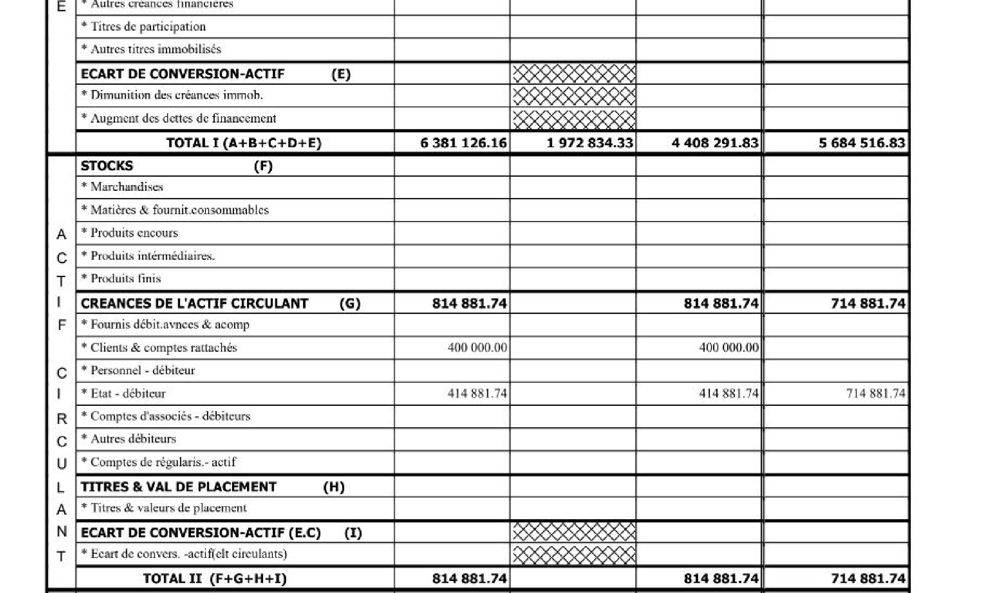


===== ZONE INFERIEURE =====


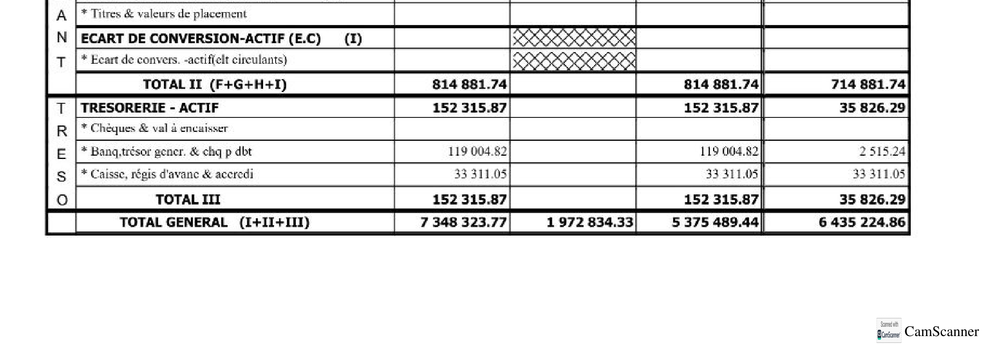

In [62]:

# CELLULE 9 BIS — Diagnostic des erreurs d'extraction ACTIF

from PIL import Image
from IPython.display import display
import pandas as pd

# 1. Récupérer les lignes problématiques
anomalies = df_controle_actif[
    df_controle_actif["statut"].isin(
        ["ERREUR", "A_VERIFIER"]
    )
].copy()

print("===== LIGNES A CORRIGER =====")
display(anomalies)

# 2. Afficher leurs valeurs directement depuis le VLM
indices = anomalies["ligne"].astype(int) - 1

print("\n===== DONNEES BRUTES EXTRAITES =====")
display(
    df_actif.iloc[indices][[
        "poste",
        "brut_N",
        "amortissements_provisions_N",
        "net_N",
        "net_N1"
    ]]
)

# 3. Afficher l'image ACTIF originale
image = Image.open(
    "/kaggle/working/images/page_1.png"
).convert("RGB")

largeur, hauteur = image.size

print("\n===== IMAGE ACTIF ORIGINALE =====")
print("Dimensions :", image.size)

# Zone centrale : créances et actif circulant
zone_centrale = image.crop((
    0,
    int(hauteur * 0.40),
    largeur,
    int(hauteur * 0.82)
))

print("\n===== ZONE CENTRALE =====")
display(zone_centrale)

# Zone inférieure : trésorerie et total général
zone_inferieure = image.crop((
    0,
    int(hauteur * 0.75),
    largeur,
    hauteur
))

print("\n===== ZONE INFERIEURE =====")
display(zone_inferieure)


In [63]:

# CELLULE 9 TER — Relire les postes problématiques
# directement depuis l'image ACTIF complète

messages_correction_actif = [
    {
        "role": "system",
        "content": (
            "Tu es un système de transcription de tableaux "
            "comptables marocains. Lis les cellules visibles "
            "sans calculer, inventer ni corriger les montants."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": "file:///kaggle/working/images/page_1.png",
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Observe le bilan ACTIF complet.

Lis particulièrement les lignes suivantes :
- CREANCES DE L'ACTIF CIRCULANT (G)
- Clients et comptes rattachés
- Personnel - débiteur
- Etat - débiteur
- TRESORERIE - ACTIF
- Banques, trésorerie générale
- Caisse
- TOTAL III
- TOTAL GENERAL

Pour chaque ligne visible, extrais exactement :
1. BRUT de l'exercice N
2. AMORTISSEMENTS ET PROVISIONS de N
3. NET de N
4. NET de l'exercice précédent N-1

IMPORTANT :
- Repère les en-têtes pour identifier les colonnes.
- Ne confonds pas BRUT avec NET.
- Ne calcule aucun montant.
- Si une cellule est vide ou illisible, utilise null.
- N'invente aucune valeur.
- Retourne uniquement le JSON.

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom du poste",
      "type_ligne": "detail",
      "brut_N": null,
      "amortissements_provisions_N": null,
      "net_N": null,
      "net_N1": null
    }
  ]
}
"""
            }
        ]
    }
]

# Réutiliser notre fonction d'extraction
correction_actif = extraire_avec_vlm(
    messages_correction_actif,
    max_tokens=1600
)

print("STATUT :", correction_actif["statut"])
print("TOKENS :", correction_actif["nombre_tokens"])

if correction_actif["donnees"] is not None:

    df_correction_actif = pd.DataFrame(
        correction_actif["donnees"]["lignes"]
    )

    display(df_correction_actif)

else:
    print("ERREUR :", correction_actif["erreur"])
    print(correction_actif["texte_brut"][-1000:])


STATUT : OK
TOKENS : 764


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,Clients & comptes rattachés,detail,814 881.74,None,814 881.74,714 881.74
1,Personnel - débiteur,detail,414 881.74,None,414 881.74,714 881.74
2,Etat - débiteur,detail,414 881.74,None,414 881.74,714 881.74
3,TRESORERIE - ACTIF,detail,152 315.87,None,152 315.87,35 826.29
4,Banq.trésor gencr. & chq p dbt,detail,119 004.82,None,119 004.82,2 515.24
5,"Caisse, régis d'avance & accrodi",detail,33 311.05,None,33 311.05,33 311.05
6,TOTAL III,detail,152 315.87,None,152 315.87,35 826.29
7,TOTAL GENERAL,detail,7 348 323.77,None,5 375 489.44,6 435 224.86


In [64]:

# CELLULE 9 QUATER — Diagnostic corrigé

import pandas as pd
import re
import unicodedata
from decimal import Decimal, InvalidOperation

df_corr = df_correction_actif.copy()

# 1. Fonction robuste de conversion
def convertir_decimal(valeur):

    if pd.isna(valeur):
        return None

    texte = unicodedata.normalize(
        "NFKC", str(valeur)
    ).strip()

    # Supprimer les espaces et normaliser les signes
    texte = re.sub(r"\s+", "", texte)
    texte = texte.replace("−", "-")

    # Gérer les formats français et internationaux
    if "," in texte and "." in texte:
        if texte.rfind(",") > texte.rfind("."):
            # Exemple : 1.234.567,89
            texte = texte.replace(".", "").replace(",", ".")
        else:
            # Exemple : 1,234,567.89
            texte = texte.replace(",", "")
    elif "," in texte:
        # Exemple : 119 004,82
        texte = texte.replace(",", ".")

    # Ne pas accepter de formats inattendus
    if not re.fullmatch(r"[+-]?\d+(\.\d+)?", texte):
        print("Montant non reconnu :", repr(valeur))
        return None

    try:
        return Decimal(texte)
    except InvalidOperation:
        print("Conversion impossible :", repr(valeur))
        return None


# 2. Récupérer un montant depuis un poste
def montant(poste, colonne):

    lignes = df_corr[
        df_corr["poste"].astype(str).str.strip().str.casefold()
        == poste.strip().casefold()
    ]

    if len(lignes) != 1:
        print(
            f"Poste '{poste}' : "
            f"{len(lignes)} correspondance(s)"
        )
        return None

    valeur = lignes.iloc[0][colonne]

    return convertir_decimal(valeur)


# 3. Vérifier les montants de trésorerie
print("===== VALIDATION TRESORERIE =====")

for colonne in ["net_N", "net_N1"]:

    banque = montant(
        "Banq.trésor gencr. & chq p dbt",
        colonne
    )

    caisse = montant(
        "Caisse, régis d'avance & accrodi",
        colonne
    )

    total = montant("TOTAL III", colonne)

    print("\nColonne :", colonne)

    if any(v is None for v in (banque, caisse, total)):
        print("STATUT : INCOMPLET OU FORMAT INVALIDE")
        continue

    somme = banque + caisse

    print("Banque :", banque)
    print("Caisse :", caisse)
    print("Somme calculée :", somme)
    print("TOTAL III extrait :", total)

    if somme == total:
        print("STATUT : OK")
    else:
        print("STATUT : ERREUR")


# 4. Détecter les montants répétés
print("\n===== MONTANTS REPETES =====")

details = df_corr[
    df_corr["type_ligne"] == "detail"
].copy()

for colonne in ["net_N", "net_N1"]:

    details["_montant"] = details[colonne].apply(
        convertir_decimal
    )

    doublons = details[
        details["_montant"].notna()
        & details["_montant"].duplicated(keep=False)
    ]

    if not doublons.empty:
        print("\nColonne :", colonne)
        display(doublons[["poste", colonne]])


# 5. Vérifier les types des lignes TOTAL
print("\n===== CLASSIFICATION DES TOTAUX =====")

totaux = df_corr[
    df_corr["poste"].str.contains(
        "TOTAL", case=False, na=False
    )
]

display(
    totaux[["poste", "type_ligne", "net_N", "net_N1"]]
)

print("\nDiagnostic terminé.")
print("Aucun CSV final n'a été créé.")


===== VALIDATION TRESORERIE =====

Colonne : net_N
Banque : 119004.82
Caisse : 33311.05
Somme calculée : 152315.87
TOTAL III extrait : 152315.87
STATUT : OK

Colonne : net_N1
Banque : 2515.24
Caisse : 33311.05
Somme calculée : 35826.29
TOTAL III extrait : 35826.29
STATUT : OK

===== MONTANTS REPETES =====

Colonne : net_N


,poste,net_N
1,Personnel - débiteur,414 881.74
2,Etat - débiteur,414 881.74
3,TRESORERIE - ACTIF,152 315.87
6,TOTAL III,152 315.87



Colonne : net_N1


,poste,net_N1
0,Clients & comptes rattachés,714 881.74
1,Personnel - débiteur,714 881.74
2,Etat - débiteur,714 881.74
3,TRESORERIE - ACTIF,35 826.29
6,TOTAL III,35 826.29



===== CLASSIFICATION DES TOTAUX =====


,poste,type_ligne,net_N,net_N1
6,TOTAL III,detail,152 315.87,35 826.29
7,TOTAL GENERAL,detail,5 375 489.44,6 435 224.86



Diagnostic terminé.
Aucun CSV final n'a été créé.


In [65]:

# CELLULE 9 QUINQUIES — Extraction ciblée des créances

import pandas as pd

messages_creances = [
    {
        "role": "system",
        "content": (
            "Tu es un système d'extraction fidèle de tableaux "
            "comptables. Chaque montant doit provenir directement "
            "de sa cellule dans l'image. N'invente rien."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": "file:///kaggle/working/images/page_1.png",
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Observe la page ACTIF du bilan marocain.

Concentre-toi uniquement sur la rubrique :
CREANCES DE L'ACTIF CIRCULANT (G).

Extrais cette rubrique et chacune de ses lignes
détaillées, dans l'ordre du tableau.

COLONNES :
1. brut_N
2. amortissements_provisions_N
3. net_N
4. net_N1

INSTRUCTIONS :
- Lis chaque montant directement dans sa cellule.
- Repère précisément sa colonne.
- Ne copie pas le montant d'une ligne sur une autre.
- Ne calcule aucun montant.
- N'invente aucune valeur.
- Si une cellule est vide ou illisible, mets null.
- N'inclus que les lignes visibles de cette rubrique.
- Conserve les intitulés tels qu'ils apparaissent.

Retourne uniquement ce JSON :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom exact",
      "type_ligne": "detail",
      "brut_N": null,
      "amortissements_provisions_N": null,
      "net_N": null,
      "net_N1": null
    }
  ]
}

Pour la ligne principale CREANCES DE L'ACTIF
CIRCULANT, utilise type_ligne = "rubrique".
Pour les postes détaillés, utilise "detail".
"""
            }
        ]
    }
]

# Exécuter Qwen2.5-VL
resultat_creances = extraire_avec_vlm(
    messages_creances,
    max_tokens=1500
)

print("STATUT :", resultat_creances["statut"])
print("TOKENS :", resultat_creances["nombre_tokens"])

if resultat_creances["donnees"] is not None:

    df_creances = pd.DataFrame(
        resultat_creances["donnees"]["lignes"]
    )

    print("\n===== CREANCES EXTRAITES =====")
    display(df_creances)

else:
    print("Extraction non valide :")
    print(resultat_creances["erreur"])
    print(resultat_creances["texte_brut"][-1000:])


STATUT : OK
TOKENS : 432

===== CREANCES EXTRAITES =====


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,Clients & comptes rattachés,rubrique,814 881.74,None,814 881.74,714 881.74
1,Personnel - débiteur,detail,None,None,None,None
2,État - débiteur,detail,None,None,None,None
3,Comptes d'associés - débiteurs,detail,None,None,None,None
4,Autres débiteurs,detail,None,None,None,None
5,Comptes de régularis. - actif,detail,None,None,None,None


===== ZOOM CREANCES =====


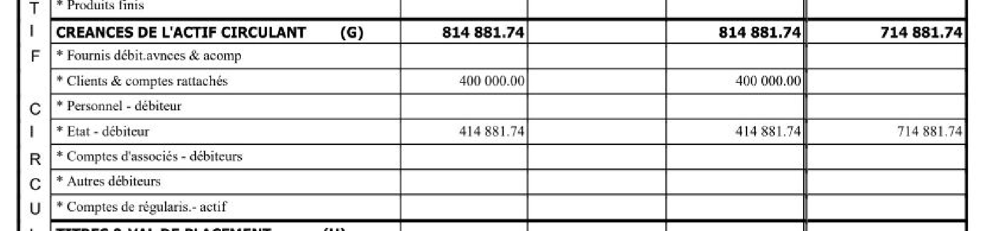

STATUT : OK


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,Fournis débit.avances & acomp,detail,None,None,None,None
1,Clients & comptes rattachés,detail,None,None,None,None
2,Personnel - débiteur,detail,None,None,None,None
3,Etat - débiteur,detail,None,None,None,None
4,Comptes d'associés - débiteurs,detail,None,None,None,None
5,Autres débiteurs,detail,None,None,None,None
6,Comptes de régularis.- actif,detail,None,None,None,None


In [66]:

# CELLULE 9 SEXIES — Extraction avec image complète + zoom

from PIL import Image
from pathlib import Path
from IPython.display import display

# 1. Charger l'image originale
chemin_original = Path(
    "/kaggle/working/images/page_1.png"
)

image = Image.open(chemin_original).convert("RGB")
largeur, hauteur = image.size

# 2. Recadrer uniquement la zone des créances
zoom = image.crop((
    int(largeur * 0.03),
    int(hauteur * 0.594),
    int(largeur * 0.94),
    int(hauteur * 0.743)
))

chemin_zoom = Path(
    "/kaggle/working/zoom_creances.png"
)

zoom.save(chemin_zoom)

print("===== ZOOM CREANCES =====")
display(zoom)

# 3. Préparer les deux images pour Qwen
messages_zoom_creances = [
    {
        "role": "system",
        "content": (
            "Tu es un système d'extraction de tableaux "
            "financiers. Tu dois transcrire fidèlement "
            "toutes les cellules visibles sans calculer "
            "ni inventer des valeurs."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin_original.resolve().as_uri(),
                "max_pixels": 1280 * 28 * 28
            },
            {
                "type": "image",
                "image": chemin_zoom.resolve().as_uri(),
                "max_pixels": 1280 * 28 * 28
            },
            {
                "type": "text",
                "text": """
IMAGE 1 : page ACTIF complète.
Elle sert à identifier les en-têtes des colonnes.

IMAGE 2 : agrandissement de la rubrique
CREANCES DE L'ACTIF CIRCULANT (G).

Extrais toutes les lignes visibles de cette rubrique,
dans leur ordre exact.

Les colonnes numériques, de gauche à droite :
1. brut_N
2. amortissements_provisions_N
3. net_N
4. net_N1

IMPORTANT :
- La première ligne est le total de la rubrique.
- Les lignes avec * sont les détails.
- Ne reporte jamais le montant d'un total
  sur les lignes de détail.
- Une cellule vide doit être null.
- Ne calcule pas les montants.
- Ne devine aucun chiffre.
- Respecte exactement les colonnes.

Retourne uniquement ce JSON :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom exact",
      "type_ligne": "rubrique",
      "brut_N": null,
      "amortissements_provisions_N": null,
      "net_N": null,
      "net_N1": null
    }
  ]
}

Pour les lignes détaillées,
utilise type_ligne = "detail".
"""
            }
        ]
    }
]

# 4. Exécuter le VLM
resultat_zoom = extraire_avec_vlm(
    messages_zoom_creances,
    max_tokens=1200
)

print("STATUT :", resultat_zoom["statut"])

if resultat_zoom["donnees"] is not None:

    df_zoom_creances = pd.DataFrame(
        resultat_zoom["donnees"]["lignes"]
    )

    display(df_zoom_creances)

else:
    print(resultat_zoom["erreur"])
    print(resultat_zoom["texte_brut"][-1000:])



Image transmise au VLM :


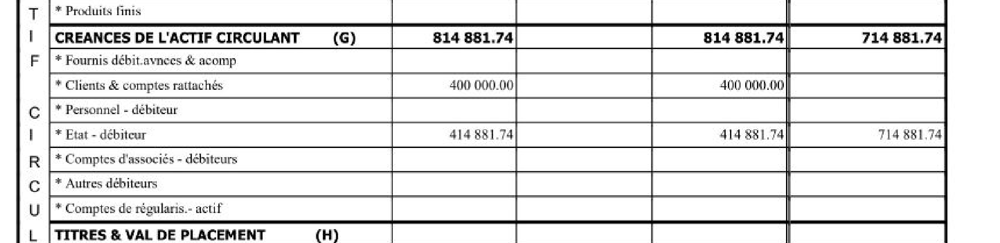

Statut JSON : OK


,poste,type_ligne,brut_N,amortissements_provisions_N,net_N,net_N1
0,CREANCES DE L'ACTIF CIRCULANT (G),detail,814881.74,None,814881.74,714881.74
1,* Fournis débit.avances & acomp,detail,NaN,None,NaN,NaN
2,* Clients & comptes rattachés,detail,400000.00,None,400000.00,400000.00
3,* Personnel - débiteur,detail,NaN,None,NaN,NaN
4,* Etat - débiteur,detail,414881.74,None,414881.74,714881.74
5,* Comptes d'associés - débiteurs,detail,NaN,None,NaN,NaN
6,* Autres débiteurs,detail,NaN,None,NaN,NaN
7,* Comptes de régularis.- actif,detail,NaN,None,NaN,NaN


Montants extraits : 9
Extraction numérique obtenue.
Vérification visuelle encore nécessaire.


In [67]:

# NOUVELLE CELLULE — Lecture ciblée des créances

from PIL import Image
from pathlib import Path
from IPython.display import display
import pandas as pd

# 1. Recadrer les créances sur l'image originale
image = Image.open(
    "/kaggle/working/images/page_1.png"
).convert("RGB")

w, h = image.size

zoom = image.crop((
    int(w * 0.03),
    int(h * 0.59),
    int(w * 0.96),
    int(h * 0.75)
))

zoom_path = Path("/kaggle/working/creances_seules.png")
zoom.save(zoom_path)

print("Image transmise au VLM :")
display(zoom)

# 2. Construire un prompt court et ciblé
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": zoom_path.resolve().as_uri(),
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Transcris les cellules du tableau visible.

Les quatre colonnes numériques sont, de gauche à droite :
BRUT N | AMORTISSEMENTS N | NET N | NET N-1.

Lis uniquement :
1. CREANCES DE L'ACTIF CIRCULANT (G)
2. Clients & comptes rattachés
3. Personnel - débiteur
4. Etat - débiteur

Pour chaque ligne, lis chaque colonne indépendamment.
Ne déplace pas les montants entre les lignes.
Ne calcule pas et ne devine rien.
Une cellule vide ou illisible vaut null.

Retourne uniquement ce JSON :
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "...",
      "type_ligne": "detail",
      "brut_N": null,
      "amortissements_provisions_N": null,
      "net_N": null,
      "net_N1": null
    }
  ]
}
"""
            }
        ]
    }
]

# 3. Exécuter Qwen2.5-VL
resultat_test = extraire_avec_vlm(
    messages,
    max_tokens=800
)

print("Statut JSON :", resultat_test["statut"])

# 4. Afficher et contrôler la complétude
if resultat_test["donnees"] is not None:

    df_test = pd.DataFrame(
        resultat_test["donnees"]["lignes"]
    )

    display(df_test)

    colonnes = [
        "brut_N",
        "amortissements_provisions_N",
        "net_N",
        "net_N1"
    ]

    nb_montants = df_test[colonnes].notna().sum().sum()
    print("Montants extraits :", nb_montants)

    if nb_montants == 0:
        print("ECHEC : aucune valeur numérique extraite.")
    else:
        print("Extraction numérique obtenue.")
        print("Vérification visuelle encore nécessaire.")

else:
    print("Erreur :", resultat_test["erreur"])
    print(resultat_test["texte_brut"][-500:])


In [68]:

# Vérification ciblée de la colonne NET N-1

messages_verification_N1 = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": zoom_path.resolve().as_uri(),
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Analyse l'image du bilan ACTIF.

Lis UNIQUEMENT la colonne numérique la plus à droite :
EXERCICE PRECEDENT - NET (N-1).

Ne lis pas la colonne NET de l'exercice actuel.

Pour chaque ligne visible :
- Lis la valeur directement dans sa cellule N-1.
- Si la cellule est vide, écris null.
- Si elle est illisible, écris null.
- Ne recopie jamais une valeur de l'exercice N.
- Ne calcule pas les montants.
- Ne remplis pas les cases vides pour équilibrer le bilan.

Retourne uniquement ce JSON :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom de la ligne",
      "type_ligne": "detail",
      "net_N1": null
    }
  ]
}
"""
            }
        ]
    }
]

# Relancer Qwen2.5-VL
resultat_N1 = extraire_avec_vlm(
    messages_verification_N1,
    max_tokens=700
)

print("STATUT :", resultat_N1["statut"])

if resultat_N1["donnees"] is not None:

    df_verification_N1 = pd.DataFrame(
        resultat_N1["donnees"]["lignes"]
    )

    display(df_verification_N1)

else:
    print(resultat_N1["erreur"])
    print(resultat_N1["texte_brut"][-500:])


STATUT : OK


,poste,type_ligne,net_N1
0,CREANCES DE L'ACTIF CIRCULANT,detail,814881.74
1,* Fournis débit. avances & acomp,detail,NaN
2,* Clients & comptes rattachés,detail,400000.00
3,* Personnel - débiteur,detail,NaN
4,* Etat - débiteur,detail,414881.74
5,* Comptes d'associés - débiteurs,detail,NaN
6,* Autres débiteurs,detail,NaN
7,* Comptes de régularis. - actif,detail,NaN


===== IMAGE A ANALYSER =====


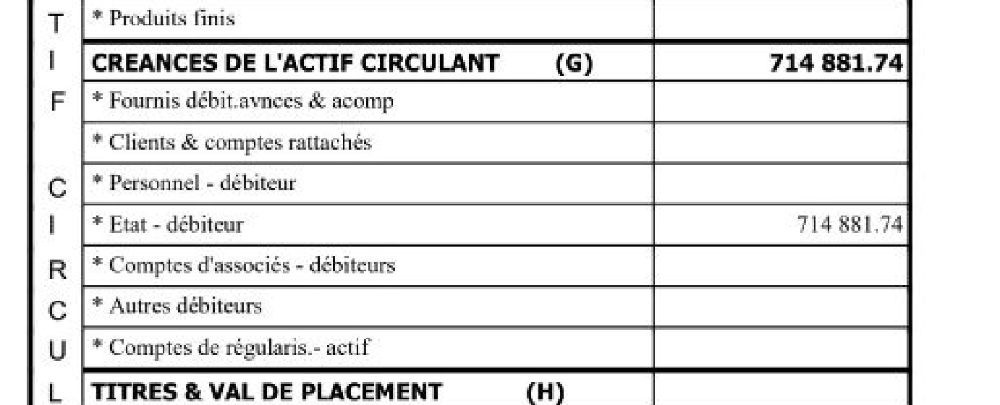

STATUT : OK


,poste,net_N1
0,Produits finis,NaN
1,CREANCES DE L'ACTIF CIRCULANT (G),714881.74
2,* Fournis débit. avnces & acomp,NaN
3,* Clients & comptes rattachés,NaN
4,* Personnel - débiteur,NaN
5,* Etat - débiteur,714881.74
6,* Comptes d'associés - débiteurs,NaN
7,* Autres débiteurs,NaN
8,* Comptes de régularis. - actif,NaN


In [69]:

# Extraction ciblée : noms des postes + dernière colonne

from PIL import Image
from IPython.display import display
from pathlib import Path
import pandas as pd

# 1. Ouvrir notre zoom des créances
image = Image.open(
    "/kaggle/working/creances_seules.png"
).convert("RGB")

w, h = image.size

# 2. Conserver la colonne des postes
postes = image.crop((
    0, 0,
    int(w * 0.40), h
))

# 3. Conserver uniquement la dernière colonne NET N-1
colonne_n1 = image.crop((
    int(w * 0.80), 0,
    w, h
))

# 4. Réunir les deux zones horizontalement
image_finale = Image.new(
    "RGB",
    (postes.width + colonne_n1.width, h),
    "white"
)

image_finale.paste(postes, (0, 0))
image_finale.paste(colonne_n1, (postes.width, 0))

chemin_final = Path(
    "/kaggle/working/creances_net_N1.png"
)

image_finale.save(chemin_final)

print("===== IMAGE A ANALYSER =====")
display(image_finale)

# 5. Préparer le prompt
messages_n1 = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin_final.resolve().as_uri(),
                "max_pixels": 1280 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Cette image contient deux colonnes :
- A gauche : les postes comptables.
- A droite : NET de l'exercice précédent N-1.

Lis chaque ligne horizontalement.

Extrais le poste et sa valeur N-1.

IMPORTANT :
- Une cellule vide vaut null.
- Ne copie pas les montants d'une autre ligne.
- Ne calcule aucun montant.
- Conserve toutes les lignes visibles.
- Utilise uniquement les valeurs présentes dans l'image.

Retourne exclusivement ce JSON :
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom exact",
      "net_N1": null
    }
  ]
}
"""
            }
        ]
    }
]

# 6. Exécuter Qwen
resultat_n1_isole = extraire_avec_vlm(
    messages_n1,
    max_tokens=700
)

print("STATUT :", resultat_n1_isole["statut"])

if resultat_n1_isole["donnees"] is not None:
    df_n1_isole = pd.DataFrame(
        resultat_n1_isole["donnees"]["lignes"]
    )
    display(df_n1_isole)
else:
    print(resultat_n1_isole["erreur"])
    print(resultat_n1_isole["texte_brut"][-500:])


In [70]:

# Vérifier automatiquement les créances NET N-1

import pandas as pd
from decimal import Decimal

df = df_n1_isole.copy()

# Repérer le début de la rubrique CREANCES
masque = df["poste"].str.contains(
    "CREANCES DE L'ACTIF CIRCULANT",
    case=False,
    regex=False,
    na=False
)

if not masque.any():
    raise ValueError("Rubrique CREANCES introuvable")

debut = df.index[masque][0]

# Conserver uniquement cette rubrique
bloc = df.loc[debut:].copy()

# Convertir en nombres
bloc["net_N1"] = pd.to_numeric(
    bloc["net_N1"],
    errors="coerce"
)

# Première ligne = total de la rubrique
total_extrait = Decimal(str(bloc.iloc[0]["net_N1"]))

# Autres lignes = postes détaillés
details = bloc.iloc[1:]

montants = [
    Decimal(str(v))
    for v in details["net_N1"].dropna()
]

somme_calculee = sum(montants, Decimal("0"))

print("===== CONTROLE CREANCES N-1 =====")
print("TOTAL EXTRAIT :", total_extrait)
print("SOMME DES POSTES :", somme_calculee)
print("DIFFERENCE :", total_extrait - somme_calculee)
print("Cellules non renseignées :", details["net_N1"].isna().sum())

if total_extrait == somme_calculee:
    print("OK : montants renseignés cohérents")
else:
    print("ERREUR : les montants ne correspondent pas")

print("Validation finale soumise à la vérification des cellules vides.")


===== CONTROLE CREANCES N-1 =====
TOTAL EXTRAIT : 714881.74
SOMME DES POSTES : 714881.74
DIFFERENCE : 0.00
Cellules non renseignées : 6
OK : montants renseignés cohérents
Validation finale soumise à la vérification des cellules vides.


Dimensions de l'image : (2478, 3500)

========== brut_N ==========
Fichier : /kaggle/working/colonnes_actif/ACTIF_brut_N.png
Dimensions : (1117, 3500)


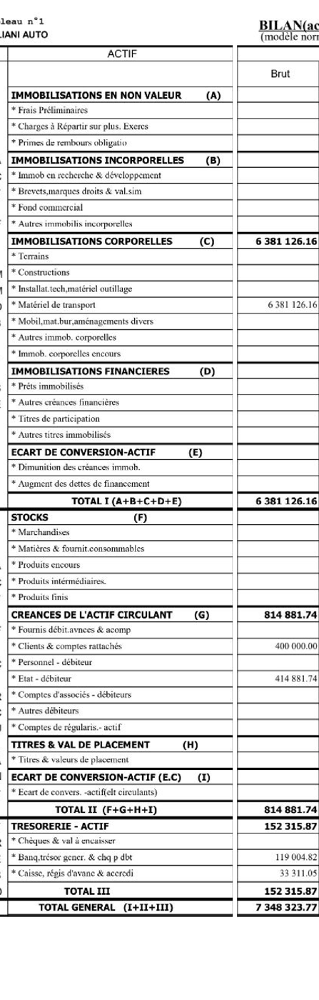


========== amortissements_provisions_N ==========
Fichier : /kaggle/working/colonnes_actif/ACTIF_amortissements_provisions_N.png
Dimensions : (1147, 3500)


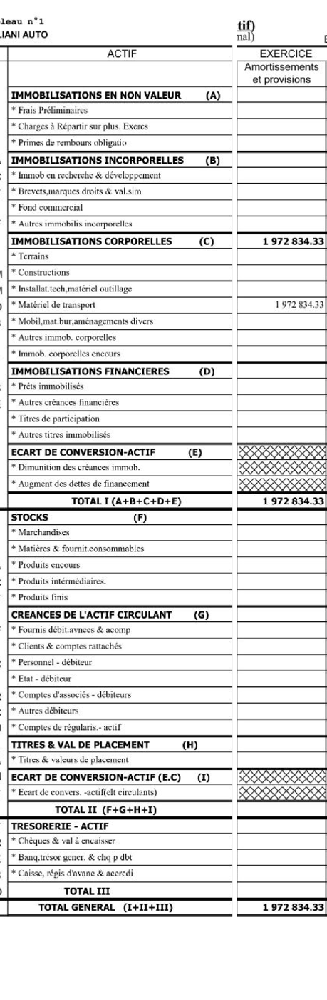


========== net_N ==========
Fichier : /kaggle/working/colonnes_actif/ACTIF_net_N.png
Dimensions : (1145, 3500)


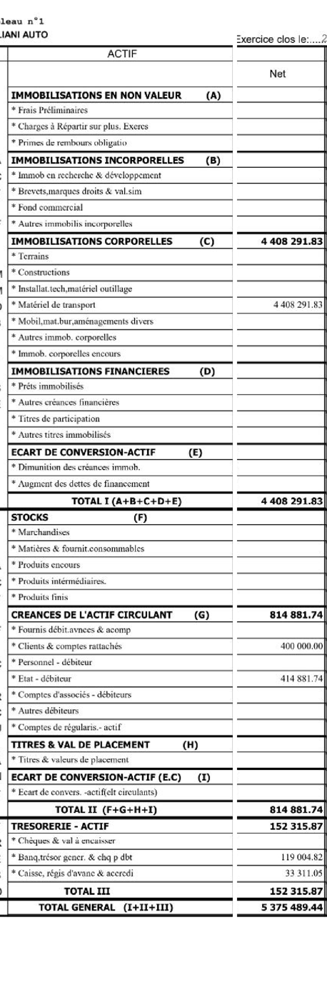


========== net_N1 ==========
Fichier : /kaggle/working/colonnes_actif/ACTIF_net_N1.png
Dimensions : (1189, 3500)


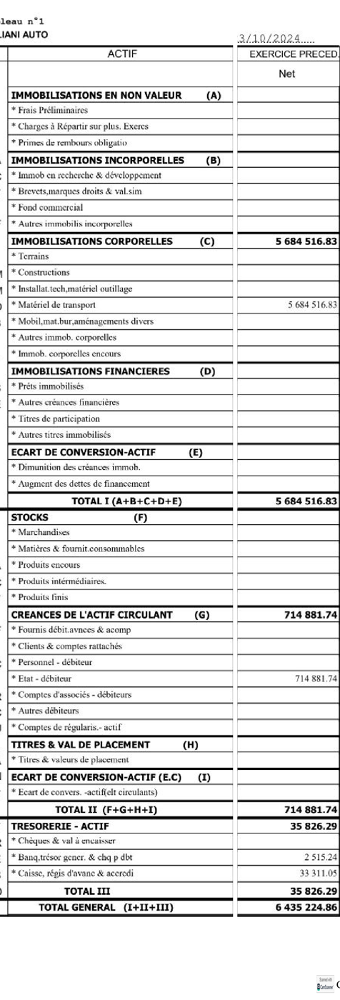


========== RÉSUMÉ ==========
brut_N : /kaggle/working/colonnes_actif/ACTIF_brut_N.png
amortissements_provisions_N : /kaggle/working/colonnes_actif/ACTIF_amortissements_provisions_N.png
net_N : /kaggle/working/colonnes_actif/ACTIF_net_N.png
net_N1 : /kaggle/working/colonnes_actif/ACTIF_net_N1.png

Les 4 images ACTIF ont été créées.


In [73]:

# ============================================================
# CELLULE — EXTRACTION DES COLONNES DU BILAN ACTIF
# ============================================================

from PIL import Image
from pathlib import Path
from IPython.display import display

# 1. Charger l'image originale du bilan ACTIF
image_path = "/kaggle/working/images/page_1.png"

image = Image.open(image_path).convert("RGB")
largeur, hauteur = image.size

print("Dimensions de l'image :", image.size)


# 2. Créer le dossier de sortie
output_dir = Path("/kaggle/working/colonnes_actif")
output_dir.mkdir(parents=True, exist_ok=True)


# 3. Définir les positions des colonnes
# Coordonnées relatives entre 0 et 1
zones = {
    "poste": (0.065, 0.394),
    "brut_N": (0.394, 0.510),
    "amortissements_provisions_N": (0.510, 0.638),
    "net_N": (0.638, 0.765),
    "net_N1": (0.765, 0.910)
}


# 4. Garder toute la hauteur pour ne perdre aucune ligne
y_debut = 0
y_fin = hauteur


# 5. Fonction pour découper une colonne
def decouper_colonne(nom_colonne):

    x_debut, x_fin = zones[nom_colonne]

    colonne = image.crop((
        int(x_debut * largeur),
        y_debut,
        int(x_fin * largeur),
        y_fin
    ))

    return colonne


# 6. Extraire les noms des postes
image_postes = decouper_colonne("poste")


# 7. Créer une image pour chaque colonne numérique
images_colonnes_actif = {}

colonnes_numeriques = [
    "brut_N",
    "amortissements_provisions_N",
    "net_N",
    "net_N1"
]

for nom_colonne in colonnes_numeriques:

    # Extraire la colonne numérique
    image_valeurs = decouper_colonne(nom_colonne)

    # Ajouter un petit espace blanc entre les deux colonnes
    espace = 15

    largeur_finale = (
        image_postes.width + espace + image_valeurs.width
    )

    # Créer une nouvelle image
    image_finale = Image.new(
        "RGB",
        (largeur_finale, hauteur),
        "white"
    )

    # Placer les postes à gauche
    image_finale.paste(
        image_postes,
        (0, 0)
    )

    # Placer les valeurs à droite
    image_finale.paste(
        image_valeurs,
        (image_postes.width + espace, 0)
    )

    # Enregistrer l'image
    chemin_sortie = output_dir / f"ACTIF_{nom_colonne}.png"

    image_finale.save(chemin_sortie)

    # Conserver le chemin pour le VLM
    images_colonnes_actif[nom_colonne] = str(chemin_sortie)

    # Afficher le résultat
    print(f"\n========== {nom_colonne} ==========")
    print("Fichier :", chemin_sortie)
    print("Dimensions :", image_finale.size)

    apercu = image_finale.copy()
    apercu.thumbnail((900, 1400))
    display(apercu)


# 8. Vérifier les fichiers générés
print("\n========== RÉSUMÉ ==========")

for nom, chemin in images_colonnes_actif.items():
    print(f"{nom} : {chemin}")

print("\nLes 4 images ACTIF ont été créées.")


In [75]:

# ============================================================
# CORRECTION — DETECTION DYNAMIQUE DES COLONNES
# ============================================================

import json
import re
import torch

from pathlib import Path
from qwen_vl_utils import process_vision_info


# 1. Fonction pour récupérer le JSON généré par Qwen
def extraire_json_colonnes(response):

    texte = response.strip()

    # Supprimer les éventuelles balises Markdown
    texte = re.sub(
        r"^```(?:json)?\s*",
        "",
        texte,
        flags=re.IGNORECASE
    )

    texte = re.sub(r"\s*```$", "", texte).strip()

    decoder = json.JSONDecoder()

    # Chercher le début d'un objet ou d'un tableau JSON
    for position, caractere in enumerate(texte):

        if caractere not in "{[":
            continue

        try:
            donnees, fin = decoder.raw_decode(
                texte[position:]
            )
        except json.JSONDecodeError:
            continue

        # Format 1 : {"colonnes": [...]}
        if isinstance(donnees, dict):
            colonnes = donnees.get("colonnes")

            if isinstance(colonnes, list):
                return colonnes

        # Format 2 : [{...}, {...}]
        if isinstance(donnees, list):
            return donnees

    raise ValueError(
        "Impossible de récupérer une liste de colonnes JSON."
    )


# 2. Fonction de détection dynamique
def detecter_colonnes(image_path, type_bilan):

    noms_attendus = COLONNES_ATTENDUES[type_bilan]

    messages = [
        {
            "role": "system",
            "content": (
                "Tu analyses la mise en page des tableaux "
                "comptables. Tu détectes les limites "
                "horizontales des colonnes."
            )
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(image_path).resolve().as_uri(),
                    "max_pixels": 2048 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Localise les colonnes du bilan {type_bilan}.

Colonnes attendues de gauche à droite :
{json.dumps(noms_attendus, ensure_ascii=False)}

Retourne les limites horizontales x1 et x2
normalisées entre 0 et 1000.

Les limites doivent correspondre aux positions
visibles des colonnes, pas à des positions théoriques.

Retourne uniquement un JSON de cette forme :

{{
  "colonnes": [
    {{
      "nom": "poste",
      "x1": 0,
      "x2": 400
    }}
  ]
}}

L'exemple ne décrit pas les vraies coordonnées.
Retourne toutes les colonnes attendues.
N'invente pas de coordonnées si tu ne peux
pas identifier les colonnes.
"""
                }
            ]
        }
    ]

    # Préparer les entrées
    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to("cuda:0")

    # Inférence
    with torch.inference_mode():

        generated = model.generate(
            **inputs,
            max_new_tokens=700,
            do_sample=False,
            num_beams=1
        )

    new_tokens = generated[
        :, inputs.input_ids.shape[1]:
    ]

    response = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )[0]

    # Diagnostic : afficher ce que Qwen a vraiment renvoyé
    print(f"\n===== REPONSE BRUTE {type_bilan} =====")
    print(response)

    # Parser le JSON
    colonnes = extraire_json_colonnes(response)

    # Vérifier le nombre et les noms des colonnes
    if len(colonnes) != len(noms_attendus):
        raise ValueError(
            f"{len(colonnes)} colonnes détectées, "
            f"{len(noms_attendus)} attendues."
        )

    precedent_x2 = 0

    for colonne, nom_attendu in zip(
        colonnes,
        noms_attendus
    ):

        if not isinstance(colonne, dict):
            raise ValueError("Format de colonne invalide.")

        if colonne.get("nom") != nom_attendu:
            raise ValueError(
                f"Colonne incorrecte : {colonne.get('nom')}. "
                f"Attendu : {nom_attendu}"
            )

        x1 = colonne.get("x1")
        x2 = colonne.get("x2")

        if (
            isinstance(x1, bool)
            or isinstance(x2, bool)
            or not isinstance(x1, (int, float))
            or not isinstance(x2, (int, float))
            or not (0 <= x1 < x2 <= 1000)
        ):
            raise ValueError(
                f"Coordonnées invalides : {colonne}"
            )

        # Rejeter les chevauchements importants
        if x1 < precedent_x2 - 15:
            raise ValueError(
                f"Chevauchement suspect : {colonne}"
            )

        precedent_x2 = x2

    del inputs, generated, new_tokens

    return colonnes


# 3. Relancer la détection ACTIF et PASSIF
images_colonnes_actif = {}
images_colonnes_passif = {}
coordonnees_detectees = {}

for type_bilan, image_path in PAGES.items():

    print(f"\n{'=' * 50}")
    print("DETECTION :", type_bilan)
    print(f"{'=' * 50}")

    try:
        colonnes = detecter_colonnes(
            image_path,
            type_bilan
        )

        coordonnees_detectees[type_bilan] = colonnes

        print("\nCoordonnées détectées :")
        print(json.dumps(
            colonnes,
            indent=2,
            ensure_ascii=False
        ))

        fichiers = creer_images_colonnes(
            image_path,
            colonnes,
            type_bilan
        )

        if type_bilan == "ACTIF":
            images_colonnes_actif = fichiers
        else:
            images_colonnes_passif = fichiers

    except (ValueError, KeyError, TypeError) as e:
        print("ERREUR :", e)
        print("Découpage annulé pour", type_bilan)


print("\n===== RÉSUMÉ =====")
print("ACTIF :", len(images_colonnes_actif), "images")
print("PASSIF :", len(images_colonnes_passif), "images")



DETECTION : ACTIF

===== REPONSE BRUTE ACTIF =====
```json
{
  "colonnes": [
    {
      "nom": "poste",
      "x1": 0,
      "x2": 400
    },
    {
      "nom": "brut_N",
      "x1": 400,
      "x2": 800
    },
    {
      "nom": "amortissements_provisions_N",
      "x1": 800,
      "x2": 1200
    },
    {
      "nom": "net_N",
      "x1": 1200,
      "x2": 1600
    },
    {
      "nom": "net_N1",
      "x1": 1600,
      "x2": 2000
    }
  ]
}
```
ERREUR : Coordonnées invalides : {'nom': 'amortissements_provisions_N', 'x1': 800, 'x2': 1200}
Découpage annulé pour ACTIF

DETECTION : PASSIF

===== REPONSE BRUTE PASSIF =====
```json
{
  "colonnes": [
    {
      "nom": "poste",
      "x1": 0,
      "x2": 400
    },
    {
      "nom": "montant_N",
      "x1": 400,
      "x2": 800
    },
    {
      "nom": "montant_N1",
      "x1": 800,
      "x2": 1200
    }
  ]
}
```
ERREUR : Coordonnées invalides : {'nom': 'montant_N1', 'x1': 800, 'x2': 1200}
Découpage annulé pour PASSIF

===== RÉSUMÉ =


========== ACTIF ==========

===== COLONNES ACTIF =====
poste : 188 -> 978
brut_N : 978 -> 1264
amortissements_provisions_N : 1264 -> 1576
net_N : 1576 -> 1890
net_N1 : 1890 -> 2254


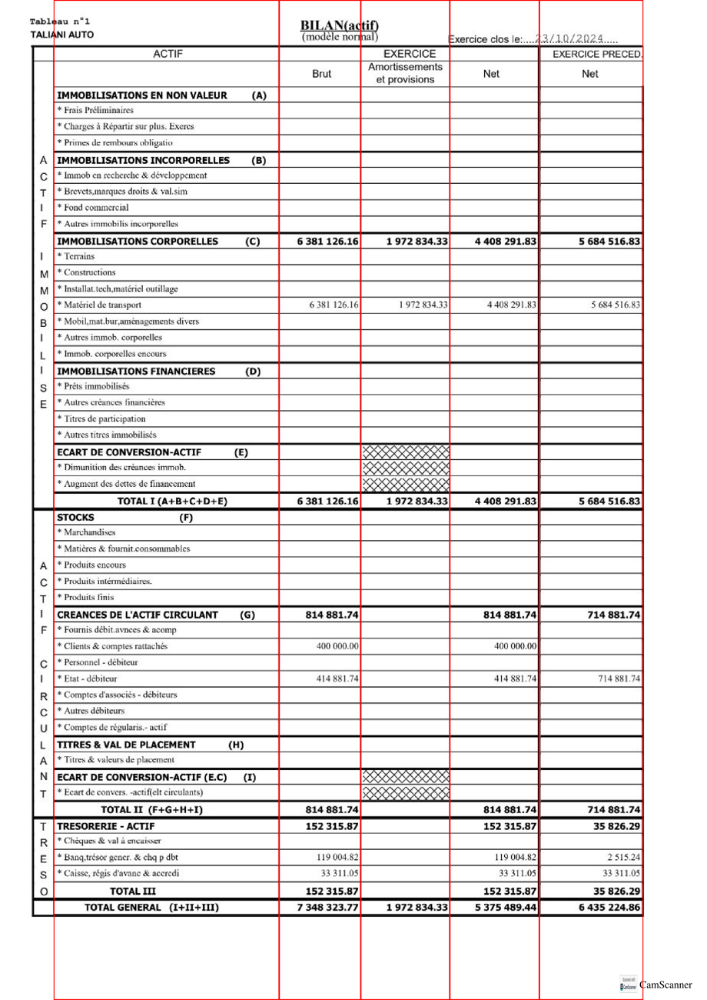

Image créée : ACTIF_brut_N.png
Image créée : ACTIF_amortissements_provisions_N.png
Image créée : ACTIF_net_N.png
Image créée : ACTIF_net_N1.png

========== PASSIF ==========

===== COLONNES PASSIF =====
poste : 223 -> 1619
montant_N : 1619 -> 1984
montant_N1 : 1984 -> 2310


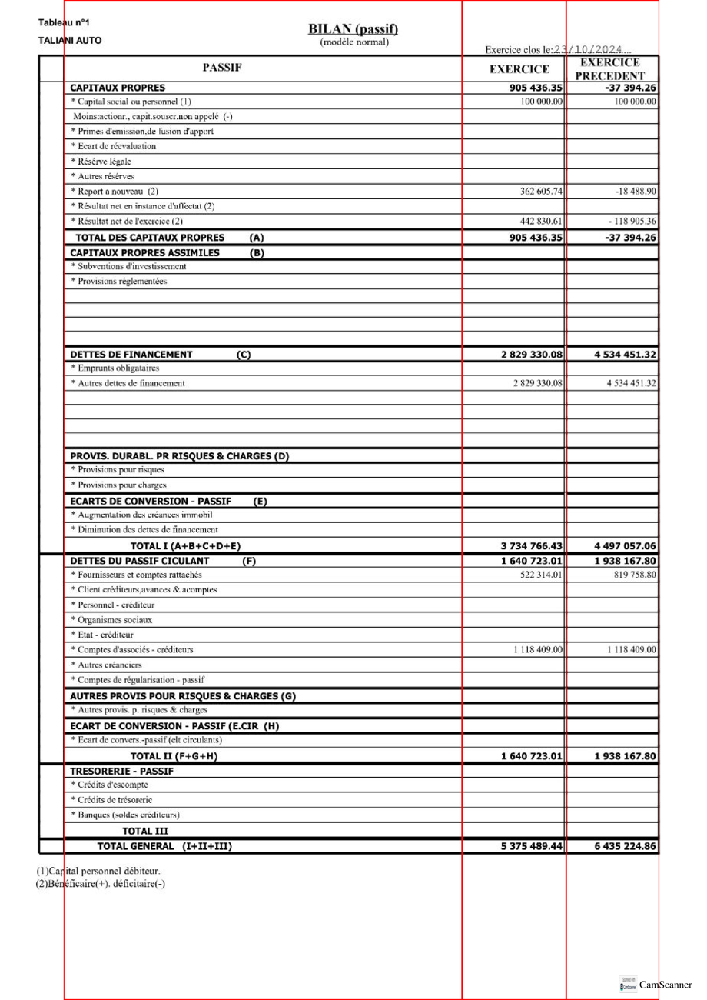

Image créée : PASSIF_montant_N.png
Image créée : PASSIF_montant_N1.png

===== RESULTAT FINAL =====
ACTIF : 4 images
PASSIF : 2 images
Aucun CSV final créé.


In [76]:

# ============================================================
# DETECTION DYNAMIQUE DES COLONNES AVEC OPENCV
# ============================================================

import cv2
import numpy as np

from PIL import Image, ImageDraw
from pathlib import Path
from IPython.display import display

PAGES = {
    "ACTIF": "/kaggle/working/images/page_1.png",
    "PASSIF": "/kaggle/working/images/page_2.png"
}

COLONNES = {
    "ACTIF": [
        "poste",
        "brut_N",
        "amortissements_provisions_N",
        "net_N",
        "net_N1"
    ],
    "PASSIF": [
        "poste",
        "montant_N",
        "montant_N1"
    ]
}

output_dir = Path("/kaggle/working/colonnes_dynamiques")
output_dir.mkdir(parents=True, exist_ok=True)


# 1. Détecter les lignes verticales du tableau
def detecter_colonnes_cv(image_path, type_bilan):

    gris = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if gris is None:
        raise FileNotFoundError(image_path)

    h, w = gris.shape

    # Convertir les traits noirs en pixels blancs
    _, binaire = cv2.threshold(
        gris,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Isoler les longues lignes verticales
    noyau = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (2, max(30, h // 10))
    )

    verticales = cv2.morphologyEx(
        binaire,
        cv2.MORPH_OPEN,
        noyau
    )

    # Compter les pixels de lignes pour chaque position X
    profil = np.count_nonzero(verticales, axis=0)

    positions = np.where(profil >= h * 0.22)[0]

    # Regrouper les pixels appartenant au même trait
    groupes = []
    distance_max = max(3, round(w * 0.009))

    for x in positions:
        x = int(x)

        if not groupes or x - groupes[-1][-1] > distance_max:
            groupes.append([x])
        else:
            groupes[-1].append(x)

    # Calculer le centre de chaque ligne verticale
    limites_detectees = []

    for groupe in groupes:
        poids = profil[groupe]
        centre = np.average(groupe, weights=poids)
        limites_detectees.append(round(float(centre)))

    noms = COLONNES[type_bilan]
    nb_limites = len(noms) + 1

    if len(limites_detectees) < nb_limites:
        raise ValueError(
            f"{type_bilan} : seulement "
            f"{len(limites_detectees)} limites détectées, "
            f"{nb_limites} nécessaires."
        )

    # Ignorer la colonne latérale des sections,
    # si elle existe. Garder les limites de droite.
    limites = limites_detectees[-nb_limites:]

    # Contrôler les largeurs
    for x1, x2 in zip(limites[:-1], limites[1:]):
        if x2 - x1 < w * 0.05:
            raise ValueError(
                "Colonnes trop étroites ou limites incorrectes"
            )

    colonnes = []

    for i, nom in enumerate(noms):
        colonnes.append({
            "nom": nom,
            "x1": limites[i],
            "x2": limites[i + 1]
        })

    return colonnes


# 2. Découper automatiquement chaque colonne
def preparer_images_colonnes(image_path, type_bilan):

    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    colonnes = detecter_colonnes_cv(
        image_path,
        type_bilan
    )

    print(f"\n===== COLONNES {type_bilan} =====")

    for colonne in colonnes:
        print(
            colonne["nom"],
            ":",
            colonne["x1"],
            "->",
            colonne["x2"]
        )

    # Afficher les colonnes détectées
    apercu = image.copy()
    dessin = ImageDraw.Draw(apercu)

    for colonne in colonnes:
        dessin.rectangle(
            (
                colonne["x1"], 0,
                colonne["x2"], h - 1
            ),
            outline="red",
            width=3
        )

    apercu.thumbnail((950, 1300))
    display(apercu)

    # Extraire la colonne des postes
    premiere = colonnes[0]

    image_postes = image.crop((
        premiere["x1"] + 3,
        0,
        premiere["x2"] - 3,
        h
    ))

    fichiers = {}

    # Combiner postes + une colonne numérique
    for colonne in colonnes[1:]:

        valeurs = image.crop((
            colonne["x1"] + 3,
            0,
            colonne["x2"] - 3,
            h
        ))

        espace = 15

        finale = Image.new(
            "RGB",
            (
                image_postes.width + espace + valeurs.width,
                h
            ),
            "white"
        )

        finale.paste(image_postes, (0, 0))

        finale.paste(
            valeurs,
            (image_postes.width + espace, 0)
        )

        chemin = output_dir / (
            f"{type_bilan}_{colonne['nom']}.png"
        )

        finale.save(chemin)
        fichiers[colonne["nom"]] = str(chemin)

        print("Image créée :", chemin.name)

    return colonnes, fichiers


# 3. Appliquer la détection aux deux pages
images_colonnes_actif = {}
images_colonnes_passif = {}
coordonnees_detectees = {}

for type_bilan, image_path in PAGES.items():

    print(f"\n========== {type_bilan} ==========")

    try:
        colonnes, fichiers = preparer_images_colonnes(
            image_path,
            type_bilan
        )

        coordonnees_detectees[type_bilan] = colonnes

        if type_bilan == "ACTIF":
            images_colonnes_actif = fichiers
        else:
            images_colonnes_passif = fichiers

    except ValueError as e:
        print("DETECTION NON VALIDEE :", e)


print("\n===== RESULTAT FINAL =====")
print("ACTIF :", len(images_colonnes_actif), "images")
print("PASSIF :", len(images_colonnes_passif), "images")

print("Aucun CSV final créé.")


ACTIF — brut_N : OK
ACTIF — amortissements_provisions_N : OK
ACTIF — net_N : OK
ACTIF — net_N1 : OK
PASSIF — montant_N : OK
PASSIF — montant_N1 : OK

===== APERCU ACTIF NET N-1 =====


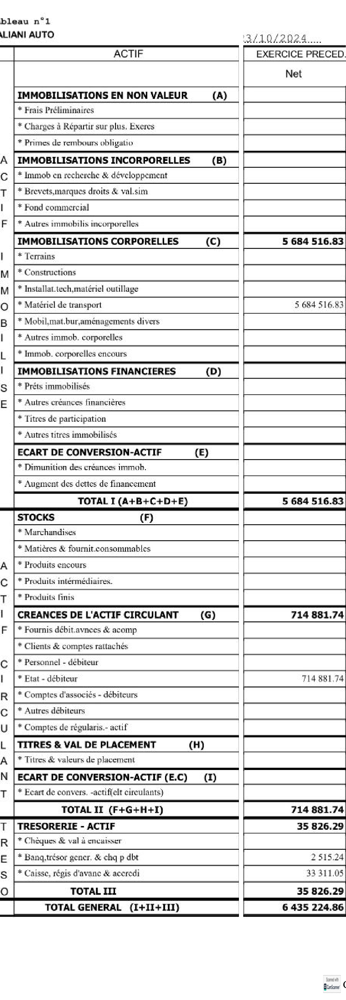


Préparation terminée.
ACTIF : 4 images
PASSIF : 2 images
Aucun CSV final créé.


In [77]:

# ============================================================
# CORRECTION DES DECOUPAGES DYNAMIQUES
# ============================================================

from PIL import Image
from pathlib import Path
from IPython.display import display

output_dir = Path("/kaggle/working/colonnes_dynamiques")
output_dir.mkdir(parents=True, exist_ok=True)

images_colonnes_actif = {}
images_colonnes_passif = {}

def preparer_colonnes_corrigees(type_bilan):

    # Charger l'image originale
    image_path = PAGES[type_bilan]
    image = Image.open(image_path).convert("RGB")

    largeur, hauteur = image.size

    # Récupérer les coordonnées OpenCV déjà détectées
    colonnes = coordonnees_detectees[type_bilan]

    # Première colonne : noms des postes
    poste = colonnes[0]

    # Ajouter une marge dynamique de 2 % à gauche
    marge_gauche = int(largeur * 0.02)

    x1_poste = max(
        0,
        poste["x1"] - marge_gauche
    )

    x2_poste = poste["x2"] - 2

    image_postes = image.crop((
        x1_poste,
        0,
        x2_poste,
        hauteur
    ))

    fichiers = {}

    # Associer les postes à chaque colonne numérique
    for colonne in colonnes[1:]:

        nom = colonne["nom"]

        x1 = colonne["x1"] + 2
        x2 = colonne["x2"] - 2

        image_valeurs = image.crop((
            x1, 0, x2, hauteur
        ))

        espace = 15

        image_finale = Image.new(
            "RGB",
            (
                image_postes.width + espace + image_valeurs.width,
                hauteur
            ),
            "white"
        )

        image_finale.paste(
            image_postes,
            (0, 0)
        )

        image_finale.paste(
            image_valeurs,
            (image_postes.width + espace, 0)
        )

        # Enregistrer l'image préparée
        chemin = output_dir / f"{type_bilan}_{nom}.png"
        image_finale.save(chemin)

        fichiers[nom] = str(chemin)

        print(f"{type_bilan} — {nom} : OK")

    return fichiers


# Recréer les images ACTIF et PASSIF
for type_bilan in ["ACTIF", "PASSIF"]:

    if type_bilan not in coordonnees_detectees:
        print(f"{type_bilan} : coordonnées non disponibles")
        continue

    fichiers = preparer_colonnes_corrigees(type_bilan)

    if type_bilan == "ACTIF":
        images_colonnes_actif = fichiers
    else:
        images_colonnes_passif = fichiers


# Afficher un exemple ACTIF pour vérifier
if "net_N1" in images_colonnes_actif:

    print("\n===== APERCU ACTIF NET N-1 =====")

    image_test = Image.open(
        images_colonnes_actif["net_N1"]
    )

    display(image_test)

print("\nPréparation terminée.")
print("ACTIF :", len(images_colonnes_actif), "images")
print("PASSIF :", len(images_colonnes_passif), "images")

print("Aucun CSV final créé.")


In [78]:

# ============================================================
# EXTRACTION VLM — COLONNE ACTIF NET N-1
# ============================================================

import pandas as pd
from pathlib import Path

# 1. Récupérer l'image créée automatiquement
image_path = images_colonnes_actif["net_N1"]

assert Path(image_path).exists(), "Image introuvable"

# 2. Construire le prompt
messages_net_N1 = [
    {
        "role": "system",
        "content": (
            "Tu es un système spécialisé dans la "
            "transcription fidèle de tableaux comptables. "
            "Tu lis chaque ligne et chaque cellule sans "
            "inventer ni calculer de valeurs."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": Path(image_path).resolve().as_uri(),
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Cette image contient deux colonnes :

1. A gauche : les noms des postes comptables.
2. A droite : NET de l'exercice précédent N-1.

OBJECTIF :
Extraire toutes les lignes du tableau de haut en bas.

REGLES :
- Conserver chaque poste visible.
- Conserver exactement l'ordre des lignes.
- Inclure les rubriques et les sous-totaux.
- Inclure TOTAL I, TOTAL II, TOTAL III.
- Inclure TOTAL GENERAL.
- Ne pas ignorer les lignes sans montant.
- Ne jamais copier le montant d'une autre ligne.
- Ne pas calculer les montants.
- Si une cellule est vide ou illisible, utiliser null.
- Ne pas inclure les en-têtes du tableau.

Retourne uniquement ce JSON :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom exact du poste",
      "valeur": null
    }
  ]
}

Remplace valeur par le montant NET N-1 lu sur l'image.
"""
            }
        ]
    }
]

# 3. Exécuter Qwen2.5-VL
resultat_net_N1 = extraire_avec_vlm(
    messages_net_N1,
    max_tokens=4000
)

print("STATUT :", resultat_net_N1["statut"])
print("TOKENS :", resultat_net_N1["nombre_tokens"])

# 4. Construire le tableau
if resultat_net_N1["statut"] == "OK":

    df_net_N1 = pd.DataFrame(
        resultat_net_N1["donnees"]["lignes"]
    )

    assert {"poste", "valeur"}.issubset(df_net_N1.columns)

    df_net_N1 = df_net_N1.rename(
        columns={"valeur": "net_N1"}
    )

    print("\n===== EXTRACTION ACTIF NET N-1 =====")
    display(df_net_N1)

    print("\nNombre de lignes :", len(df_net_N1))
    print(
        "Cellules renseignées :",
        df_net_N1["net_N1"].notna().sum()
    )
    print(
        "Cellules non renseignées :",
        df_net_N1["net_N1"].isna().sum()
    )

    print("\n===== DERNIERES LIGNES =====")
    display(df_net_N1.tail(8))

else:

    print("Extraction non validée.")
    print("Erreur :", resultat_net_N1["erreur"])
    print(resultat_net_N1["texte_brut"][-1000:])

print("\nAucun CSV final créé.")


STATUT : OK
TOKENS : 1465

===== EXTRACTION ACTIF NET N-1 =====


,poste,net_N1
0,IMMOBILISATIONS EN NON VALEUR (A),NaN
1,* Frais Préliminaires,NaN
2,"* Charges à Répartir sur plus, Exercès",NaN
3,* Primes de remboursements obligatoires,NaN
4,IMMOBILISATIONS INCORPORELLES (B),NaN
5,* Immobilisations en recherche & développement,NaN
6,"* Brevets, marques, droits & valeurs similaires",NaN
7,* Fonds commerciaux,NaN
8,* Autres immobilisations incorporelles,NaN
9,IMMOBILISATIONS CORPORELLES (C),5684516.83



Nombre de lignes : 51
Cellules renseignées : 10
Cellules non renseignées : 41

===== DERNIERES LIGNES =====


,poste,net_N1
43,* Écart de conversion - actif et circulants,NaN
44,TOTAL II (F+G+H+I),714881.74
45,TRESORERIE - ACTIF,NaN
46,* Chèques & valeurs à encaisser,NaN
47,"* Banque, trésor général, & chèques pour débit",2515.24
48,"* Caisse, régies d'avance & accordi",33311.05
49,TOTAL III,35826.29
50,TOTAL GÉNÉRAL (I+II+III),6435224.86



Aucun CSV final créé.


In [80]:

# ============================================================
# CORRECTION — RECUPERER L'EXTRACTION BRUT N
# ============================================================

import pandas as pd

# 1. Examiner la réponse du modèle
print("===== STATUT =====")
print(resultat_brut_N["statut"])

print("\n===== DEBUT DE LA REPONSE BRUTE =====")
print(resultat_brut_N["texte_brut"][:1500])

# 2. Récupérer le JSON
donnees = resultat_brut_N["donnees"]

if donnees is None:
    raise ValueError("Aucun JSON valide disponible.")

lignes = donnees.get("lignes", [])

print("\nNombre de lignes reçues :", len(lignes))

if not lignes:
    raise ValueError(
        "Qwen a retourné une liste de lignes vide."
    )

# 3. Construire le DataFrame
df_brut_N = pd.DataFrame(lignes)

print("\n===== COLONNES GENEREES PAR QWEN =====")
print(df_brut_N.columns.tolist())

display(df_brut_N.head(5))

# 4. Vérifier la présence des postes
if "poste" not in df_brut_N.columns:
    raise ValueError(
        "Champ 'poste' absent. Vérifier le JSON affiché."
    )

# 5. Identifier le champ qui contient les montants
if "valeur" in df_brut_N.columns:
    colonne_valeur = "valeur"

elif "brut_N" in df_brut_N.columns:
    colonne_valeur = "brut_N"

else:
    raise ValueError(
        "Champ numérique non reconnu. Colonnes présentes : "
        + str(df_brut_N.columns.tolist())
    )

# 6. Uniformiser les noms
df_brut_N = df_brut_N[
    ["poste", colonne_valeur]
].copy()

df_brut_N.columns = ["poste", "brut_N"]

# 7. Afficher le résultat
print("\n===== EXTRACTION ACTIF BRUT N =====")
display(df_brut_N)

print("\nNombre de lignes :", len(df_brut_N))
print("Montants renseignés :", df_brut_N["brut_N"].notna().sum())
print("Cellules non renseignées :", df_brut_N["brut_N"].isna().sum())

# 8. Comparer à NET N-1
print("\n===== COMPARAISON DES STRUCTURES =====")

print("BRUT N :", len(df_brut_N), "lignes")
print("NET N-1 :", len(df_net_N1), "lignes")

if len(df_brut_N) == len(df_net_N1):
    print("Même nombre de lignes.")
else:
    print("ATTENTION : nombres de lignes différents.")

# 9. Afficher les dernières lignes
print("\n===== DERNIERES LIGNES =====")
display(df_brut_N.tail(8))

print("\nAucun CSV final créé.")


===== STATUT =====
OK

===== DEBUT DE LA REPONSE BRUTE =====
```json
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "IMMOBILISATIONS EN NON VALEUR (A)"
    },
    {
      "poste": "* Frais Préliminaires"
    },
    {
      "poste": "* Charges à Répartir sur plus. Exercs"
    },
    {
      "poste": "* Primes de rembours obligatio"
    },
    {
      "poste": "IMMOBILISATIONS INCORPORELLES (B)"
    },
    {
      "poste": "* Immob en recherche & développement"
    },
    {
      "poste": "* Brevets,marques droits & val.sim"
    },
    {
      "poste": "* Fond commercial"
    },
    {
      "poste": "* Autres immobilis incorporelles"
    },
    {
      "poste": "IMMOBILISATIONS CORPORELLES (C)"
    },
    {
      "poste": "* Terrains"
    },
    {
      "poste": "* Constructions"
    },
    {
      "poste": "* Installat.tech,matériel outillage"
    },
    {
      "poste": "* Matériel de transport"
    },
    {
      "poste": "* Mobil,mat.bur,aménagements divers"
    },
   

,poste
0,IMMOBILISATIONS EN NON VALEUR (A)
1,* Frais Préliminaires
2,* Charges à Répartir sur plus. Exercs
3,* Primes de rembours obligatio
4,IMMOBILISATIONS INCORPORELLES (B)


ValueError: Champ numérique non reconnu. Colonnes présentes : ['poste']

===== IMAGE TRANSMISE AU VLM =====


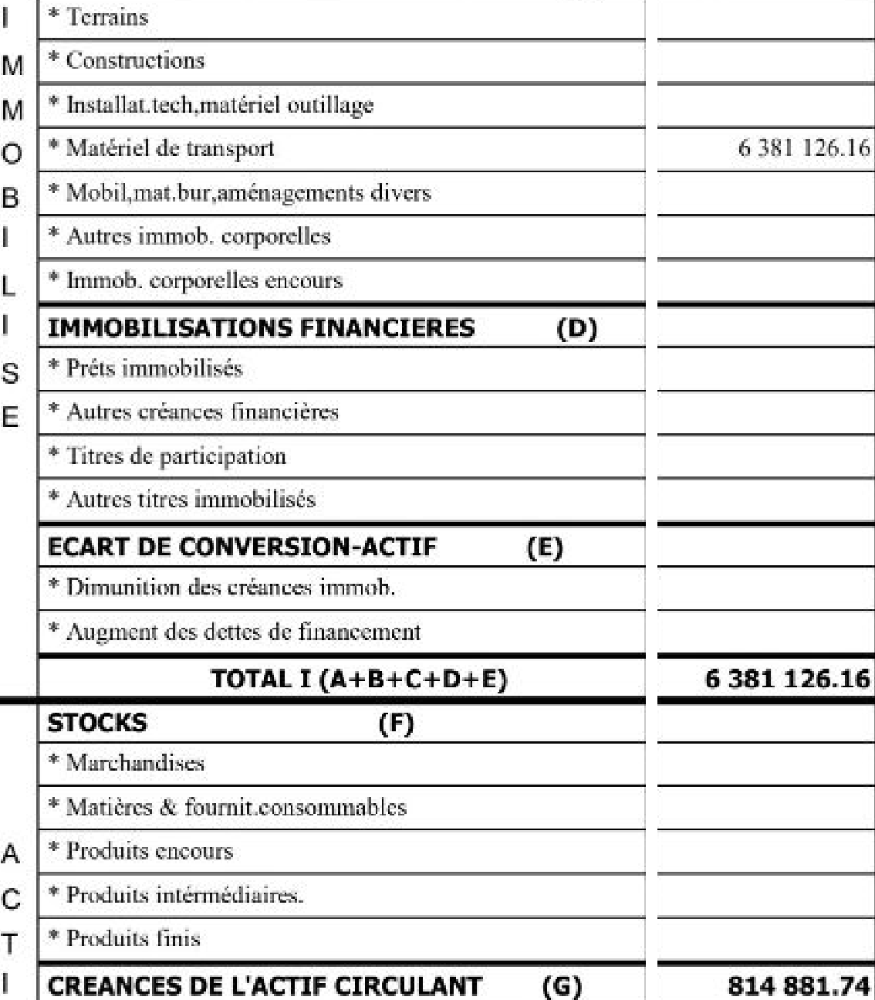

STATUT : OK
Colonnes retournées :
['poste', 'valeur']

EXTRACTION NUMERIQUE :


,poste,valeur
0,* Terrains,NaN
1,* Constructions,NaN
2,"* Installat.tech,materiel outillage",NaN
3,* Matériel de transport,6381126.16
4,"* Mobil,mat,bur,aménagements divers",NaN
5,* Autres immob. corporelles,NaN
6,* Inmob. corporelles encours,NaN
7,IMMOBILISATIONS FINANCIERES (D),NaN
8,* Prêts immobilisés,NaN
9,* Autres créances financières,NaN


Montants renseignés : 3


In [81]:

# ============================================================
# CORRECTION : EXTRACTION CIBLEE BRUT N
# ============================================================

from PIL import Image
from pathlib import Path
from IPython.display import display
import pandas as pd

# 1. Charger l'image dynamique existante
image_path = images_colonnes_actif["brut_N"]

image = Image.open(image_path).convert("RGB")
w, h = image.size

# 2. Isoler une zone contenant les immobilisations
# et conserver l'alignement postes / montants
zone = image.crop((
    0,
    int(h * 0.25),
    w,
    int(h * 0.62)
))

chemin_zone = Path(
    "/kaggle/working/test_brut_N.png"
)

zone.save(chemin_zone)

print("===== IMAGE TRANSMISE AU VLM =====")
display(zone)

# 3. Prompt plus court et plus strict
messages_test_brut = [
    {
        "role": "system",
        "content": (
            "Tu transcris des tableaux comptables. "
            "Chaque ligne doit obligatoirement contenir "
            "les deux champs poste et valeur."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin_zone.resolve().as_uri(),
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Cette image contient :
- A gauche : les postes comptables.
- A droite : les montants BRUT N.

Extrais toutes les lignes entièrement visibles.

REGLES :
1. Chaque ligne possède obligatoirement
   les champs "poste" et "valeur".
2. Lis le montant de la colonne de droite.
3. Si la cellule est vide, valeur = null.
4. Ne calcule aucun montant.
5. N'invente aucune valeur.
6. Conserve l'ordre original.

EXEMPLE DE STRUCTURE (valeurs fictives) :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {"poste": "Exemple A", "valeur": 1500.00},
    {"poste": "Exemple B", "valeur": null}
  ]
}

Retourne uniquement le JSON.
"""
            }
        ]
    }
]

# 4. Exécuter le modèle
resultat_brut_test = extraire_avec_vlm(
    messages_test_brut,
    max_tokens=1800
)

print("STATUT :", resultat_brut_test["statut"])

# 5. Vérifier les deux champs obligatoires
if resultat_brut_test["donnees"] is not None:

    lignes = resultat_brut_test["donnees"]["lignes"]

    df_brut_test = pd.DataFrame(lignes)

    print("Colonnes retournées :")
    print(df_brut_test.columns.tolist())

    if {"poste", "valeur"}.issubset(df_brut_test.columns):

        print("\nEXTRACTION NUMERIQUE :")
        display(df_brut_test)

        print(
            "Montants renseignés :",
            df_brut_test["valeur"].notna().sum()
        )

    else:
        print("ECHEC : champ valeur absent.")
        print(resultat_brut_test["texte_brut"][:1000])

else:
    print("JSON invalide.")
    print(resultat_brut_test["texte_brut"][-1000:])


Dimensions de l'image : (1134, 3500)

===== IMAGE TRANSMISE AU VLM =====


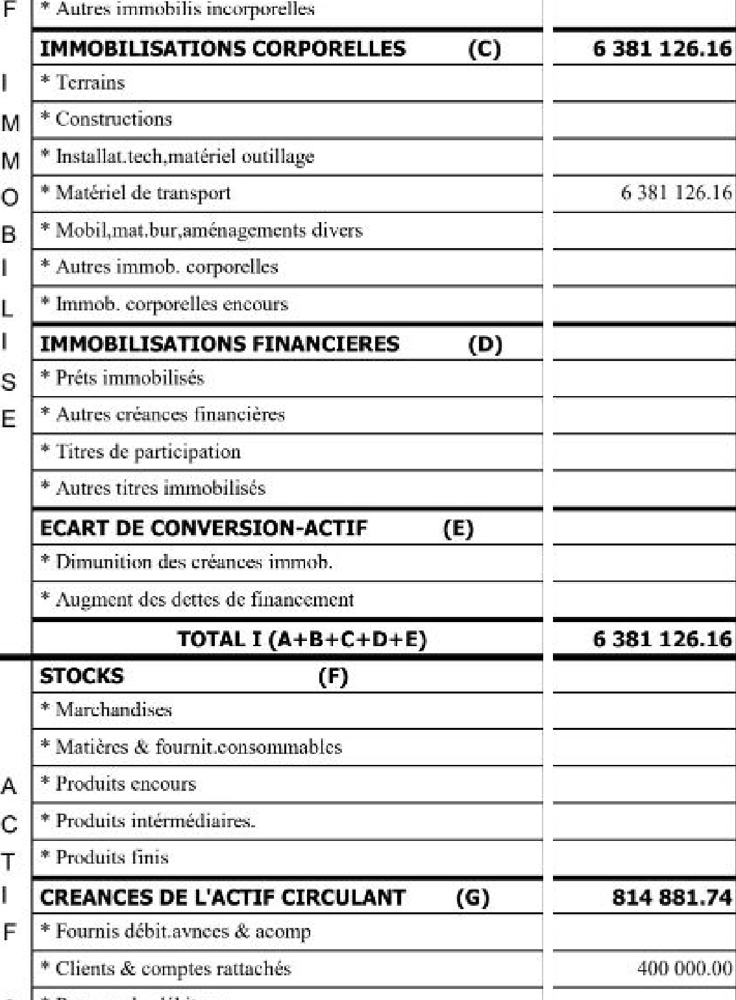


===== RESULTAT VLM =====
Statut : OK
Tokens générés : 778
Temps : 49.81 secondes

Nombre de lignes reçues : 28

===== EXTRACTION ACTIF BRUT N =====


,poste,brut_N
0,IMMOBILISATIONS CORPORELLES (C),6381126.16
1,* Terrains,NaN
2,* Constructions,NaN
3,"* Installat.tech.,matériel outillage",NaN
4,* Matériel de transport,6381126.16
5,"* Mobil,mat.bur.,aménagements divers",NaN
6,* Autres immob. corporelles,NaN
7,* Immob. corporelles encours,NaN
8,IMMOBILISATIONS FINANCIERES (D),NaN
9,* Prêts immobilisés,NaN



===== STATISTIQUES =====
Nombre de lignes : 28
Montants renseignés : 5
Cellules non renseignées : 23

===== DERNIERES LIGNES =====


,poste,brut_N
20,* Produits encours,NaN
21,* Produits intermédiaires.,NaN
22,* Produits finis,NaN
23,CREANCES DE L'ACTIF CIRCULANT (G),814881.74
24,* Fournis débit.avances & acomp,NaN
25,* Clients & comptes rattachés,400000.00
26,* Remises de crédit,NaN
27,* Autres créances circulantes,NaN



Aucun CSV final créé.


In [82]:

# ============================================================
# EXTRACTION CIBLEE ACTIF — COLONNE BRUT N
# ============================================================

import pandas as pd
from PIL import Image
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. Charger l'image de la colonne BRUT N
# ------------------------------------------------------------

image_path = Path(images_colonnes_actif["brut_N"])

if not image_path.is_file():
    raise FileNotFoundError(image_path)

image = Image.open(image_path).convert("RGB")

w, h = image.size

print("Dimensions de l'image :", image.size)


# ------------------------------------------------------------
# 2. Extraire une zone plus large
# ------------------------------------------------------------

y1 = int(h * 0.22)
y2 = int(h * 0.66)

zone = image.crop((
    0,
    y1,
    w,
    y2
))

chemin_zone = Path("/kaggle/working/test_brut_N.png")

zone.save(chemin_zone)

print("\n===== IMAGE TRANSMISE AU VLM =====")
display(zone)


# ------------------------------------------------------------
# 3. Construire le prompt
# ------------------------------------------------------------

messages_test_brut = [
    {
        "role": "system",
        "content": (
            "Tu es un système spécialisé dans l'extraction "
            "de tableaux comptables marocains. "
            "Tu dois transcrire fidèlement chaque ligne "
            "avec deux champs obligatoires : poste et valeur. "
            "Tu ne dois inventer aucun montant."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin_zone.resolve().as_uri(),
                "max_pixels": 2048 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Cette image représente une partie du bilan ACTIF.

Elle contient deux colonnes :
- A gauche : les noms des postes comptables.
- A droite : les valeurs BRUT de l'exercice actuel N.

OBJECTIF :
Extraire toutes les lignes comptables
entièrement visibles de haut en bas.

REGLES IMPORTANTES :

1. Respecter l'ordre exact des lignes.
2. Chaque ligne doit contenir deux champs :
   "poste" et "valeur".
3. Lire uniquement la colonne BRUT N.
4. Ne pas confondre une rubrique et ses détails.
5. Inclure les rubriques, les détails et les totaux.
6. Si une cellule est vide, utiliser null.
7. Si une cellule est illisible, utiliser null.
8. Ne jamais inventer de montant.
9. Ne jamais calculer de montant.
10. Ne pas recopier une valeur sur une autre ligne.
11. Ne pas inclure les en-têtes des colonnes.
12. Ne pas extraire une ligne partiellement coupée.

FORMAT DES NOMBRES :

6 381 126,16 devient 6381126.16.
Les montants doivent être numériques.

FORMAT JSON OBLIGATOIRE :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "Exemple de poste",
      "valeur": 1500.00
    },
    {
      "poste": "Autre poste",
      "valeur": null
    }
  ]
}

Les données de l'exemple sont fictives.

IMPORTANT :
Même lorsque la cellule est vide,
le champ "valeur" doit être présent.

Retourne uniquement du JSON valide.
Aucune explication.
"""
            }
        ]
    }
]


# ------------------------------------------------------------
# 4. Exécuter Qwen2.5-VL
# ------------------------------------------------------------

resultat_brut_test = extraire_avec_vlm(
    messages_test_brut,
    max_tokens=2400
)

print("\n===== RESULTAT VLM =====")
print("Statut :", resultat_brut_test["statut"])
print("Tokens générés :", resultat_brut_test["nombre_tokens"])
print("Temps :", resultat_brut_test["temps_secondes"], "secondes")


# ------------------------------------------------------------
# 5. Vérifier le JSON et sa structure
# ------------------------------------------------------------

df_brut_test = None

if resultat_brut_test["statut"] != "OK":

    print("\nEXTRACTION NON VALIDEE")
    print("Erreur :", resultat_brut_test["erreur"])
    print(resultat_brut_test["texte_brut"][-1200:])

else:

    donnees = resultat_brut_test["donnees"]
    lignes = donnees.get("lignes", [])

    print("\nNombre de lignes reçues :", len(lignes))

    # Vérifier chaque ligne sans corriger les valeurs
    lignes_invalides = []

    for i, ligne in enumerate(lignes):

        if not isinstance(ligne, dict):
            lignes_invalides.append(i)
            continue

        if "poste" not in ligne or "valeur" not in ligne:
            lignes_invalides.append(i)

    if lignes_invalides:

        print("\nSCHEMA JSON INCOMPLET")
        print("Lignes problématiques :", lignes_invalides)

        for i in lignes_invalides[:5]:
            print(i, ":", lignes[i])

        print("\nAucune validation automatique.")

    else:

        # Construire le tableau Pandas
        df_brut_test = pd.DataFrame(
            lignes,
            columns=["poste", "valeur"]
        )

        # Renommer la colonne numérique
        df_brut_test.rename(
            columns={"valeur": "brut_N"},
            inplace=True
        )

        print("\n===== EXTRACTION ACTIF BRUT N =====")
        display(df_brut_test)

        print("\n===== STATISTIQUES =====")
        print("Nombre de lignes :", len(df_brut_test))

        print(
            "Montants renseignés :",
            df_brut_test["brut_N"].notna().sum()
        )

        print(
            "Cellules non renseignées :",
            df_brut_test["brut_N"].isna().sum()
        )

        print("\n===== DERNIERES LIGNES =====")
        display(df_brut_test.tail(8))


print("\nAucun CSV final créé.")


In [83]:

# ============================================================
# CONTROLE DES POSTES EXTRAITS — BRUT N
# ============================================================

import pandas as pd
import re
import unicodedata
from difflib import SequenceMatcher

# 1. Normaliser les noms des postes
def normaliser_poste(texte):

    texte = str(texte).lower()

    texte = unicodedata.normalize(
        "NFKD", texte
    )

    texte = "".join(
        c for c in texte
        if not unicodedata.combining(c)
    )

    texte = re.sub(r"[^a-z0-9]+", " ", texte)

    return " ".join(texte.split())


# 2. Liste de référence provisoire
postes_reference = df_net_N1["poste"].tolist()

# 3. Comparer chaque poste BRUT N
resultats_comparaison = []

for _, ligne in df_brut_test.iterrows():

    poste = ligne["poste"]
    poste_normalise = normaliser_poste(poste)

    correspondances = []

    for ref in postes_reference:

        score = SequenceMatcher(
            None,
            poste_normalise,
            normaliser_poste(ref)
        ).ratio()

        correspondances.append((score, ref))

    meilleur_score, meilleur_poste = max(
        correspondances,
        key=lambda x: x[0]
    )

    statut = (
        "CORRESPONDANCE_PROBABLE"
        if meilleur_score >= 0.75
        else "A_VERIFIER"
    )

    resultats_comparaison.append({
        "poste_extrait": poste,
        "brut_N": ligne["brut_N"],
        "poste_reference": meilleur_poste,
        "similarite": round(meilleur_score, 3),
        "statut": statut
    })


# 4. Construire le tableau de diagnostic
df_comparaison = pd.DataFrame(
    resultats_comparaison
)

print("===== COMPARAISON DES POSTES =====")
display(df_comparaison)

# 5. Identifier les lignes suspectes
suspects = df_comparaison[
    df_comparaison["statut"] == "A_VERIFIER"
]

print("\n===== POSTES SUSPECTS =====")
display(suspects)

print("\nNombre de postes BRUT N :", len(df_brut_test))
print("Postes à vérifier :", len(suspects))

print("\nAucune valeur n'a été modifiée.")
print("Aucun CSV final créé.")


===== COMPARAISON DES POSTES =====


,poste_extrait,brut_N,poste_reference,similarite,statut
0,IMMOBILISATIONS CORPORELLES (C),6381126.16,IMMOBILISATIONS CORPORELLES (C),1.000,CORRESPONDANCE_PROBABLE
1,* Terrains,NaN,* Terrains,1.000,CORRESPONDANCE_PROBABLE
2,* Constructions,NaN,* constructions,1.000,CORRESPONDANCE_PROBABLE
3,"* Installat.tech.,matériel outillage",NaN,"* Installations, équipements, matériel et outi...",0.750,CORRESPONDANCE_PROBABLE
4,* Matériel de transport,6381126.16,* Matériel de transport,1.000,CORRESPONDANCE_PROBABLE
5,"* Mobil,mat.bur.,aménagements divers",NaN,"* Mobilisations, matériels, bureaux, aménageme...",0.786,CORRESPONDANCE_PROBABLE
6,* Autres immob. corporelles,NaN,* Autres immobilisations corporelles,0.828,CORRESPONDANCE_PROBABLE
7,* Immob. corporelles encours,NaN,* Immobilisations corporelles en cours,0.820,CORRESPONDANCE_PROBABLE
8,IMMOBILISATIONS FINANCIERES (D),NaN,IMMOBILISATIONS FINANCIERES (D),1.000,CORRESPONDANCE_PROBABLE
9,* Prêts immobilisés,NaN,* Prêts immobilisés,1.000,CORRESPONDANCE_PROBABLE



===== POSTES SUSPECTS =====


,poste_extrait,brut_N,poste_reference,similarite,statut
26,* Remises de crédit,NaN,"* Caisse, régies d'avance & accordi",0.553,A_VERIFIER



Nombre de postes BRUT N : 28
Postes à vérifier : 1

Aucune valeur n'a été modifiée.
Aucun CSV final créé.


In [84]:

# ============================================================
# VALIDATION DES POSTES AVEC RESPECT DE L'ORDRE
# ============================================================

import pandas as pd
import re
import unicodedata
from difflib import SequenceMatcher

def normaliser_nom(texte):
    texte = unicodedata.normalize("NFKD", str(texte).lower())
    texte = "".join(
        c for c in texte
        if not unicodedata.combining(c)
    )
    return " ".join(re.sub(r"[^a-z0-9]+", " ", texte).split())


reference = df_net_N1["poste"].tolist()
extraction = df_brut_test["poste"].tolist()

resultats = []
dernier_index = -1

for i, poste in enumerate(extraction):

    # Ne rechercher que dans les lignes suivantes
    candidats = []

    for j in range(dernier_index + 1, len(reference)):

        score = SequenceMatcher(
            None,
            normaliser_nom(poste),
            normaliser_nom(reference[j])
        ).ratio()

        candidats.append((score, j))

    if not candidats:
        resultats.append({
            "poste_extrait": poste,
            "poste_reference": None,
            "similarite": 0,
            "statut": "A_VERIFIER"
        })
        continue

    score, index_ref = max(candidats, key=lambda x: x[0])

    if score >= 0.75:
        statut = "CORRESPONDANCE_PROBABLE"
        dernier_index = index_ref
    else:
        statut = "A_VERIFIER"

    resultats.append({
        "poste_extrait": poste,
        "brut_N": df_brut_test.iloc[i]["brut_N"],
        "poste_reference": reference[index_ref],
        "similarite": round(score, 3),
        "statut": statut
    })


df_validation_ordre = pd.DataFrame(resultats)

print("===== VALIDATION DANS L'ORDRE DU PDF =====")
display(df_validation_ordre)

print("\n===== LIGNES A VERIFIER =====")

anomalies = df_validation_ordre[
    df_validation_ordre["statut"] == "A_VERIFIER"
]

display(anomalies)

print("\nNombre de lignes à vérifier :", len(anomalies))
print("Aucune donnée modifiée.")
print("Aucun CSV final créé.")


===== VALIDATION DANS L'ORDRE DU PDF =====


,poste_extrait,brut_N,poste_reference,similarite,statut
0,IMMOBILISATIONS CORPORELLES (C),6381126.16,IMMOBILISATIONS CORPORELLES (C),1.000,CORRESPONDANCE_PROBABLE
1,* Terrains,NaN,* Terrains,1.000,CORRESPONDANCE_PROBABLE
2,* Constructions,NaN,* constructions,1.000,CORRESPONDANCE_PROBABLE
3,"* Installat.tech.,matériel outillage",NaN,"* Installations, équipements, matériel et outi...",0.750,CORRESPONDANCE_PROBABLE
4,* Matériel de transport,6381126.16,* Matériel de transport,1.000,CORRESPONDANCE_PROBABLE
5,"* Mobil,mat.bur.,aménagements divers",NaN,"* Mobilisations, matériels, bureaux, aménageme...",0.786,CORRESPONDANCE_PROBABLE
6,* Autres immob. corporelles,NaN,* Autres immobilisations corporelles,0.828,CORRESPONDANCE_PROBABLE
7,* Immob. corporelles encours,NaN,* Immobilisations corporelles en cours,0.820,CORRESPONDANCE_PROBABLE
8,IMMOBILISATIONS FINANCIERES (D),NaN,IMMOBILISATIONS FINANCIERES (D),1.000,CORRESPONDANCE_PROBABLE
9,* Prêts immobilisés,NaN,* Prêts immobilisés,1.000,CORRESPONDANCE_PROBABLE



===== LIGNES A VERIFIER =====


,poste_extrait,brut_N,poste_reference,similarite,statut
26,* Remises de crédit,NaN,"* Caisse, régies d'avance & accordi",0.553,A_VERIFIER
27,* Autres créances circulantes,NaN,* Autres débiteurs,0.558,A_VERIFIER



Nombre de lignes à vérifier : 2
Aucune donnée modifiée.
Aucun CSV final créé.


Lignes horizontales détectées : 54
Bloc 1 : lignes 0 à 9
Bloc 2 : lignes 9 à 18
Bloc 3 : lignes 18 à 27
Bloc 4 : lignes 27 à 36
Bloc 5 : lignes 36 à 45
Bloc 6 : lignes 45 à 52

===== APERCU DES BLOCS =====

BLOC 1
Lignes : 0 à 9


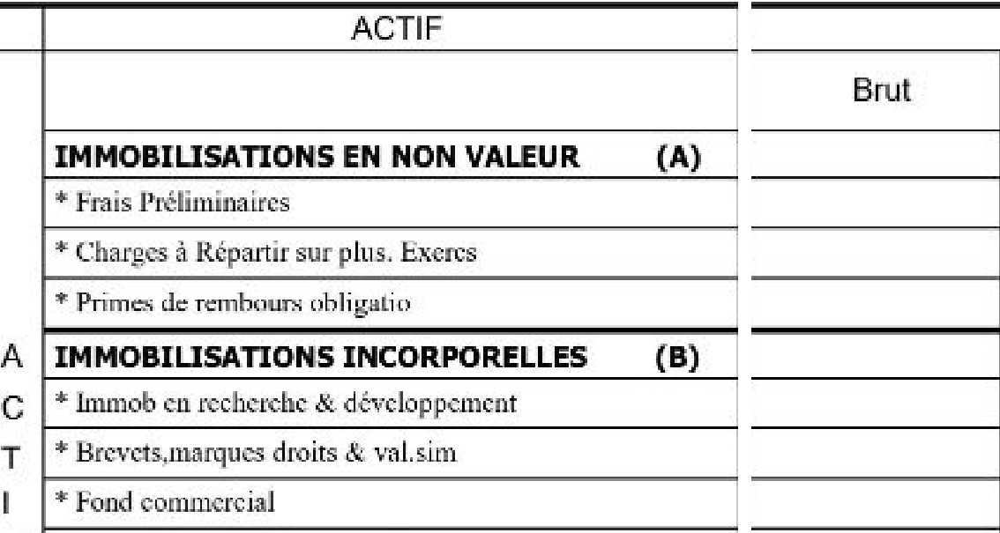


BLOC 2
Lignes : 9 à 18


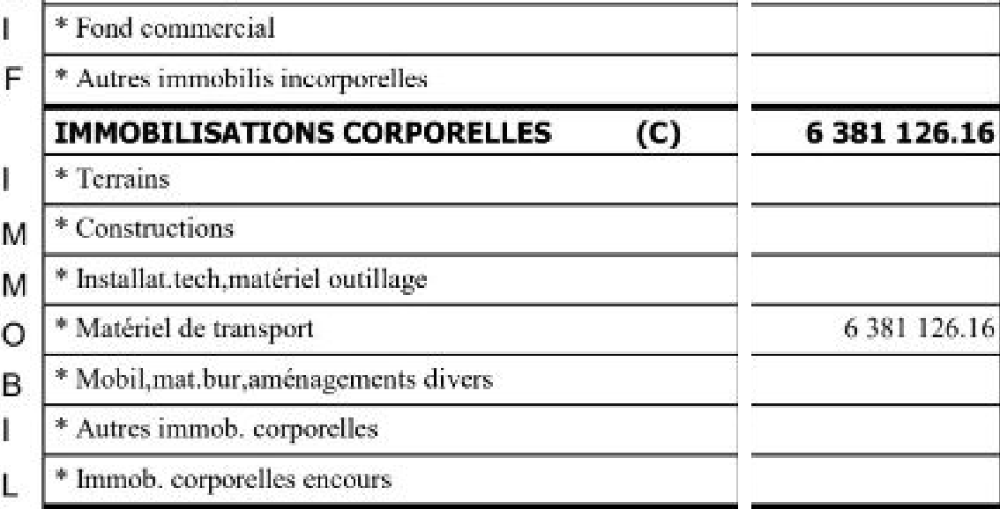


BLOC 3
Lignes : 18 à 27


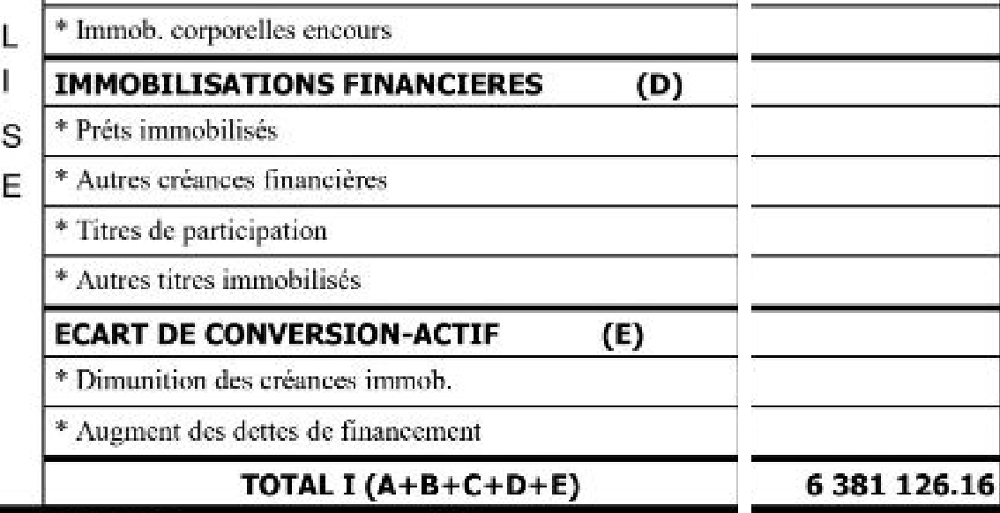


BLOC 4
Lignes : 27 à 36


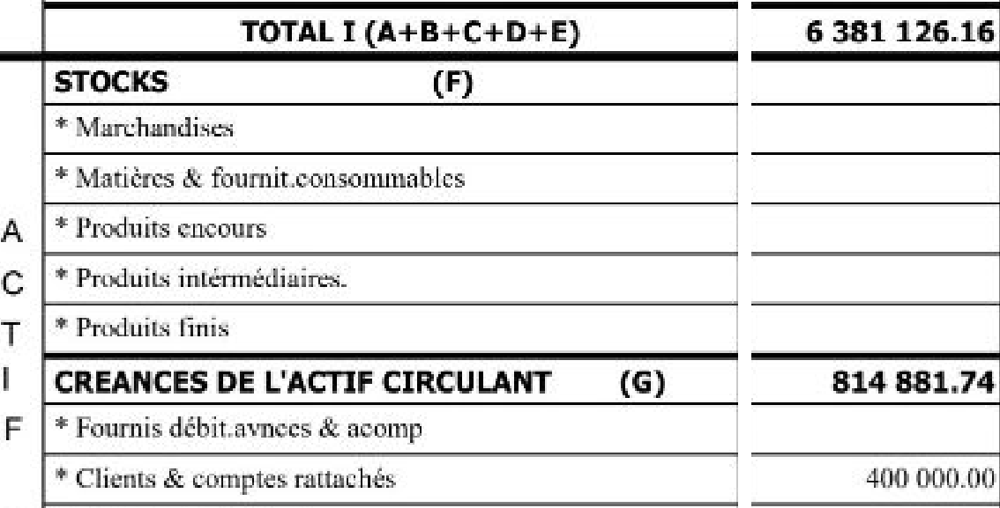


BLOC 5
Lignes : 36 à 45


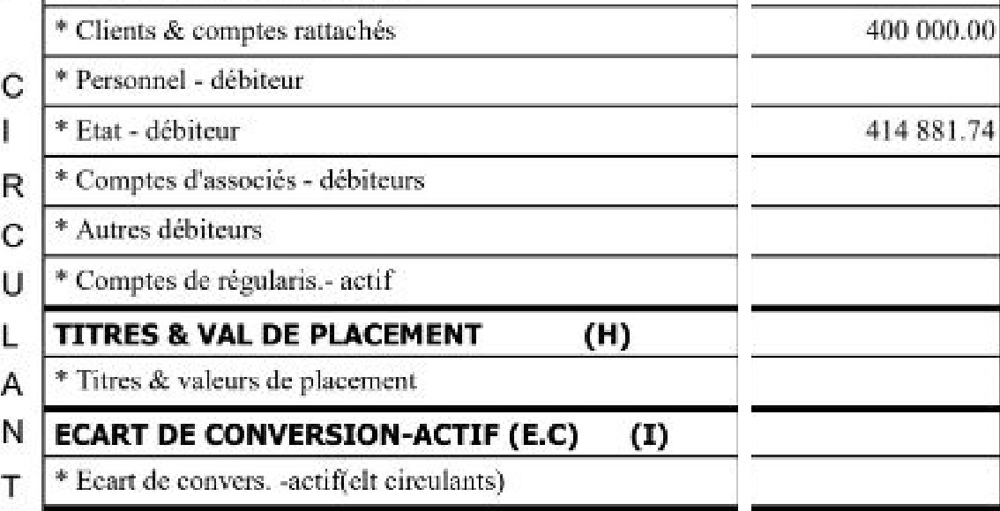


BLOC 6
Lignes : 45 à 52


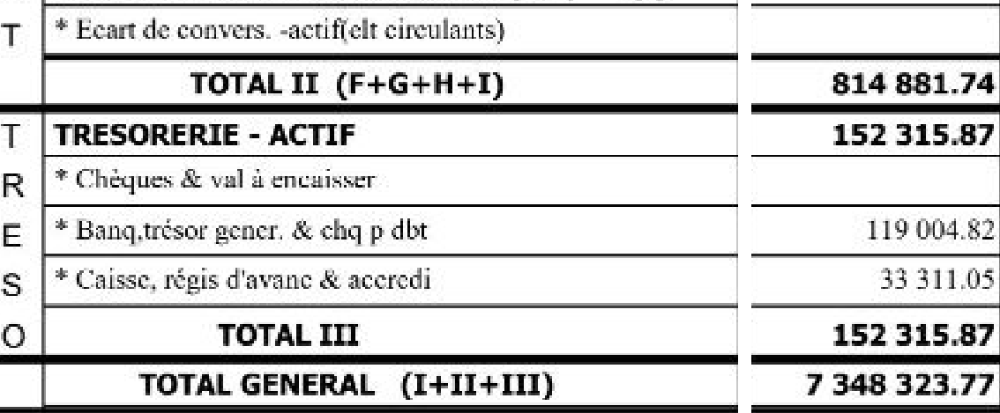


Nombre total de blocs : 6
Aucun CSV final créé.


In [85]:

# ============================================================
# DETECTION DYNAMIQUE DES LIGNES DU TABLEAU ACTIF
# ============================================================

import cv2
import numpy as np
from PIL import Image
from pathlib import Path
from IPython.display import display

# 1. Image ACTIF : postes + BRUT N
image_path = images_colonnes_actif["brut_N"]

image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

h, w = image_np.shape[:2]

# 2. Conversion en niveaux de gris
gris = cv2.cvtColor(
    image_np,
    cv2.COLOR_RGB2GRAY
)

# 3. Binarisation
_, binaire = cv2.threshold(
    gris,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# 4. Détecter les lignes horizontales
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (max(25, w // 3), 1)
)

lignes_horizontales = cv2.morphologyEx(
    binaire,
    cv2.MORPH_OPEN,
    kernel
)

# 5. Déterminer les positions Y des lignes
profil = np.count_nonzero(
    lignes_horizontales,
    axis=1
)

positions = np.where(
    profil > w * 0.27
)[0]

# Regrouper les pixels appartenant à un même trait
groupes = []

for y in positions:

    y = int(y)

    if not groupes or y - groupes[-1][-1] > 3:
        groupes.append([y])
    else:
        groupes[-1].append(y)

limites_y = [
    int(np.median(groupe))
    for groupe in groupes
]

print("Lignes horizontales détectées :", len(limites_y))

if len(limites_y) < 12:
    raise ValueError(
        "Pas assez de lignes détectées. "
        "Vérifier la structure du tableau."
    )

# 6. Créer des blocs de 10 lignes comptables
# Une ligne de chevauchement entre blocs
lignes_par_bloc = 10
chevauchement = 1

dossier = Path("/kaggle/working/blocs_actif_brut")
dossier.mkdir(parents=True, exist_ok=True)

blocs_brut = []

nombre_intervalles = len(limites_y) - 1
debut = 0

while debut < nombre_intervalles:

    fin = min(
        debut + lignes_par_bloc,
        nombre_intervalles
    )

    y1 = max(0, limites_y[debut] - 5)
    y2 = min(h, limites_y[fin] + 5)

    bloc = image.crop((0, y1, w, y2))

    chemin = dossier / (
        f"bloc_brut_{len(blocs_brut) + 1}.png"
    )

    bloc.save(chemin)

    blocs_brut.append({
        "chemin": str(chemin),
        "premiere_ligne": debut,
        "derniere_ligne": fin - 1
    })

    print(
        f"Bloc {len(blocs_brut)} : "
        f"lignes {debut} à {fin - 1}"
    )

    if fin == nombre_intervalles:
        break

    debut = fin - chevauchement


# 7. Afficher les blocs pour vérification
print("\n===== APERCU DES BLOCS =====")

for i, infos in enumerate(blocs_brut, start=1):

    print(f"\nBLOC {i}")
    print("Lignes :", infos["premiere_ligne"],
          "à", infos["derniere_ligne"])

    apercu = Image.open(infos["chemin"])
    display(apercu)

print("\nNombre total de blocs :", len(blocs_brut))
print("Aucun CSV final créé.")


===== BLOCS ACTIF =====
Nombre de blocs : 7
Bloc 1 : intervalles 0 à 7 | Y = 161 -> 641
Bloc 2 : intervalles 8 à 15 | Y = 641 -> 1096
Bloc 3 : intervalles 16 à 23 | Y = 1096 -> 1553
Bloc 4 : intervalles 24 à 31 | Y = 1553 -> 2006
Bloc 5 : intervalles 32 à 39 | Y = 2006 -> 2460
Bloc 6 : intervalles 40 à 47 | Y = 2460 -> 2915
Bloc 7 : intervalles 48 à 52 | Y = 2915 -> 3203

===== PREMIER BLOC — BRUT N =====


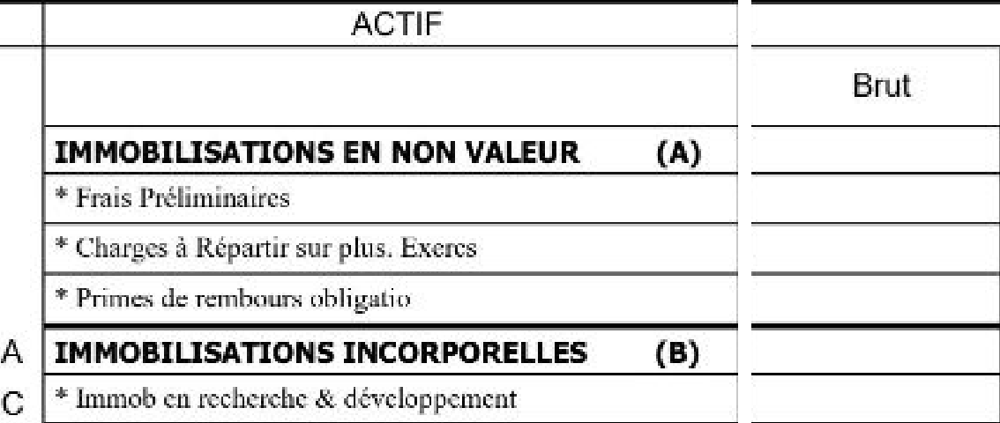


===== DERNIER BLOC — BRUT N =====


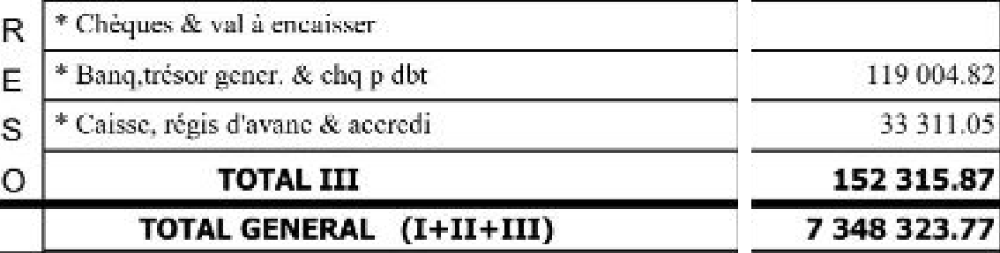


Préparation terminée.
Aucun CSV final créé.


In [86]:

# ============================================================
# PREPARER LES BLOCS ACTIF SANS CHEVAUCHEMENT
# POUR LES 4 COLONNES
# ============================================================

from PIL import Image
from pathlib import Path
from IPython.display import display

# 1. Vérifier les données existantes
assert len(limites_y) > 2
assert len(images_colonnes_actif) == 4

# 2. Créer le dossier
dossier = Path("/kaggle/working/blocs_actif_final")
dossier.mkdir(parents=True, exist_ok=True)

# 3. Nombre de lignes de grille par bloc
LIGNES_PAR_BLOC = 8

colonnes = [
    "brut_N",
    "amortissements_provisions_N",
    "net_N",
    "net_N1"
]

# 4. Charger les quatre images
images = {
    nom: Image.open(
        images_colonnes_actif[nom]
    ).convert("RGB")
    for nom in colonnes
}

# Vérifier que toutes les images ont la même hauteur
hauteurs = [img.height for img in images.values()]

assert len(set(hauteurs)) == 1, (
    "Les hauteurs des images sont différentes."
)

hauteur = hauteurs[0]

# 5. Préparer les blocs
blocs_actif_finaux = []

nombre_intervalles = len(limites_y) - 1

for debut in range(0, nombre_intervalles, LIGNES_PAR_BLOC):

    fin = min(
        debut + LIGNES_PAR_BLOC,
        nombre_intervalles
    )

    # Début et fin sur les lignes de séparation
    y1 = int(limites_y[debut])
    y2 = int(limites_y[fin])

    numero_bloc = len(blocs_actif_finaux) + 1

    infos_bloc = {
        "numero_bloc": numero_bloc,
        "ligne_debut": debut,
        "ligne_fin": fin - 1,
        "y1": y1,
        "y2": y2,
        "images": {}
    }

    # Appliquer les mêmes limites aux quatre colonnes
    for nom in colonnes:

        image = images[nom]

        bloc = image.crop((
            0,
            y1,
            image.width,
            y2
        ))

        chemin = dossier / (
            f"bloc_{numero_bloc:02d}_{nom}.png"
        )

        bloc.save(chemin)

        infos_bloc["images"][nom] = str(chemin)

    blocs_actif_finaux.append(infos_bloc)


# 6. Afficher le résumé
print("===== BLOCS ACTIF =====")
print("Nombre de blocs :", len(blocs_actif_finaux))

for bloc in blocs_actif_finaux:

    print(
        f"Bloc {bloc['numero_bloc']} : "
        f"intervalles {bloc['ligne_debut']} "
        f"à {bloc['ligne_fin']} "
        f"| Y = {bloc['y1']} -> {bloc['y2']}"
    )


# 7. Vérifier le premier et le dernier bloc
print("\n===== PREMIER BLOC — BRUT N =====")

display(
    Image.open(
        blocs_actif_finaux[0]["images"]["brut_N"]
    )
)

print("\n===== DERNIER BLOC — BRUT N =====")

display(
    Image.open(
        blocs_actif_finaux[-1]["images"]["brut_N"]
    )
)

print("\nPréparation terminée.")
print("Aucun CSV final créé.")


Bloc : 1
Image : /kaggle/working/blocs_actif_final/bloc_01_brut_N.png


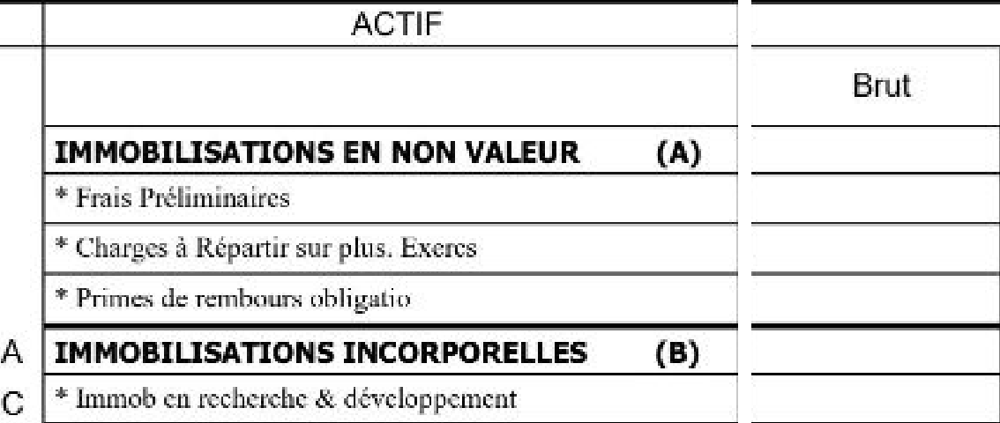


===== RESULTAT VLM =====
Statut : OK
Tokens : 129
Temps : 7.04 secondes

===== TABLEAU EXTRAIT =====


,poste,brut_N
0,* Frais Préliminaires,None
1,* Charges à Répartir sur plus. Exercs,None
2,* Primes de rembours obligatio,None
3,* Immob en recherche & développement,None


Nombre de lignes : 4
Montants extraits : 0

Aucun CSV final créé.


In [87]:

# ============================================================
# EXTRACTION VLM — PREMIER BLOC ACTIF BRUT N
# ============================================================

import pandas as pd
from pathlib import Path
from PIL import Image
from IPython.display import display

# 1. Sélectionner le premier bloc
bloc = blocs_actif_finaux[0]

image_path = bloc["images"]["brut_N"]

print("Bloc :", bloc["numero_bloc"])
print("Image :", image_path)

# 2. Afficher l'image à analyser
display(Image.open(image_path))


# 3. Construire les messages pour Qwen
messages_bloc = [
    {
        "role": "system",
        "content": (
            "Tu es spécialisé dans la transcription "
            "de tableaux comptables marocains. "
            "Tu extrais fidèlement les lignes et "
            "les montants visibles, sans invention."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": Path(image_path).resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Cette image contient une partie du bilan ACTIF.

Colonne gauche : noms des postes comptables.
Colonne droite : montants BRUT N.

INSTRUCTIONS :

1. Extrais les lignes comptables entièrement visibles.
2. Respecte exactement leur ordre.
3. Ignore les titres de colonnes ACTIF et Brut.
4. Chaque ligne doit contenir "poste" et "valeur".
5. Si une cellule est vide, utilise null.
6. Ne déduis pas une valeur à partir d'une autre ligne.
7. Ne calcule aucun montant.
8. Ne complète pas les lignes coupées.
9. Ne crée aucun poste absent de l'image.
10. Retourne uniquement un JSON valide.

FORMAT :

{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom du poste",
      "valeur": null
    }
  ]
}
"""
            }
        ]
    }
]


# 4. Exécuter Qwen2.5-VL
resultat_bloc = extraire_avec_vlm(
    messages_bloc,
    max_tokens=1200
)

print("\n===== RESULTAT VLM =====")
print("Statut :", resultat_bloc["statut"])
print("Tokens :", resultat_bloc["nombre_tokens"])
print("Temps :", resultat_bloc["temps_secondes"], "secondes")


# 5. Vérifier le JSON
if resultat_bloc["statut"] == "OK":

    lignes = resultat_bloc["donnees"]["lignes"]

    lignes_valides = all(
        isinstance(ligne, dict)
        and "poste" in ligne
        and "valeur" in ligne
        for ligne in lignes
    )

    if lignes_valides and len(lignes) > 0:

        df_bloc_test = pd.DataFrame(lignes)

        df_bloc_test = df_bloc_test[
            ["poste", "valeur"]
        ].rename(
            columns={"valeur": "brut_N"}
        )

        print("\n===== TABLEAU EXTRAIT =====")
        display(df_bloc_test)

        print("Nombre de lignes :", len(df_bloc_test))
        print(
            "Montants extraits :",
            df_bloc_test["brut_N"].notna().sum()
        )

    else:
        print("ERREUR : schéma ou lignes invalides.")
        print(resultat_bloc["texte_brut"][:1500])

else:
    print("Extraction échouée.")
    print(resultat_bloc["texte_brut"][-1000:])

print("\nAucun CSV final créé.")


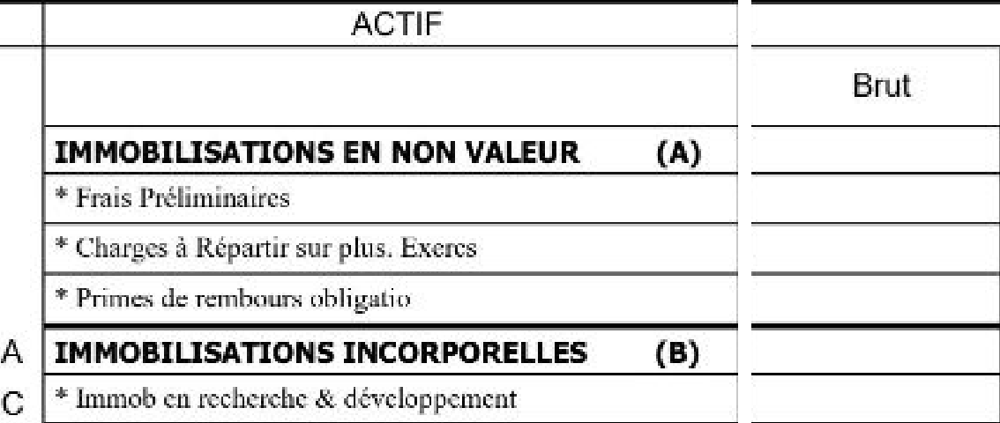

Statut : OK

===== EXTRACTION CORRIGEE =====


,poste,type_ligne,brut_N
0,* Frais Préliminaires,rubrique,None
1,* Charges à Répartir sur plus. Exercs,rubrique,None
2,* Primes de rembours obligatoire,rubrique,None
3,IMMOBILISATIONS INCORPORELLES (B),total,None
4,* Immob en recherche & développement,detail,None


Nombre de lignes : 5
Rubrique A présente : False
Rubrique B présente : True
Structure incomplète : vérification nécessaire.

Aucun CSV final créé.


In [88]:

# ============================================================
# TEST CORRIGE — EXTRACTION COMPLETE DU PREMIER BLOC
# ============================================================

import pandas as pd
from pathlib import Path
from PIL import Image
from IPython.display import display

# 1. Récupérer le premier bloc ACTIF BRUT
bloc = blocs_actif_finaux[0]
image_path = bloc["images"]["brut_N"]

display(Image.open(image_path))

# 2. Construire un prompt plus précis
messages_bloc = [
    {
        "role": "system",
        "content": (
            "Tu es un système de transcription fidèle "
            "de tableaux financiers. "
            "Tu dois conserver toutes les lignes, "
            "y compris les titres de rubriques."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": Path(image_path).resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Analyse ce bloc du bilan ACTIF.

L'image contient :
- A gauche : les noms des postes.
- A droite : les montants BRUT N.

EXTRACTION :
1. Lis toutes les lignes comptables de haut en bas.
2. Inclus obligatoirement les rubriques en gras.
3. Inclus les postes détaillés précédés de *.
4. Inclus les lignes de totaux lorsqu'elles existent.
5. Ne supprime aucune ligne sous prétexte
   que son montant est vide.
6. Ignore seulement les en-têtes ACTIF et Brut.
7. Respecte exactement l'ordre vertical.
8. Ne crée pas de lignes absentes de l'image.

CLASSIFICATION :
- rubrique : intitulé de catégorie en gras
- detail : poste comptable détaillé
- total : sous-total ou total général

MONTANTS :
- Lis uniquement la colonne BRUT N.
- Si la cellule est vide ou illisible : null.
- Ne calcule aucun montant.
- N'invente aucune valeur.

Chaque ligne doit contenir exactement :
poste, type_ligne et valeur.

FORMAT JSON :
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "poste": "nom de la ligne",
      "type_ligne": "rubrique",
      "valeur": null
    }
  ]
}

Retourne uniquement le JSON.
"""
            }
        ]
    }
]

# 3. Exécuter Qwen2.5-VL
resultat_bloc_corrige = extraire_avec_vlm(
    messages_bloc,
    max_tokens=1200
)

print("Statut :", resultat_bloc_corrige["statut"])

# 4. Vérifier l'extraction
if resultat_bloc_corrige["statut"] == "OK":

    lignes = resultat_bloc_corrige["donnees"]["lignes"]

    champs = {"poste", "type_ligne", "valeur"}

    if not lignes or any(
        not isinstance(ligne, dict)
        or not champs.issubset(ligne)
        for ligne in lignes
    ):
        raise ValueError("Schéma JSON incomplet.")

    df_bloc_corrige = pd.DataFrame(lignes)

    df_bloc_corrige = df_bloc_corrige[
        ["poste", "type_ligne", "valeur"]
    ].rename(columns={"valeur": "brut_N"})

    print("\n===== EXTRACTION CORRIGEE =====")
    display(df_bloc_corrige)

    print("Nombre de lignes :", len(df_bloc_corrige))

    # Contrôle spécifique au premier bloc
    noms = (
        df_bloc_corrige["poste"]
        .str.upper()
        .str.replace("É", "E", regex=False)
    )

    rubrique_A = noms.str.contains(
        "IMMOBILISATIONS EN NON VALEUR", regex=False
    ).any()

    rubrique_B = noms.str.contains(
        "IMMOBILISATIONS INCORPORELLES", regex=False
    ).any()

    print("Rubrique A présente :", rubrique_A)
    print("Rubrique B présente :", rubrique_B)

    if rubrique_A and rubrique_B and len(df_bloc_corrige) == 6:
        print("Structure attendue du premier bloc retrouvée.")
    else:
        print("Structure incomplète : vérification nécessaire.")

else:
    print(resultat_bloc_corrige["texte_brut"][-1000:])

print("\nAucun CSV final créé.")


===== IMAGE NUMEROTEE =====


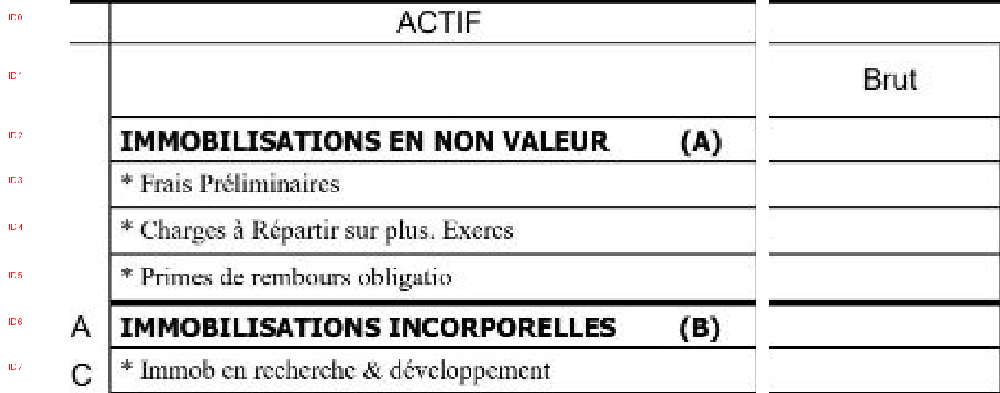

IDs attendus : [0, 1, 2, 3, 4, 5, 6, 7]

STATUT : OK
IDs attendus : [0, 1, 2, 3, 4, 5, 6, 7]
IDs obtenus  : [0, 1, 2, 3, 4, 5]
ECHEC : lignes manquantes, répétées ou déplacées.
Extraction non validée.

Aucun CSV final créé.


In [89]:

# ============================================================
# EXTRACTION ACTIF — LIGNES NUMEROTEES AVEC OPENCV + VLM
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display
import pandas as pd

# 1. Récupérer le premier bloc
bloc = blocs_actif_finaux[0]

image_path = bloc["images"]["brut_N"]
image = Image.open(image_path).convert("RGB")

# Limites horizontales détectées précédemment par OpenCV
debut = bloc["ligne_debut"]
fin = bloc["ligne_fin"]

ids_attendus = list(range(debut, fin + 1))

# 2. Ajouter une marge pour les numéros
marge = 85

image_annotee = Image.new(
    "RGB",
    (image.width + marge, image.height),
    "white"
)

image_annotee.paste(image, (marge, 0))

dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 19
    )
except OSError:
    police = ImageFont.load_default()

# 3. Numéroter chaque ligne détectée
for row_id in ids_attendus:

    y1 = int(limites_y[row_id] - bloc["y1"])
    y2 = int(limites_y[row_id + 1] - bloc["y1"])

    y_centre = (y1 + y2) // 2

    dessin.text(
        (10, max(0, y_centre - 10)),
        f"ID {row_id}",
        fill="red",
        font=police
    )

# 4. Enregistrer et afficher
chemin_annote = Path(
    "/kaggle/working/bloc_actif_numerote.png"
)

image_annotee.save(chemin_annote)

print("===== IMAGE NUMEROTEE =====")
display(image_annotee)

print("IDs attendus :", ids_attendus)


# 5. Construire le prompt
messages_numerotes = [
    {
        "role": "system",
        "content": (
            "Tu es un système de transcription de tableaux. "
            "Chaque ligne possède un identifiant ID. "
            "Tu dois retourner exactement une entrée par ID."
        )
    },
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin_annote.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Cette image contient un tableau comptable.

Chaque ligne horizontale possède un ID rouge.

IDs attendus :
{ids_attendus}

COLONNES :
- A gauche : nom du poste.
- A droite : montant BRUT N.

INSTRUCTIONS :
1. Retourne exactement une entrée par ID.
2. Respecte l'ordre des IDs.
3. Ne saute aucune ligne.
4. Ne crée aucun ID supplémentaire.
5. Si la ligne correspond à un en-tête,
   conserve son ID et son texte.
6. Lis chaque montant dans la colonne de droite.
7. Si la cellule est vide, utilise null.
8. Ne calcule aucun montant.
9. N'invente aucune donnée.

FORMAT JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte visible",
      "valeur": null
    }}
  ]
}}

L'ID 0 est illustratif : utilise les IDs
réellement affichés sur l'image.

Chaque ligne doit contenir obligatoirement :
id_ligne, poste et valeur.

Retourne uniquement le JSON.
"""
            }
        ]
    }
]


# 6. Exécuter Qwen
resultat_numerote = extraire_avec_vlm(
    messages_numerotes,
    max_tokens=1800
)

print("\nSTATUT :", resultat_numerote["statut"])

# 7. Vérifier tous les IDs
if resultat_numerote["statut"] == "OK":

    lignes = resultat_numerote["donnees"]["lignes"]

    champs = {"id_ligne", "poste", "valeur"}

    if not all(
        isinstance(l, dict) and champs.issubset(l)
        for l in lignes
    ):
        raise ValueError("Schéma JSON incomplet.")

    ids_obtenus = [l["id_ligne"] for l in lignes]

    ids_valides = (
        all(
            isinstance(i, int) and not isinstance(i, bool)
            for i in ids_obtenus
        )
        and ids_obtenus == ids_attendus
    )

    print("IDs attendus :", ids_attendus)
    print("IDs obtenus  :", ids_obtenus)

    if not ids_valides:
        print("ECHEC : lignes manquantes, répétées ou déplacées.")
        print("Extraction non validée.")

    else:
        df_numerote = pd.DataFrame(lignes)

        # Identifier les en-têtes et classifier les postes
        def classifier(poste):
            texte = str(poste).strip()
            maj = texte.upper()

            if maj in ("ACTIF", "BRUT", "EXERCICE"):
                return "en_tete"

            if "TOTAL" in maj:
                return "total"

            if texte.startswith("*"):
                return "detail"

            return "rubrique"

        df_numerote["type_ligne"] = (
            df_numerote["poste"].apply(classifier)
        )

        # Exclure seulement les en-têtes du tableau final
        df_bloc_numerote = df_numerote[
            df_numerote["type_ligne"] != "en_tete"
        ].copy()

        df_bloc_numerote.rename(
            columns={"valeur": "brut_N"},
            inplace=True
        )

        print("\n===== EXTRACTION PAR LIGNE =====")
        display(df_bloc_numerote)

        print(
            "Nombre de lignes comptables :",
            len(df_bloc_numerote)
        )

else:
    print("JSON non valide ou génération tronquée.")
    print(resultat_numerote["texte_brut"][-1000:])

print("\nAucun CSV final créé.")


In [90]:

# ============================================================
# EXTRACTION AUTOMATIQUE DE TOUS LES BLOCS ACTIF — BRUT N
# ============================================================

import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

dossier = Path("/kaggle/working/blocs_numerotes")
dossier.mkdir(parents=True, exist_ok=True)

try:
    police = ImageFont.truetype("DejaVuSans-Bold.ttf", 18)
except OSError:
    police = ImageFont.load_default()


# 1. Fonction pour ajouter les IDs aux lignes
def numeroter_bloc(bloc, colonne):

    image = Image.open(
        bloc["images"][colonne]
    ).convert("RGB")

    marge = 90

    image_finale = Image.new(
        "RGB",
        (image.width + marge, image.height),
        "white"
    )

    image_finale.paste(image, (marge, 0))
    dessin = ImageDraw.Draw(image_finale)

    ids = list(range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ))

    for identifiant in ids:

        y1 = limites_y[identifiant] - bloc["y1"]
        y2 = limites_y[identifiant + 1] - bloc["y1"]

        centre = (y1 + y2) // 2

        dessin.text(
            (5, max(0, centre - 10)),
            f"ID {identifiant}",
            fill="red",
            font=police
        )

    chemin = dossier / (
        f"bloc_{bloc['numero_bloc']:02d}_{colonne}.png"
    )

    image_finale.save(chemin)

    return chemin, ids


# 2. Fonction d'extraction d'un bloc
def extraire_bloc_brut(bloc):

    chemin, ids_attendus = numeroter_bloc(
        bloc, "brut_N"
    )

    messages = [
        {
            "role": "system",
            "content": (
                "Tu transcris des tableaux comptables. "
                "Chaque ID rouge correspond à un intervalle "
                "de ligne. Retourne une entrée par ID, "
                "sans inventer de données."
            )
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": chemin.resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Lis le tableau visible dans cette image.

Colonne gauche : poste comptable.
Colonne droite : montant BRUT N.

IDs attendus :
{ids_attendus}

RÈGLES :
1. Une entrée JSON pour chaque ID.
2. Respecte exactement l'ordre des IDs.
3. Conserve les rubriques, détails et totaux.
4. Conserve les lignes sans montant.
5. Ignore les textes décoratifs.
6. Si un intervalle est un en-tête,
   indique son texte dans poste.
7. Si aucun poste n'est présent,
   utilise une chaîne vide.
8. Si le montant est vide ou illisible : null.
9. Ne calcule aucun montant.
10. N'invente aucune valeur.

FORMAT :
{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte visible",
      "valeur": null
    }}
  ]
}}

L'ID 0 est seulement un exemple.
Utilise les vrais IDs de l'image.

Retourne uniquement le JSON.
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1600
    )

    # Vérifier le résultat
    if resultat["statut"] != "OK":
        raise ValueError(
            f"JSON invalide ou tronqué : {resultat['statut']}"
        )

    lignes = resultat["donnees"]["lignes"]

    champs = {"id_ligne", "poste", "valeur"}

    if not all(
        isinstance(ligne, dict)
        and champs.issubset(ligne)
        for ligne in lignes
    ):
        raise ValueError("Schéma incomplet")

    ids_obtenus = [
        ligne["id_ligne"] for ligne in lignes
    ]

    if (
        any(
            type(i) is not int
            for i in ids_obtenus
        )
        or ids_obtenus != ids_attendus
    ):
        raise ValueError(
            f"IDs incorrects : {ids_obtenus} "
            f"au lieu de {ids_attendus}"
        )

    return lignes


# 3. Extraire tous les blocs
resultats_brut = []
erreurs_brut = []

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    print(f"\n===== BLOC {numero} =====")

    try:
        lignes = extraire_bloc_brut(bloc)

        resultats_brut.extend(lignes)

        print("Statut : OK")
        print("Lignes extraites :", len(lignes))

    except Exception as e:

        erreurs_brut.append({
            "bloc": numero,
            "erreur": str(e)
        })

        print("Statut : A_VERIFIER")
        print("Erreur :", e)


# 4. Reconstruire le tableau
print("\n===== RECONSTRUCTION BRUT N =====")

df_brut_complet = None

if erreurs_brut:

    print("Extraction non validée.")
    print("Blocs problématiques :")
    display(pd.DataFrame(erreurs_brut))

else:

    df_brut_complet = pd.DataFrame(
        resultats_brut
    ).sort_values("id_ligne").reset_index(drop=True)

    # Exclure uniquement les en-têtes évidents
    en_tetes = {"ACTIF", "BRUT", "EXERCICE", ""}

    df_brut_complet = df_brut_complet[
        ~df_brut_complet["poste"]
        .astype(str)
        .str.strip()
        .str.upper()
        .isin(en_tetes)
    ].copy()

    df_brut_complet.rename(
        columns={"valeur": "brut_N"},
        inplace=True
    )

    print("Nombre de lignes :", len(df_brut_complet))

    display(df_brut_complet)

    print(
        "Montants renseignés :",
        df_brut_complet["brut_N"].notna().sum()
    )

print("\nAucun CSV final créé.")



===== BLOC 1 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== BLOC 2 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== BLOC 3 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== BLOC 4 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== BLOC 5 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== BLOC 6 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== BLOC 7 =====
Statut : A_VERIFIER
Erreur : JSON invalide ou tronqué : JSON_INVALIDE

===== RECONSTRUCTION BRUT N =====
Extraction non validée.
Blocs problématiques :


,bloc,erreur
0,1,JSON invalide ou tronqué : JSON_INVALIDE
1,2,JSON invalide ou tronqué : JSON_INVALIDE
2,3,JSON invalide ou tronqué : JSON_INVALIDE
3,4,JSON invalide ou tronqué : JSON_INVALIDE
4,5,JSON invalide ou tronqué : JSON_INVALIDE
5,6,JSON invalide ou tronqué : JSON_INVALIDE
6,7,JSON invalide ou tronqué : JSON_INVALIDE



Aucun CSV final créé.


In [91]:

# ============================================================
# DIAGNOSTIC JSON — PREMIER BLOC ACTIF BRUT N
# ============================================================

import json

# 1. Sélectionner uniquement le premier bloc
bloc = blocs_actif_finaux[0]

# 2. Récupérer l'image numérotée
chemin, ids_attendus = numeroter_bloc(
    bloc,
    "brut_N"
)

print("Image :", chemin)
print("IDs attendus :", ids_attendus)

# 3. Construire le prompt
messages_diagnostic = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris ce tableau comptable.

Chaque ID rouge représente une ligne du tableau.

IDs attendus : {ids_attendus}

Pour chaque ID, lis :
- id_ligne : numéro rouge
- poste : texte visible sur cette ligne
- valeur : montant BRUT N ou null

Retourne exactement une entrée par ID.
Si la ligne est un en-tête, conserve son texte.
Si aucune désignation n'est visible, utilise "".
Ne calcule aucun montant.
N'invente aucune valeur.

Format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}

Retourne uniquement du JSON valide.
"""
            }
        ]
    }
]

# 4. Exécuter Qwen
diagnostic = extraire_avec_vlm(
    messages_diagnostic,
    max_tokens=1800
)

# 5. Afficher le diagnostic complet
print("\n===== DIAGNOSTIC =====")
print("Statut :", diagnostic["statut"])
print("Tokens :", diagnostic["nombre_tokens"])
print("Limite atteinte :", diagnostic["tronque"])
print("Erreur :", diagnostic["erreur"])

print("\n===== REPONSE BRUTE DE QWEN =====")
print(diagnostic["texte_brut"])

# 6. Afficher les données si le JSON est valide
if diagnostic["donnees"] is not None:

    import pandas as pd

    lignes = diagnostic["donnees"]["lignes"]
    display(pd.DataFrame(lignes))

    ids_obtenus = [
        ligne.get("id_ligne")
        for ligne in lignes
    ]

    print("\nIDs attendus :", ids_attendus)
    print("IDs obtenus  :", ids_obtenus)

    if ids_obtenus == ids_attendus:
        print("Structure des IDs : OK")
    else:
        print("Structure des IDs : A VERIFIER")

Image : /kaggle/working/blocs_numerotes/bloc_01_brut_N.png
IDs attendus : [0, 1, 2, 3, 4, 5, 6, 7]

===== DIAGNOSTIC =====
Statut : OK
Tokens : 297
Limite atteinte : False
Erreur : None

===== REPONSE BRUTE DE QWEN =====
```json
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "id_ligne": 0,
      "poste": "",
      "valeur": null
    },
    {
      "id_ligne": 1,
      "poste": "IMMOBILISATIONS EN NON VALEUR (A)",
      "valeur": null
    },
    {
      "id_ligne": 2,
      "poste": "* Frais Préliminaires",
      "valeur": null
    },
    {
      "id_ligne": 3,
      "poste": "* Charges à Répartir sur plus. Exercs",
      "valeur": null
    },
    {
      "id_ligne": 4,
      "poste": "* Primes de rembours obligatio",
      "valeur": null
    },
    {
      "id_ligne": 5,
      "poste": "IMMOBILISATIONS INCORPORELLES (B)",
      "valeur": null
    },
    {
      "id_ligne": 6,
      "poste": "",
      "valeur": null
    },
    {
      "id_ligne": 7,
      "poste": "* Immob en rech

,id_ligne,poste,valeur
0,0,,None
1,1,IMMOBILISATIONS EN NON VALEUR (A),None
2,2,* Frais Préliminaires,None
3,3,* Charges à Répartir sur plus. Exercs,None
4,4,* Primes de rembours obligatio,None
5,5,IMMOBILISATIONS INCORPORELLES (B),None
6,6,,None
7,7,* Immob en recherche & développement,None



IDs attendus : [0, 1, 2, 3, 4, 5, 6, 7]
IDs obtenus  : [0, 1, 2, 3, 4, 5, 6, 7]
Structure des IDs : OK


===== IMAGE DU BLOC 2 =====


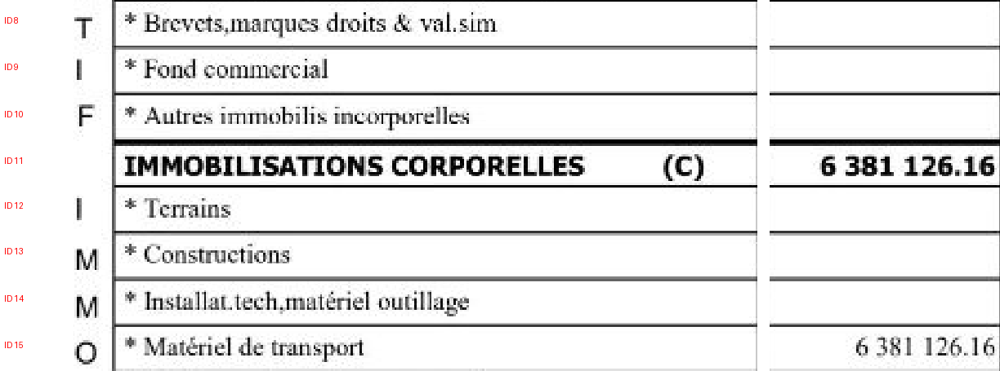

IDs attendus : [8, 9, 10, 11, 12, 13, 14, 15]

===== RESULTAT =====
Statut : OK
Tokens : 317

===== DONNEES EXTRAITES =====


,id_ligne,poste,valeur
0,8,"* Brevets, marques droits & val.sim",NaN
1,9,* Fond commercial,NaN
2,10,* Autres immobilis incorporelles,NaN
3,11,IMMOBILISATIONS CORPORELLES (C),6381126.16
4,12,* Terrains,NaN
5,13,* Constructions,NaN
6,14,"* Installat.tech, matériel outillage",NaN
7,15,* Matériel de transport,6381126.16


IDs attendus : [8, 9, 10, 11, 12, 13, 14, 15]
IDs obtenus  : [8, 9, 10, 11, 12, 13, 14, 15]
VALIDATION DES IDs : OK

Positions sans poste reconnu :


,id_ligne,poste,valeur



Aucun CSV final créé.


In [92]:
# ============================================================
# TEST DU DEUXIEME BLOC ACTIF — BRUT N
# ============================================================

import pandas as pd
from IPython.display import display
from PIL import Image

# 1. Sélectionner le deuxième bloc
bloc = blocs_actif_finaux[1]

# 2. Numéroter les lignes
chemin, ids_attendus = numeroter_bloc(
    bloc,
    "brut_N"
)

print("===== IMAGE DU BLOC 2 =====")
display(Image.open(chemin))

print("IDs attendus :", ids_attendus)

# 3. Utiliser le prompt qui a fonctionné
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris ce tableau comptable.

Chaque ID rouge représente une ligne du tableau.

IDs attendus : {ids_attendus}

Pour chaque ID, lis :
- id_ligne : numéro rouge
- poste : texte visible sur cette ligne
- valeur : montant BRUT N ou null

Retourne exactement une entrée par ID.
Si la ligne est un en-tête, conserve son texte.
Si aucune désignation n'est visible, utilise "".
Ne calcule aucun montant.
N'invente aucune valeur.

Format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}

Retourne uniquement du JSON valide.
"""
            }
        ]
    }
]

# 4. Exécuter Qwen2.5-VL
resultat_bloc_2 = extraire_avec_vlm(
    messages,
    max_tokens=1800
)

print("\n===== RESULTAT =====")
print("Statut :", resultat_bloc_2["statut"])
print("Tokens :", resultat_bloc_2["nombre_tokens"])

# 5. Vérifier le résultat
if resultat_bloc_2["statut"] == "OK":

    df_bloc_2 = pd.DataFrame(
        resultat_bloc_2["donnees"]["lignes"]
    )

    print("\n===== DONNEES EXTRAITES =====")
    display(df_bloc_2)

    champs = {"id_ligne", "poste", "valeur"}

    if not champs.issubset(df_bloc_2.columns):
        print("ERREUR : champs manquants")

    else:
        ids_obtenus = df_bloc_2["id_ligne"].tolist()

        print("IDs attendus :", ids_attendus)
        print("IDs obtenus  :", ids_obtenus)

        if ids_obtenus == ids_attendus:
            print("VALIDATION DES IDs : OK")
        else:
            print("VALIDATION DES IDs : ECHEC")

        postes_vides = df_bloc_2[
            df_bloc_2["poste"].fillna("").str.strip() == ""
        ]

        print("\nPositions sans poste reconnu :")
        display(postes_vides)

else:
    print("\nJSON invalide :")
    print(resultat_bloc_2["erreur"])
    print(resultat_bloc_2["texte_brut"])

print("\nAucun CSV final créé.")

In [93]:

# ============================================================
# EXTRACTION COMPLETE ACTIF — BRUT N AVEC IDs
# ============================================================

import pandas as pd
import math
from pathlib import Path

# 1. Réutiliser les extractions déjà réussies
resultats_brut_par_bloc = {
    1: diagnostic,
    2: resultat_bloc_2
}

erreurs_brut = []


# 2. Fonction de validation de chaque bloc
def verifier_resultat_bloc(resultat, ids_attendus):

    if resultat["statut"] != "OK":
        return False, resultat["statut"]

    donnees = resultat["donnees"]

    if donnees is None or donnees.get("type_bilan") != "ACTIF":
        return False, "Type de bilan incorrect"

    lignes = donnees.get("lignes", [])

    if not isinstance(lignes, list):
        return False, "Liste de lignes invalide"

    for ligne in lignes:

        if not isinstance(ligne, dict):
            return False, "Ligne non structurée"

        if not {"id_ligne", "poste", "valeur"}.issubset(ligne):
            return False, "Champs manquants"

        if not isinstance(ligne["poste"], str):
            return False, "Poste invalide"

        valeur = ligne["valeur"]

        if valeur is not None and (
            type(valeur) not in (int, float)
            or not math.isfinite(valeur)
        ):
            return False, "Montant invalide"

    ids_obtenus = [ligne["id_ligne"] for ligne in lignes]

    if ids_obtenus != ids_attendus:
        return False, "IDs manquants ou mal ordonnés"

    return True, "OK"


# 3. Extraire les blocs restants
for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    if numero in resultats_brut_par_bloc:
        print(f"Bloc {numero} : résultat existant réutilisé")
        continue

    print(f"\n===== EXTRACTION BLOC {numero} =====")

    chemin, ids_attendus = numeroter_bloc(
        bloc,
        "brut_N"
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin).resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris ce tableau comptable.

Chaque ID rouge représente une ligne du tableau.

IDs attendus : {ids_attendus}

Pour chaque ID, lis :
- id_ligne : numéro rouge
- poste : texte visible sur cette ligne
- valeur : montant BRUT N ou null

Retourne exactement une entrée par ID.
Si la ligne est un en-tête, conserve son texte.
Si aucune désignation n'est visible, utilise "".
Ne calcule aucun montant.
N'invente aucune valeur.

Format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}

Retourne uniquement du JSON valide.
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1800
    )

    resultats_brut_par_bloc[numero] = resultat

    valide, raison = verifier_resultat_bloc(
        resultat,
        ids_attendus
    )

    print("Statut :", resultat["statut"])
    print("Contrôle :", raison)
    print("Tokens :", resultat["nombre_tokens"])

    if not valide:
        print("Réponse brute :")
        print(resultat["texte_brut"][-1000:])


# 4. Vérifier tous les blocs et reconstruire BRUT N
lignes_brut = []

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]
    resultat = resultats_brut_par_bloc[numero]

    ids_attendus = list(range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ))

    valide, raison = verifier_resultat_bloc(
        resultat,
        ids_attendus
    )

    if not valide:
        erreurs_brut.append({
            "bloc": numero,
            "erreur": raison
        })
        continue

    lignes_brut.extend(resultat["donnees"]["lignes"])


# 5. Afficher les résultats
if erreurs_brut:

    print("\n===== BLOCS NON VALIDES =====")
    display(pd.DataFrame(erreurs_brut))

    df_brut_ids = None

else:

    df_brut_ids = pd.DataFrame(lignes_brut)

    df_brut_ids = df_brut_ids.sort_values(
        "id_ligne"
    ).reset_index(drop=True)

    df_brut_ids.rename(
        columns={"valeur": "brut_N"},
        inplace=True
    )

    print("\n===== ACTIF BRUT N RECONSTRUIT =====")
    display(df_brut_ids)

    print("\n===== STATISTIQUES =====")
    print("Lignes :", len(df_brut_ids))

    print(
        "Montants renseignés :",
        df_brut_ids["brut_N"].notna().sum()
    )

    print(
        "Postes vides :",
        (df_brut_ids["poste"].str.strip() == "").sum()
    )

    print("\n===== LIGNES SANS POSTE =====")
    display(
        df_brut_ids[
            df_brut_ids["poste"].str.strip() == ""
        ]
    )

print("\nAucun CSV final créé.")


Bloc 1 : résultat existant réutilisé
Bloc 2 : résultat existant réutilisé

===== EXTRACTION BLOC 3 =====
Statut : OK
Contrôle : OK
Tokens : 314

===== EXTRACTION BLOC 4 =====
Statut : OK
Contrôle : OK
Tokens : 316

===== EXTRACTION BLOC 5 =====
Statut : OK
Contrôle : OK
Tokens : 338

===== EXTRACTION BLOC 6 =====
Statut : OK
Contrôle : OK
Tokens : 344

===== EXTRACTION BLOC 7 =====
Statut : OK
Contrôle : OK
Tokens : 245

===== ACTIF BRUT N RECONSTRUIT =====


,id_ligne,poste,brut_N
0,0,,NaN
1,1,IMMOBILISATIONS EN NON VALEUR (A),NaN
2,2,* Frais Préliminaires,NaN
3,3,* Charges à Répartir sur plus. Exercs,NaN
4,4,* Primes de rembours obligatio,NaN
5,5,IMMOBILISATIONS INCORPORELLES (B),NaN
6,6,,NaN
7,7,* Immob en recherche & développement,NaN
8,8,"* Brevets, marques droits & val.sim",NaN
9,9,* Fond commercial,NaN



===== STATISTIQUES =====
Lignes : 53
Montants renseignés : 12
Postes vides : 2

===== LIGNES SANS POSTE =====


,id_ligne,poste,brut_N
0,0,,NaN
6,6,,NaN



Aucun CSV final créé.


In [94]:

# ============================================================
# EXTRACTION ACTIF — AMORTISSEMENTS ET PROVISIONS N
# ============================================================

import pandas as pd
from pathlib import Path

resultats_amort = {}
erreurs_amort = []

# 1. Extraire les sept blocs
for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    chemin, ids_attendus = numeroter_bloc(
        bloc,
        "amortissements_provisions_N"
    )

    print(f"\n===== AMORTISSEMENTS — BLOC {numero} =====")

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin).resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Cette image contient deux colonnes :
- A gauche : les noms des postes comptables.
- A droite : AMORTISSEMENTS ET PROVISIONS N.

Chaque ID rouge correspond à une ligne physique.

IDs attendus : {ids_attendus}

Pour chaque ID, lis uniquement le montant
situé dans la colonne de droite.

REGLES :
1. Retourne exactement une entrée par ID.
2. Respecte l'ordre des IDs.
3. Une cellule vide ou hachurée vaut null.
4. Ne calcule aucun montant.
5. Ne copie pas les valeurs des autres lignes.
6. N'invente aucun chiffre.
7. Chaque entrée possède id_ligne et valeur.

FORMAT JSON :
{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "valeur": null
    }}
  ]
}}

L'ID 0 est illustratif.
Utilise les IDs réels affichés.

Retourne uniquement du JSON valide.
"""
                }
            ]
        }
    ]

    # 2. Exécuter Qwen2.5-VL
    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1200
    )

    resultats_amort[numero] = resultat

    # 3. Vérifier le résultat
    if resultat["statut"] != "OK":
        erreurs_amort.append(
            (numero, resultat["statut"])
        )
        print("ECHEC :", resultat["statut"])
        print(resultat["texte_brut"][-500:])
        continue

    lignes = resultat["donnees"]["lignes"]

    if not all(
        isinstance(l, dict)
        and "id_ligne" in l
        and "valeur" in l
        for l in lignes
    ):
        erreurs_amort.append(
            (numero, "CHAMPS_MANQUANTS")
        )
        print("ECHEC : champs manquants")
        continue

    ids_obtenus = [l["id_ligne"] for l in lignes]

    if ids_obtenus != ids_attendus:
        erreurs_amort.append(
            (numero, "IDS_INCORRECTS")
        )
        print("ECHEC : IDs incorrects")
        continue

    # Refuser les valeurs numériques mal formées
    if any(
        l["valeur"] is not None
        and (
            type(l["valeur"]) not in (int, float)
            or not pd.notna(l["valeur"])
        )
        for l in lignes
    ):
        erreurs_amort.append(
            (numero, "MONTANT_INVALIDE")
        )
        print("ECHEC : montant invalide")
        continue

    print("STATUT : OK")
    print("Lignes :", len(lignes))


# 4. Reconstruire la colonne complète
df_amort_ids = None

if erreurs_amort:

    print("\n===== BLOCS A CORRIGER =====")
    display(pd.DataFrame(
        erreurs_amort,
        columns=["bloc", "erreur"]
    ))

else:

    toutes_lignes = []

    for numero in sorted(resultats_amort):
        toutes_lignes.extend(
            resultats_amort[numero]["donnees"]["lignes"]
        )

    df_amort_ids = pd.DataFrame(toutes_lignes)

    df_amort_ids = df_amort_ids.rename(
        columns={"valeur": "amortissements_provisions_N"}
    ).sort_values("id_ligne").reset_index(drop=True)

    # Associer les postes via leurs IDs
    df_amort_ids = df_brut_ids[
        ["id_ligne", "poste"]
    ].merge(
        df_amort_ids,
        on="id_ligne",
        how="left",
        validate="one_to_one"
    )

    print("\n===== AMORTISSEMENTS N =====")
    display(df_amort_ids)

    print("\nNombre de lignes :", len(df_amort_ids))
    print(
        "Montants renseignés :",
        df_amort_ids[
            "amortissements_provisions_N"
        ].notna().sum()
    )

    print("\n===== DERNIERES LIGNES =====")
    display(df_amort_ids.tail(8))

print("\nAucun CSV final créé.")



===== AMORTISSEMENTS — BLOC 1 =====
STATUT : OK
Lignes : 8

===== AMORTISSEMENTS — BLOC 2 =====
STATUT : OK
Lignes : 8

===== AMORTISSEMENTS — BLOC 3 =====
STATUT : OK
Lignes : 8

===== AMORTISSEMENTS — BLOC 4 =====
ECHEC : JSON_INVALIDE
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

===== AMORTISSEMENTS — BLOC 5 =====
STATUT : OK
Lignes : 8

===== AMORTISSEMENTS — BLOC 6 =====
ECHEC : JSON_INVALIDE
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

,bloc,erreur
0,4,JSON_INVALIDE
1,6,JSON_INVALIDE



Aucun CSV final créé.


In [95]:

# ============================================================
# CORRECTION — BLOCS 4 ET 6 DES AMORTISSEMENTS
# ============================================================

import pandas as pd
from pathlib import Path

# Blocs à réessayer
blocs_a_corriger = [4, 6]

for numero in blocs_a_corriger:

    print(f"\n{'=' * 50}")
    print(f"CORRECTION AMORTISSEMENTS — BLOC {numero}")
    print(f"{'=' * 50}")

    bloc = blocs_actif_finaux[numero - 1]

    # Récupérer l'image avec les IDs rouges
    chemin, ids_attendus = numeroter_bloc(
        bloc,
        "amortissements_provisions_N"
    )

    # Prompt simplifié
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin).resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris les lignes de ce tableau comptable.

Chaque ID rouge représente une ligne.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : AMORTISSEMENTS ET PROVISIONS N.

Pour chaque ID, retourne :
- id_ligne : le numéro rouge
- poste : le texte de la ligne
- valeur : le montant lu dans la colonne droite

Si aucun montant n'est visible, utilise null.
Si aucun poste n'est visible, utilise "".

Ne calcule rien.
N'invente aucune valeur.
Retourne exactement une entrée par ID.

Format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}

Réponds uniquement avec du JSON valide.
"""
                }
            ]
        }
    ]

    # Exécuter Qwen
    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1000
    )

    print("Statut :", resultat["statut"])
    print("Tokens :", resultat["nombre_tokens"])

    # Vérifier le JSON et les IDs
    valide = False

    if resultat["statut"] == "OK":

        lignes = resultat["donnees"]["lignes"]

        if (
            isinstance(lignes, list)
            and all(
                isinstance(l, dict)
                and {"id_ligne", "poste", "valeur"}.issubset(l)
                and isinstance(l["poste"], str)
                and (
                    l["valeur"] is None
                    or (
                        type(l["valeur"]) in (int, float)
                        and pd.notna(l["valeur"])
                    )
                )
                for l in lignes
            )
        ):

            ids_obtenus = [
                l["id_ligne"] for l in lignes
            ]

            valide = ids_obtenus == ids_attendus

    if valide:

        # Conserver les deux champs nécessaires
        lignes_amort = [
            {
                "id_ligne": l["id_ligne"],
                "valeur": l["valeur"]
            }
            for l in lignes
        ]

        # Remplacer uniquement le résultat échoué
        resultat["donnees"]["lignes"] = lignes_amort
        resultats_amort[numero] = resultat

        print("VALIDATION STRUCTURELLE : OK")
        display(pd.DataFrame(lignes))

    else:
        print("ECHEC : extraction non exploitable.")
        print("Début de la réponse :")
        print(resultat["texte_brut"][:300])


# ============================================================
# RECONSTRUCTION DES AMORTISSEMENTS
# ============================================================

print("\n===== VERIFICATION DES 7 BLOCS =====")

lignes_finales = []
blocs_invalides = []

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]
    resultat = resultats_amort.get(numero)

    ids_attendus = list(range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ))

    if (
        resultat is None
        or resultat["statut"] != "OK"
        or resultat["donnees"] is None
    ):
        blocs_invalides.append(numero)
        continue

    lignes = resultat["donnees"]["lignes"]

    if (
        not all(
            isinstance(l, dict)
            and "id_ligne" in l
            and "valeur" in l
            and (
                l["valeur"] is None
                or (
                    type(l["valeur"]) in (int, float)
                    and pd.notna(l["valeur"])
                )
            )
            for l in lignes
        )
        or [l["id_ligne"] for l in lignes] != ids_attendus
    ):
        blocs_invalides.append(numero)
        continue

    lignes_finales.extend([
        {
            "id_ligne": l["id_ligne"],
            "valeur": l["valeur"]
        }
        for l in lignes
    ])

if blocs_invalides:

    df_amort_ids = None

    print("Blocs encore invalides :", blocs_invalides)
    print("Reconstruction suspendue.")

else:

    df_amort_ids = pd.DataFrame(lignes_finales)

    df_amort_ids.rename(
        columns={
            "valeur": "amortissements_provisions_N"
        },
        inplace=True
    )

    df_amort_ids = df_brut_ids[
        ["id_ligne", "poste"]
    ].merge(
        df_amort_ids,
        on="id_ligne",
        how="left",
        validate="one_to_one"
    )

    if len(df_amort_ids) != len(df_brut_ids):
        raise ValueError("Nombre de lignes incohérent.")

    print("RECONSTRUCTION : OK")
    print("Nombre de lignes :", len(df_amort_ids))

    print(
        "Montants renseignés :",
        df_amort_ids[
            "amortissements_provisions_N"
        ].notna().sum()
    )

    display(
        df_amort_ids[
            df_amort_ids[
                "amortissements_provisions_N"
            ].notna()
        ]
    )

print("\nAucun CSV final créé.")



CORRECTION AMORTISSEMENTS — BLOC 4
Statut : JSON_INVALIDE
Tokens : 1000
ECHEC : extraction non exploitable.
Début de la réponse :
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

CORRECTION AMORTISSEMENTS — BLOC 6
Statut : JSON_INVALIDE
Tokens : 1000
ECHEC : extraction non exploitable.
Début de la réponse :
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

===== VERIFICATION DES 7 BLOCS =====
Blocs encore invalides : [4, 6]
Reconstruction suspendue.

Aucun CSV final créé.


===== IMAGE REDUITE =====


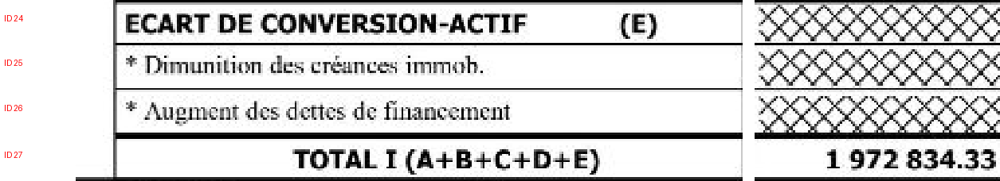

IDs attendus : [24, 25, 26, 27]

===== RESULTAT =====
Statut : JSON_INVALIDE
Tokens : 165
Réponse brute :
```json
[
  {
    "id_ligne": 24,
    "poste": "ECART DE CONVERSION-ACTIF (E)",
    "valeur": null
  },
  {
    "id_ligne": 25,
    "poste": "* Diminution des créances immobilières.",
    "valeur": null
  },
  {
    "id_ligne": 26,
    "poste": "* Augmentation des dettes de financement",
    "valeur": null
  },
  {
    "id_ligne": 27,
    "poste": "TOTAL I (A+B+C+D+E)",
    "valeur": 1972834.33
  }
]
```

Aucun CSV final créé.


In [96]:

# ============================================================
# TEST : BLOC 4 AMORTISSEMENTS — 4 PREMIERES LIGNES
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display
import pandas as pd
import math

# 1. Sélectionner le bloc 4
bloc = blocs_actif_finaux[3]

image = Image.open(
    bloc["images"]["amortissements_provisions_N"]
).convert("RGB")

# 2. Sélectionner uniquement les 4 premières lignes
debut_id = bloc["ligne_debut"]
fin_id = min(debut_id + 4, bloc["ligne_fin"] + 1)

ids_attendus = list(range(debut_id, fin_id))

y1 = int(limites_y[debut_id] - bloc["y1"])
y2 = int(limites_y[fin_id] - bloc["y1"])

petite_image = image.crop(
    (0, y1, image.width, y2)
)

# 3. Ajouter les identifiants rouges
marge = 95

image_test = Image.new(
    "RGB",
    (petite_image.width + marge, petite_image.height),
    "white"
)

image_test.paste(petite_image, (marge, 0))
dessin = ImageDraw.Draw(image_test)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

for identifiant in ids_attendus:

    haut = int(limites_y[identifiant] - limites_y[debut_id])
    bas = int(limites_y[identifiant + 1] - limites_y[debut_id])

    dessin.text(
        (5, max(0, (haut + bas) // 2 - 10)),
        f"ID {identifiant}",
        fill="red",
        font=police
    )

chemin_test = Path(
    "/kaggle/working/test_amort_bloc4_partie1.png"
)

image_test.save(chemin_test)

print("===== IMAGE REDUITE =====")
display(image_test)
print("IDs attendus :", ids_attendus)

# 4. Extraction VLM simplifiée
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin_test.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Lis les 4 lignes de ce tableau comptable.

Chaque ID rouge représente une ligne.

IDs attendus : {ids_attendus}

La colonne de droite contient les montants
AMORTISSEMENTS ET PROVISIONS N.

Pour chaque ID, retourne :
- id_ligne : numéro rouge
- poste : texte à gauche
- valeur : nombre à droite ou null

Ne calcule rien.
N'invente aucune valeur.
Une entrée par ID.

Réponds uniquement avec ce format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}
"""
            }
        ]
    }
]

# 5. Exécuter Qwen
resultat_test_amort = extraire_avec_vlm(
    messages,
    max_tokens=700
)

print("\n===== RESULTAT =====")
print("Statut :", resultat_test_amort["statut"])
print("Tokens :", resultat_test_amort["nombre_tokens"])

# 6. Vérifier la structure
test_valide = False

if resultat_test_amort["statut"] == "OK":

    lignes = resultat_test_amort["donnees"]["lignes"]

    test_valide = (
        isinstance(lignes, list)
        and all(
            isinstance(l, dict)
            and {"id_ligne", "poste", "valeur"}.issubset(l)
            and isinstance(l["poste"], str)
            and (
                l["valeur"] is None
                or (
                    type(l["valeur"]) in (int, float)
                    and math.isfinite(l["valeur"])
                )
            )
            for l in lignes
        )
        and [l["id_ligne"] for l in lignes] == ids_attendus
    )

    if test_valide:
        display(pd.DataFrame(lignes))
        print("IDs : OK")
        print("Structure : OK")

        # Conserver le résultat pour la reconstruction
        if "resultats_amort_parties" not in globals():
            resultats_amort_parties = {}

        resultats_amort_parties[(4, 1)] = lignes

    else:
        print("Structure incorrecte.")
        print(resultat_test_amort["texte_brut"][:1000])

else:
    print("Réponse brute :")
    print(resultat_test_amort["texte_brut"][:500])

print("\nAucun CSV final créé.")


In [100]:
# ============================================================
# PROJET : MOROCCAN FINANCIAL STATEMENTS EXTRACTION VLM
# ETAPE : VERIFICATION ET FUSION DES RESULTATS
# SANS NOUVELLE INFERENCE QWEN
# SANS EXPORT CSV FINAL
# ============================================================

import json
import re
import math
import pandas as pd

# ============================================================
# 1. VERIFIER LES RESULTATS EN MEMOIRE
# ============================================================

if "resultats_amort_parties" not in globals():
    raise RuntimeError(
        "La variable resultats_amort_parties est introuvable. "
        "Execute d'abord les cellules d'extraction."
    )

if not resultats_amort_parties:
    raise ValueError("Aucune partie extraite en memoire.")

print("=" * 60)
print("PARTIES DEJA EXTRAITES")
print("=" * 60)

for cle, contenu in sorted(resultats_amort_parties.items()):

    if isinstance(contenu, list):
        lignes = contenu

    elif isinstance(contenu, dict):
        lignes = contenu.get("donnees", [])

    else:
        lignes = []

    ids = [
        ligne.get("id_ligne")
        for ligne in lignes
        if isinstance(ligne, dict)
    ]

    print(f"\nBloc {cle[0]} — Partie {cle[1]}")
    print("Nombre de lignes :", len(lignes))
    print("IDs :", ids)


# ============================================================
# 2. FUSIONNER TOUTES LES PARTIES
# ============================================================

toutes_lignes = []

for cle in sorted(resultats_amort_parties):

    contenu = resultats_amort_parties[cle]

    if isinstance(contenu, list):
        lignes = contenu

    elif isinstance(contenu, dict):
        lignes = contenu.get("donnees", [])

    else:
        raise ValueError(f"Format invalide pour {cle}")

    if not isinstance(lignes, list):
        raise ValueError(f"Les donnees de {cle} ne sont pas une liste.")

    for ligne in lignes:

        if not isinstance(ligne, dict):
            raise ValueError(f"Ligne invalide dans {cle}")

        nouvelle_ligne = ligne.copy()

        nouvelle_ligne["bloc"] = cle[0]
        nouvelle_ligne["partie"] = cle[1]

        toutes_lignes.append(nouvelle_ligne)

if not toutes_lignes:
    raise ValueError("Aucune ligne exploitable.")

df_amort_final = pd.DataFrame(toutes_lignes)

colonnes_obligatoires = {
    "id_ligne",
    "poste",
    "valeur"
}

if not colonnes_obligatoires.issubset(df_amort_final.columns):
    raise ValueError("Colonnes obligatoires manquantes.")


# ============================================================
# 3. VALIDER LE SCHEMA
# ============================================================

def montant_valide(valeur):

    if valeur is None:
        return True

    return (
        type(valeur) in (int, float)
        and math.isfinite(valeur)
    )


for ligne in toutes_lignes:

    assert type(ligne["id_ligne"]) is int, (
        f"ID invalide : {ligne['id_ligne']}"
    )

    assert isinstance(ligne["poste"], str), (
        f"Poste invalide : {ligne['poste']}"
    )

    assert montant_valide(ligne["valeur"]), (
        f"Montant invalide : {ligne['valeur']}"
    )

print("\nStructure des donnees : OK")


# ============================================================
# 4. TRIER PAR ID
# ============================================================

df_amort_final = (
    df_amort_final
    .sort_values("id_ligne")
    .reset_index(drop=True)
)


# ============================================================
# 5. DETECTER LES DOUBLONS
# ============================================================

doublons = df_amort_final[
    df_amort_final.duplicated(
        subset=["id_ligne"],
        keep=False
    )
]

print("\n" + "=" * 60)
print("VERIFICATION DES DOUBLONS")
print("=" * 60)

if doublons.empty:
    print("Aucun ID duplique.")
else:
    print("ATTENTION : IDs dupliques detectes.")
    display(doublons)


# ============================================================
# 6. DETECTER LES IDs MANQUANTS
# ============================================================

ids_obtenus = sorted(
    df_amort_final["id_ligne"].unique().tolist()
)

# Controle de continuite entre le plus petit et le plus grand ID
ids_attendus = list(
    range(
        min(ids_obtenus),
        max(ids_obtenus) + 1
    )
)

ids_manquants = sorted(
    set(ids_attendus) - set(ids_obtenus)
)

print("\n" + "=" * 60)
print("VERIFICATION DES IDs")
print("=" * 60)

print("IDs obtenus :", ids_obtenus)
print("IDs manquants :", ids_manquants)

if not ids_manquants:
    print("Continuite des IDs : OK")
else:
    print("ATTENTION : IDs manquants dans la plage extraite.")


# ============================================================
# 7. ANALYSER LES MONTANTS
# ============================================================

nb_lignes = len(df_amort_final)

nb_montants = (
    df_amort_final["valeur"]
    .notna()
    .sum()
)

nb_vides = (
    df_amort_final["valeur"]
    .isna()
    .sum()
)

print("\n" + "=" * 60)
print("ANALYSE DES MONTANTS")
print("=" * 60)

print("Nombre total de lignes :", nb_lignes)
print("Montants renseignes :", nb_montants)
print("Montants vides :", nb_vides)

print(
    "Taux de montants renseignes :",
    round(nb_montants / nb_lignes * 100, 2),
    "%"
)


# ============================================================
# 8. AFFICHER LE DATAFRAME FINAL
# ============================================================

print("\n" + "=" * 60)
print("RESULTAT FUSIONNE")
print("=" * 60)

display(
    df_amort_final[
        [
            "id_ligne",
            "poste",
            "valeur",
            "bloc",
            "partie"
        ]
    ]
)


# ============================================================
# 9. RESUME GLOBAL
# ============================================================

print("\n" + "=" * 60)
print("RESUME DE VALIDATION")
print("=" * 60)

print("Nombre de parties :", len(resultats_amort_parties))
print("Nombre de lignes :", len(df_amort_final))
print("Nombre d'IDs uniques :", len(ids_obtenus))
print("Nombre de doublons :", len(doublons))
print("Nombre d'IDs manquants :", len(ids_manquants))
print("Nombre de montants non vides :", nb_montants)

print("\nAucune nouvelle inference Qwen.")
print("Aucun fichier CSV final cree.")
print("Resultat disponible dans df_amort_final.")

PARTIES DEJA EXTRAITES

Bloc 4 — Partie 1
Nombre de lignes : 4
IDs : [24, 25, 26, 27]

Structure des donnees : OK

VERIFICATION DES DOUBLONS
Aucun ID duplique.

VERIFICATION DES IDs
IDs obtenus : [24, 25, 26, 27]
IDs manquants : []
Continuite des IDs : OK

ANALYSE DES MONTANTS
Nombre total de lignes : 4
Montants renseignes : 1
Montants vides : 3
Taux de montants renseignes : 25.0 %

RESULTAT FUSIONNE


,id_ligne,poste,valeur,bloc,partie
0,24,ECART DE CONVERSION-ACTIF (E),NaN,4,1
1,25,* Diminution des créances immobilières.,NaN,4,1
2,26,* Augmentation des dettes de financement,NaN,4,1
3,27,TOTAL I (A+B+C+D+E),1972834.33,4,1



RESUME DE VALIDATION
Nombre de parties : 1
Nombre de lignes : 4
Nombre d'IDs uniques : 4
Nombre de doublons : 0
Nombre d'IDs manquants : 0
Nombre de montants non vides : 1

Aucune nouvelle inference Qwen.
Aucun fichier CSV final cree.
Resultat disponible dans df_amort_final.


In [99]:
import json
import re
import pandas as pd

# Récupérer la réponse déjà générée
texte = resultat_test_amort["texte_brut"].strip()

# Supprimer les balises Markdown
texte = re.sub(r"^```(?:json)?\s*", "", texte)
texte = re.sub(r"\s*```$", "", texte)

# Convertir en Python
donnees = json.loads(texte)

# Accepter une liste JSON ou un objet contenant "lignes"
lignes = donnees if isinstance(donnees, list) else donnees["lignes"]

# Vérifier les IDs
assert [l["id_ligne"] for l in lignes] == [24, 25, 26, 27]

# Créer automatiquement la variable manquante
if "resultats_amort_parties" not in globals():
    resultats_amort_parties = {}

# Conserver le résultat existant
resultats_amort_parties[(4, 1)] = lignes

print("Bloc 4 — Partie 1 récupérée avec succès")
display(pd.DataFrame(lignes))

print("Aucune nouvelle extraction Qwen effectuée.")

Bloc 4 — Partie 1 récupérée avec succès


,id_ligne,poste,valeur
0,24,ECART DE CONVERSION-ACTIF (E),NaN
1,25,* Diminution des créances immobilières.,NaN
2,26,* Augmentation des dettes de financement,NaN
3,27,TOTAL I (A+B+C+D+E),1972834.33


Aucune nouvelle extraction Qwen effectuée.


===== IMAGE A EXTRAIRE =====


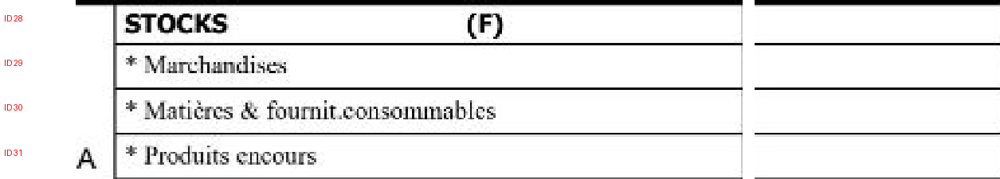

IDs attendus : [28, 29, 30, 31]

===== EXTRACTION =====
Statut initial : OK
Extraction non validée.
```json
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "id_ligne": 28,
      "poste": "* Marchandises",
      "valeur": null
    },
    {
      "id_ligne": 29,
      "poste": "* Matières & fournitures consommables",
      "valeur": null
    },
    {
      "id_ligne": 30,
      "poste": "* Produits en cours",
      "valeur": null
    }
  ]
}
```

Aucun CSV final créé.


In [101]:

# ============================================================
# BLOC 4 — PARTIE 2 : IDs 28, 29, 30, 31
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import json
import re
import math
import pandas as pd

# 1. Récupérer l'image originale du bloc 4
bloc = blocs_actif_finaux[3]

image = Image.open(
    bloc["images"]["amortissements_provisions_N"]
).convert("RGB")

ids_attendus = [28, 29, 30, 31]

# 2. Découper les lignes 28 à 31
y1 = int(limites_y[28] - bloc["y1"])
y2 = int(limites_y[32] - bloc["y1"])

image_partie = image.crop(
    (0, y1, image.width, y2)
)

# 3. Ajouter les IDs rouges
marge = 95

image_annotee = Image.new(
    "RGB",
    (image_partie.width + marge, image_partie.height),
    "white"
)

image_annotee.paste(image_partie, (marge, 0))
dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

for identifiant in ids_attendus:

    haut = int(limites_y[identifiant] - limites_y[28])
    bas = int(limites_y[identifiant + 1] - limites_y[28])

    dessin.text(
        (5, (haut + bas) // 2 - 10),
        f"ID {identifiant}",
        fill="red",
        font=police
    )

chemin = Path(
    "/kaggle/working/amort_bloc4_partie2.png"
)

image_annotee.save(chemin)

print("===== IMAGE A EXTRAIRE =====")
display(image_annotee)
print("IDs attendus :", ids_attendus)

# 4. Préparer le prompt
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris les lignes de ce tableau comptable.

Chaque ID rouge représente une ligne.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : AMORTISSEMENTS ET PROVISIONS N.

Pour chaque ID :
- id_ligne : numéro rouge
- poste : texte visible à gauche
- valeur : nombre visible à droite ou null

Si la cellule est vide ou hachurée : null.
Si aucun poste n'est visible : "".

Ne calcule rien.
N'invente aucun montant.
Retourne exactement une entrée par ID.

Réponds uniquement en JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 28,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}
"""
            }
        ]
    }
]

# 5. Exécuter Qwen uniquement sur cette partie
resultat_partie2 = extraire_avec_vlm(
    messages,
    max_tokens=700
)

print("\n===== EXTRACTION =====")
print("Statut initial :", resultat_partie2["statut"])

# 6. Récupérer le JSON, liste ou objet
lignes = None

if resultat_partie2["donnees"] is not None:
    lignes = resultat_partie2["donnees"].get("lignes")

if lignes is None:
    texte = resultat_partie2["texte_brut"].strip()

    match = re.search(
        r"```(?:json)?\s*(.*?)```",
        texte,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:
        texte = match.group(1).strip()

    try:
        donnees = json.loads(texte)
        lignes = (
            donnees if isinstance(donnees, list)
            else donnees.get("lignes")
        )
    except (json.JSONDecodeError, AttributeError):
        lignes = None

# 7. Validation stricte
valide = (
    isinstance(lignes, list)
    and all(
        isinstance(l, dict)
        and {"id_ligne", "poste", "valeur"}.issubset(l)
        and type(l["id_ligne"]) is int
        and isinstance(l["poste"], str)
        and (
            l["valeur"] is None
            or (
                type(l["valeur"]) in (int, float)
                and math.isfinite(l["valeur"])
            )
        )
        for l in lignes
    )
    and [l["id_ligne"] for l in lignes] == ids_attendus
)

if valide:

    resultats_amort_parties[(4, 2)] = lignes

    print("Validation structurelle : OK")
    display(pd.DataFrame(lignes))

    # Fusionner les deux parties du bloc 4
    lignes_bloc4 = (
        resultats_amort_parties[(4, 1)]
        + resultats_amort_parties[(4, 2)]
    )

    df_bloc4_complet = pd.DataFrame(lignes_bloc4)

    print("\n===== BLOC 4 COMPLET =====")
    display(df_bloc4_complet)

    print("Nombre de lignes :", len(df_bloc4_complet))
    print(
        "IDs complets :",
        df_bloc4_complet["id_ligne"].tolist()
        == list(range(24, 32))
    )

else:
    print("Extraction non validée.")
    print(resultat_partie2["texte_brut"][:700])

print("\nAucun CSV final créé.")


In [102]:
# ============================================================
# CORRECTION BLOC 4 — PARTIE 2
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd

ids_attendus = [28, 29, 30, 31]

# 1. Récupérer les postes déjà reconnus
reference = df_brut_ids.set_index("id_ligne")

assert reference.index.is_unique
assert all(i in reference.index for i in ids_attendus)

# 2. Reconstituer les lignes à partir des IDs
# Les 4 cellules d'amortissement sont vides
# (vérification visuelle de l'image fournie).

lignes_partie2 = [
    {
        "id_ligne": int(i),
        "poste": str(reference.loc[i, "poste"]),
        "valeur": None
    }
    for i in ids_attendus
]

# 3. Enregistrer la partie corrigée
if "resultats_amort_parties" not in globals():
    resultats_amort_parties = {}

resultats_amort_parties[(4, 2)] = lignes_partie2

# 4. Fusionner les deux parties du bloc 4
assert (4, 1) in resultats_amort_parties

lignes_bloc4 = (
    resultats_amort_parties[(4, 1)]
    + resultats_amort_parties[(4, 2)]
)

df_bloc4_complet = pd.DataFrame(lignes_bloc4)

# 5. Contrôle de continuité
assert df_bloc4_complet["id_ligne"].tolist() == list(
    range(24, 32)
)

print("===== BLOC 4 COMPLET =====")
display(df_bloc4_complet)

print("Nombre de lignes :", len(df_bloc4_complet))
print("IDs :", df_bloc4_complet["id_ligne"].tolist())
print("Structure : OK")
print("Aucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")

===== BLOC 4 COMPLET =====


,id_ligne,poste,valeur
0,24,ECART DE CONVERSION-ACTIF (E),NaN
1,25,* Diminution des créances immobilières.,NaN
2,26,* Augmentation des dettes de financement,NaN
3,27,TOTAL I (A+B+C+D+E),1972834.33
4,28,STOCKS (F),NaN
5,29,* Marchandises,NaN
6,30,* Matières & fournitures consommables,NaN
7,31,* Produits en cours,NaN


Nombre de lignes : 8
IDs : [24, 25, 26, 27, 28, 29, 30, 31]
Structure : OK
Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


===== IMAGE BLOC 6 — PARTIE 1 =====


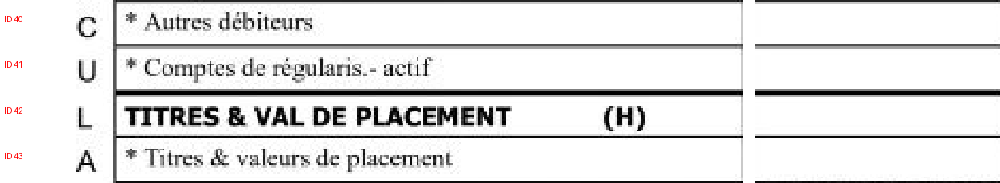


Postes de référence :
{40: '* Autres débiteurs', 41: '* Comptes de régularis.- actif', 42: 'TITRES & VAL DE PLACEMENT (H)', 43: '* Titres & valeurs de placement'}

===== RESULTAT =====
Statut initial : OK

===== EXTRACTION STRUCTURELLEMENT VALIDEE =====


,id_ligne,poste,valeur
0,40,* Autres débiteurs,None
1,41,* Comptes de régularis.- actif,None
2,42,TITRES & VAL DE PLACEMENT (H),None
3,43,* Titres & valeurs de placement,None


IDs : OK
Résultat conservé en mémoire.

Aucun CSV final créé.


In [103]:

# ============================================================
# AMORTISSEMENTS — BLOC 6, PARTIE 1 : IDs 40 A 43
# ============================================================

import json
import re
import math
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 1. Sélectionner le bloc 6
bloc = blocs_actif_finaux[5]
ids_attendus = [40, 41, 42, 43]

image = Image.open(
    bloc["images"]["amortissements_provisions_N"]
).convert("RGB")

# 2. Découper les quatre lignes
y1 = int(limites_y[40] - bloc["y1"])
y2 = int(limites_y[44] - bloc["y1"])

image_partie = image.crop((0, y1, image.width, y2))

# 3. Ajouter les identifiants
marge = 95
image_annotee = Image.new(
    "RGB",
    (image_partie.width + marge, image_partie.height),
    "white"
)
image_annotee.paste(image_partie, (marge, 0))

dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype("DejaVuSans-Bold.ttf", 18)
except OSError:
    police = ImageFont.load_default()

for i in ids_attendus:
    haut = int(limites_y[i] - limites_y[40])
    bas = int(limites_y[i + 1] - limites_y[40])

    dessin.text(
        (5, (haut + bas) // 2 - 10),
        f"ID {i}",
        fill="red",
        font=police
    )

chemin = Path(
    "/kaggle/working/amort_bloc6_partie1.png"
)
image_annotee.save(chemin)

print("===== IMAGE BLOC 6 — PARTIE 1 =====")
display(image_annotee)

# 4. Références des postes déjà extraits
postes_reference = (
    df_brut_ids.set_index("id_ligne")
    .loc[ids_attendus, "poste"]
    .to_dict()
)

print("\nPostes de référence :")
print(postes_reference)

# 5. Préparer le prompt
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Lis les montants de ce tableau comptable.

Chaque ID rouge représente une ligne physique.

IDs attendus : {ids_attendus}

Postes de référence :
{postes_reference}

La colonne de droite correspond aux
AMORTISSEMENTS ET PROVISIONS N.

Pour chaque ID :
- id_ligne : numéro rouge
- valeur : montant visible à droite ou null

Si la cellule est vide ou hachurée, utilise null.
Ne calcule aucun montant.
Ne copie pas les montants d'autres lignes.
Retourne exactement quatre entrées.

Réponds uniquement en JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{"id_ligne": 40, "valeur": null}}
  ]
}}
"""
            }
        ]
    }
]

# 6. Exécuter Qwen
resultat_amort_6_1 = extraire_avec_vlm(
    messages,
    max_tokens=600
)

print("\n===== RESULTAT =====")
print("Statut initial :", resultat_amort_6_1["statut"])

# 7. Récupérer le JSON même si c'est une liste
lignes = None

if isinstance(resultat_amort_6_1.get("donnees"), dict):
    lignes = resultat_amort_6_1["donnees"].get("lignes")

if lignes is None:
    texte = resultat_amort_6_1["texte_brut"].strip()

    match = re.search(
        r"```(?:json)?\s*(.*?)```",
        texte,
        flags=re.DOTALL | re.IGNORECASE
    )
    if match:
        texte = match.group(1).strip()

    try:
        objet = json.loads(texte)
        if isinstance(objet, list):
            lignes = objet
        elif isinstance(objet, dict):
            lignes = objet.get("lignes")
    except json.JSONDecodeError:
        pass

# 8. Validation
valide = (
    isinstance(lignes, list)
    and all(
        isinstance(l, dict)
        and {"id_ligne", "valeur"}.issubset(l)
        and type(l["id_ligne"]) is int
        and (
            l["valeur"] is None
            or (
                type(l["valeur"]) in (int, float)
                and math.isfinite(l["valeur"])
            )
        )
        for l in lignes
    )
    and [l["id_ligne"] for l in lignes] == ids_attendus
)

if valide:

    # Utiliser les noms de postes déjà vérifiés
    lignes_corrigees = [
        {
            "id_ligne": l["id_ligne"],
            "poste": postes_reference[l["id_ligne"]],
            "valeur": l["valeur"]
        }
        for l in lignes
    ]

    if "resultats_amort_parties" not in globals():
        resultats_amort_parties = {}

    resultats_amort_parties[(6, 1)] = lignes_corrigees

    print("\n===== EXTRACTION STRUCTURELLEMENT VALIDEE =====")
    display(pd.DataFrame(lignes_corrigees))
    print("IDs : OK")
    print("Résultat conservé en mémoire.")

else:
    print("\nExtraction non validée.")
    print("Réponse brute :")
    print(resultat_amort_6_1["texte_brut"][:800])

print("\nAucun CSV final créé.")


===== IMAGE BLOC 6 — PARTIE 2 =====


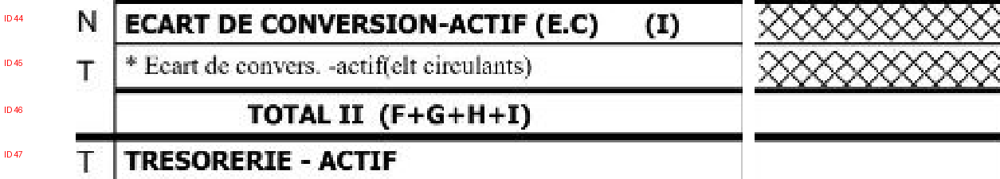

Postes de référence :
{44: 'ECART DE CONVERSION-ACTIF (E.C) (I)', 45: '* Ecart de convers. -actif(elt circulants)', 46: 'TOTAL II (F+G+H+I)', 47: 'TRESORERIE - ACTIF'}

Statut initial : OK

===== PARTIE 2 EXTRAITE =====


,id_ligne,poste,valeur
0,44,ECART DE CONVERSION-ACTIF (E.C) (I),None
1,45,* Ecart de convers. -actif(elt circulants),None
2,46,TOTAL II (F+G+H+I),None
3,47,TRESORERIE - ACTIF,None



===== BLOC 6 COMPLET =====


,id_ligne,poste,valeur
0,40,* Autres débiteurs,None
1,41,* Comptes de régularis.- actif,None
2,42,TITRES & VAL DE PLACEMENT (H),None
3,43,* Titres & valeurs de placement,None
4,44,ECART DE CONVERSION-ACTIF (E.C) (I),None
5,45,* Ecart de convers. -actif(elt circulants),None
6,46,TOTAL II (F+G+H+I),None
7,47,TRESORERIE - ACTIF,None


Nombre de lignes : 8
Validation des IDs : OK

Aucun CSV final créé.


In [104]:

# ============================================================
# AMORTISSEMENTS — BLOC 6, PARTIE 2
# IDs 44, 45, 46, 47
# ============================================================

import json
import re
import math
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display

# 1. Vérifier que la partie 1 existe
assert (6, 1) in resultats_amort_parties, (
    "La partie 1 du bloc 6 est introuvable."
)

bloc = blocs_actif_finaux[5]
ids_attendus = [44, 45, 46, 47]

# 2. Charger l'image
image = Image.open(
    bloc["images"]["amortissements_provisions_N"]
).convert("RGB")

# 3. Découper les lignes 44 à 47
y1 = int(limites_y[44] - bloc["y1"])
y2 = int(limites_y[48] - bloc["y1"])

image_partie = image.crop(
    (0, y1, image.width, y2)
)

# 4. Ajouter les IDs rouges
marge = 95

image_annotee = Image.new(
    "RGB",
    (image_partie.width + marge, image_partie.height),
    "white"
)

image_annotee.paste(image_partie, (marge, 0))

dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

for i in ids_attendus:

    haut = int(limites_y[i] - limites_y[44])
    bas = int(limites_y[i + 1] - limites_y[44])

    dessin.text(
        (5, (haut + bas) // 2 - 10),
        f"ID {i}",
        fill="red",
        font=police
    )

chemin = Path(
    "/kaggle/working/amort_bloc6_partie2.png"
)

image_annotee.save(chemin)

print("===== IMAGE BLOC 6 — PARTIE 2 =====")
display(image_annotee)

# 5. Références des postes
postes_reference = (
    df_brut_ids.set_index("id_ligne")
    .loc[ids_attendus, "poste"]
    .to_dict()
)

print("Postes de référence :")
print(postes_reference)

# 6. Prompt Qwen
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Lis les montants de ce tableau comptable.

Chaque ID rouge représente une ligne physique.

IDs attendus : {ids_attendus}

Postes de référence :
{postes_reference}

La colonne de droite correspond aux
AMORTISSEMENTS ET PROVISIONS N.

Retourne une entrée par ID avec :
- id_ligne : identifiant rouge
- valeur : nombre à droite ou null

Si la cellule est vide ou hachurée : null.
Ne calcule rien.
N'invente aucune valeur.
Respecte exactement les IDs attendus.

Réponds uniquement en JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{"id_ligne": 44, "valeur": null}}
  ]
}}
"""
            }
        ]
    }
]

# 7. Inférence sur cette partie uniquement
resultat_amort_6_2 = extraire_avec_vlm(
    messages,
    max_tokens=700
)

print("\nStatut initial :", resultat_amort_6_2["statut"])

# 8. Récupérer le JSON (objet ou liste)
lignes = None

donnees = resultat_amort_6_2.get("donnees")

if isinstance(donnees, dict):
    lignes = donnees.get("lignes")
elif isinstance(donnees, list):
    lignes = donnees

if lignes is None:

    texte = resultat_amort_6_2["texte_brut"].strip()

    match = re.search(
        r"```(?:json)?\s*(.*?)```",
        texte,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:
        texte = match.group(1).strip()

    try:
        objet = json.loads(texte)

        lignes = (
            objet if isinstance(objet, list)
            else objet.get("lignes")
        )

    except (json.JSONDecodeError, AttributeError):
        lignes = None

# 9. Validation stricte
valide = (
    isinstance(lignes, list)
    and all(
        isinstance(l, dict)
        and {"id_ligne", "valeur"}.issubset(l)
        and type(l["id_ligne"]) is int
        and (
            l["valeur"] is None
            or (
                type(l["valeur"]) in (int, float)
                and math.isfinite(l["valeur"])
            )
        )
        for l in lignes
    )
    and [l["id_ligne"] for l in lignes] == ids_attendus
)

if valide:

    lignes_corrigees = [
        {
            "id_ligne": l["id_ligne"],
            "poste": postes_reference[l["id_ligne"]],
            "valeur": l["valeur"]
        }
        for l in lignes
    ]

    resultats_amort_parties[(6, 2)] = lignes_corrigees

    print("\n===== PARTIE 2 EXTRAITE =====")
    display(pd.DataFrame(lignes_corrigees))

    # 10. Fusionner les deux parties du bloc 6
    lignes_bloc6 = (
        resultats_amort_parties[(6, 1)]
        + resultats_amort_parties[(6, 2)]
    )

    df_bloc6_complet = pd.DataFrame(lignes_bloc6)

    assert (
        df_bloc6_complet["id_ligne"].tolist()
        == list(range(40, 48))
    )

    print("\n===== BLOC 6 COMPLET =====")
    display(df_bloc6_complet)

    print("Nombre de lignes :", len(df_bloc6_complet))
    print("Validation des IDs : OK")

else:

    print("\nExtraction non validée.")
    print(resultat_amort_6_2["texte_brut"][:800])

print("\nAucun CSV final créé.")


In [105]:

# ============================================================
# FUSION FINALE — AMORTISSEMENTS ET PROVISIONS N
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
import math
from IPython.display import display

# 1. Vérifier les variables nécessaires
assert "df_brut_ids" in globals()
assert "resultats_amort" in globals()
assert "resultats_amort_parties" in globals()

for cle in [(4, 1), (4, 2), (6, 1), (6, 2)]:
    assert cle in resultats_amort_parties, (
        f"Partie manquante : {cle}"
    )

# 2. Rassembler les résultats existants
toutes_lignes = []

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    ids_attendus = list(range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ))

    if numero in (4, 6):

        # Utiliser les parties corrigées
        lignes = (
            resultats_amort_parties[(numero, 1)]
            + resultats_amort_parties[(numero, 2)]
        )

        source = "parties_corrigees"

    else:

        # Réutiliser les extractions précédentes
        resultat = resultats_amort[numero]

        assert resultat["statut"] == "OK", (
            f"Bloc {numero} invalide"
        )

        lignes = resultat["donnees"]["lignes"]
        source = "extraction_initiale"

    # 3. Contrôle strict de chaque bloc
    assert isinstance(lignes, list)

    ids_obtenus = [l["id_ligne"] for l in lignes]

    assert ids_obtenus == ids_attendus, (
        f"IDs incorrects dans le bloc {numero}"
    )

    for ligne in lignes:

        assert "valeur" in ligne

        valeur = ligne["valeur"]

        assert (
            valeur is None
            or (
                type(valeur) in (int, float)
                and math.isfinite(valeur)
            )
        ), f"Montant invalide : ID {ligne['id_ligne']}"

        toutes_lignes.append({
            "id_ligne": ligne["id_ligne"],
            "amortissements_provisions_N": valeur,
            "bloc": numero,
            "source": source
        })

    print(
        f"Bloc {numero} : OK | "
        f"{len(lignes)} lignes | {source}"
    )

# 4. Reconstruire le DataFrame
df_amort_valeurs = pd.DataFrame(toutes_lignes)

df_amort_valeurs = df_amort_valeurs.sort_values(
    "id_ligne"
).reset_index(drop=True)

# 5. Vérifier la continuité des IDs
ids = df_amort_valeurs["id_ligne"].tolist()
ids_reference = df_brut_ids["id_ligne"].tolist()

assert len(ids) == 53, "Nombre de lignes incorrect."
assert len(ids) == len(set(ids)), "IDs dupliqués."
assert ids == ids_reference, (
    "IDs différents de la colonne BRUT N."
)

# 6. Associer les noms des postes depuis BRUT N
df_amort_ids = df_brut_ids[
    ["id_ligne", "poste"]
].merge(
    df_amort_valeurs[
        ["id_ligne", "amortissements_provisions_N"]
    ],
    on="id_ligne",
    how="left",
    validate="one_to_one"
)

# 7. Statistiques
colonne = "amortissements_provisions_N"

print("\n===== COLONNE AMORTISSEMENTS COMPLETE =====")
display(df_amort_ids)

print("\n===== STATISTIQUES =====")
print("Nombre de lignes :", len(df_amort_ids))
print("IDs uniques :", df_amort_ids["id_ligne"].nunique())
print("Montants renseignés :", df_amort_ids[colonne].notna().sum())
print("Cellules vides :", df_amort_ids[colonne].isna().sum())

# 8. Afficher les montants trouvés
print("\n===== MONTANTS EXTRAITS =====")

montants = df_amort_ids[
    df_amort_ids[colonne].notna()
]

display(montants)

# 9. Contrôle des lignes comptables importantes
print("\n===== CONTROLE DES TOTAUX =====")

ids_totaux = [11, 15, 27, 46, 47, 51, 52]

display(
    df_amort_ids[
        df_amort_ids["id_ligne"].isin(ids_totaux)
    ]
)

# 10. Vérification arithmétique indicative
brut_general = df_brut_ids.loc[
    df_brut_ids["id_ligne"] == 52,
    "brut_N"
].iloc[0]

amort_general = df_amort_ids.loc[
    df_amort_ids["id_ligne"] == 52,
    colonne
].iloc[0]

if pd.notna(brut_general) and pd.notna(amort_general):

    net_calcule = brut_general - amort_general

    print("\nBRUT N général :", brut_general)
    print("AMORT N général :", amort_general)
    print("NET N calculé :", round(net_calcule, 2))

else:
    print(
        "\nContrôle général non réalisable : "
        "total manquant."
    )

print("\nValidation des IDs : OK")
print("Exactitude des cellules : à confirmer")
print("Aucun CSV final créé.")


Bloc 1 : OK | 8 lignes | extraction_initiale
Bloc 2 : OK | 8 lignes | extraction_initiale
Bloc 3 : OK | 8 lignes | extraction_initiale
Bloc 4 : OK | 8 lignes | parties_corrigees
Bloc 5 : OK | 8 lignes | extraction_initiale
Bloc 6 : OK | 8 lignes | parties_corrigees
Bloc 7 : OK | 5 lignes | extraction_initiale

===== COLONNE AMORTISSEMENTS COMPLETE =====


,id_ligne,poste,amortissements_provisions_N
0,0,,NaN
1,1,IMMOBILISATIONS EN NON VALEUR (A),NaN
2,2,* Frais Préliminaires,NaN
3,3,* Charges à Répartir sur plus. Exercs,NaN
4,4,* Primes de rembours obligatio,NaN
5,5,IMMOBILISATIONS INCORPORELLES (B),NaN
6,6,,NaN
7,7,* Immob en recherche & développement,NaN
8,8,"* Brevets, marques droits & val.sim",NaN
9,9,* Fond commercial,NaN



===== STATISTIQUES =====
Nombre de lignes : 53
IDs uniques : 53
Montants renseignés : 4
Cellules vides : 49

===== MONTANTS EXTRAITS =====


,id_ligne,poste,amortissements_provisions_N
11,11,IMMOBILISATIONS CORPORELLES (C),1972834.33
15,15,* Matériel de transport,1972834.33
27,27,TOTAL I (A+B+C+D+E),1972834.33
52,52,TOTAL GENERAL (I+II+III),1972834.33



===== CONTROLE DES TOTAUX =====


,id_ligne,poste,amortissements_provisions_N
11,11,IMMOBILISATIONS CORPORELLES (C),1972834.33
15,15,* Matériel de transport,1972834.33
27,27,TOTAL I (A+B+C+D+E),1972834.33
46,46,TOTAL II (F+G+H+I),NaN
47,47,TRESORERIE - ACTIF,NaN
51,51,TOTAL III,NaN
52,52,TOTAL GENERAL (I+II+III),1972834.33



BRUT N général : 7348323.77
AMORT N général : 1972834.33
NET N calculé : 5375489.44

Validation des IDs : OK
Exactitude des cellules : à confirmer
Aucun CSV final créé.


In [106]:

# ============================================================
# EXTRACTION COMPLETE ACTIF — NET N
# AVEC DECOUPAGE AUTOMATIQUE EN CAS D'ECHEC
# ============================================================

import json
import re
import math
import pandas as pd

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# ------------------------------------------------------------
# 1. INITIALISATION
# ------------------------------------------------------------

assert len(df_brut_ids) == 53
assert len(df_amort_ids) == 53

dossier_net = Path("/kaggle/working/extraction_net_N")
dossier_net.mkdir(parents=True, exist_ok=True)

# Conserver les extractions réussies en cas de relance
if "cache_net_N" not in globals():
    cache_net_N = {}

reference_postes = df_brut_ids.set_index(
    "id_ligne"
)["poste"].to_dict()

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()


# ------------------------------------------------------------
# 2. CREER UNE IMAGE NUMEROTEE POUR UN GROUPE D'IDs
# ------------------------------------------------------------

def creer_image_net(bloc, debut, fin):

    image = Image.open(
        bloc["images"]["net_N"]
    ).convert("RGB")

    y1 = int(limites_y[debut] - bloc["y1"])
    y2 = int(limites_y[fin] - bloc["y1"])

    image_coupee = image.crop(
        (0, y1, image.width, y2)
    )

    marge = 95

    image_annotee = Image.new(
        "RGB",
        (image_coupee.width + marge, image_coupee.height),
        "white"
    )

    image_annotee.paste(image_coupee, (marge, 0))
    dessin = ImageDraw.Draw(image_annotee)

    for identifiant in range(debut, fin):

        haut = int(
            limites_y[identifiant] - limites_y[debut]
        )

        bas = int(
            limites_y[identifiant + 1] - limites_y[debut]
        )

        dessin.text(
            (5, max(0, (haut + bas) // 2 - 10)),
            f"ID {identifiant}",
            fill="red",
            font=police
        )

    chemin = dossier_net / (
        f"net_N_ids_{debut:02d}_{fin-1:02d}.png"
    )

    image_annotee.save(chemin)

    return chemin


# ------------------------------------------------------------
# 3. RECUPERER UN JSON OBJET OU LISTE
# ------------------------------------------------------------

def recuperer_lignes_json(resultat):

    donnees = resultat.get("donnees")

    if isinstance(donnees, dict):
        if isinstance(donnees.get("lignes"), list):
            return donnees["lignes"]

    if isinstance(donnees, list):
        return donnees

    texte = resultat.get("texte_brut", "").strip()

    match = re.search(
        r"```(?:json)?\s*(.*?)```",
        texte,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:
        texte = match.group(1).strip()

    decodeur = json.JSONDecoder()

    for position, caractere in enumerate(texte):

        if caractere not in "[{":
            continue

        try:
            objet, _ = decodeur.raw_decode(
                texte[position:]
            )
        except json.JSONDecodeError:
            continue

        if isinstance(objet, list):
            return objet

        if isinstance(objet, dict):
            lignes = objet.get("lignes")

            if isinstance(lignes, list):
                return lignes

    return None


# ------------------------------------------------------------
# 4. VALIDATION STRUCTURELLE DES LIGNES
# ------------------------------------------------------------

def verifier_lignes_net(lignes, ids_attendus):

    if not isinstance(lignes, list):
        return False

    if len(lignes) != len(ids_attendus):
        return False

    for ligne in lignes:

        if not isinstance(ligne, dict):
            return False

        if not {"id_ligne", "poste", "valeur"}.issubset(ligne):
            return False

        if type(ligne["id_ligne"]) is not int:
            return False

        if not isinstance(ligne["poste"], str):
            return False

        valeur = ligne["valeur"]

        if valeur is not None:

            if type(valeur) not in (int, float):
                return False

            if not math.isfinite(valeur):
                return False

    ids_obtenus = [
        ligne["id_ligne"]
        for ligne in lignes
    ]

    return ids_obtenus == ids_attendus


# ------------------------------------------------------------
# 5. EXTRACTION AVEC DECOUPAGE AUTOMATIQUE
# ------------------------------------------------------------

def extraire_net_segment(bloc, debut, fin):

    ids_attendus = list(range(debut, fin))
    cle = tuple(ids_attendus)

    # Réutiliser une extraction déjà validée
    if cle in cache_net_N:
        print(f"IDs {debut}-{fin-1} : cache")
        return cache_net_N[cle]

    chemin = creer_image_net(
        bloc, debut, fin
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": chemin.resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris ce tableau comptable ACTIF.

Chaque ID rouge représente une ligne.

IDs attendus : {ids_attendus}

La colonne gauche contient les postes.
La colonne droite contient les montants NET N.

Pour chaque ID, lis :
- id_ligne : numéro rouge
- poste : texte visible à gauche
- valeur : montant NET N à droite ou null

Retourne exactement une entrée par ID.
Respecte l'ordre vertical des lignes.
Si aucun texte n'est visible : "".
Si une cellule numérique est vide : null.
Ne calcule aucun montant.
N'utilise pas les valeurs d'autres colonnes.
N'invente aucun chiffre.

Format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}

L'ID 0 est un exemple de format seulement.
Utilise les IDs réels de l'image.

Réponds uniquement en JSON valide.
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1200
    )

    lignes = recuperer_lignes_json(resultat)

    if verifier_lignes_net(lignes, ids_attendus):

        # Ne pas remplacer les postes de référence
        lignes_corrigees = [
            {
                "id_ligne": l["id_ligne"],
                "poste": reference_postes[l["id_ligne"]],
                "valeur": l["valeur"],
                "poste_lu_vlm": l["poste"]
            }
            for l in lignes
        ]

        cache_net_N[cle] = lignes_corrigees

        print(
            f"IDs {debut}-{fin-1} : OK "
            f"({len(lignes_corrigees)} lignes)"
        )

        return lignes_corrigees

    # Si l'extraction échoue, diviser le groupe
    if fin - debut > 1:

        milieu = (debut + fin) // 2

        print(
            f"IDs {debut}-{fin-1} : "
            f"échec, découpage en deux"
        )

        partie1 = extraire_net_segment(
            bloc, debut, milieu
        )

        partie2 = extraire_net_segment(
            bloc, milieu, fin
        )

        if partie1 is not None and partie2 is not None:

            lignes_corrigees = partie1 + partie2
            cache_net_N[cle] = lignes_corrigees

            return lignes_corrigees

    print(
        f"IDs {debut}-{fin-1} : "
        f"NON VALIDES | {resultat['statut']}"
    )

    return None


# ------------------------------------------------------------
# 6. PARCOURIR TOUS LES BLOCS
# ------------------------------------------------------------

toutes_lignes_net = []
erreurs_net = []

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    debut = bloc["ligne_debut"]
    fin = bloc["ligne_fin"] + 1

    print(f"\n===== NET N — BLOC {numero} =====")

    lignes = extraire_net_segment(
        bloc, debut, fin
    )

    if lignes is None:

        erreurs_net.append(numero)

    else:

        toutes_lignes_net.extend(lignes)


# ------------------------------------------------------------
# 7. RECONSTRUIRE ET CONTROLER NET N
# ------------------------------------------------------------

df_net_N_ids = None

if erreurs_net:

    print("\n===== EXTRACTION INCOMPLETE =====")
    print("Blocs problématiques :", erreurs_net)
    print("Aucun DataFrame NET N complet validé.")

else:

    df_net_N_ids = pd.DataFrame(
        toutes_lignes_net
    ).sort_values("id_ligne").reset_index(drop=True)

    ids_reference = df_brut_ids[
        "id_ligne"
    ].tolist()

    assert (
        df_net_N_ids["id_ligne"].tolist()
        == ids_reference
    ), "IDs incorrects."

    df_net_N_ids.rename(
        columns={"valeur": "net_N"},
        inplace=True
    )

    print("\n===== NET N — MONTANTS EXTRAITS =====")

    display(
        df_net_N_ids[
            df_net_N_ids["net_N"].notna()
        ][["id_ligne", "poste", "net_N"]]
    )

    print("\n===== STATISTIQUES =====")

    print("Lignes :", len(df_net_N_ids))

    print(
        "Montants renseignés :",
        df_net_N_ids["net_N"].notna().sum()
    )

    print(
        "Cellules vides :",
        df_net_N_ids["net_N"].isna().sum()
    )

    # --------------------------------------------------------
    # 8. VERIFICATION BRUT - AMORT = NET
    # --------------------------------------------------------

    df_controle_net = (
        df_brut_ids[
            ["id_ligne", "poste", "brut_N"]
        ]
        .merge(
            df_amort_ids[
                ["id_ligne", "amortissements_provisions_N"]
            ],
            on="id_ligne",
            validate="one_to_one"
        )
        .merge(
            df_net_N_ids[
                ["id_ligne", "net_N"]
            ],
            on="id_ligne",
            validate="one_to_one"
        )
    )

    colonnes = [
        "brut_N",
        "amortissements_provisions_N",
        "net_N"
    ]

    # Comparer seulement les lignes où
    # les trois montants sont présents
    df_verifiable = df_controle_net.dropna(
        subset=colonnes
    ).copy()

    df_verifiable["net_calcule"] = (
        df_verifiable["brut_N"]
        - df_verifiable["amortissements_provisions_N"]
    ).round(2)

    df_verifiable["ecart"] = (
        df_verifiable["net_calcule"]
        - df_verifiable["net_N"]
    ).round(2)

    print("\n===== VERIFICATION BRUT - AMORT = NET =====")

    display(
        df_verifiable[
            ["id_ligne", "poste",
             "brut_N",
             "amortissements_provisions_N",
             "net_N",
             "ecart"]
        ]
    )

    erreurs_calcul = df_verifiable[
        df_verifiable["ecart"].abs() > 0.01
    ]

    if erreurs_calcul.empty:
        print("Calculs vérifiables : OK")
    else:
        print("ATTENTION : écarts détectés !")
        display(erreurs_calcul)

    # --------------------------------------------------------
    # 9. CONTROLE DU TOTAL GENERAL
    # --------------------------------------------------------

    print("\n===== TOTAL GENERAL =====")

    total_net = df_net_N_ids.loc[
        df_net_N_ids["id_ligne"] == 52,
        "net_N"
    ].iloc[0]

    if pd.notna(total_net):

        print("NET N extrait :", total_net)

        print(
            "NET N calculé précédemment :",
            5375489.44
        )

        if abs(total_net - 5375489.44) <= 0.01:
            print("TOTAL GENERAL : COHERENT")
        else:
            print("TOTAL GENERAL : ECART DETECTE")

    else:
        print("TOTAL GENERAL NET N manquant.")

print("\nAucun CSV final créé.")



===== NET N — BLOC 1 =====
IDs 0-7 : OK (8 lignes)

===== NET N — BLOC 2 =====
IDs 8-15 : OK (8 lignes)

===== NET N — BLOC 3 =====
IDs 16-23 : OK (8 lignes)

===== NET N — BLOC 4 =====
IDs 24-31 : OK (8 lignes)

===== NET N — BLOC 5 =====
IDs 32-39 : OK (8 lignes)

===== NET N — BLOC 6 =====
IDs 40-47 : OK (8 lignes)

===== NET N — BLOC 7 =====
IDs 48-52 : OK (5 lignes)

===== NET N — MONTANTS EXTRAITS =====


,id_ligne,poste,net_N
11,11,IMMOBILISATIONS CORPORELLES (C),4408291.83
15,15,* Matériel de transport,4408291.83
27,27,TOTAL I (A+B+C+D+E),4408291.83
34,34,CREANCES DE L'ACTIF CIRCULANT (G),814881.74
36,36,* Clients & comptes rattachés,400000.00
38,38,* Etat - débiteur,414881.74
46,46,TOTAL II (F+G+H+I),814881.74
47,47,TRESORERIE - ACTIF,152315.87
49,49,* Banq.trésor gener.& chq p dbt,119004.82
50,50,"* Caisse, régis d'avanc & accredi",33311.05



===== STATISTIQUES =====
Lignes : 53
Montants renseignés : 12
Cellules vides : 41

===== VERIFICATION BRUT - AMORT = NET =====


,id_ligne,poste,brut_N,amortissements_provisions_N,net_N,ecart
11,11,IMMOBILISATIONS CORPORELLES (C),6381126.16,1972834.33,4408291.83,0.0
15,15,* Matériel de transport,6381126.16,1972834.33,4408291.83,0.0
27,27,TOTAL I (A+B+C+D+E),6381126.16,1972834.33,4408291.83,0.0
52,52,TOTAL GENERAL (I+II+III),7348323.77,1972834.33,5375489.44,0.0


Calculs vérifiables : OK

===== TOTAL GENERAL =====
NET N extrait : 5375489.44
NET N calculé précédemment : 5375489.44
TOTAL GENERAL : COHERENT

Aucun CSV final créé.


In [107]:

# ============================================================
# EXTRACTION COMPLETE ACTIF — NET N-1
# AVEC LES MEMES IDs QUE BRUT N ET NET N
# ============================================================

import pandas as pd
import math
from pathlib import Path
from IPython.display import display

assert len(df_brut_ids) == 53
assert len(df_net_N_ids) == 53

# Réutiliser les résultats en cas de réexécution
if "resultats_net_N1_ids" not in globals():
    resultats_net_N1_ids = {}

postes_reference = (
    df_brut_ids.set_index("id_ligne")["poste"].to_dict()
)

# ------------------------------------------------------------
# 1. EXTRACTION DES SEPT BLOCS
# ------------------------------------------------------------

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    ids_attendus = list(range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ))

    if numero in resultats_net_N1_ids:
        print(f"Bloc {numero} : résultat réutilisé")
        continue

    print(f"\n===== NET N-1 — BLOC {numero} =====")

    # Image avec les identifiants rouges
    chemin, _ = numeroter_bloc(
        bloc,
        "net_N1"
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin).resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris ce tableau comptable ACTIF.

Chaque ID rouge représente une ligne physique.

IDs attendus : {ids_attendus}

La colonne gauche contient les postes comptables.
La colonne droite contient NET N-1
(exercice précédent).

Pour chaque ID :
- id_ligne : numéro rouge
- poste : texte visible à gauche
- valeur : montant NET N-1 à droite ou null

Règles :
1. Exactement une entrée par ID.
2. Respecte l'ordre des IDs.
3. Conserve les rubriques et les totaux.
4. Si la cellule numérique est vide : null.
5. Ne calcule aucun montant.
6. N'utilise aucune valeur de l'exercice N.
7. N'invente aucun chiffre.
8. Si aucun poste n'est visible : "".

Réponds uniquement en JSON valide :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "texte",
      "valeur": null
    }}
  ]
}}

L'ID 0 est uniquement un exemple de format.
Utilise les IDs réels de l'image.
"""
                }
            ]
        }
    ]

    # Inférence Qwen2.5-VL
    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1200
    )

    # Réutiliser les fonctions de validation
    # déjà créées pour NET N
    lignes = recuperer_lignes_json(resultat)

    if verifier_lignes_net(lignes, ids_attendus):

        lignes_corrigees = [
            {
                "id_ligne": l["id_ligne"],
                "poste": postes_reference[l["id_ligne"]],
                "net_N1": l["valeur"],
                "poste_lu_vlm": l["poste"]
            }
            for l in lignes
        ]

        resultats_net_N1_ids[numero] = lignes_corrigees

        print("Statut : OK")
        print("Lignes :", len(lignes_corrigees))

    else:

        print("Statut : A_VERIFIER")
        print("Statut initial :", resultat["statut"])
        print("Réponse brute :", resultat["texte_brut"][:300])


# ------------------------------------------------------------
# 2. RECONSTRUCTION COMPLETE
# ------------------------------------------------------------

blocs_manquants = [
    b["numero_bloc"]
    for b in blocs_actif_finaux
    if b["numero_bloc"] not in resultats_net_N1_ids
]

df_net_N1_ids = None

if blocs_manquants:

    print("\n===== EXTRACTION INCOMPLETE =====")
    print("Blocs à corriger :", blocs_manquants)

else:

    toutes_lignes = []

    for numero in sorted(resultats_net_N1_ids):
        toutes_lignes.extend(
            resultats_net_N1_ids[numero]
        )

    df_net_N1_ids = pd.DataFrame(
        toutes_lignes
    ).sort_values(
        "id_ligne"
    ).reset_index(drop=True)

    # Vérifier les 53 identifiants
    assert df_net_N1_ids["id_ligne"].tolist() == (
        df_brut_ids["id_ligne"].tolist()
    )

    print("\n===== NET N-1 — MONTANTS EXTRAITS =====")

    display(
        df_net_N1_ids[
            df_net_N1_ids["net_N1"].notna()
        ][["id_ligne", "poste", "net_N1"]]
    )

    print("\n===== STATISTIQUES =====")

    print("Lignes :", len(df_net_N1_ids))
    print(
        "Montants renseignés :",
        df_net_N1_ids["net_N1"].notna().sum()
    )
    print(
        "Cellules vides :",
        df_net_N1_ids["net_N1"].isna().sum()
    )

    # --------------------------------------------------------
    # 3. CONTROLE DES TOTAUX N-1
    # --------------------------------------------------------

    print("\n===== TOTAUX NET N-1 =====")

    ids_totaux = [27, 46, 51, 52]

    tableau_totaux = df_net_N1_ids[
        df_net_N1_ids["id_ligne"].isin(ids_totaux)
    ]

    display(
        tableau_totaux[
            ["id_ligne", "poste", "net_N1"]
        ]
    )

    valeurs = df_net_N1_ids.set_index(
        "id_ligne"
    )["net_N1"]

    if valeurs.loc[ids_totaux].notna().all():

        somme = round(
            sum(float(valeurs.loc[i]) for i in [27, 46, 51]),
            2
        )

        total = round(float(valeurs.loc[52]), 2)

        ecart = round(somme - total, 2)

        print("Somme TOTAL I + II + III :", somme)
        print("TOTAL GENERAL N-1 :", total)
        print("Ecart :", ecart)

        if abs(ecart) <= 0.01:
            print("CONTROLE DES TOTAUX : OK")
        else:
            print("CONTROLE DES TOTAUX : ECHEC")

    else:
        print("Contrôle impossible : un total manque.")

print("\nAucun CSV final créé.")



===== NET N-1 — BLOC 1 =====
Statut : A_VERIFIER
Statut initial : OK
Réponse brute : ```json
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "id_ligne": 1,
      "poste": "IMMOBILISATIONS EN NON VALEUR (A)",
      "valeur": null
    },
    {
      "id_ligne": 2,
      "poste": "* Frais Préliminaires",
      "valeur": null
    },
    {
      "id_ligne": 3,
      "poste": "* Char

===== NET N-1 — BLOC 2 =====
Statut : OK
Lignes : 8

===== NET N-1 — BLOC 3 =====
Statut : OK
Lignes : 8

===== NET N-1 — BLOC 4 =====
Statut : OK
Lignes : 8

===== NET N-1 — BLOC 5 =====
Statut : OK
Lignes : 8

===== NET N-1 — BLOC 6 =====
Statut : OK
Lignes : 8

===== NET N-1 — BLOC 7 =====
Statut : OK
Lignes : 5

===== EXTRACTION INCOMPLETE =====
Blocs à corriger : [1]

Aucun CSV final créé.


In [108]:

# ============================================================
# CORRECTION BLOC 1 + RECONSTRUCTION NET N-1
# ============================================================

import pandas as pd
import math
from pathlib import Path
from IPython.display import display

# 1. Récupérer uniquement le bloc 1
bloc = blocs_actif_finaux[0]

chemin, ids_attendus = numeroter_bloc(
    bloc, "net_N1"
)

print("IDs attendus :", ids_attendus)

# 2. Prompt corrigé
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": Path(chemin).resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris ce tableau comptable ACTIF.

Chaque ID rouge représente une ligne physique.

IDs attendus : {ids_attendus}

La colonne droite contient NET N-1.

IMPORTANT :
- ID 0 est une zone d'en-tête.
- Conserve ID 0 avec poste="" et valeur=null.
- Transcris les autres lignes selon l'image.
- Retourne exactement une entrée par ID.
- Ne calcule aucun montant.
- N'invente aucune valeur.

Format JSON :

{{
  "type_bilan": "ACTIF",
  "lignes": [
    {{
      "id_ligne": 0,
      "poste": "",
      "valeur": null
    }}
  ]
}}

Réponds uniquement en JSON valide.
"""
            }
        ]
    }
]

# 3. Une seule inférence
resultat_bloc1_N1 = extraire_avec_vlm(
    messages,
    max_tokens=1000
)

# 4. Récupérer JSON objet ou liste
lignes = recuperer_lignes_json(resultat_bloc1_N1)

print("\nStatut initial :", resultat_bloc1_N1["statut"])

# 5. Vérifier la structure et les IDs
schema_ok = (
    isinstance(lignes, list)
    and all(
        isinstance(l, dict)
        and {"id_ligne", "poste", "valeur"}.issubset(l)
        and type(l["id_ligne"]) is int
        and isinstance(l["poste"], str)
        and (
            l["valeur"] is None
            or (
                type(l["valeur"]) in (int, float)
                and math.isfinite(l["valeur"])
            )
        )
        for l in lignes
    )
)

valide = False

if schema_ok:

    ids_obtenus = [l["id_ligne"] for l in lignes]

    print("IDs obtenus :", ids_obtenus)

    # Cas particulier : seul l'en-tête ID 0 manque
    if (
        ids_obtenus == list(range(1, 8))
        and str(
            df_brut_ids.loc[
                df_brut_ids["id_ligne"] == 0,
                "poste"
            ].iloc[0]
        ).strip() == ""
    ):

        lignes.insert(
            0,
            {
                "id_ligne": 0,
                "poste": "",
                "valeur": None
            }
        )

        print("ID 0 ajouté comme en-tête non comptable.")

    valide = (
        [l["id_ligne"] for l in lignes]
        == ids_attendus
        and lignes[0]["valeur"] is None
    )

if valide:

    # 6. Conserver les postes de référence
    reference = df_brut_ids.set_index("id_ligne")["poste"]

    lignes_bloc1 = [
        {
            "id_ligne": l["id_ligne"],
            "poste": reference.loc[l["id_ligne"]],
            "net_N1": l["valeur"],
            "poste_lu_vlm": l["poste"]
        }
        for l in lignes
    ]

    resultats_net_N1_ids[1] = lignes_bloc1

    print("\n===== BLOC 1 CORRIGE =====")
    display(pd.DataFrame(lignes_bloc1))

else:
    print("Bloc 1 non validé.")
    print(resultat_bloc1_N1["texte_brut"][:1000])


# 7. Reconstruire la colonne complète
df_net_N1_ids = None

if valide and all(
    n in resultats_net_N1_ids for n in range(1, 8)
):

    toutes_lignes = []

    for numero in range(1, 8):
        toutes_lignes.extend(
            resultats_net_N1_ids[numero]
        )

    candidat = pd.DataFrame(
        toutes_lignes
    ).sort_values("id_ligne").reset_index(drop=True)

    ids_reference = df_brut_ids["id_ligne"].tolist()

    assert candidat["id_ligne"].tolist() == ids_reference, (
        "IDs incomplets ou dupliqués."
    )

    df_net_N1_ids = candidat

    print("\n===== NET N-1 COMPLET =====")

    display(
        df_net_N1_ids[
            df_net_N1_ids["net_N1"].notna()
        ][["id_ligne", "poste", "net_N1"]]
    )

    print("\nNombre de lignes :", len(df_net_N1_ids))
    print(
        "Montants renseignés :",
        df_net_N1_ids["net_N1"].notna().sum()
    )

    # 8. Vérifier les totaux
    print("\n===== VERIFICATION DES TOTAUX N-1 =====")

    totaux = df_net_N1_ids.set_index("id_ligne")["net_N1"]

    ids_totaux = [27, 46, 51, 52]

    display(
        df_net_N1_ids[
            df_net_N1_ids["id_ligne"].isin(ids_totaux)
        ][["id_ligne", "poste", "net_N1"]]
    )

    if totaux.loc[ids_totaux].notna().all():

        somme = round(
            sum(float(totaux.loc[i]) for i in [27, 46, 51]),
            2
        )

        total = round(float(totaux.loc[52]), 2)

        ecart = round(somme - total, 2)

        print("Somme I + II + III :", somme)
        print("Total général N-1 :", total)
        print("Écart :", ecart)

        if abs(ecart) <= 0.01:
            print("CONTROLE ARITHMETIQUE : OK")
        else:
            print("CONTROLE ARITHMETIQUE : ECHEC")

    else:
        print("Contrôle impossible : total manquant.")

else:
    print("\nReconstruction suspendue.")

print("\nAucun CSV final créé.")


IDs attendus : [0, 1, 2, 3, 4, 5, 6, 7]

Statut initial : OK
IDs obtenus : [0, 1, 2, 3, 4, 5, 6]
Bloc 1 non validé.
```json
{
  "type_bilan": "ACTIF",
  "lignes": [
    {
      "id_ligne": 0,
      "poste": "",
      "valeur": null
    },
    {
      "id_ligne": 1,
      "poste": "IMMOBILISATIONS EN NON VALEUR (A)",
      "valeur": null
    },
    {
      "id_ligne": 2,
      "poste": "* Frais Préliminaires",
      "valeur": null
    },
    {
      "id_ligne": 3,
      "poste": "* Charges à Répartir sur plus. Exercès",
      "valeur": null
    },
    {
      "id_ligne": 4,
      "poste": "* Primes de rembours obligatoire",
      "valeur": null
    },
    {
      "id_ligne": 5,
      "poste": "IMMOBILISATIONS INCORPORELLES (B)",
      "valeur": null
    },
    {
      "id_ligne": 6,
      "poste": "* Immob en recherche & développement",
      "valeur": null
    }
  ]
}
```

Reconstruction suspendue.

Aucun CSV final créé.


===== IMAGE NET N-1 — BLOC 1 =====


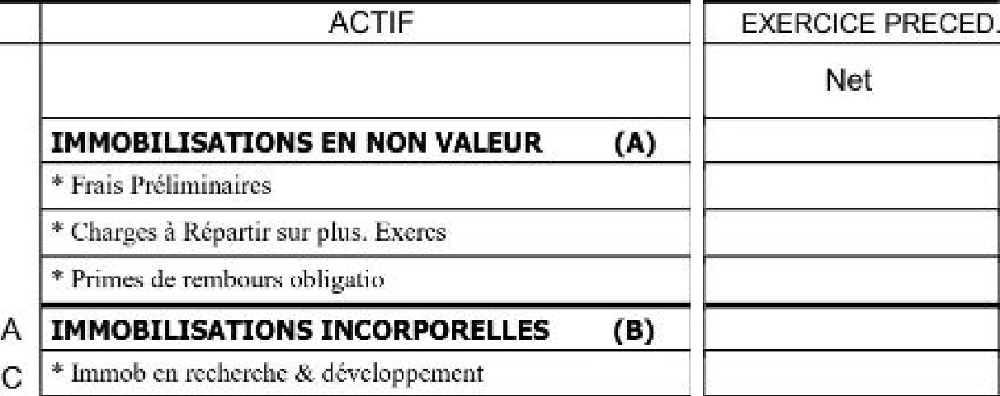


===== VERIFICATION DES CELLULES =====


,id_ligne,pixels_sombres,seuil,cellule_suspecte
0,1,474,40,True
1,2,0,25,False
2,3,0,25,False
3,4,0,27,False
4,5,0,27,False
5,6,0,25,False
6,7,0,25,False


ATTENTION : présence possible de chiffres ou de marques.
Vérifier visuellement le premier bloc.
Reconstruction suspendue.

Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


In [109]:

# ============================================================
# CORRECTION NET N-1 — SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
import numpy as np
from PIL import Image
from IPython.display import display

# 1. Afficher le bloc à vérifier
bloc = blocs_actif_finaux[0]

image = Image.open(
    bloc["images"]["net_N1"]
).convert("RGB")

print("===== IMAGE NET N-1 — BLOC 1 =====")
display(image)

# 2. Vérifier que Qwen n'avait extrait aucun montant
lignes_vlm = recuperer_lignes_json(resultat_bloc1_N1)

assert isinstance(lignes_vlm, list)
assert all(
    ligne.get("valeur") is None
    for ligne in lignes_vlm
), "Qwen avait détecté des montants : contrôle manuel nécessaire."

# 3. Examiner les pixels des cellules numériques
# ID 0 exclu : zone d'en-tête
largeur = image.width

x1 = int(largeur * 0.75)
x2 = int(largeur * 0.97)

diagnostic_pixels = []

for identifiant in range(1, 8):

    haut = int(limites_y[identifiant] - bloc["y1"])
    bas = int(limites_y[identifiant + 1] - bloc["y1"])

    hauteur_ligne = bas - haut

    # Écarter les bordures horizontales
    ya = haut + int(hauteur_ligne * 0.22)
    yb = bas - int(hauteur_ligne * 0.22)

    zone = image.crop((x1, ya, x2, yb))
    pixels = np.asarray(zone.convert("L"))

    pixels_sombres = int(np.count_nonzero(pixels < 110))
    seuil = max(12, int(pixels.size * 0.003))

    diagnostic_pixels.append({
        "id_ligne": identifiant,
        "pixels_sombres": pixels_sombres,
        "seuil": seuil,
        "cellule_suspecte": pixels_sombres > seuil
    })

df_diagnostic_pixels = pd.DataFrame(diagnostic_pixels)

print("\n===== VERIFICATION DES CELLULES =====")
display(df_diagnostic_pixels)

# 4. Reconstruire uniquement si aucune cellule
# numérique ne présente de contenu suspect
if df_diagnostic_pixels["cellule_suspecte"].any():

    print(
        "ATTENTION : présence possible de chiffres ou de marques."
    )
    print(
        "Vérifier visuellement le premier bloc."
    )
    print("Reconstruction suspendue.")

else:

    print("\nAucun contenu numérique détecté dans la zone contrôlée.")

    # Réutiliser les noms de postes de BRUT N
    reference = df_brut_ids.set_index("id_ligne")

    lignes_bloc1 = [
        {
            "id_ligne": i,
            "poste": reference.loc[i, "poste"],
            "net_N1": None,
            "poste_lu_vlm": ""
        }
        for i in range(8)
    ]

    resultats_net_N1_ids[1] = lignes_bloc1

    print("\n===== BLOC 1 RECONSTRUIT =====")
    display(pd.DataFrame(lignes_bloc1))

    # 5. Réutiliser les six blocs déjà extraits
    toutes_lignes = []

    for numero in range(1, 8):
        assert numero in resultats_net_N1_ids, (
            f"Bloc {numero} manquant"
        )

        toutes_lignes.extend(
            resultats_net_N1_ids[numero]
        )

    # 6. Construire le tableau complet
    candidat = pd.DataFrame(toutes_lignes)

    candidat = candidat.sort_values(
        "id_ligne"
    ).reset_index(drop=True)

    assert candidat["id_ligne"].tolist() == (
        df_brut_ids["id_ligne"].tolist()
    ), "IDs incomplets ou dupliqués."

    df_net_N1_ids = candidat

    print("\n===== NET N-1 — MONTANTS EXTRAITS =====")

    display(
        df_net_N1_ids[
            df_net_N1_ids["net_N1"].notna()
        ][["id_ligne", "poste", "net_N1"]]
    )

    print("\nNombre de lignes :", len(df_net_N1_ids))
    print(
        "Montants renseignés :",
        df_net_N1_ids["net_N1"].notna().sum()
    )

    # 7. Contrôle des totaux
    print("\n===== VERIFICATION DES TOTAUX =====")

    valeurs = df_net_N1_ids.set_index(
        "id_ligne"
    )["net_N1"]

    ids_totaux = [27, 46, 51, 52]

    display(
        df_net_N1_ids[
            df_net_N1_ids["id_ligne"].isin(ids_totaux)
        ][["id_ligne", "poste", "net_N1"]]
    )

    if valeurs.loc[ids_totaux].notna().all():

        somme = round(
            sum(float(valeurs.loc[i]) for i in [27, 46, 51]),
            2
        )

        total = round(float(valeurs.loc[52]), 2)
        ecart = round(somme - total, 2)

        print("Somme TOTAL I + II + III :", somme)
        print("TOTAL GENERAL NET N-1 :", total)
        print("Écart :", ecart)

        if abs(ecart) <= 0.01:
            print("CONTROLE ARITHMETIQUE : OK")
        else:
            print("CONTROLE ARITHMETIQUE : ECHEC")

    else:
        print("Contrôle impossible : un total manque.")

print("\nAucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")


===== IMAGE AVEC ZONES NUMERIQUES =====


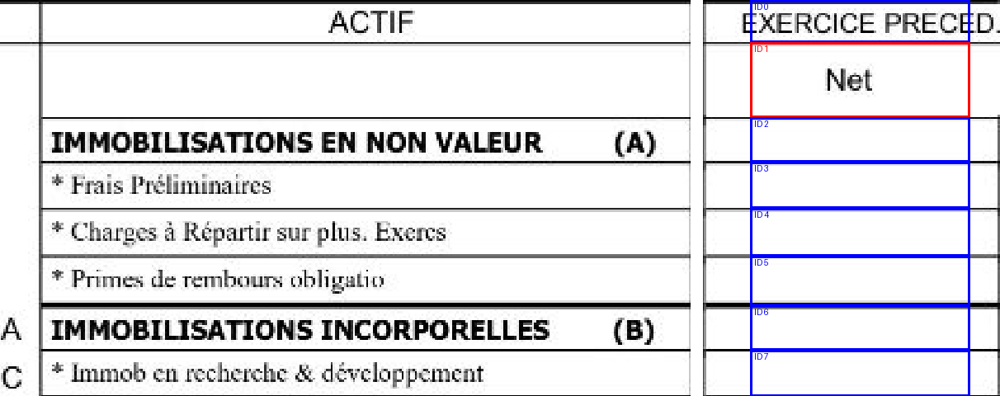


===== ID 1 : LIGNE COMPLETE =====


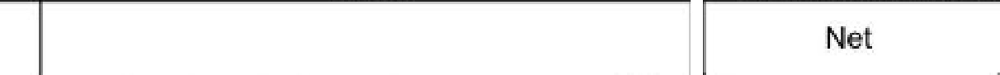


===== ID 1 : ZONE NUMERIQUE AGRANDIE =====


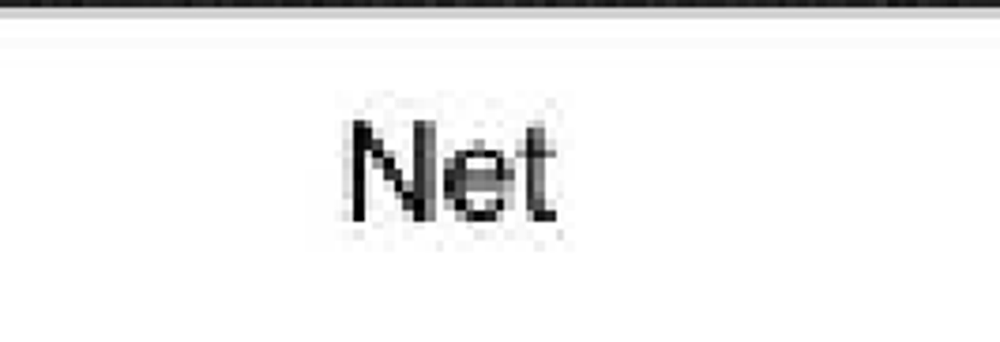


===== RESULTAT PRECEDENT =====


,id_ligne,pixels_sombres,seuil,cellule_suspecte
0,1,474,40,True
1,2,0,25,False
2,3,0,25,False
3,4,0,27,False
4,5,0,27,False
5,6,0,25,False
6,7,0,25,False



Aucune inférence Qwen effectuée.
Aucune modification des données.
Aucun CSV créé.


In [110]:
# ============================================================
# DIAGNOSTIC VISUEL NET N-1 — BLOC 1
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd

# 1. Charger l'image originale
bloc = blocs_actif_finaux[0]

image = Image.open(
    bloc["images"]["net_N1"]
).convert("RGB")

# 2. Délimiter la zone numérique examinée
largeur = image.width

x1 = int(largeur * 0.75)
x2 = int(largeur * 0.97)

image_annotee = image.copy()
dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

# 3. Afficher les zones examinées pour chaque ID
for identifiant in range(0, 8):

    haut = int(
        limites_y[identifiant] - bloc["y1"]
    )

    bas = int(
        limites_y[identifiant + 1] - bloc["y1"]
    )

    couleur = "red" if identifiant == 1 else "blue"

    dessin.rectangle(
        (x1, haut, x2, bas),
        outline=couleur,
        width=3
    )

    dessin.text(
        (x1 + 5, haut + 2),
        f"ID {identifiant}",
        fill=couleur,
        font=police
    )

print("===== IMAGE AVEC ZONES NUMERIQUES =====")
display(image_annotee)

# 4. Agrandir spécifiquement la zone suspecte ID 1
haut = int(limites_y[1] - bloc["y1"])
bas = int(limites_y[2] - bloc["y1"])

# Ligne complète
ligne_complete = image.crop(
    (0, haut, image.width, bas)
)

print("\n===== ID 1 : LIGNE COMPLETE =====")
display(ligne_complete.resize(
    (ligne_complete.width * 2, ligne_complete.height * 2)
))

# Partie numérique seulement
zone_numerique = image.crop(
    (x1, haut, x2, bas)
)

print("\n===== ID 1 : ZONE NUMERIQUE AGRANDIE =====")
display(zone_numerique.resize(
    (zone_numerique.width * 4, zone_numerique.height * 4)
))

print("\n===== RESULTAT PRECEDENT =====")
display(df_diagnostic_pixels)

print("\nAucune inférence Qwen effectuée.")
print("Aucune modification des données.")
print("Aucun CSV créé.")

In [111]:

# ============================================================
# CORRECTION DES IDs 0-7 + RECONSTRUCTION NET N-1
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
import math
from IPython.display import display

# 1. Vérifications préalables
assert len(df_brut_ids) == 53
assert len(df_amort_ids) == 53
assert len(df_net_N_ids) == 53

assert all(
    n in resultats_net_N1_ids
    for n in range(2, 8)
), "Un des blocs NET N-1 déjà extraits manque."

# 2. Correspondance corrigée à partir de l'image
postes_corriges = {
    0: "",
    1: "",
    2: "IMMOBILISATIONS EN NON VALEUR (A)",
    3: "* Frais Préliminaires",
    4: "* Charges à Répartir sur plus. Exercs",
    5: "* Primes de rembours obligatio",
    6: "IMMOBILISATIONS INCORPORELLES (B)",
    7: "* Immob en recherche & développement"
}

# 3. Vérifier que les premiers IDs ne portent
# aucun montant dans les trois colonnes déjà extraites
for df, colonne in [
    (df_brut_ids, "brut_N"),
    (df_amort_ids, "amortissements_provisions_N"),
    (df_net_N_ids, "net_N")
]:
    valeurs = df.set_index("id_ligne").loc[
        list(range(8)), colonne
    ]

    assert valeurs.isna().all(), (
        f"Montant détecté dans {colonne} "
        "pour les IDs 0 à 7. Correction suspendue."
    )

# 4. Corriger les postes sur les trois tableaux
for df in [df_brut_ids, df_amort_ids, df_net_N_ids]:

    for identifiant, poste in postes_corriges.items():
        df.loc[
            df["id_ligne"] == identifiant,
            "poste"
        ] = poste

# 5. Préparer le premier bloc NET N-1
# Les six cellules comptables sont visuellement vides.
lignes_bloc1 = [
    {
        "id_ligne": i,
        "poste": postes_corriges[i],
        "net_N1": None,
        "poste_lu_vlm": "",
        "origine": (
            "entete"
            if i in (0, 1)
            else "verification_visuelle"
        )
    }
    for i in range(8)
]

resultats_net_N1_ids[1] = lignes_bloc1

# 6. Reconstruire NET N-1 avec les 7 blocs
toutes_lignes = []

for bloc in blocs_actif_finaux:

    numero = bloc["numero_bloc"]

    lignes = resultats_net_N1_ids[numero]

    ids_attendus = list(range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ))

    assert [
        l["id_ligne"] for l in lignes
    ] == ids_attendus, (
        f"IDs incorrects dans le bloc {numero}"
    )

    toutes_lignes.extend(lignes)

df_net_N1_ids = pd.DataFrame(
    toutes_lignes
).sort_values(
    "id_ligne"
).reset_index(drop=True)

assert df_net_N1_ids["id_ligne"].tolist() == list(range(53))

# 7. Synchroniser les noms des postes
reference = df_brut_ids.set_index("id_ligne")["poste"]

df_net_N1_ids["poste"] = (
    df_net_N1_ids["id_ligne"].map(reference)
)

# 8. Afficher la reconstruction
print("===== PREMIER BLOC CORRIGE =====")
display(
    df_net_N1_ids[
        df_net_N1_ids["id_ligne"] <= 7
    ][["id_ligne", "poste", "net_N1"]]
)

print("\n===== NET N-1 — MONTANTS EXTRAITS =====")
display(
    df_net_N1_ids[
        df_net_N1_ids["net_N1"].notna()
    ][["id_ligne", "poste", "net_N1"]]
)

print("\n===== STATISTIQUES =====")
print("Nombre de positions :", len(df_net_N1_ids))
print(
    "Nombre de montants :",
    df_net_N1_ids["net_N1"].notna().sum()
)

# 9. Vérifier les totaux comptables
print("\n===== VERIFICATION DES TOTAUX N-1 =====")

totaux = df_net_N1_ids.set_index("id_ligne")["net_N1"]

ids_totaux = [27, 46, 51, 52]

display(
    df_net_N1_ids[
        df_net_N1_ids["id_ligne"].isin(ids_totaux)
    ][["id_ligne", "poste", "net_N1"]]
)

if totaux.loc[ids_totaux].notna().all():

    from decimal import Decimal

    def montant_decimal(x):
        return Decimal(str(x)).quantize(Decimal("0.01"))

    somme = sum(
        [montant_decimal(totaux.loc[i]) for i in [27, 46, 51]],
        Decimal("0.00")
    )

    total = montant_decimal(totaux.loc[52])
    ecart = somme - total

    print("\nSomme TOTAL I + II + III :", somme)
    print("TOTAL GENERAL :", total)
    print("Ecart :", ecart)

    if abs(ecart) <= Decimal("0.01"):
        print("CONTROLE ARITHMETIQUE : OK")
    else:
        print("CONTROLE ARITHMETIQUE : ECHEC")

else:
    print("Contrôle impossible : un total est manquant.")

print("\nAucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")


===== PREMIER BLOC CORRIGE =====


,id_ligne,poste,net_N1
0,0,,NaN
1,1,,NaN
2,2,IMMOBILISATIONS EN NON VALEUR (A),NaN
3,3,* Frais Préliminaires,NaN
4,4,* Charges à Répartir sur plus. Exercs,NaN
5,5,* Primes de rembours obligatio,NaN
6,6,IMMOBILISATIONS INCORPORELLES (B),NaN
7,7,* Immob en recherche & développement,NaN



===== NET N-1 — MONTANTS EXTRAITS =====


,id_ligne,poste,net_N1
11,11,IMMOBILISATIONS CORPORELLES (C),5684516.83
15,15,* Matériel de transport,5684516.83
27,27,TOTAL I (A+B+C+D+E),5684516.83
34,34,CREANCES DE L'ACTIF CIRCULANT (G),714881.74
38,38,* Etat - débiteur,714881.74
46,46,TOTAL II (F+G+H+I),714881.74
47,47,TRESORERIE - ACTIF,35826.29
49,49,* Banq.trésor gener.& chq p dbt,2515.24
50,50,"* Caisse, régis d'avanc & accredi",33311.05
51,51,TOTAL III,35826.29



===== STATISTIQUES =====
Nombre de positions : 53
Nombre de montants : 11

===== VERIFICATION DES TOTAUX N-1 =====


,id_ligne,poste,net_N1
27,27,TOTAL I (A+B+C+D+E),5684516.83
46,46,TOTAL II (F+G+H+I),714881.74
51,51,TOTAL III,35826.29
52,52,TOTAL GENERAL (I+II+III),6435224.86



Somme TOTAL I + II + III : 6435224.86
TOTAL GENERAL : 6435224.86
Ecart : 0.00
CONTROLE ARITHMETIQUE : OK

Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


In [112]:

# ============================================================
# FUSION DES 4 COLONNES ACTIF + CONTROLES COMPTABLES
# SANS NOUVELLE INFERENCE QWEN
# SANS EXPORT CSV
# ============================================================

import pandas as pd
from decimal import Decimal
from IPython.display import display

# ------------------------------------------------------------
# 1. VERIFIER LES TABLEAUX EXISTANTS
# ------------------------------------------------------------

sources = [
    ("BRUT N", df_brut_ids, "brut_N"),
    ("AMORT N", df_amort_ids, "amortissements_provisions_N"),
    ("NET N", df_net_N_ids, "net_N"),
    ("NET N-1", df_net_N1_ids, "net_N1")
]

ids_reference = list(range(53))

for nom, df, colonne in sources:

    assert {"id_ligne", colonne}.issubset(df.columns), nom
    assert df["id_ligne"].is_unique, f"IDs dupliques : {nom}"
    assert sorted(df["id_ligne"].tolist()) == ids_reference, (
        f"IDs incomplets : {nom}"
    )

    print(f"{nom} : OK | {len(df)} positions")

# ------------------------------------------------------------
# 2. FUSION SUR L'IDENTIFIANT PHYSIQUE
# ------------------------------------------------------------

df_actif_avec_ids = df_brut_ids[
    ["id_ligne", "poste", "brut_N"]
].copy()

for _, df, colonne in sources[1:]:

    df_actif_avec_ids = df_actif_avec_ids.merge(
        df[["id_ligne", colonne]],
        on="id_ligne",
        how="left",
        validate="one_to_one"
    )

df_actif_avec_ids = (
    df_actif_avec_ids
    .sort_values("id_ligne")
    .reset_index(drop=True)
)

colonnes_numeriques = [
    "brut_N",
    "amortissements_provisions_N",
    "net_N",
    "net_N1"
]

for colonne in colonnes_numeriques:
    df_actif_avec_ids[colonne] = pd.to_numeric(
        df_actif_avec_ids[colonne],
        errors="raise"
    )

# Retirer uniquement les 2 en-tetes verifies
df_actif_complet = df_actif_avec_ids[
    df_actif_avec_ids["id_ligne"] >= 2
].copy().reset_index(drop=True)

assert len(df_actif_complet) == 51
assert df_actif_complet["poste"].str.strip().ne("").all()

print("\n===== ACTIF COMPLET : 51 LIGNES =====")
display(df_actif_complet)

# ------------------------------------------------------------
# 3. PREPARER LES CONTROLES COMPTABLES
# ------------------------------------------------------------

def montant(x):
    if pd.isna(x):
        return None
    return Decimal(str(x)).quantize(Decimal("0.01"))

index = df_actif_avec_ids.set_index("id_ligne")

controles = []

def ajouter_controle(nom, calcule, observe):

    if calcule is None or observe is None:
        statut = "NON VERIFIABLE"
        ecart = None
    else:
        ecart = calcule - observe
        statut = "OK" if abs(ecart) <= Decimal("0.01") else "ECHEC"

    controles.append({
        "controle": nom,
        "calcule": calcule,
        "observe": observe,
        "ecart": ecart,
        "statut": statut
    })

# ------------------------------------------------------------
# 4. VERIFIER BRUT - AMORT = NET
# ------------------------------------------------------------

for _, ligne in df_actif_complet.iterrows():

    brut = montant(ligne["brut_N"])
    amort = montant(ligne["amortissements_provisions_N"])
    net = montant(ligne["net_N"])

    if brut is not None and amort is not None and net is not None:

        ajouter_controle(
            f"ID {ligne['id_ligne']} : BRUT - AMORT = NET",
            brut - amort,
            net
        )

# ------------------------------------------------------------
# 5. VERIFIER TOTAL I + II + III = TOTAL GENERAL
# ------------------------------------------------------------

for colonne in ["brut_N", "net_N", "net_N1"]:

    valeurs = [
        montant(index.loc[i, colonne])
        for i in [27, 46, 51]
    ]

    total_general = montant(index.loc[52, colonne])

    somme = (
        sum(valeurs, Decimal("0.00"))
        if all(v is not None for v in valeurs)
        else None
    )

    ajouter_controle(
        f"{colonne} : TOTAL I + II + III",
        somme,
        total_general
    )

# ------------------------------------------------------------
# 6. VERIFIER LES SOUS-TOTAUX DE TRESORERIE
# ------------------------------------------------------------

for colonne in ["brut_N", "net_N", "net_N1"]:

    banque = montant(index.loc[49, colonne])
    caisse = montant(index.loc[50, colonne])
    tresorerie = montant(index.loc[47, colonne])
    total_III = montant(index.loc[51, colonne])

    ajouter_controle(
        f"{colonne} : BANQUE + CAISSE",
        banque + caisse
        if banque is not None and caisse is not None
        else None,
        tresorerie
    )

    ajouter_controle(
        f"{colonne} : TRESORERIE = TOTAL III",
        tresorerie,
        total_III
    )

# ------------------------------------------------------------
# 7. AFFICHER LES CONTROLES
# ------------------------------------------------------------

df_controles_actif = pd.DataFrame(controles)

print("\n===== CONTROLES COMPTABLES =====")
display(df_controles_actif)

echecs = df_controles_actif[
    df_controles_actif["statut"] == "ECHEC"
]

non_verifiables = df_controles_actif[
    df_controles_actif["statut"] == "NON VERIFIABLE"
]

# Identifier les comparaisons avec amortissement vide
amort_non_renseignes = df_actif_complet[
    df_actif_complet["brut_N"].notna()
    & df_actif_complet["net_N"].notna()
    & df_actif_complet[
        "amortissements_provisions_N"
    ].isna()
]

print("\n===== RESUME =====")

print("Lignes comptables :", len(df_actif_complet))
print("Controles OK :", (df_controles_actif["statut"] == "OK").sum())
print("Controles en echec :", len(echecs))
print("Controles impossibles :", len(non_verifiables))

print(
    "Lignes BRUT/NET avec amortissement vide :",
    len(amort_non_renseignes)
)

print("\n===== TOTAUX GENERAUX EXTRAITS =====")

display(
    df_actif_complet[
        df_actif_complet["id_ligne"] == 52
    ]
)

if echecs.empty and non_verifiables.empty:

    print("\nCONTROLES ARITHMETIQUES DISPONIBLES : OK")
    print("Verification visuelle des cellules : encore necessaire")

else:

    print("\nATTENTION : controles a examiner.")
    display(pd.concat([echecs, non_verifiables]))

print("\nDataFrame cree : df_actif_complet")
print("Aucun CSV final cree.")


BRUT N : OK | 53 positions
AMORT N : OK | 53 positions
NET N : OK | 53 positions
NET N-1 : OK | 53 positions

===== ACTIF COMPLET : 51 LIGNES =====


,id_ligne,poste,brut_N,amortissements_provisions_N,net_N,net_N1
0,2,IMMOBILISATIONS EN NON VALEUR (A),NaN,NaN,NaN,NaN
1,3,* Frais Préliminaires,NaN,NaN,NaN,NaN
2,4,* Charges à Répartir sur plus. Exercs,NaN,NaN,NaN,NaN
3,5,* Primes de rembours obligatio,NaN,NaN,NaN,NaN
4,6,IMMOBILISATIONS INCORPORELLES (B),NaN,NaN,NaN,NaN
5,7,* Immob en recherche & développement,NaN,NaN,NaN,NaN
6,8,"* Brevets, marques droits & val.sim",NaN,NaN,NaN,NaN
7,9,* Fond commercial,NaN,NaN,NaN,NaN
8,10,* Autres immobilis incorporelles,NaN,NaN,NaN,NaN
9,11,IMMOBILISATIONS CORPORELLES (C),6381126.16,1972834.33,4408291.83,5684516.83



===== CONTROLES COMPTABLES =====


,controle,calcule,observe,ecart,statut
0,ID 11 : BRUT - AMORT = NET,4408291.83,4408291.83,0.00,OK
1,ID 15 : BRUT - AMORT = NET,4408291.83,4408291.83,0.00,OK
2,ID 27 : BRUT - AMORT = NET,4408291.83,4408291.83,0.00,OK
3,ID 52 : BRUT - AMORT = NET,5375489.44,5375489.44,0.00,OK
4,brut_N : TOTAL I + II + III,7348323.77,7348323.77,0.00,OK
5,net_N : TOTAL I + II + III,5375489.44,5375489.44,0.00,OK
6,net_N1 : TOTAL I + II + III,6435224.86,6435224.86,0.00,OK
7,brut_N : BANQUE + CAISSE,152315.87,152315.87,0.00,OK
8,brut_N : TRESORERIE = TOTAL III,152315.87,152315.87,0.00,OK
9,net_N : BANQUE + CAISSE,152315.87,152315.87,0.00,OK



===== RESUME =====
Lignes comptables : 51
Controles OK : 13
Controles en echec : 0
Controles impossibles : 0
Lignes BRUT/NET avec amortissement vide : 8

===== TOTAUX GENERAUX EXTRAITS =====


,id_ligne,poste,brut_N,amortissements_provisions_N,net_N,net_N1
50,52,TOTAL GENERAL (I+II+III),7348323.77,1972834.33,5375489.44,6435224.86



CONTROLES ARITHMETIQUES DISPONIBLES : OK
Verification visuelle des cellules : encore necessaire

DataFrame cree : df_actif_complet
Aucun CSV final cree.


===== PAGE PASSIF =====
Dimensions : (2478, 3500)


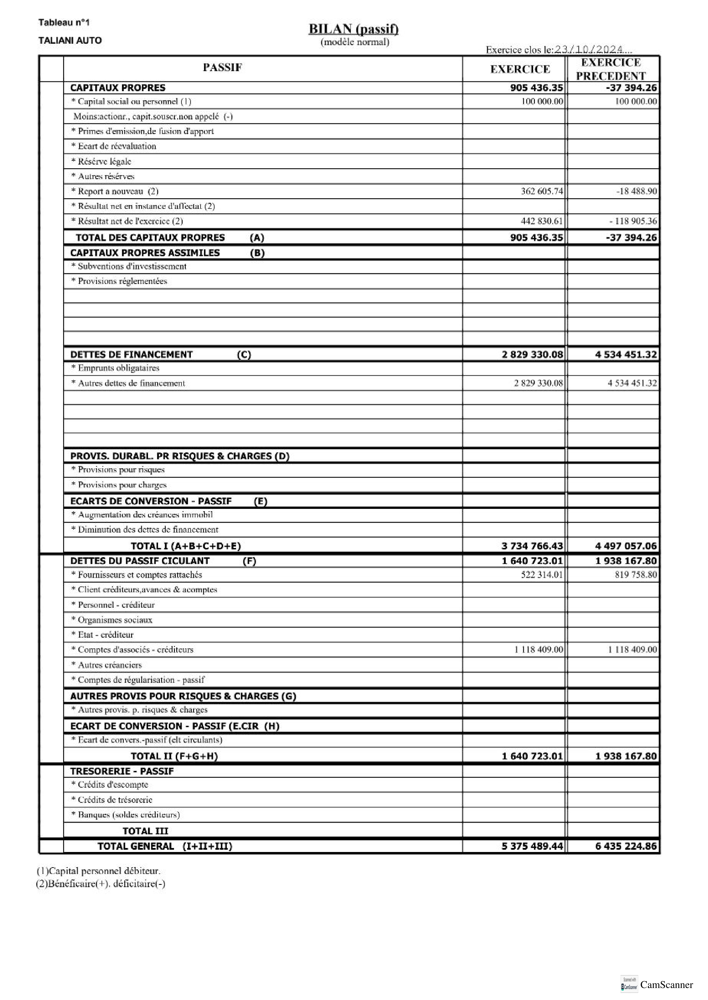


===== COLONNES PASSIF DETECTEES =====

Colonne : montant_N
Chemin : /kaggle/working/colonnes_dynamiques/PASSIF_montant_N.png
Dimensions : (1819, 3500)


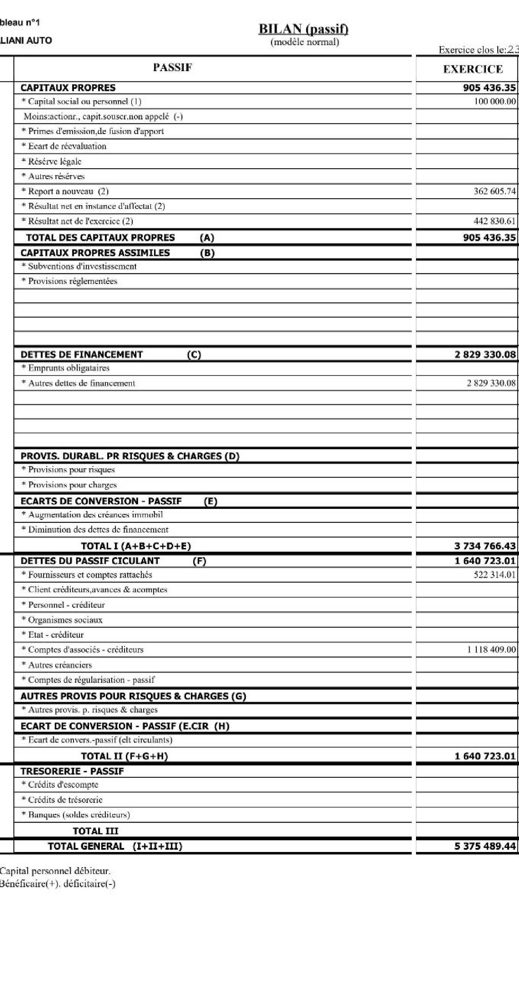


Colonne : montant_N1
Chemin : /kaggle/working/colonnes_dynamiques/PASSIF_montant_N1.png
Dimensions : (1780, 3500)


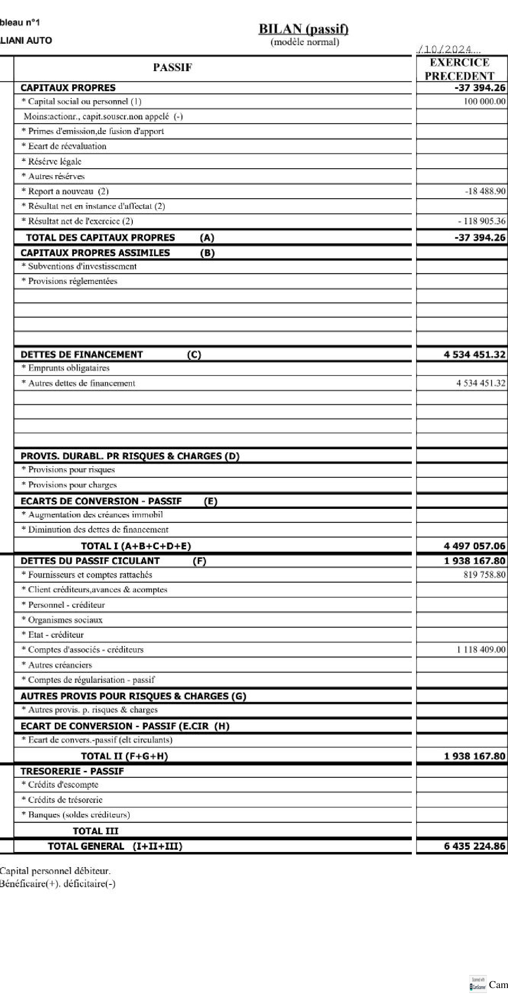


===== COORDONNEES OPENCV =====
Entrées disponibles : ['ACTIF', 'PASSIF']
PASSIF : [{'nom': 'poste', 'x1': 223, 'x2': 1619}, {'nom': 'montant_N', 'x1': 1619, 'x2': 1984}, {'nom': 'montant_N1', 'x1': 1984, 'x2': 2310}]

Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


In [113]:

# ============================================================
# BILAN PASSIF — INSPECTION DES IMAGES ET COLONNES
# SANS INFERENCE QWEN
# ============================================================

from pathlib import Path
from PIL import Image
from IPython.display import display

# 1. Charger la page PASSIF
chemin_passif = Path(
    "/kaggle/working/images/page_2.png"
)

assert chemin_passif.exists(), (
    "Image PASSIF introuvable."
)

image_passif = Image.open(
    chemin_passif
).convert("RGB")

print("===== PAGE PASSIF =====")
print("Dimensions :", image_passif.size)

# Afficher la page entière
display(image_passif)

# 2. Vérifier les colonnes déjà découpées
assert "images_colonnes_passif" in globals(), (
    "La variable images_colonnes_passif "
    "est introuvable."
)

assert isinstance(images_colonnes_passif, dict), (
    "Format des colonnes PASSIF inattendu."
)

print("\n===== COLONNES PASSIF DETECTEES =====")

for nom, chemin in images_colonnes_passif.items():

    fichier = Path(chemin)

    print("\nColonne :", nom)
    print("Chemin :", fichier)

    assert fichier.exists(), (
        f"Image introuvable : {fichier}"
    )

    image_colonne = Image.open(
        fichier
    ).convert("RGB")

    print("Dimensions :", image_colonne.size)

    display(image_colonne)

# 3. Afficher les coordonnées détectées
if "coordonnees_detectees" in globals():

    print("\n===== COORDONNEES OPENCV =====")

    if isinstance(coordonnees_detectees, dict):
        print(
            "Entrées disponibles :",
            list(coordonnees_detectees.keys())
        )

        for cle, valeur in coordonnees_detectees.items():
            if "passif" in str(cle).lower():
                print(cle, ":", valeur)

print("\nAucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")


===== COLONNES PASSIF =====
montant_N : (1819, 3500)
montant_N1 : (1780, 3500)

Colonne de référence : montant_N
Dimensions : 1819 x 3500

===== RESULTAT OPENCV =====
Lignes horizontales détectées : 54
Intervalles obtenus : 55
Premières limites : [0, 193, 284, 327, 378, 431, 485, 536, 589, 643, 694, 747]
Dernières limites : [2457, 2507, 2561, 2615, 2668, 2719, 2770, 2824, 2877, 2931, 2984, 3500]

===== PASSIF AVEC IDs =====


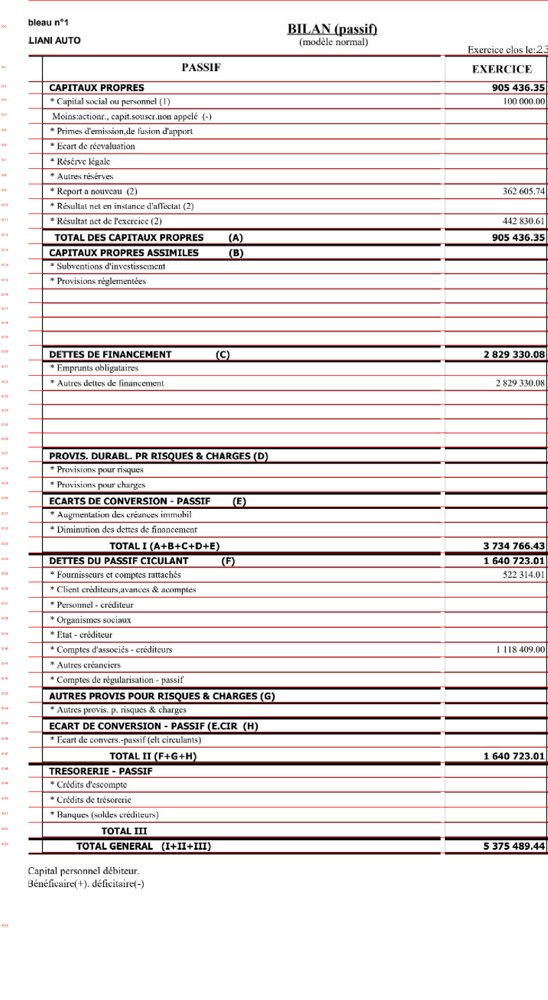


===== AGRANDISSEMENT : HAUT =====


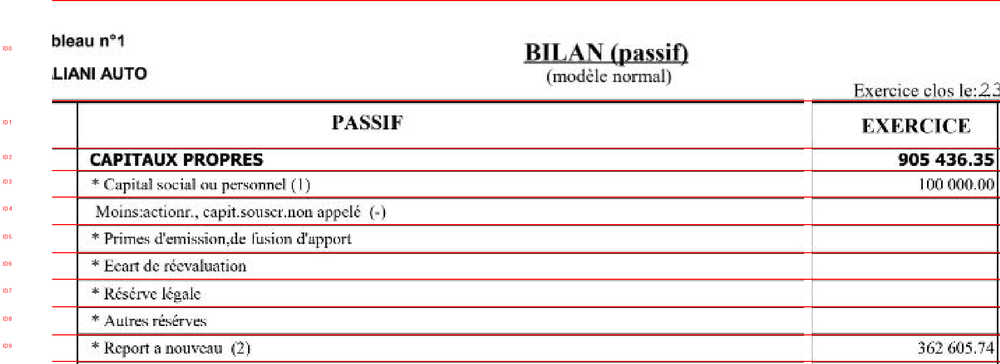


===== AGRANDISSEMENT : BAS =====


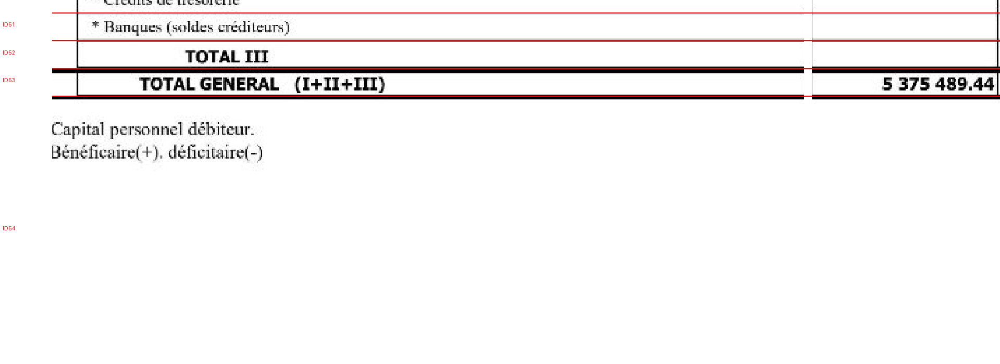


Aucune inférence Qwen.
Aucun CSV final créé.


In [114]:

# ============================================================
# PASSIF — DETECTION AUTOMATIQUE DES LIGNES AVEC OPENCV
# ============================================================

import cv2
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display

# 1. Vérifier les images PASSIF déjà générées
assert "images_colonnes_passif" in globals()
assert len(images_colonnes_passif) == 2

print("===== COLONNES PASSIF =====")

dimensions = {}

for nom, chemin in images_colonnes_passif.items():
    img = Image.open(chemin).convert("RGB")
    dimensions[nom] = img.size
    print(nom, ":", img.size)

# 2. Prendre la colonne la plus large comme référence
colonne_reference_passif = max(
    dimensions,
    key=lambda nom: dimensions[nom][0]
)

image_reference = Image.open(
    images_colonnes_passif[colonne_reference_passif]
).convert("RGB")

image_cv = np.array(image_reference)
gris = cv2.cvtColor(image_cv, cv2.COLOR_RGB2GRAY)

hauteur, largeur = gris.shape

print("\nColonne de référence :", colonne_reference_passif)
print("Dimensions :", largeur, "x", hauteur)

# Vérifier que les deux images ont la même hauteur
assert len({
    taille[1] for taille in dimensions.values()
}) == 1, "Les deux colonnes PASSIF ne sont pas alignées."

# 3. Binarisation
_, binaire = cv2.threshold(
    gris,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# 4. Détection des grandes lignes horizontales
largeur_noyau = max(40, int(largeur * 0.20))

noyau_horizontal = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (largeur_noyau, 1)
)

lignes_horizontales = cv2.morphologyEx(
    binaire,
    cv2.MORPH_OPEN,
    noyau_horizontal
)

# 5. Calculer le profil horizontal
profil = np.count_nonzero(
    lignes_horizontales,
    axis=1
)

seuil = max(30, int(largeur * 0.30))

candidats = np.where(profil >= seuil)[0]

# 6. Regrouper les détections proches
groupes = []

for y in candidats:
    y = int(y)

    if not groupes or y - groupes[-1][-1] > 5:
        groupes.append([y])
    else:
        groupes[-1].append(y)

positions = [
    max(groupe, key=lambda y: profil[y])
    for groupe in groupes
]

# 7. Éviter les lignes doubles
distance_min = max(10, int(hauteur * 0.004))

positions_filtrees = []

for y in positions:

    if (
        positions_filtrees
        and y - positions_filtrees[-1] < distance_min
    ):
        precedent = positions_filtrees[-1]

        if profil[y] > profil[precedent]:
            positions_filtrees[-1] = y
    else:
        positions_filtrees.append(y)

# 8. Ajouter les bornes de l'image
limites_y_passif = sorted(set(
    [0] + positions_filtrees + [hauteur]
))

print("\n===== RESULTAT OPENCV =====")
print("Lignes horizontales détectées :", len(positions_filtrees))
print("Intervalles obtenus :", len(limites_y_passif) - 1)

print("Premières limites :", limites_y_passif[:12])
print("Dernières limites :", limites_y_passif[-12:])

# 9. Annoter l'image
marge = 100

image_annotee = Image.new(
    "RGB",
    (largeur + marge, hauteur),
    "white"
)

image_annotee.paste(image_reference, (marge, 0))
dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype("DejaVuSans-Bold.ttf", 17)
except OSError:
    police = ImageFont.load_default()

for i in range(len(limites_y_passif) - 1):

    y1 = limites_y_passif[i]
    y2 = limites_y_passif[i + 1]

    dessin.line(
        (marge, y1, largeur + marge, y1),
        fill="red",
        width=2
    )

    centre = (y1 + y2) // 2

    dessin.text(
        (5, max(0, centre - 9)),
        f"ID {i}",
        fill="red",
        font=police
    )

# 10. Enregistrer et afficher
dossier = Path("/kaggle/working/passif_opencv")
dossier.mkdir(parents=True, exist_ok=True)

chemin_annote = dossier / "passif_lignes_detectees.png"
image_annotee.save(chemin_annote)

print("\n===== PASSIF AVEC IDs =====")
display(image_annotee)

print("\n===== AGRANDISSEMENT : HAUT =====")
display(image_annotee.crop(
    (0, 0, image_annotee.width, min(700, hauteur))
))

print("\n===== AGRANDISSEMENT : BAS =====")
display(image_annotee.crop(
    (0, max(0, hauteur - 700), image_annotee.width, hauteur)
))

print("\nAucune inférence Qwen.")
print("Aucun CSV final créé.")


===== STRUCTURE PASSIF =====
Colonnes : ['montant_N', 'montant_N1']
Nombre d'intervalles : 55

===== BLOCS PASSIF CREES =====
Bloc 01 | IDs 0 à 7 | Y 0 à 589
Bloc 02 | IDs 8 à 15 | Y 589 à 1010
Bloc 03 | IDs 16 à 23 | Y 1010 à 1414
Bloc 04 | IDs 24 à 31 | Y 1414 à 1827
Bloc 05 | IDs 32 à 39 | Y 1827 à 2248
Bloc 06 | IDs 40 à 47 | Y 2248 à 2668
Bloc 07 | IDs 48 à 54 | Y 2668 à 3500

Nombre de blocs : 7
Total des IDs : 55

===== PREMIER BLOC — montant_N =====


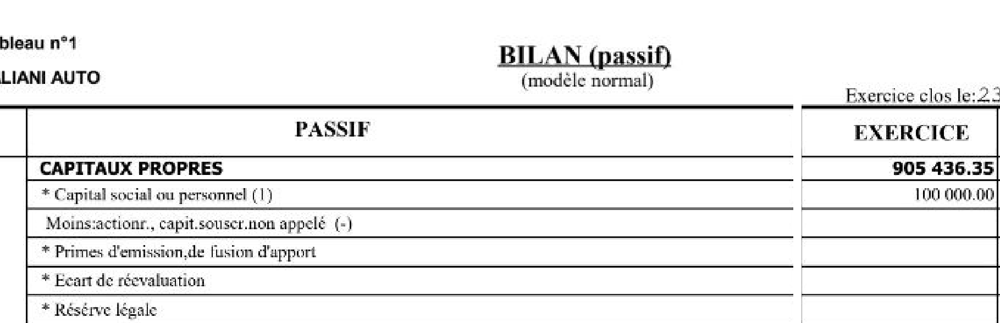


===== DERNIER BLOC — montant_N =====


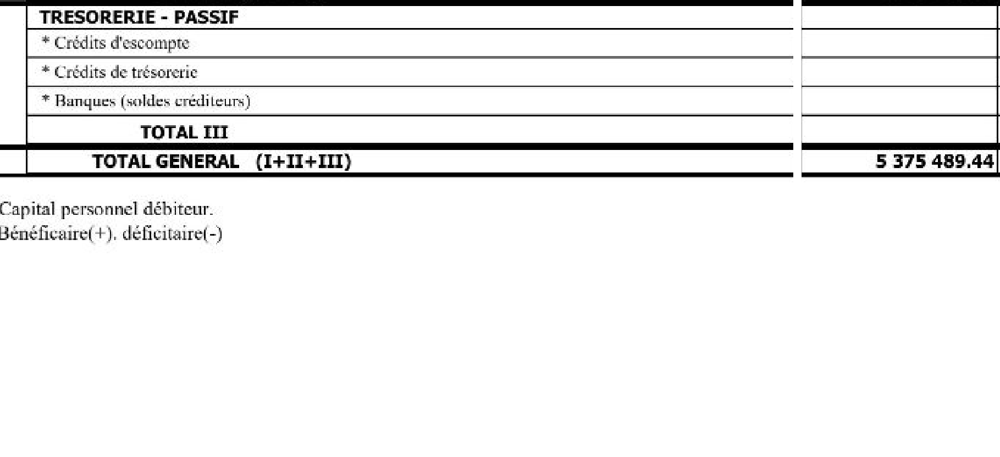


===== PREMIER BLOC — montant_N1 =====


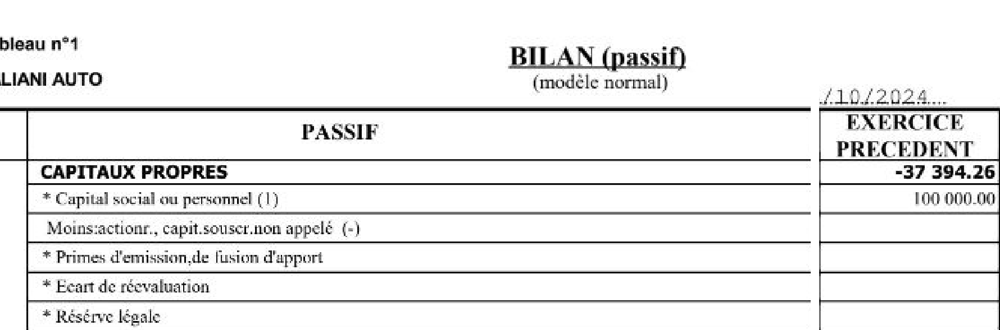


===== DERNIER BLOC — montant_N1 =====


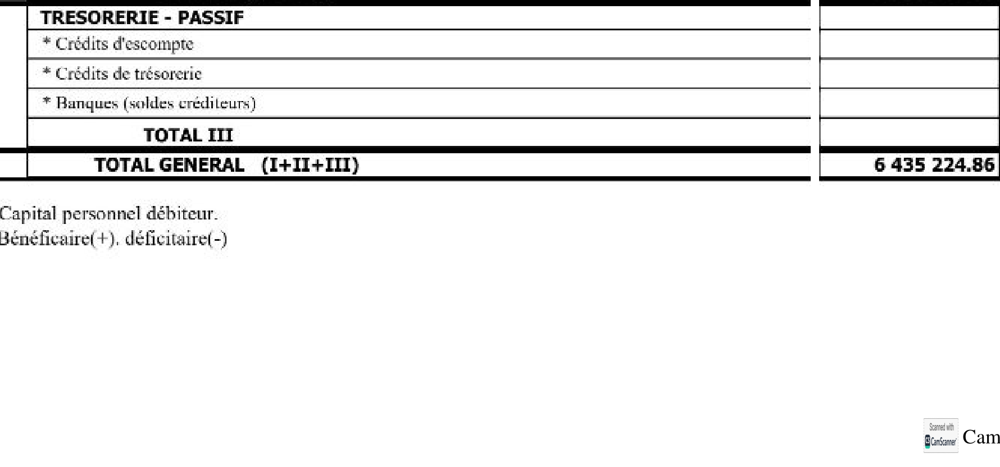


Découpage PASSIF terminé.
Aucune inférence Qwen effectuée.
Aucun CSV final créé.


In [115]:

# ============================================================
# PASSIF — CREATION DES BLOCS AVEC IDs COMMUNS
# SANS INFERENCE QWEN
# ============================================================

from pathlib import Path
from PIL import Image
from IPython.display import display

# 1. Vérification des variables OpenCV
assert "limites_y_passif" in globals(), (
    "Exécuter d'abord la détection des lignes PASSIF."
)

assert "images_colonnes_passif" in globals()

assert len(images_colonnes_passif) == 2

# 2. Configuration
LIGNES_PAR_BLOC_PASSIF = 8

dossier_blocs_passif = Path(
    "/kaggle/working/blocs_passif_final"
)

dossier_blocs_passif.mkdir(
    parents=True,
    exist_ok=True
)

# 3. Charger les deux colonnes
images_passif = {
    nom: Image.open(chemin).convert("RGB")
    for nom, chemin in images_colonnes_passif.items()
}

hauteurs = [img.height for img in images_passif.values()]

assert len(set(hauteurs)) == 1, (
    "Les hauteurs des colonnes PASSIF sont différentes."
)

hauteur = hauteurs[0]

# 4. Vérifier les limites
limites_y_passif = sorted(
    set(int(y) for y in limites_y_passif)
)

assert limites_y_passif[0] == 0
assert limites_y_passif[-1] == hauteur

nombre_intervalles = len(limites_y_passif) - 1

print("===== STRUCTURE PASSIF =====")
print("Colonnes :", list(images_passif.keys()))
print("Nombre d'intervalles :", nombre_intervalles)

# 5. Construire les blocs sans chevauchement
blocs_passif_finaux = []

for debut in range(
    0,
    nombre_intervalles,
    LIGNES_PAR_BLOC_PASSIF
):

    fin = min(
        debut + LIGNES_PAR_BLOC_PASSIF,
        nombre_intervalles
    )

    y1 = limites_y_passif[debut]
    y2 = limites_y_passif[fin]

    numero = len(blocs_passif_finaux) + 1

    infos_bloc = {
        "numero_bloc": numero,
        "ligne_debut": debut,
        "ligne_fin": fin - 1,
        "y1": y1,
        "y2": y2,
        "images": {}
    }

    for nom, image in images_passif.items():

        bloc_image = image.crop(
            (0, y1, image.width, y2)
        )

        chemin = dossier_blocs_passif / (
            f"bloc_{numero:02d}_{nom}.png"
        )

        bloc_image.save(chemin)

        infos_bloc["images"][nom] = str(chemin)

    blocs_passif_finaux.append(infos_bloc)

# 6. Vérifier la couverture des IDs
tous_ids = []

for bloc in blocs_passif_finaux:

    tous_ids.extend(
        range(
            bloc["ligne_debut"],
            bloc["ligne_fin"] + 1
        )
    )

assert tous_ids == list(range(nombre_intervalles)), (
    "Erreur : IDs manquants ou dupliqués."
)

# 7. Résumé
print("\n===== BLOCS PASSIF CREES =====")

for bloc in blocs_passif_finaux:

    print(
        f"Bloc {bloc['numero_bloc']:02d} | "
        f"IDs {bloc['ligne_debut']} à "
        f"{bloc['ligne_fin']} | "
        f"Y {bloc['y1']} à {bloc['y2']}"
    )

print("\nNombre de blocs :", len(blocs_passif_finaux))
print("Total des IDs :", len(tous_ids))

# 8. Afficher les premiers et derniers blocs
premier = blocs_passif_finaux[0]
dernier = blocs_passif_finaux[-1]

for nom in images_passif:

    print(f"\n===== PREMIER BLOC — {nom} =====")

    display(
        Image.open(premier["images"][nom])
    )

    print(f"\n===== DERNIER BLOC — {nom} =====")

    display(
        Image.open(dernier["images"][nom])
    )

print("\nDécoupage PASSIF terminé.")
print("Aucune inférence Qwen effectuée.")
print("Aucun CSV final créé.")


Colonnes disponibles : ['montant_N', 'montant_N1']
Colonne sélectionnée : montant_N

===== IMAGE NUMEROTEE =====


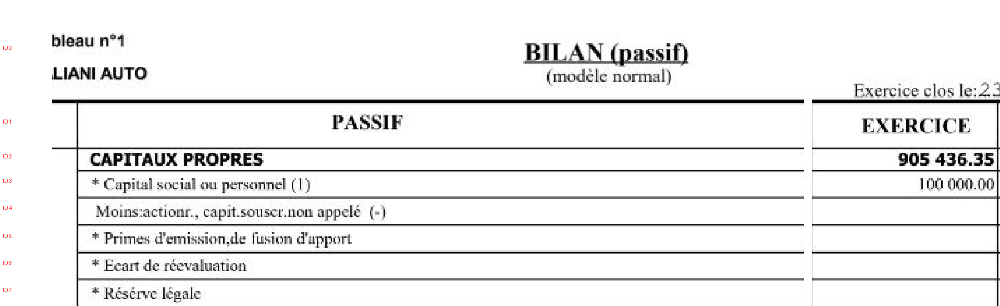

IDs attendus : [0, 1, 2, 3, 4, 5, 6, 7]

===== RESULTAT QWEN =====
Statut initial : OK
Tokens : 210

STRUCTURE JSON NON VALIDEE

Réponse brute :
```json
{
  "type_bilan": "PASSIF",
  "lignes": [
    {
      "id_ligne": 0,
      "poste": "CAPITAUX PROPRES"
    },
    {
      "id_ligne": 1,
      "poste": "* Capital social ou personnel (1)",
      "valeur": 100000.00
    },
    {
      "id_ligne": 2,
      "poste": "Moins:actionn., capit.souscr.non appelé (-)"
    },
    {
      "id_ligne": 3,
      "poste": "* Primes d'émission,de fusion d'apport"
    },
    {
      "id_ligne": 4,
      "poste": "* Écart de réévaluation"
    },
    {
      "id_ligne": 5,
      "poste": "* Réserve légale"
    }
  ]
}
```

Aucun CSV final créé.


In [117]:

# ============================================================
# PASSIF — EXTRACTION DU PREMIER BLOC, EXERCICE N
# OpenCV + Qwen2.5-VL
# ============================================================

import json
import re
import math
import pandas as pd

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 1. Récupérer le premier bloc PASSIF
assert "blocs_passif_finaux" in globals()
assert len(blocs_passif_finaux) > 0

bloc = blocs_passif_finaux[0]

# 2. Identifier la colonne Exercice N
colonnes_disponibles = list(bloc["images"].keys())

print("Colonnes disponibles :", colonnes_disponibles)

def est_colonne_N1(nom):
    return bool(re.search(
        r"n[_\-\s]?1|preced|précéd|previous",
        nom,
        flags=re.IGNORECASE
    ))

colonnes_N = [
    nom for nom in colonnes_disponibles
    if not est_colonne_N1(nom)
]

assert len(colonnes_N) == 1, (
    "Impossible d'identifier automatiquement "
    "la colonne N. Vérifier les noms affichés."
)

colonne_N = colonnes_N[0]

print("Colonne sélectionnée :", colonne_N)

# 3. Charger l'image du premier bloc
image = Image.open(
    bloc["images"][colonne_N]
).convert("RGB")

ids_attendus = list(range(
    bloc["ligne_debut"],
    bloc["ligne_fin"] + 1
))

# 4. Ajouter une marge pour les IDs
marge = 100

image_annotee = Image.new(
    "RGB",
    (image.width + marge, image.height),
    "white"
)

image_annotee.paste(image, (marge, 0))

dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

for identifiant in ids_attendus:

    haut = int(
        limites_y_passif[identifiant] - bloc["y1"]
    )

    bas = int(
        limites_y_passif[identifiant + 1] - bloc["y1"]
    )

    centre = (haut + bas) // 2

    dessin.text(
        (5, max(0, centre - 10)),
        f"ID {identifiant}",
        fill="red",
        font=police
    )

# 5. Enregistrer et afficher
dossier = Path(
    "/kaggle/working/passif_numerote"
)

dossier.mkdir(
    parents=True,
    exist_ok=True
)

chemin = dossier / "bloc_01_exercice_N.png"
image_annotee.save(chemin)

print("\n===== IMAGE NUMEROTEE =====")
display(image_annotee)

print("IDs attendus :", ids_attendus)

# 6. Construire le prompt Qwen
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris fidèlement ce bloc du bilan PASSIF.

Chaque ID rouge représente un intervalle horizontal.

IDs attendus : {ids_attendus}

La colonne gauche contient les postes comptables.
La colonne droite contient les montants
de l'EXERCICE N.

Pour chaque ID, retourne :
- id_ligne : numéro rouge
- poste : texte réellement visible à gauche
- valeur : montant visible à droite ou null

REGLES :
1. Exactement une entrée par ID.
2. Respecte l'ordre des IDs.
3. Conserve les rubriques, détails et totaux.
4. Conserve les intervalles d'en-tête.
5. Si aucun poste n'est visible : "".
6. Si aucun montant n'est visible : null.
7. Ne calcule aucun montant.
8. N'invente aucun poste ni aucun chiffre.
9. Ne mélange pas les exercices N et N-1.

FORMAT JSON :
{{
  "type_bilan": "PASSIF",
  "lignes": [
    {{
      "id_ligne": {ids_attendus[0]},
      "poste": "texte visible",
      "valeur": null
    }}
  ]
}}

L'objet ci-dessus illustre seulement le format.
Retourne une entrée pour TOUS les IDs attendus.

Réponds uniquement en JSON valide.
"""
            }
        ]
    }
]

# 7. Exécuter Qwen2.5-VL
resultat_passif_bloc1 = extraire_avec_vlm(
    messages,
    max_tokens=1600
)

print("\n===== RESULTAT QWEN =====")
print("Statut initial :", resultat_passif_bloc1["statut"])
print("Tokens :", resultat_passif_bloc1["nombre_tokens"])

# 8. Récupérer le JSON même sous forme de liste
def recuperer_json_passif(resultat):

    donnees = resultat.get("donnees")

    if isinstance(donnees, dict):
        lignes = donnees.get("lignes")
        if isinstance(lignes, list):
            return lignes

    if isinstance(donnees, list):
        return donnees

    texte = resultat.get("texte_brut", "").strip()

    bloc_json = re.search(
        r"```(?:json)?\s*(.*?)```",
        texte,
        flags=re.DOTALL | re.IGNORECASE
    )

    if bloc_json:
        texte = bloc_json.group(1).strip()

    decodeur = json.JSONDecoder()

    for position, caractere in enumerate(texte):

        if caractere not in "[{":
            continue

        try:
            objet, _ = decodeur.raw_decode(
                texte[position:]
            )

            if isinstance(objet, list):
                return objet

            if isinstance(objet, dict):
                lignes = objet.get("lignes")
                if isinstance(lignes, list):
                    return lignes

        except json.JSONDecodeError:
            continue

    return None


lignes = recuperer_json_passif(
    resultat_passif_bloc1
)

# 9. Valider la structure et les IDs
structure_ok = (
    isinstance(lignes, list)
    and all(
        isinstance(ligne, dict)
        and {"id_ligne", "poste", "valeur"}.issubset(ligne)
        and type(ligne["id_ligne"]) is int
        and isinstance(ligne["poste"], str)
        and (
            ligne["valeur"] is None
            or (
                type(ligne["valeur"]) in (int, float)
                and math.isfinite(ligne["valeur"])
            )
        )
        for ligne in lignes
    )
)

if structure_ok:

    df_passif_bloc1 = pd.DataFrame(lignes)

    ids_obtenus = df_passif_bloc1[
        "id_ligne"
    ].tolist()

    print("\n===== TABLEAU EXTRAIT =====")
    display(df_passif_bloc1)

    print("\nIDs attendus :", ids_attendus)
    print("IDs obtenus :", ids_obtenus)

    if ids_obtenus == ids_attendus:

        print("\nVALIDATION STRUCTURELLE : OK")

        if "resultats_passif_N" not in globals():
            resultats_passif_N = {}

        resultats_passif_N[1] = lignes

        print("Premier bloc conservé en mémoire.")

    else:

        print("\nVALIDATION : ECHEC")
        print(
            "IDs manquants :",
            sorted(set(ids_attendus) - set(ids_obtenus))
        )
        print(
            "IDs supplémentaires :",
            sorted(set(ids_obtenus) - set(ids_attendus))
        )

else:

    print("\nSTRUCTURE JSON NON VALIDEE")
    print("\nRéponse brute :")
    print(resultat_passif_bloc1["texte_brut"][:1600])

print("\nAucun CSV final créé.")


===== IMAGE A EXTRAIRE =====


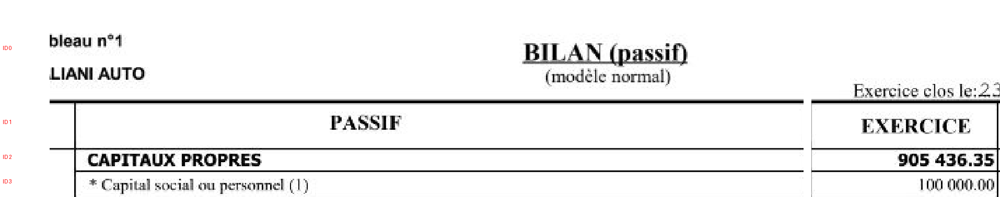

IDs attendus : [0, 1, 2, 3]

===== RESULTAT QWEN =====
Statut : OK
Tokens : 106

===== VALIDATION =====


,id_ligne,poste,valeur
0,0,,None
1,1,,None
2,2,,None
3,3,,None


IDs : OK
Schéma : OK
Nombre de lignes : 4
Résultat conservé en mémoire.

Aucun CSV final créé.


In [118]:

# ============================================================
# PASSIF N — BLOC 1, PARTIE 1 : IDs 0 A 3
# ============================================================

import json
import re
import math
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 1. Récupérer le bloc et la colonne N
bloc = blocs_passif_finaux[0]
ids_attendus = [0, 1, 2, 3]

image = Image.open(
    bloc["images"][colonne_N]
).convert("RGB")

# 2. Découper les 4 premières lignes
y1 = int(limites_y_passif[0] - bloc["y1"])
y2 = int(limites_y_passif[4] - bloc["y1"])

image_partie = image.crop(
    (0, y1, image.width, y2)
)

# 3. Ajouter les IDs rouges
marge = 95

image_annotee = Image.new(
    "RGB",
    (image_partie.width + marge, image_partie.height),
    "white"
)

image_annotee.paste(image_partie, (marge, 0))
dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype("DejaVuSans-Bold.ttf", 18)
except OSError:
    police = ImageFont.load_default()

for i in ids_attendus:

    haut = int(limites_y_passif[i] - limites_y_passif[0])
    bas = int(limites_y_passif[i + 1] - limites_y_passif[0])

    dessin.text(
        (5, max(0, (haut + bas) // 2 - 10)),
        f"ID {i}",
        fill="red",
        font=police
    )

chemin = Path(
    "/kaggle/working/passif_bloc1_partie1_N.png"
)

image_annotee.save(chemin)

print("===== IMAGE A EXTRAIRE =====")
display(image_annotee)

print("IDs attendus :", ids_attendus)

# 4. Prompt avec structure obligatoire
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": """
Transcris ces quatre lignes du bilan PASSIF.

La colonne gauche contient les postes.
La colonne droite contient EXERCICE N.

Chaque ID rouge correspond à une ligne.

IDs obligatoires : 0, 1, 2, 3.

IMPORTANT :
- Retourne exactement 4 objets.
- Chaque objet doit avoir les 3 champs :
  id_ligne, poste, valeur.
- Le champ valeur est TOUJOURS obligatoire.
- Pour une cellule vide, écris "valeur": null.
- Conserve les rubriques et les détails.
- Ne décale pas les IDs.
- Ne calcule rien et n'invente aucun montant.

Respecte exactement cette structure :

{
  "type_bilan": "PASSIF",
  "lignes": [
    {"id_ligne": 0, "poste": "", "valeur": null},
    {"id_ligne": 1, "poste": "", "valeur": null},
    {"id_ligne": 2, "poste": "", "valeur": null},
    {"id_ligne": 3, "poste": "", "valeur": null}
  ]
}

Les postes et valeurs de cet exemple sont
des espaces réservés à remplacer par la lecture
de l'image. Garde tous les IDs et tous les champs.

Retourne uniquement le JSON.
"""
            }
        ]
    }
]

# 5. Exécuter Qwen
resultat_passif_1_1 = extraire_avec_vlm(
    messages,
    max_tokens=800
)

print("\n===== RESULTAT QWEN =====")
print("Statut :", resultat_passif_1_1["statut"])
print("Tokens :", resultat_passif_1_1["nombre_tokens"])

# 6. Récupérer le JSON
lignes = recuperer_json_passif(
    resultat_passif_1_1
)

# 7. Validation stricte
valide = (
    isinstance(lignes, list)
    and len(lignes) == 4
    and all(
        isinstance(l, dict)
        and {"id_ligne", "poste", "valeur"}.issubset(l)
        and type(l["id_ligne"]) is int
        and isinstance(l["poste"], str)
        and (
            l["valeur"] is None
            or (
                type(l["valeur"]) in (int, float)
                and math.isfinite(l["valeur"])
            )
        )
        for l in lignes
    )
    and [l["id_ligne"] for l in lignes] == ids_attendus
)

print("\n===== VALIDATION =====")

if valide:

    df_passif_1_1 = pd.DataFrame(lignes)

    display(df_passif_1_1)

    print("IDs : OK")
    print("Schéma : OK")
    print("Nombre de lignes :", len(df_passif_1_1))

    if "resultats_passif_N_parties" not in globals():
        resultats_passif_N_parties = {}

    resultats_passif_N_parties[(1, 1)] = lignes

    print("Résultat conservé en mémoire.")

else:

    print("Extraction non validée.")
    print("Réponse brute :")
    print(resultat_passif_1_1["texte_brut"][:1500])

print("\nAucun CSV final créé.")


In [119]:

# ============================================================
# CORRECTION PASSIF N — BLOC 1, PARTIE 1
# IDs 0 A 3 — VERIFICATION VISUELLE
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Vérifier la correspondance des IDs
bloc = blocs_passif_finaux[0]

assert list(range(
    bloc["ligne_debut"],
    min(bloc["ligne_debut"] + 4, bloc["ligne_fin"] + 1)
)) == [0, 1, 2, 3]

# 2. Valeurs vérifiées sur l'image affichée
lignes_corrigees = [
    {
        "id_ligne": 0,
        "poste": "",
        "valeur": None
    },
    {
        "id_ligne": 1,
        "poste": "PASSIF",
        "valeur": None
    },
    {
        "id_ligne": 2,
        "poste": "CAPITAUX PROPRES",
        "valeur": 905436.35
    },
    {
        "id_ligne": 3,
        "poste": "* Capital social ou personnel (1)",
        "valeur": 100000.00
    }
]

# 3. Remplacer le résultat incorrect de Qwen
if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

resultats_passif_N_parties[(1, 1)] = lignes_corrigees

# 4. Construire le tableau
df_passif_1_1 = pd.DataFrame(lignes_corrigees)

# 5. Contrôles
assert df_passif_1_1["id_ligne"].tolist() == [0, 1, 2, 3]

assert (
    df_passif_1_1.loc[
        df_passif_1_1["id_ligne"] == 2, "valeur"
    ].iloc[0] == 905436.35
)

assert (
    df_passif_1_1.loc[
        df_passif_1_1["id_ligne"] == 3, "valeur"
    ].iloc[0] == 100000.00
)

print("===== PASSIF N — BLOC 1, PARTIE 1 =====")
display(df_passif_1_1)

print("\nIDs : OK")
print("Montants renseignés :", df_passif_1_1["valeur"].notna().sum())
print("Source : vérification visuelle de l'image")
print("Résultat conservé en mémoire.")
print("Aucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")


===== PASSIF N — BLOC 1, PARTIE 1 =====


,id_ligne,poste,valeur
0,0,,NaN
1,1,PASSIF,NaN
2,2,CAPITAUX PROPRES,905436.35
3,3,* Capital social ou personnel (1),100000.00



IDs : OK
Montants renseignés : 2
Source : vérification visuelle de l'image
Résultat conservé en mémoire.
Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


===== IMAGE PASSIF N — IDs 4 A 7 =====


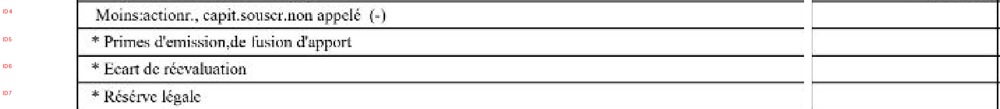

IDs attendus : [4, 5, 6, 7]

===== RESULTAT QWEN =====
Statut initial : OK
Tokens : 171

===== EXTRACTION IDs 4 A 7 =====


,id_ligne,poste,valeur
0,4,"Moins:actionn., capit.souscr.non appelé (-)",None
1,5,"* Primes d'émission,de fusion d'apport",None
2,6,* Ecart de réévaluation,None
3,7,* Réserve légale,None



IDs : OK
Schéma JSON : OK
Montants détectés : 0

===== BLOC 1 PASSIF N COMPLET =====


,id_ligne,poste,valeur
0,0,,NaN
1,1,PASSIF,NaN
2,2,CAPITAUX PROPRES,905436.35
3,3,* Capital social ou personnel (1),100000.00
4,4,"Moins:actionn., capit.souscr.non appelé (-)",NaN
5,5,"* Primes d'émission,de fusion d'apport",NaN
6,6,* Ecart de réévaluation,NaN
7,7,* Réserve légale,NaN


Validation structurelle : OK
Validation visuelle : A CONFIRMER

Aucun CSV final créé.


In [120]:

# ============================================================
# PASSIF N — BLOC 1, PARTIE 2 : IDs 4 A 7
# EXTRACTION QWEN2.5-VL
# ============================================================

import pandas as pd
import math
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display

# 1. Vérifier la partie précédente
assert (1, 1) in resultats_passif_N_parties

# 2. Sélectionner le premier bloc PASSIF
bloc = blocs_passif_finaux[0]
ids_attendus = [4, 5, 6, 7]

image = Image.open(
    bloc["images"][colonne_N]
).convert("RGB")

# 3. Découper les lignes 4 à 7
y1 = int(limites_y_passif[4] - bloc["y1"])
y2 = int(limites_y_passif[8] - bloc["y1"])

image_partie = image.crop(
    (0, y1, image.width, y2)
)

# 4. Ajouter les IDs rouges
marge = 100

image_annotee = Image.new(
    "RGB",
    (image_partie.width + marge, image_partie.height),
    "white"
)

image_annotee.paste(image_partie, (marge, 0))

dessin = ImageDraw.Draw(image_annotee)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

for i in ids_attendus:

    haut = int(
        limites_y_passif[i] - limites_y_passif[4]
    )

    bas = int(
        limites_y_passif[i + 1] - limites_y_passif[4]
    )

    centre = (haut + bas) // 2

    dessin.text(
        (5, max(0, centre - 10)),
        f"ID {i}",
        fill="red",
        font=police
    )

# 5. Enregistrer et afficher
chemin = Path(
    "/kaggle/working/passif_bloc1_partie2_N.png"
)

image_annotee.save(chemin)

print("===== IMAGE PASSIF N — IDs 4 A 7 =====")
display(image_annotee)

print("IDs attendus :", ids_attendus)

# 6. Prompt sans valeurs d'exemple
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": chemin.resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Tu dois transcrire fidèlement un tableau
comptable marocain.

L'image contient 4 lignes numérotées en rouge.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : montant de l'EXERCICE N.

Pour CHAQUE ID, retourne :
- id_ligne : identifiant rouge (entier)
- poste : texte réellement visible (chaîne)
- valeur : montant numérique ou null

RÈGLES IMPORTANTES :
1. Exactement 4 entrées.
2. Conserve les IDs dans leur ordre.
3. Conserve les intitulés même sans montant.
4. Le champ "valeur" est obligatoire.
5. Si un montant est visible, transcris-le.
6. Si la cellule est vide, utilise null.
7. Ne considère pas tous les montants comme vides.
8. Ne calcule aucun montant.
9. Ne complète pas avec des données inventées.
10. Ne mélange pas les exercices N et N-1.

Retourne un objet JSON avec :
- "type_bilan" égal à "PASSIF"
- "lignes" contenant les 4 objets.

Chaque objet doit contenir exactement :
"id_ligne", "poste", "valeur".

Retourne uniquement du JSON valide.
"""
            }
        ]
    }
]

# 7. Exécuter Qwen2.5-VL
resultat_passif_1_2 = extraire_avec_vlm(
    messages,
    max_tokens=1000
)

print("\n===== RESULTAT QWEN =====")
print("Statut initial :", resultat_passif_1_2["statut"])
print("Tokens :", resultat_passif_1_2["nombre_tokens"])

# 8. Récupérer le JSON
lignes = recuperer_json_passif(
    resultat_passif_1_2
)

# 9. Vérifier structure et IDs
valide = (
    isinstance(lignes, list)
    and len(lignes) == 4
    and all(
        isinstance(l, dict)
        and {"id_ligne", "poste", "valeur"}.issubset(l)
        and type(l["id_ligne"]) is int
        and isinstance(l["poste"], str)
        and (
            l["valeur"] is None
            or (
                type(l["valeur"]) in (int, float)
                and math.isfinite(l["valeur"])
            )
        )
        for l in lignes
    )
    and [l["id_ligne"] for l in lignes] == ids_attendus
)

# 10. Afficher et conserver provisoirement
if valide:

    df_passif_1_2 = pd.DataFrame(lignes)

    print("\n===== EXTRACTION IDs 4 A 7 =====")
    display(df_passif_1_2)

    print("\nIDs : OK")
    print("Schéma JSON : OK")
    print(
        "Montants détectés :",
        df_passif_1_2["valeur"].notna().sum()
    )

    # Conservation provisoire :
    # exactitude visuelle encore à confirmer
    resultats_passif_N_parties[(1, 2)] = lignes

    # Fusion provisoire du bloc 1
    lignes_bloc1 = (
        resultats_passif_N_parties[(1, 1)]
        + resultats_passif_N_parties[(1, 2)]
    )

    df_passif_bloc1_complet = pd.DataFrame(lignes_bloc1)

    assert (
        df_passif_bloc1_complet["id_ligne"].tolist()
        == list(range(8))
    )

    print("\n===== BLOC 1 PASSIF N COMPLET =====")
    display(df_passif_bloc1_complet)

    print("Validation structurelle : OK")
    print("Validation visuelle : A CONFIRMER")

else:

    print("\nEXTRACTION NON VALIDEE")
    print("Réponse brute :")
    print(resultat_passif_1_2["texte_brut"][:1500])

print("\nAucun CSV final créé.")


===== BLOC PASSIF 2 =====
IDs : 8 à 15

===== BLOC 2 — PARTIE 1 =====

===== IMAGE =====


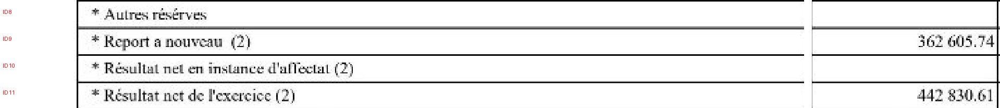


Statut initial : OK


,id_ligne,poste,valeur
0,8,* Autres réserves,NaN
1,9,* Report à nouveau (2),362605.74
2,10,* Résultat net en instance d'affectat (2),NaN
3,11,* Résultat net de l'exercice (2),442830.61


IDs : OK
Schéma JSON : OK
Exactitude visuelle : à vérifier

===== BLOC 2 — PARTIE 2 =====

===== IMAGE =====


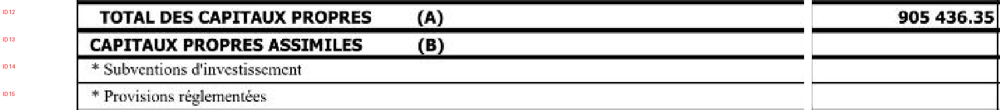


Statut initial : OK


,id_ligne,poste,valeur
0,12,TOTAL DES CAPITAUX PROPRES,905436.35
1,13,CAPITAUX PROPRES ASSIMILES,NaN
2,14,* Subventions d'investissement,NaN
3,15,* Provisions réglementées,NaN


IDs : OK
Schéma JSON : OK
Exactitude visuelle : à vérifier

===== BLOC 2 COMPLET =====


,id_ligne,poste,valeur
0,8,* Autres réserves,NaN
1,9,* Report à nouveau (2),362605.74
2,10,* Résultat net en instance d'affectat (2),NaN
3,11,* Résultat net de l'exercice (2),442830.61
4,12,TOTAL DES CAPITAUX PROPRES,905436.35
5,13,CAPITAUX PROPRES ASSIMILES,NaN
6,14,* Subventions d'investissement,NaN
7,15,* Provisions réglementées,NaN


Nombre de lignes : 8
Montants détectés : 3
Validation structurelle : OK
Validation visuelle : à confirmer

Aucun CSV final créé.


In [121]:

# ============================================================
# PASSIF N — EXTRACTION DU BLOC 2
# IDs 8 A 15 — DEUX PARTIES DE 4 LIGNES
# ============================================================

import pandas as pd
import math
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 1. Vérifier les données existantes
assert len(blocs_passif_finaux) >= 2

if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

bloc = blocs_passif_finaux[1]

print("===== BLOC PASSIF 2 =====")
print("IDs :", bloc["ligne_debut"], "à", bloc["ligne_fin"])

assert bloc["ligne_debut"] == 8
assert bloc["ligne_fin"] == 15

dossier = Path("/kaggle/working/passif_bloc2_N")
dossier.mkdir(parents=True, exist_ok=True)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()


# 2. Fonction pour découper et numéroter
def preparer_partie_passif(debut, fin):

    image = Image.open(
        bloc["images"][colonne_N]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin] - bloc["y1"])

    partie = image.crop((0, y1, image.width, y2))

    marge = 100

    annotee = Image.new(
        "RGB",
        (partie.width + marge, partie.height),
        "white"
    )

    annotee.paste(partie, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for i in range(debut, fin):

        haut = int(limites_y_passif[i] - limites_y_passif[debut])
        bas = int(limites_y_passif[i + 1] - limites_y_passif[debut])

        dessin.text(
            (5, max(0, (haut + bas)//2 - 10)),
            f"ID {i}",
            fill="red",
            font=police
        )

    chemin = dossier / f"ids_{debut}_{fin-1}.png"
    annotee.save(chemin)

    return chemin, annotee


# 3. Fonction d'extraction Qwen
def extraire_partie_passif_N(debut, fin, numero_partie):

    ids_attendus = list(range(debut, fin))
    cle = (2, numero_partie)

    # Ne pas refaire une extraction déjà réussie
    if cle in resultats_passif_N_parties:
        lignes = resultats_passif_N_parties[cle]
        if (
            isinstance(lignes, list)
            and [l.get("id_ligne") for l in lignes] == ids_attendus
        ):
            print("Résultat existant réutilisé.")
            display(pd.DataFrame(lignes))
            return lignes

    chemin, image_annotee = preparer_partie_passif(
        debut, fin
    )

    print("\n===== IMAGE =====")
    display(image_annotee)

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": chemin.resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris fidèlement ce tableau du bilan PASSIF.

Les lignes sont numérotées en rouge.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : montant de l'EXERCICE N.

Retourne exactement {len(ids_attendus)} entrées.

Chaque entrée possède obligatoirement :
- id_ligne : entier
- poste : texte visible
- valeur : montant numérique ou null

IMPORTANT :
- Respecte l'ordre et l'alignement des IDs.
- Lis tous les chiffres visibles.
- Conserve les rubriques et les totaux.
- Si le montant est vide, retourne null.
- Ne suppose pas que les montants sont tous vides.
- Ne calcule aucun montant.
- N'invente aucune donnée.
- Ne mélange pas N et N-1.

Retourne uniquement un objet JSON contenant :
"type_bilan": "PASSIF"
"lignes": liste des entrées.

Aucune explication supplémentaire.
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1000
    )

    lignes = recuperer_json_passif(resultat)

    valide = (
        isinstance(lignes, list)
        and len(lignes) == len(ids_attendus)
        and all(
            isinstance(l, dict)
            and {"id_ligne", "poste", "valeur"}.issubset(l)
            and type(l["id_ligne"]) is int
            and isinstance(l["poste"], str)
            and (
                l["valeur"] is None
                or (
                    type(l["valeur"]) in (int, float)
                    and math.isfinite(l["valeur"])
                )
            )
            for l in lignes
        )
        and [l["id_ligne"] for l in lignes] == ids_attendus
    )

    print("\nStatut initial :", resultat["statut"])

    if valide:

        resultats_passif_N_parties[cle] = lignes

        display(pd.DataFrame(lignes))

        print("IDs : OK")
        print("Schéma JSON : OK")
        print("Exactitude visuelle : à vérifier")

        return lignes

    print("Extraction non validée.")
    print(resultat["texte_brut"][:1200])

    return None


# 4. Extraire les deux parties
parties = [
    (8, 12, 1),
    (12, 16, 2)
]

resultats_bloc2 = []

for debut, fin, partie in parties:

    print(f"\n===== BLOC 2 — PARTIE {partie} =====")

    lignes = extraire_partie_passif_N(
        debut, fin, partie
    )

    if lignes is not None:
        resultats_bloc2.extend(lignes)


# 5. Reconstruire le bloc 2
if len(resultats_bloc2) == 8 and (
    [l["id_ligne"] for l in resultats_bloc2]
    == list(range(8, 16))
):

    df_passif_bloc2 = pd.DataFrame(resultats_bloc2)

    print("\n===== BLOC 2 COMPLET =====")
    display(df_passif_bloc2)

    print("Nombre de lignes :", len(df_passif_bloc2))
    print(
        "Montants détectés :",
        df_passif_bloc2["valeur"].notna().sum()
    )

    print("Validation structurelle : OK")
    print("Validation visuelle : à confirmer")

else:
    print("\nBLOC 2 INCOMPLET OU NON VALIDE.")

print("\nAucun CSV final créé.")



===== BLOC 3 — PARTIE 1 =====


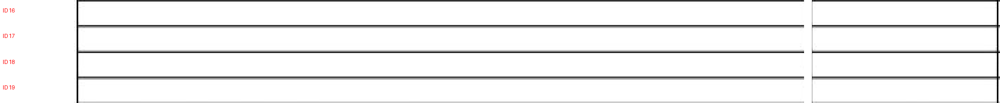

IDs attendus : [16, 17, 18, 19]
Statut Qwen : OK
Validation structurelle : OK


,id_ligne,poste,valeur
0,16,Dette à court terme,None
1,17,Dette à long terme,None
2,18,Dette non financière,None
3,19,Dette financière,None



===== BLOC 3 — PARTIE 2 =====


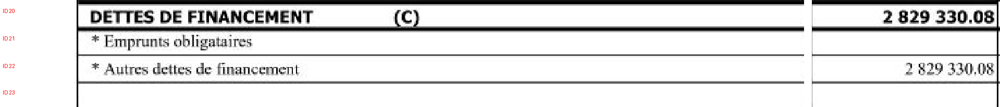

IDs attendus : [20, 21, 22, 23]
Statut Qwen : OK
Validation structurelle : OK


,id_ligne,poste,valeur
0,20,DETTES DE FINANCEMENT (C),2829330.08
1,21,* Emprunts obligataires,NaN
2,22,* Autres dettes de financement,2829330.08
3,23,,NaN



===== BLOC 3 COMPLET =====


,id_ligne,poste,valeur
0,16,Dette à court terme,NaN
1,17,Dette à long terme,NaN
2,18,Dette non financière,NaN
3,19,Dette financière,NaN
4,20,DETTES DE FINANCEMENT (C),2829330.08
5,21,* Emprunts obligataires,NaN
6,22,* Autres dettes de financement,2829330.08
7,23,,NaN


Nombre de lignes : 8
Montants renseignés : 2
IDs : OK
Validation visuelle : A CONFIRMER

Aucun CSV final créé.


In [122]:

# ============================================================
# PASSIF N — BLOC 3 : IDs 16 A 23
# DEUX PARTIES DE 4 LIGNES
# ============================================================

import pandas as pd
import math
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 1. Sélectionner le bloc 3
bloc = blocs_passif_finaux[2]

assert bloc["ligne_debut"] == 16
assert bloc["ligne_fin"] == 23

dossier = Path("/kaggle/working/passif_bloc3_N")
dossier.mkdir(parents=True, exist_ok=True)

if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()


# 2. Fonction de préparation de l'image
def preparer_image_passif3(debut, fin):

    image = Image.open(
        bloc["images"][colonne_N]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin] - bloc["y1"])

    partie = image.crop((0, y1, image.width, y2))

    marge = 100
    annotee = Image.new(
        "RGB",
        (partie.width + marge, partie.height),
        "white"
    )

    annotee.paste(partie, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for i in range(debut, fin):

        haut = int(
            limites_y_passif[i] - limites_y_passif[debut]
        )
        bas = int(
            limites_y_passif[i + 1] - limites_y_passif[debut]
        )

        dessin.text(
            (5, max(0, (haut + bas)//2 - 10)),
            f"ID {i}",
            fill="red",
            font=police
        )

    chemin = dossier / f"passif_N_{debut}_{fin-1}.png"
    annotee.save(chemin)

    return chemin, annotee


# 3. Extraire les deux parties
for numero_partie, (debut, fin) in enumerate(
    [(16, 20), (20, 24)],
    start=1
):

    print(f"\n===== BLOC 3 — PARTIE {numero_partie} =====")

    ids_attendus = list(range(debut, fin))
    cle = (3, numero_partie)

    # Réutiliser un résultat existant seulement s'il
    # possède les bons IDs et tous les champs
    existant = resultats_passif_N_parties.get(cle)

    if (
        isinstance(existant, list)
        and len(existant) == len(ids_attendus)
        and all(
            isinstance(l, dict)
            and {"id_ligne", "poste", "valeur"}.issubset(l)
            for l in existant
        )
        and [l["id_ligne"] for l in existant] == ids_attendus
    ):
        print("Résultat existant réutilisé.")
        display(pd.DataFrame(existant))
        continue

    chemin, image_annotee = preparer_image_passif3(
        debut, fin
    )

    display(image_annotee)
    print("IDs attendus :", ids_attendus)

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": chemin.resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris ce bloc du bilan PASSIF marocain.

Chaque ID rouge représente une ligne.

IDs attendus : {ids_attendus}

La colonne de gauche contient les postes.
La colonne de droite contient EXERCICE N.

Pour chaque ID, retourne obligatoirement :
- id_ligne : entier
- poste : texte réellement visible
- valeur : montant numérique ou null

Règles :
1. Exactement {len(ids_attendus)} entrées.
2. Respecte les IDs et l'ordre des lignes.
3. Conserve les titres, détails et totaux.
4. Lis attentivement TOUS les montants visibles.
5. Une cellule réellement vide vaut null.
6. Ne décale pas les valeurs.
7. Ne calcule pas de montants.
8. N'invente aucune donnée.
9. N'utilise pas les montants de N-1.

Réponds uniquement avec un JSON valide
contenant "type_bilan": "PASSIF" et "lignes".

Chaque objet de "lignes" doit contenir :
"id_ligne", "poste", "valeur".
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1000
    )

    lignes = recuperer_json_passif(resultat)

    valide = (
        isinstance(lignes, list)
        and len(lignes) == len(ids_attendus)
        and all(
            isinstance(l, dict)
            and {"id_ligne", "poste", "valeur"}.issubset(l)
            and type(l["id_ligne"]) is int
            and isinstance(l["poste"], str)
            and (
                l["valeur"] is None
                or (
                    type(l["valeur"]) in (int, float)
                    and math.isfinite(l["valeur"])
                )
            )
            for l in lignes
        )
        and [l["id_ligne"] for l in lignes] == ids_attendus
    )

    print("Statut Qwen :", resultat["statut"])

    if valide:

        resultats_passif_N_parties[cle] = lignes

        print("Validation structurelle : OK")
        display(pd.DataFrame(lignes))

    else:

        print("Extraction non validée.")
        print(resultat["texte_brut"][:1200])


# 4. Reconstituer le bloc 3
partie1 = resultats_passif_N_parties.get((3, 1))
partie2 = resultats_passif_N_parties.get((3, 2))

if partie1 is not None and partie2 is not None:

    lignes_bloc3 = partie1 + partie2

    if [l["id_ligne"] for l in lignes_bloc3] == list(
        range(16, 24)
    ):

        df_passif_bloc3 = pd.DataFrame(lignes_bloc3)

        print("\n===== BLOC 3 COMPLET =====")
        display(df_passif_bloc3)

        print("Nombre de lignes :", len(df_passif_bloc3))
        print(
            "Montants renseignés :",
            df_passif_bloc3["valeur"].notna().sum()
        )

        print("IDs : OK")
        print("Validation visuelle : A CONFIRMER")

    else:
        print("IDs incohérents dans le bloc 3.")

else:
    print("Bloc 3 incomplet.")

print("\nAucun CSV final créé.")



===== IMAGE IDs 16 A 19 =====


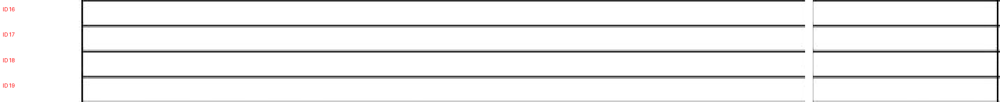


===== IMAGE IDs 20 A 23 =====


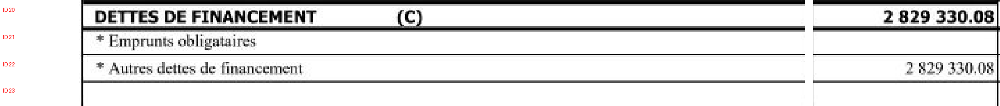


===== TRANSCRIPTION QWEN =====


,id_ligne,poste,valeur
0,16,Dette à court terme,NaN
1,17,Dette à long terme,NaN
2,18,Dette non financière,NaN
3,19,Dette financière,NaN
4,20,DETTES DE FINANCEMENT (C),2829330.08
5,21,* Emprunts obligataires,NaN
6,22,* Autres dettes de financement,2829330.08
7,23,,NaN



IDs 16-19 : A VERIFIER VISUELLEMENT
Résultat suspect conservé séparément.
Aucune nouvelle inférence Qwen.
Aucun CSV créé.


In [123]:

# ============================================================
# DIAGNOSTIC VISUEL — PASSIF N, BLOC 3
# IDs 16 A 23 — SANS NOUVELLE INFERENCE QWEN
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd

bloc3 = blocs_passif_finaux[2]

image_originale = Image.open(
    bloc3["images"][colonne_N]
).convert("RGB")

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 22
    )
except OSError:
    police = ImageFont.load_default()

# Afficher les deux parties séparément
for debut, fin in [(16, 20), (20, 24)]:

    y1 = int(limites_y_passif[debut] - bloc3["y1"])
    y2 = int(limites_y_passif[fin] - bloc3["y1"])

    image = image_originale.crop(
        (0, y1, image_originale.width, y2)
    )

    marge = 110

    annotee = Image.new(
        "RGB",
        (image.width + marge, image.height),
        "white"
    )

    annotee.paste(image, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for identifiant in range(debut, fin):

        haut = int(
            limites_y_passif[identifiant]
            - limites_y_passif[debut]
        )

        bas = int(
            limites_y_passif[identifiant + 1]
            - limites_y_passif[debut]
        )

        centre = (haut + bas) // 2

        dessin.text(
            (5, max(0, centre - 12)),
            f"ID {identifiant}",
            fill="red",
            font=police
        )

    print(f"\n===== IMAGE IDs {debut} A {fin-1} =====")
    display(annotee)

# Afficher la transcription Qwen
print("\n===== TRANSCRIPTION QWEN =====")

display(
    pd.DataFrame(
        resultats_passif_N_parties[(3, 1)]
        + resultats_passif_N_parties[(3, 2)]
    )
)

# Mettre la partie suspecte à l'écart
# pour empêcher sa réutilisation comme validée
if "extractions_passif_a_revoir" not in globals():
    extractions_passif_a_revoir = {}

if (3, 1) in resultats_passif_N_parties:
    extractions_passif_a_revoir[(3, 1)] = (
        resultats_passif_N_parties.pop((3, 1))
    )

print("\nIDs 16-19 : A VERIFIER VISUELLEMENT")
print("Résultat suspect conservé séparément.")
print("Aucune nouvelle inférence Qwen.")
print("Aucun CSV créé.")


In [124]:

# ============================================================
# CORRECTION PASSIF N — BLOC 3
# SUPPRESSION DES POSTES HALLUCINES PAR QWEN
# SANS NOUVELLE INFERENCE
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Corriger les lignes visuellement vides
lignes_corrigees = [
    {
        "id_ligne": i,
        "poste": "",
        "valeur": None
    }
    for i in range(16, 20)
]

# 2. Restaurer la partie 1 corrigée
resultats_passif_N_parties[(3, 1)] = lignes_corrigees

# 3. Réutiliser la partie 2 déjà extraite
assert (3, 2) in resultats_passif_N_parties

partie2 = resultats_passif_N_parties[(3, 2)]

assert [
    l["id_ligne"] for l in partie2
] == [20, 21, 22, 23]

# 4. Fusionner le bloc 3
lignes_bloc3 = (
    resultats_passif_N_parties[(3, 1)]
    + partie2
)

df_passif_bloc3 = pd.DataFrame(lignes_bloc3)

# 5. Vérifier les identifiants
assert df_passif_bloc3["id_ligne"].tolist() == list(
    range(16, 24)
)

# Vérifier que les lignes vides restent vides
assert all(
    l["poste"] == "" and l["valeur"] is None
    for l in lignes_corrigees
)

# 6. Afficher le résultat
print("===== BLOC 3 CORRIGE =====")
display(df_passif_bloc3)

print("\n===== VALIDATION =====")
print("Nombre de lignes :", len(df_passif_bloc3))
print("IDs :", df_passif_bloc3["id_ligne"].tolist())
print(
    "Montants renseignés :",
    df_passif_bloc3["valeur"].notna().sum()
)
print("IDs 16-19 corrigés : OK")
print("Résultats des IDs 20-23 conservés.")

print("\nAucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")


===== BLOC 3 CORRIGE =====


,id_ligne,poste,valeur
0,16,,NaN
1,17,,NaN
2,18,,NaN
3,19,,NaN
4,20,DETTES DE FINANCEMENT (C),2829330.08
5,21,* Emprunts obligataires,NaN
6,22,* Autres dettes de financement,2829330.08
7,23,,NaN



===== VALIDATION =====
Nombre de lignes : 8
IDs : [16, 17, 18, 19, 20, 21, 22, 23]
Montants renseignés : 2
IDs 16-19 corrigés : OK
Résultats des IDs 20-23 conservés.

Aucune nouvelle inférence Qwen.
Aucun CSV final créé.



===== BLOC 4 — PARTIE 1 =====
IDs attendus : [24, 25, 26, 27]


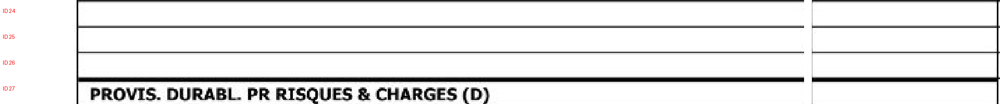

Statut Qwen : OK
Validation structurelle : OK


,id_ligne,poste,valeur
0,24,,None
1,25,,None
2,26,,None
3,27,PROVIS. DURABL. PR RISQUES & CHARGES (D),None


Montants détectés : 0

===== BLOC 4 — PARTIE 2 =====
IDs attendus : [28, 29, 30, 31]


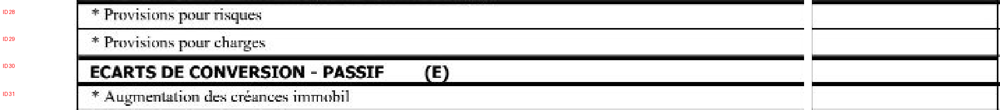

Statut Qwen : OK
Validation structurelle : OK


,id_ligne,poste,valeur
0,28,* Provisions pour risques,None
1,29,* Provisions pour charges,None
2,30,ECARTS DE CONVERSION - PASSIF (E),None
3,31,* Augmentation des créances immobili,None


Montants détectés : 0

===== BLOC 4 COMPLET =====


,id_ligne,poste,valeur
0,24,,None
1,25,,None
2,26,,None
3,27,PROVIS. DURABL. PR RISQUES & CHARGES (D),None
4,28,* Provisions pour risques,None
5,29,* Provisions pour charges,None
6,30,ECARTS DE CONVERSION - PASSIF (E),None
7,31,* Augmentation des créances immobili,None


Nombre de lignes : 8
Montants renseignés : 0
IDs : OK
Validation visuelle : A CONFIRMER

Aucun CSV final créé.


In [125]:

# ============================================================
# PASSIF N — BLOC 4 : IDs 24 A 31
# EXTRACTION EN DEUX PARTIES DE 4 LIGNES
# ============================================================

import math
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# 1. Vérifier les variables
assert len(blocs_passif_finaux) >= 4

bloc = blocs_passif_finaux[3]

assert bloc["ligne_debut"] == 24
assert bloc["ligne_fin"] == 31

if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

dossier = Path("/kaggle/working/passif_bloc4_N")
dossier.mkdir(parents=True, exist_ok=True)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()


# 2. Créer une image numérotée
def preparer_image_passif4(debut, fin):

    image = Image.open(
        bloc["images"][colonne_N]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin] - bloc["y1"])

    partie = image.crop(
        (0, y1, image.width, y2)
    )

    marge = 100

    annotee = Image.new(
        "RGB",
        (partie.width + marge, partie.height),
        "white"
    )

    annotee.paste(partie, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for i in range(debut, fin):

        haut = int(
            limites_y_passif[i] - limites_y_passif[debut]
        )
        bas = int(
            limites_y_passif[i + 1] - limites_y_passif[debut]
        )

        dessin.text(
            (5, max(0, (haut + bas) // 2 - 10)),
            f"ID {i}",
            fill="red",
            font=police
        )

    chemin = dossier / f"passif_N_{debut}_{fin-1}.png"
    annotee.save(chemin)

    return chemin, annotee


# 3. Extraire chaque partie avec Qwen
for numero_partie, (debut, fin) in enumerate(
    [(24, 28), (28, 32)],
    start=1
):

    print(
        f"\n===== BLOC 4 — PARTIE {numero_partie} ====="
    )

    ids_attendus = list(range(debut, fin))
    cle = (4, numero_partie)

    chemin, image_annotee = preparer_image_passif4(
        debut, fin
    )

    print("IDs attendus :", ids_attendus)
    display(image_annotee)

    # Réutiliser les résultats existants s'ils sont
    # structurellement valides
    existant = resultats_passif_N_parties.get(cle)

    if (
        isinstance(existant, list)
        and len(existant) == 4
        and all(
            isinstance(l, dict)
            and {"id_ligne", "poste", "valeur"}.issubset(l)
            for l in existant
        )
        and [l["id_ligne"] for l in existant] == ids_attendus
    ):
        print("Résultat précédent réutilisé.")
        display(pd.DataFrame(existant))
        continue

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": chemin.resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris fidèlement ce tableau du bilan PASSIF.

Chaque ID rouge correspond à une ligne physique.

IDs attendus : {ids_attendus}

Colonne gauche : nom du poste comptable.
Colonne droite : montant de l'EXERCICE N.

Pour chaque ID, retourne :
- id_ligne : entier
- poste : texte visible à gauche
- valeur : nombre visible à droite ou null

RÈGLES :
1. Retourne exactement 4 entrées.
2. Respecte l'ordre des IDs.
3. Conserve les rubriques et les totaux.
4. Si la ligne est entièrement vide,
   poste="" et valeur=null.
5. Si le poste existe mais pas le montant,
   conserve le poste et utilise null.
6. Lis tous les montants réellement visibles.
7. N'invente aucun poste.
8. Ne calcule aucun montant.
9. Ne mélange pas N et N-1.
10. Les trois champs sont obligatoires.

Retourne uniquement un JSON valide
contenant :
"type_bilan": "PASSIF"
"lignes": liste des 4 objets.

Chaque objet contient :
"id_ligne", "poste", "valeur".

Aucune explication.
"""
                }
            ]
        }
    ]

    # 4. Inférence Qwen
    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1000
    )

    # 5. Récupérer JSON objet ou liste
    lignes = recuperer_json_passif(resultat)

    # 6. Validation structurelle stricte
    valide = (
        isinstance(lignes, list)
        and len(lignes) == 4
        and all(
            isinstance(l, dict)
            and {"id_ligne", "poste", "valeur"}.issubset(l)
            and type(l["id_ligne"]) is int
            and isinstance(l["poste"], str)
            and (
                l["valeur"] is None
                or (
                    type(l["valeur"]) in (int, float)
                    and math.isfinite(l["valeur"])
                )
            )
            for l in lignes
        )
        and [l["id_ligne"] for l in lignes] == ids_attendus
    )

    print("Statut Qwen :", resultat["statut"])

    if valide:

        resultats_passif_N_parties[cle] = lignes

        print("Validation structurelle : OK")
        display(pd.DataFrame(lignes))

        print(
            "Montants détectés :",
            sum(l["valeur"] is not None for l in lignes)
        )

    else:

        print("Extraction non validée.")
        print("Réponse brute :")
        print(resultat["texte_brut"][:1200])


# 7. Reconstruire le bloc 4
partie1 = resultats_passif_N_parties.get((4, 1))
partie2 = resultats_passif_N_parties.get((4, 2))

if partie1 is not None and partie2 is not None:

    lignes_bloc4 = partie1 + partie2

    if [l["id_ligne"] for l in lignes_bloc4] == list(
        range(24, 32)
    ):

        df_passif_bloc4 = pd.DataFrame(lignes_bloc4)

        print("\n===== BLOC 4 COMPLET =====")
        display(df_passif_bloc4)

        print("Nombre de lignes :", len(df_passif_bloc4))

        print(
            "Montants renseignés :",
            df_passif_bloc4["valeur"].notna().sum()
        )

        print("IDs : OK")
        print("Validation visuelle : A CONFIRMER")

    else:
        print("ERREUR : IDs incohérents.")

else:
    print("\nBLOC 4 INCOMPLET.")

print("\nAucun CSV final créé.")



===== BLOC 5 — PARTIE 1 =====


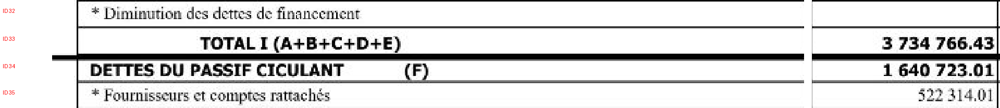

IDs attendus : [32, 33, 34, 35]
Statut Qwen : OK
EXTRACTION NON VALIDEE
```json
{
  "type_bilan": "PASSIF",
  "lignes": [
    {
      "id_ligne": "ID32",
      "poste": "* Diminution des dettes de financement",
      "valeur": null
    },
    {
      "id_ligne": "ID33",
      "poste": "TOTAL I (A+B+C+D+E)",
      "valeur": 3734766.43
    },
    {
      "id_ligne": "ID34",
      "poste": "DETTES DU PASSIF CICULANT (F)",
      "valeur": 1640723.01
    },
    {
      "id_ligne": "ID35",
      "poste": "* Fournisseurs et comptes rattachés",
      "valeur": 522314.01
    }
  ]
}
```

Aucun CSV final créé.


In [126]:

# ============================================================
# PASSIF N — BLOC 5 : IDs 32 A 39
# FONCTION REUTILISABLE POUR LES BLOCS SUIVANTS
# ============================================================

import math
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

dossier_passif_N = Path(
    "/kaggle/working/extraction_passif_N"
)
dossier_passif_N.mkdir(parents=True, exist_ok=True)

if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

try:
    police_passif = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police_passif = ImageFont.load_default()


# ------------------------------------------------------------
# 1. CREATION DES IMAGES NUMEROTEES
# ------------------------------------------------------------

def creer_image_passif_N(bloc, debut, fin):

    image = Image.open(
        bloc["images"][colonne_N]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin] - bloc["y1"])

    partie = image.crop(
        (0, y1, image.width, y2)
    )

    marge = 100

    annotee = Image.new(
        "RGB",
        (partie.width + marge, partie.height),
        "white"
    )

    annotee.paste(partie, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for identifiant in range(debut, fin):

        haut = int(
            limites_y_passif[identifiant]
            - limites_y_passif[debut]
        )

        bas = int(
            limites_y_passif[identifiant + 1]
            - limites_y_passif[debut]
        )

        centre = (haut + bas) // 2

        dessin.text(
            (5, max(0, centre - 10)),
            f"ID {identifiant}",
            fill="red",
            font=police_passif
        )

    chemin = dossier_passif_N / (
        f"passif_N_{debut:02d}_{fin-1:02d}.png"
    )

    annotee.save(chemin)

    return chemin, annotee


# ------------------------------------------------------------
# 2. VALIDATION STRICTE
# ------------------------------------------------------------

def valider_lignes_passif(lignes, ids_attendus):

    if not isinstance(lignes, list):
        return False

    if len(lignes) != len(ids_attendus):
        return False

    for ligne in lignes:

        if not isinstance(ligne, dict):
            return False

        if not {"id_ligne", "poste", "valeur"}.issubset(ligne):
            return False

        if type(ligne["id_ligne"]) is not int:
            return False

        if not isinstance(ligne["poste"], str):
            return False

        valeur = ligne["valeur"]

        if valeur is not None:
            if type(valeur) not in (int, float):
                return False

            if not math.isfinite(valeur):
                return False

    return [
        l["id_ligne"] for l in lignes
    ] == ids_attendus


# ------------------------------------------------------------
# 3. FONCTION GENERALE D'EXTRACTION D'UN BLOC PASSIF
# ------------------------------------------------------------

def extraire_bloc_passif_N(numero_bloc):

    bloc = blocs_passif_finaux[numero_bloc - 1]

    debut_bloc = bloc["ligne_debut"]
    fin_bloc = bloc["ligne_fin"] + 1

    toutes_lignes = []

    for numero_partie, debut in enumerate(
        range(debut_bloc, fin_bloc, 4),
        start=1
    ):

        fin = min(debut + 4, fin_bloc)

        ids_attendus = list(range(debut, fin))
        cle = (numero_bloc, numero_partie)

        print(
            f"\n===== BLOC {numero_bloc} "
            f"— PARTIE {numero_partie} ====="
        )

        chemin, image_annotee = creer_image_passif_N(
            bloc, debut, fin
        )

        display(image_annotee)
        print("IDs attendus :", ids_attendus)

        # Réutiliser les résultats existants
        existant = resultats_passif_N_parties.get(cle)

        if valider_lignes_passif(existant, ids_attendus):

            print("Résultat existant réutilisé.")
            lignes = existant

        else:

            messages = [
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "image",
                            "image": chemin.resolve().as_uri(),
                            "max_pixels": 1600 * 28 * 28
                        },
                        {
                            "type": "text",
                            "text": f"""
Transcris fidèlement ce bloc du bilan PASSIF.

Chaque ID rouge représente une ligne physique.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : montant EXERCICE N.

Pour chaque ID, retourne :
- id_ligne : entier
- poste : texte réellement visible
- valeur : montant numérique ou null

REGLES :
1. Exactement {len(ids_attendus)} entrées.
2. Respecte strictement les IDs.
3. Conserve tous les postes et totaux.
4. Si une ligne est vide : poste="".
5. Si aucun montant n'est visible : null.
6. Si un montant existe, transcris-le.
7. N'invente aucun poste ni montant.
8. Ne calcule aucun montant.
9. Ne mélange pas N et N-1.
10. Les trois champs sont obligatoires.

Retourne uniquement un objet JSON avec :
"type_bilan": "PASSIF"
"lignes": tableau des entrées.

Chaque entrée contient obligatoirement :
"id_ligne", "poste", "valeur".
"""
                        }
                    ]
                }
            ]

            resultat = extraire_avec_vlm(
                messages,
                max_tokens=1000
            )

            lignes = recuperer_json_passif(resultat)

            print("Statut Qwen :", resultat["statut"])

            if not valider_lignes_passif(
                lignes, ids_attendus
            ):

                print("EXTRACTION NON VALIDEE")
                print(resultat["texte_brut"][:1000])

                return None

            # Conserver provisoirement
            resultats_passif_N_parties[cle] = lignes

        print("Validation structurelle : OK")
        display(pd.DataFrame(lignes))

        print(
            "Montants détectés :",
            sum(l["valeur"] is not None for l in lignes)
        )

        toutes_lignes.extend(lignes)

    # Vérifier la continuité des IDs
    assert [
        l["id_ligne"] for l in toutes_lignes
    ] == list(range(debut_bloc, fin_bloc))

    df_bloc = pd.DataFrame(toutes_lignes)

    print(
        f"\n===== BLOC {numero_bloc} COMPLET ====="
    )

    display(df_bloc)

    print("Nombre de lignes :", len(df_bloc))
    print("IDs : OK")
    print("Validation visuelle : A CONFIRMER")

    return df_bloc


# ------------------------------------------------------------
# 4. EXECUTER UNIQUEMENT LE BLOC 5
# ------------------------------------------------------------

assert len(blocs_passif_finaux) >= 5

df_passif_bloc5 = extraire_bloc_passif_N(5)

print("\nAucun CSV final créé.")



===== BLOC 5 — PARTIE 1 =====


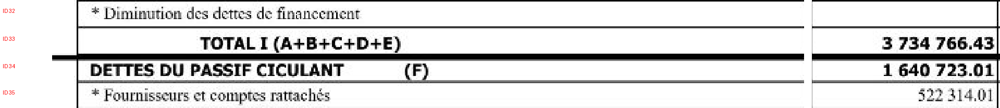

IDs attendus : [32, 33, 34, 35]
Statut Qwen : OK
EXTRACTION NON VALIDEE
```json
{
  "type_bilan": "PASSIF",
  "lignes": [
    {
      "id_ligne": "ID32",
      "poste": "* Diminution des dettes de financement",
      "valeur": null
    },
    {
      "id_ligne": "ID33",
      "poste": "TOTAL I (A+B+C+D+E)",
      "valeur": 3734766.43
    },
    {
      "id_ligne": "ID34",
      "poste": "DETTES DU PASSIF CICULANT (F)",
      "valeur": 1640723.01
    },
    {
      "id_ligne": "ID35",
      "poste": "* Fournisseurs et comptes rattachés",
      "valeur": 522314.01
    }
  ]
}
```

Aucun CSV final créé.


In [127]:

# ============================================================
# PASSIF N — BLOC 5 : IDs 32 A 39
# FONCTION REUTILISABLE POUR LES BLOCS SUIVANTS
# ============================================================

import math
import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

dossier_passif_N = Path(
    "/kaggle/working/extraction_passif_N"
)
dossier_passif_N.mkdir(parents=True, exist_ok=True)

if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

try:
    police_passif = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police_passif = ImageFont.load_default()


# ------------------------------------------------------------
# 1. CREATION DES IMAGES NUMEROTEES
# ------------------------------------------------------------

def creer_image_passif_N(bloc, debut, fin):

    image = Image.open(
        bloc["images"][colonne_N]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin] - bloc["y1"])

    partie = image.crop(
        (0, y1, image.width, y2)
    )

    marge = 100

    annotee = Image.new(
        "RGB",
        (partie.width + marge, partie.height),
        "white"
    )

    annotee.paste(partie, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for identifiant in range(debut, fin):

        haut = int(
            limites_y_passif[identifiant]
            - limites_y_passif[debut]
        )

        bas = int(
            limites_y_passif[identifiant + 1]
            - limites_y_passif[debut]
        )

        centre = (haut + bas) // 2

        dessin.text(
            (5, max(0, centre - 10)),
            f"ID {identifiant}",
            fill="red",
            font=police_passif
        )

    chemin = dossier_passif_N / (
        f"passif_N_{debut:02d}_{fin-1:02d}.png"
    )

    annotee.save(chemin)

    return chemin, annotee


# ------------------------------------------------------------
# 2. VALIDATION STRICTE
# ------------------------------------------------------------

def valider_lignes_passif(lignes, ids_attendus):

    if not isinstance(lignes, list):
        return False

    if len(lignes) != len(ids_attendus):
        return False

    for ligne in lignes:

        if not isinstance(ligne, dict):
            return False

        if not {"id_ligne", "poste", "valeur"}.issubset(ligne):
            return False

        if type(ligne["id_ligne"]) is not int:
            return False

        if not isinstance(ligne["poste"], str):
            return False

        valeur = ligne["valeur"]

        if valeur is not None:
            if type(valeur) not in (int, float):
                return False

            if not math.isfinite(valeur):
                return False

    return [
        l["id_ligne"] for l in lignes
    ] == ids_attendus


# ------------------------------------------------------------
# 3. FONCTION GENERALE D'EXTRACTION D'UN BLOC PASSIF
# ------------------------------------------------------------

def extraire_bloc_passif_N(numero_bloc):

    bloc = blocs_passif_finaux[numero_bloc - 1]

    debut_bloc = bloc["ligne_debut"]
    fin_bloc = bloc["ligne_fin"] + 1

    toutes_lignes = []

    for numero_partie, debut in enumerate(
        range(debut_bloc, fin_bloc, 4),
        start=1
    ):

        fin = min(debut + 4, fin_bloc)

        ids_attendus = list(range(debut, fin))
        cle = (numero_bloc, numero_partie)

        print(
            f"\n===== BLOC {numero_bloc} "
            f"— PARTIE {numero_partie} ====="
        )

        chemin, image_annotee = creer_image_passif_N(
            bloc, debut, fin
        )

        display(image_annotee)
        print("IDs attendus :", ids_attendus)

        # Réutiliser les résultats existants
        existant = resultats_passif_N_parties.get(cle)

        if valider_lignes_passif(existant, ids_attendus):

            print("Résultat existant réutilisé.")
            lignes = existant

        else:

            messages = [
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "image",
                            "image": chemin.resolve().as_uri(),
                            "max_pixels": 1600 * 28 * 28
                        },
                        {
                            "type": "text",
                            "text": f"""
Transcris fidèlement ce bloc du bilan PASSIF.

Chaque ID rouge représente une ligne physique.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : montant EXERCICE N.

Pour chaque ID, retourne :
- id_ligne : entier
- poste : texte réellement visible
- valeur : montant numérique ou null

REGLES :
1. Exactement {len(ids_attendus)} entrées.
2. Respecte strictement les IDs.
3. Conserve tous les postes et totaux.
4. Si une ligne est vide : poste="".
5. Si aucun montant n'est visible : null.
6. Si un montant existe, transcris-le.
7. N'invente aucun poste ni montant.
8. Ne calcule aucun montant.
9. Ne mélange pas N et N-1.
10. Les trois champs sont obligatoires.

Retourne uniquement un objet JSON avec :
"type_bilan": "PASSIF"
"lignes": tableau des entrées.

Chaque entrée contient obligatoirement :
"id_ligne", "poste", "valeur".
"""
                        }
                    ]
                }
            ]

            resultat = extraire_avec_vlm(
                messages,
                max_tokens=1000
            )

            lignes = recuperer_json_passif(resultat)

            print("Statut Qwen :", resultat["statut"])

            if not valider_lignes_passif(
                lignes, ids_attendus
            ):

                print("EXTRACTION NON VALIDEE")
                print(resultat["texte_brut"][:1000])

                return None

            # Conserver provisoirement
            resultats_passif_N_parties[cle] = lignes

        print("Validation structurelle : OK")
        display(pd.DataFrame(lignes))

        print(
            "Montants détectés :",
            sum(l["valeur"] is not None for l in lignes)
        )

        toutes_lignes.extend(lignes)

    # Vérifier la continuité des IDs
    assert [
        l["id_ligne"] for l in toutes_lignes
    ] == list(range(debut_bloc, fin_bloc))

    df_bloc = pd.DataFrame(toutes_lignes)

    print(
        f"\n===== BLOC {numero_bloc} COMPLET ====="
    )

    display(df_bloc)

    print("Nombre de lignes :", len(df_bloc))
    print("IDs : OK")
    print("Validation visuelle : A CONFIRMER")

    return df_bloc


# ------------------------------------------------------------
# 4. EXECUTER UNIQUEMENT LE BLOC 5
# ------------------------------------------------------------

assert len(blocs_passif_finaux) >= 5

df_passif_bloc5 = extraire_bloc_passif_N(5)

print("\nAucun CSV final créé.")


In [128]:

# ============================================================
# CORRECTION PASSIF N — BLOC 5, PARTIE 1
# IDs 32 A 35 — SANS NOUVELLE INFERENCE QWEN
# ============================================================

import re
import pandas as pd
from IPython.display import display

# 1. Réponse déjà obtenue de Qwen
lignes_brutes = [
    {
        "id_ligne": "ID32",
        "poste": "* Diminution des dettes de financement",
        "valeur": None
    },
    {
        "id_ligne": "ID33",
        "poste": "TOTAL I (A+B+C+D+E)",
        "valeur": 3734766.43
    },
    {
        "id_ligne": "ID34",
        "poste": "DETTES DU PASSIF CICULANT (F)",
        "valeur": 1640723.01
    },
    {
        "id_ligne": "ID35",
        "poste": "* Fournisseurs et comptes rattachés",
        "valeur": 522314.01
    }
]

# 2. Convertir uniquement les IDs
lignes_corrigees = []

for ligne in lignes_brutes:

    match = re.fullmatch(
        r"ID\s*(\d+)",
        ligne["id_ligne"],
        flags=re.IGNORECASE
    )

    assert match is not None, "ID non reconnu"

    lignes_corrigees.append({
        "id_ligne": int(match.group(1)),
        "poste": ligne["poste"],
        "valeur": ligne["valeur"]
    })

# 3. Vérifier le résultat
ids_attendus = [32, 33, 34, 35]

assert valider_lignes_passif(
    lignes_corrigees,
    ids_attendus
), "Structure invalide"

# 4. Conserver la partie récupérée
resultats_passif_N_parties[(5, 1)] = lignes_corrigees

# 5. Affichage
df_passif_5_1 = pd.DataFrame(lignes_corrigees)

print("===== BLOC 5 — PARTIE 1 CORRIGEE =====")
display(df_passif_5_1)

print("\nIDs :", df_passif_5_1["id_ligne"].tolist())
print("Structure : OK")
print("Montants détectés :", df_passif_5_1["valeur"].notna().sum())
print("Exactitude visuelle : A CONFIRMER")
print("Résultat conservé en mémoire.")
print("Aucune nouvelle inférence Qwen.")
print("Aucun CSV créé.")


===== BLOC 5 — PARTIE 1 CORRIGEE =====


,id_ligne,poste,valeur
0,32,* Diminution des dettes de financement,NaN
1,33,TOTAL I (A+B+C+D+E),3734766.43
2,34,DETTES DU PASSIF CICULANT (F),1640723.01
3,35,* Fournisseurs et comptes rattachés,522314.01



IDs : [32, 33, 34, 35]
Structure : OK
Montants détectés : 3
Exactitude visuelle : A CONFIRMER
Résultat conservé en mémoire.
Aucune nouvelle inférence Qwen.
Aucun CSV créé.


===== IMAGE PASSIF — IDs 36 A 39 =====


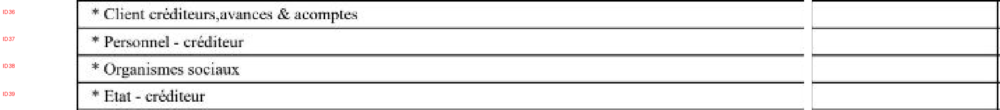

IDs attendus : [36, 37, 38, 39]

Statut initial : OK

===== PARTIE 2 EXTRAITE =====


,id_ligne,poste,valeur
0,36,"* Client créditeurs, avances & acomptés",None
1,37,* Personnel - créditeur,None
2,38,* Organismes sociaux,None
3,39,* État - créditeur,None



===== BLOC 5 COMPLET =====


,id_ligne,poste,valeur
0,32,* Diminution des dettes de financement,NaN
1,33,TOTAL I (A+B+C+D+E),3734766.43
2,34,DETTES DU PASSIF CICULANT (F),1640723.01
3,35,* Fournisseurs et comptes rattachés,522314.01
4,36,"* Client créditeurs, avances & acomptés",NaN
5,37,* Personnel - créditeur,NaN
6,38,* Organismes sociaux,NaN
7,39,* État - créditeur,NaN


Nombre de lignes : 8
Montants renseignés : 3
Validation structurelle : OK
Validation visuelle : A CONFIRMER

Aucun CSV final créé.


In [129]:

# ============================================================
# PASSIF N — BLOC 5, PARTIE 2 : IDs 36 A 39
# CORRECTION AUTOMATIQUE DU FORMAT DES IDs
# ============================================================

import re
import math
import pandas as pd
from pathlib import Path
from IPython.display import display

# 1. Vérifier que la partie 1 est conservée
assert (5, 1) in resultats_passif_N_parties

# 2. Sélectionner le bloc 5
bloc = blocs_passif_finaux[4]
ids_attendus = [36, 37, 38, 39]

# 3. Créer l'image numérotée
chemin, image_annotee = creer_image_passif_N(
    bloc, 36, 40
)

print("===== IMAGE PASSIF — IDs 36 A 39 =====")
display(image_annotee)
print("IDs attendus :", ids_attendus)

# 4. Préparer le prompt
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": Path(chemin).resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris fidèlement ces quatre lignes
du bilan PASSIF marocain.

IDs attendus : {ids_attendus}

La colonne gauche contient les postes.
La colonne droite contient EXERCICE N.

Pour chaque ligne retourne :
- id_ligne : entier sans préfixe ID
- poste : texte réellement visible
- valeur : montant visible ou null

RÈGLES :
1. Exactement quatre entrées.
2. Respecte strictement l'ordre des IDs.
3. Ne supprime aucun poste.
4. Ne décale pas les montants.
5. Une cellule vide correspond à null.
6. Ne calcule aucun montant.
7. N'invente aucune donnée.
8. Les trois champs sont obligatoires.

Retourne uniquement un JSON valide avec :
"type_bilan": "PASSIF"
"lignes": liste de quatre objets.

Chaque objet contient :
"id_ligne", "poste", "valeur".
"""
            }
        ]
    }
]

# 5. Une seule inférence Qwen
resultat_passif_5_2 = extraire_avec_vlm(
    messages,
    max_tokens=1000
)

print("\nStatut initial :", resultat_passif_5_2["statut"])

# 6. Extraire le JSON
lignes = recuperer_json_passif(
    resultat_passif_5_2
)

# 7. Normaliser uniquement le format des IDs
lignes_normalisees = []

if isinstance(lignes, list):

    for ligne in lignes:

        if not isinstance(ligne, dict):
            continue

        copie = ligne.copy()
        identifiant = copie.get("id_ligne")

        if type(identifiant) is str:

            match = re.fullmatch(
                r"(?:ID\s*)?(\d+)",
                identifiant.strip(),
                flags=re.IGNORECASE
            )

            if match:
                copie["id_ligne"] = int(match.group(1))

        lignes_normalisees.append(copie)

# 8. Validation stricte
valide = valider_lignes_passif(
    lignes_normalisees,
    ids_attendus
)

if valide:

    resultats_passif_N_parties[(5, 2)] = (
        lignes_normalisees
    )

    print("\n===== PARTIE 2 EXTRAITE =====")
    display(pd.DataFrame(lignes_normalisees))

    # 9. Fusionner avec les IDs 32 à 35
    lignes_bloc5 = (
        resultats_passif_N_parties[(5, 1)]
        + resultats_passif_N_parties[(5, 2)]
    )

    assert [
        ligne["id_ligne"] for ligne in lignes_bloc5
    ] == list(range(32, 40))

    df_passif_bloc5 = pd.DataFrame(lignes_bloc5)

    print("\n===== BLOC 5 COMPLET =====")
    display(df_passif_bloc5)

    print("Nombre de lignes :", len(df_passif_bloc5))
    print(
        "Montants renseignés :",
        df_passif_bloc5["valeur"].notna().sum()
    )

    print("Validation structurelle : OK")
    print("Validation visuelle : A CONFIRMER")

else:

    print("\nEXTRACTION NON VALIDEE")

    if lignes is not None:
        display(pd.DataFrame(lignes))

    print("\nRéponse brute :")
    print(resultat_passif_5_2["texte_brut"][:1200])

print("\nAucun CSV final créé.")


===== PASSIF N — BLOC 6 =====
IDs : 40 à 47

===== PARTIE 1 =====


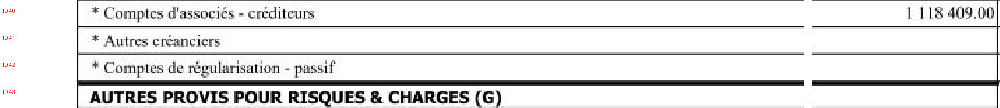

IDs attendus : [40, 41, 42, 43]
Statut Qwen : OK
EXTRACTION NON VALIDEE


,id_ligne,poste,valeur
0,40,* Comptes d'associés - créanciers,1 118 409.00
1,41,* Autres créanciers,None
2,42,* Comptes de régularisation - passif,None


```json
{
  "type_bilan": "PASSIF",
  "lignes": [
    {
      "id_ligne": 40,
      "poste": "* Comptes d'associés - créanciers",
      "valeur": "1 118 409.00"
    },
    {
      "id_ligne": 41,
      "poste": "* Autres créanciers",
      "valeur": null
    },
    {
      "id_ligne": 42,
      "poste": "* Comptes de régularisation - passif",
      "valeur": null
    }
  ]
}
```

BLOC 6 INCOMPLET.

Aucun CSV final créé.


In [130]:

# ============================================================
# PASSIF N — EXTRACTION DU BLOC 6
# AVEC NORMALISATION AUTOMATIQUE DES IDs
# ============================================================

import re
import pandas as pd
from pathlib import Path
from IPython.display import display

assert len(blocs_passif_finaux) >= 6

bloc = blocs_passif_finaux[5]
numero_bloc = bloc["numero_bloc"]

print("===== PASSIF N — BLOC 6 =====")
print("IDs :", bloc["ligne_debut"], "à", bloc["ligne_fin"])

resultats_bloc6 = []

# 1. Découper le bloc en parties de 4 lignes
for numero_partie, debut in enumerate(
    range(bloc["ligne_debut"], bloc["ligne_fin"] + 1, 4),
    start=1
):

    fin = min(debut + 4, bloc["ligne_fin"] + 1)
    ids_attendus = list(range(debut, fin))
    cle = (numero_bloc, numero_partie)

    print(f"\n===== PARTIE {numero_partie} =====")

    # 2. Créer l'image numérotée
    chemin, image_annotee = creer_image_passif_N(
        bloc, debut, fin
    )

    display(image_annotee)
    print("IDs attendus :", ids_attendus)

    # 3. Réutiliser une extraction existante
    lignes = resultats_passif_N_parties.get(cle)

    if not valider_lignes_passif(lignes, ids_attendus):

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": Path(chemin).resolve().as_uri(),
                        "max_pixels": 1600 * 28 * 28
                    },
                    {
                        "type": "text",
                        "text": f"""
Transcris exactement ce tableau du bilan PASSIF.

IDs rouges : {ids_attendus}

Colonne gauche : postes comptables.
Colonne droite : montants EXERCICE N.

Pour chaque ID, retourne :
- id_ligne : entier
- poste : texte visible ou ""
- valeur : montant visible ou null

Règles :
1. Une entrée pour chaque ID.
2. Respecte exactement l'ordre des lignes.
3. Lis les chiffres présents dans l'image.
4. Conserve les titres et les sous-totaux.
5. Si une cellule est vide, utilise null.
6. N'invente aucune donnée.
7. Ne calcule aucun montant.
8. Ne mélange pas N et N-1.
9. Les trois champs sont obligatoires.

Retourne uniquement un JSON valide contenant :
"type_bilan": "PASSIF"
"lignes": liste des entrées.
"""
                    }
                ]
            }
        ]

        # 4. Inférence Qwen
        resultat = extraire_avec_vlm(
            messages,
            max_tokens=1000
        )

        lignes = recuperer_json_passif(resultat)

        print("Statut Qwen :", resultat["statut"])

        # 5. Normaliser les IDs sans modifier les montants
        if isinstance(lignes, list):

            lignes_normalisees = []

            for ligne in lignes:

                if not isinstance(ligne, dict):
                    lignes_normalisees.append(ligne)
                    continue

                copie = ligne.copy()
                identifiant = copie.get("id_ligne")

                if isinstance(identifiant, str):

                    match = re.fullmatch(
                        r"(?:ID\s*)?(\d+)",
                        identifiant.strip(),
                        flags=re.IGNORECASE
                    )

                    if match:
                        copie["id_ligne"] = int(match.group(1))

                lignes_normalisees.append(copie)

            lignes = lignes_normalisees

    # 6. Validation stricte
    if valider_lignes_passif(lignes, ids_attendus):

        resultats_passif_N_parties[cle] = lignes

        print("Validation structurelle : OK")
        display(pd.DataFrame(lignes))

        resultats_bloc6.extend(lignes)

    else:

        print("EXTRACTION NON VALIDEE")

        if isinstance(lignes, list):
            display(pd.DataFrame(lignes))

        if "resultat" in locals():
            print(resultat["texte_brut"][:1000])

        break

# 7. Reconstruire le bloc complet
ids_bloc = list(range(
    bloc["ligne_debut"],
    bloc["ligne_fin"] + 1
))

if [l["id_ligne"] for l in resultats_bloc6] == ids_bloc:

    df_passif_bloc6 = pd.DataFrame(resultats_bloc6)

    print("\n===== BLOC 6 COMPLET =====")
    display(df_passif_bloc6)

    print("Lignes :", len(df_passif_bloc6))
    print(
        "Montants renseignés :",
        df_passif_bloc6["valeur"].notna().sum()
    )

    print("IDs : OK")
    print("Exactitude visuelle : A CONFIRMER")

else:
    print("\nBLOC 6 INCOMPLET.")

print("\nAucun CSV final créé.")


===== IDs 40 A 42 RECUPERES =====


,id_ligne,poste,valeur
0,40,* Comptes d'associés - créanciers,1118409.0
1,41,* Autres créanciers,NaN
2,42,* Comptes de régularisation - passif,NaN


Validation structurelle : OK
ID 43 : MANQUANT

===== CONTROLE COMPTABLE =====
Fournisseurs : 522314.01
Comptes d'associés : 1118409.0
Somme : 1640723.01
Total F extrait : 1640723.01
Ecart : 0.00

===== IMAGE DU BLOC 6 — IDs 40 A 43 =====


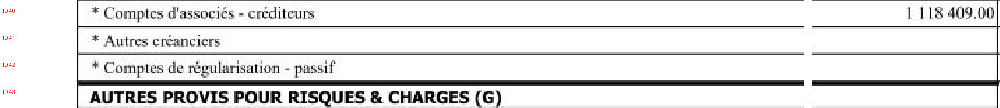


===== ZOOM ID 43 =====


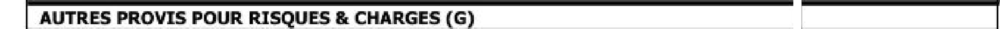


Aucune nouvelle inference Qwen.
Aucun CSV final cree.


In [131]:

# ============================================================
# PASSIF N — RECUPERATION DES IDs 40-42
# ET INSPECTION DE L'ID 43
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

import re
import pandas as pd
from decimal import Decimal
from IPython.display import display

# 1. Récupérer la dernière réponse Qwen
lignes_brutes = recuperer_json_passif(resultat)

assert isinstance(lignes_brutes, list), (
    "Réponse Qwen introuvable."
)

# 2. Fonction de normalisation
def normaliser_montant(valeur):

    if valeur is None:
        return None

    if isinstance(valeur, str):
        texte = valeur.strip()

        # Supprimer les espaces entre les chiffres
        texte = (
            texte.replace(" ", "")
            .replace("\u00a0", "")
            .replace("\u202f", "")
        )

        if not re.fullmatch(r"-?\d+(?:\.\d{1,2})?", texte):
            raise ValueError(
                f"Format de montant inconnu : {valeur}"
            )

        return float(Decimal(texte))

    if type(valeur) in (int, float):
        return float(valeur)

    raise ValueError(f"Type invalide : {type(valeur)}")


# 3. Normaliser les données déjà extraites
lignes_recuperees = []

for ligne in lignes_brutes:

    identifiant = ligne["id_ligne"]

    if isinstance(identifiant, str):
        match = re.fullmatch(
            r"(?:ID\s*)?(\d+)",
            identifiant.strip(),
            flags=re.IGNORECASE
        )
        assert match is not None
        identifiant = int(match.group(1))

    lignes_recuperees.append({
        "id_ligne": identifiant,
        "poste": ligne["poste"],
        "valeur": normaliser_montant(ligne["valeur"])
    })

# 4. Vérifier les trois IDs
assert valider_lignes_passif(
    lignes_recuperees,
    [40, 41, 42]
)

# 5. Sauvegarder sans déclarer le bloc complet
if "resultats_passif_N_partielles" not in globals():
    resultats_passif_N_partielles = {}

resultats_passif_N_partielles[(6, 1)] = (
    lignes_recuperees
)

df_passif_6_partiel = pd.DataFrame(
    lignes_recuperees
)

print("===== IDs 40 A 42 RECUPERES =====")
display(df_passif_6_partiel)

print("Validation structurelle : OK")
print("ID 43 : MANQUANT")

# 6. Vérification comptable indicative
valeur_40 = Decimal(
    str(df_passif_6_partiel.loc[
        df_passif_6_partiel["id_ligne"] == 40,
        "valeur"
    ].iloc[0])
)

fournisseurs = Decimal("522314.01")
total_F = Decimal("1640723.01")

somme = fournisseurs + valeur_40

print("\n===== CONTROLE COMPTABLE =====")
print("Fournisseurs :", fournisseurs)
print("Comptes d'associés :", valeur_40)
print("Somme :", somme)
print("Total F extrait :", total_F)
print("Ecart :", somme - total_F)

# 7. Afficher les lignes 40 à 43
bloc6 = blocs_passif_finaux[5]

chemin, image_annotee = creer_image_passif_N(
    bloc6, 40, 44
)

print("\n===== IMAGE DU BLOC 6 — IDs 40 A 43 =====")
display(image_annotee)

# 8. Afficher uniquement la ligne manquante
from PIL import Image

image_originale = Image.open(
    bloc6["images"][colonne_N]
).convert("RGB")

y1 = int(limites_y_passif[43] - bloc6["y1"])
y2 = int(limites_y_passif[44] - bloc6["y1"])

image_id43 = image_originale.crop(
    (0, y1, image_originale.width, y2)
)

print("\n===== ZOOM ID 43 =====")
display(image_id43.resize((
    image_id43.width * 2,
    image_id43.height * 2
)))

print("\nAucune nouvelle inference Qwen.")
print("Aucun CSV final cree.")


In [133]:

# ============================================================
# PASSIF N — CORRECTION BLOC 6, PARTIE 1
# IDs 40 A 43 — SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
from decimal import Decimal
from IPython.display import display

# 1. Récupérer les lignes 40 à 42 existantes
assert (6, 1) in resultats_passif_N_partielles, (
    "Les IDs 40 à 42 sont introuvables."
)

lignes_existantes = [
    ligne.copy()
    for ligne in resultats_passif_N_partielles[(6, 1)]
]

assert [
    ligne["id_ligne"] for ligne in lignes_existantes
] == [40, 41, 42]

# 2. Ajouter l'ID 43 vérifié visuellement
ligne_43 = {
    "id_ligne": 43,
    "poste": "AUTRES PROVIS POUR RISQUES & CHARGES (G)",
    "valeur": None
}

# 3. Reconstituer la partie 1
lignes_partie1 = lignes_existantes + [ligne_43]

# 4. Vérifier la structure
assert valider_lignes_passif(
    lignes_partie1,
    [40, 41, 42, 43]
), "Structure incorrecte."

# 5. Enregistrer le résultat corrigé
resultats_passif_N_parties[(6, 1)] = lignes_partie1

# 6. Afficher le tableau
df_passif_6_1 = pd.DataFrame(lignes_partie1)

print("===== BLOC 6 — PARTIE 1 CORRIGEE =====")
display(df_passif_6_1)

print("\n===== VERIFICATION =====")

print("Nombre de lignes :", len(df_passif_6_1))
print("IDs :", df_passif_6_1["id_ligne"].tolist())
print(
    "Montants renseignés :",
    df_passif_6_1["valeur"].notna().sum()
)

# 7. Contrôle comptable avec les valeurs extraites
fournisseurs = Decimal("522314.01")

associes = Decimal(str(
    df_passif_6_1.loc[
        df_passif_6_1["id_ligne"] == 40,
        "valeur"
    ].iloc[0]
))

total_F = Decimal("1640723.01")

ecart = fournisseurs + associes - total_F

print("\n===== CONTROLE DETTES CIRCULANTES =====")
print("Fournisseurs :", fournisseurs)
print("Comptes d'associés :", associes)
print("Total calculé :", fournisseurs + associes)
print("Total F extrait :", total_F)
print("Écart :", ecart)

assert abs(ecart) <= Decimal("0.01")

print("\nStructure des IDs : OK")
print("Contrôle arithmétique : OK")
print("ID 43 : corrigé par vérification visuelle")
print("Résultat conservé en mémoire.")
print("Aucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")


===== BLOC 6 — PARTIE 1 CORRIGEE =====


,id_ligne,poste,valeur
0,40,* Comptes d'associés - créanciers,1118409.0
1,41,* Autres créanciers,NaN
2,42,* Comptes de régularisation - passif,NaN
3,43,AUTRES PROVIS POUR RISQUES & CHARGES (G),NaN



===== VERIFICATION =====
Nombre de lignes : 4
IDs : [40, 41, 42, 43]
Montants renseignés : 1

===== CONTROLE DETTES CIRCULANTES =====
Fournisseurs : 522314.01
Comptes d'associés : 1118409.0
Total calculé : 1640723.01
Total F extrait : 1640723.01
Écart : 0.00

Structure des IDs : OK
Contrôle arithmétique : OK
ID 43 : corrigé par vérification visuelle
Résultat conservé en mémoire.
Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


===== IMAGE PASSIF N — IDs 44 A 47 =====


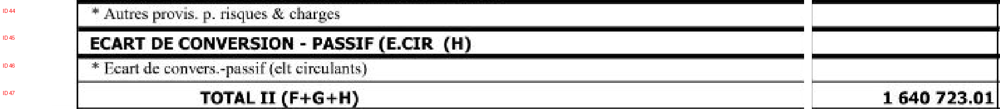

IDs attendus : [44, 45, 46, 47]

===== RESULTAT QWEN =====
Statut : OK
Tokens : 195

===== PARTIE 2 EXTRAITE =====


,id_ligne,poste,valeur
0,44,* Autres provis. p. risques & charges,NaN
1,45,E.CART DE CONVERSION - PASSIF (E.CIR (H)),NaN
2,46,* Ecart de convers.-passif (elt circulants),NaN
3,47,TOTAL II (F+G+H),1640723.01



===== BLOC 6 COMPLET =====


,id_ligne,poste,valeur
0,40,* Comptes d'associés - créanciers,1118409.00
1,41,* Autres créanciers,NaN
2,42,* Comptes de régularisation - passif,NaN
3,43,AUTRES PROVIS POUR RISQUES & CHARGES (G),NaN
4,44,* Autres provis. p. risques & charges,NaN
5,45,E.CART DE CONVERSION - PASSIF (E.CIR (H)),NaN
6,46,* Ecart de convers.-passif (elt circulants),NaN
7,47,TOTAL II (F+G+H),1640723.01



===== STATISTIQUES =====
Nombre de lignes : 8
Montants renseignés : 2
IDs : OK
Structure JSON : OK
Validation visuelle : A CONFIRMER

Aucun CSV final créé.


In [134]:

# ============================================================
# PASSIF N — BLOC 6, PARTIE 2 : IDs 44 A 47
# EXTRACTION QWEN2.5-VL
# ============================================================

import re
import math
import pandas as pd
from decimal import Decimal
from pathlib import Path
from IPython.display import display

# 1. Vérifier la première partie
assert (6, 1) in resultats_passif_N_parties

bloc = blocs_passif_finaux[5]
ids_attendus = [44, 45, 46, 47]

# 2. Créer et afficher l'image numérotée
chemin, image_annotee = creer_image_passif_N(
    bloc, 44, 48
)

print("===== IMAGE PASSIF N — IDs 44 A 47 =====")
display(image_annotee)
print("IDs attendus :", ids_attendus)

# 3. Préparer le prompt Qwen
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": Path(chemin).resolve().as_uri(),
                "max_pixels": 1600 * 28 * 28
            },
            {
                "type": "text",
                "text": f"""
Transcris fidèlement ces lignes du bilan PASSIF.

IDs rouges : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : montant EXERCICE N.

Pour chaque ID, retourne :
- id_ligne : entier
- poste : texte visible, ou ""
- valeur : montant numérique, ou null

RÈGLES :
1. Retourne exactement 4 lignes.
2. Respecte les IDs et leur ordre.
3. Conserve les rubriques et les totaux.
4. Transcris chaque montant réellement visible.
5. Si la cellule est vide, utilise null.
6. Ne décale aucun montant.
7. N'invente aucun poste.
8. Ne calcule aucune valeur.
9. Ne mélange pas N et N-1.
10. Tous les champs sont obligatoires.

Retourne uniquement un JSON valide contenant :
"type_bilan": "PASSIF"
"lignes": tableau des 4 objets.

Chaque objet possède :
"id_ligne", "poste", "valeur".
"""
            }
        ]
    }
]

# 4. Inférence uniquement sur cette partie
resultat_passif_6_2 = extraire_avec_vlm(
    messages,
    max_tokens=1000
)

print("\n===== RESULTAT QWEN =====")
print("Statut :", resultat_passif_6_2["statut"])
print("Tokens :", resultat_passif_6_2["nombre_tokens"])

# 5. Récupérer le JSON
lignes = recuperer_json_passif(resultat_passif_6_2)

# 6. Normaliser IDs et formats numériques
def normaliser_ligne_passif(ligne):

    copie = ligne.copy()

    identifiant = copie.get("id_ligne")

    if isinstance(identifiant, str):
        correspondance = re.fullmatch(
            r"(?:ID\s*)?(\d+)",
            identifiant.strip(),
            flags=re.IGNORECASE
        )

        if correspondance:
            copie["id_ligne"] = int(
                correspondance.group(1)
            )

    valeur = copie.get("valeur")

    if isinstance(valeur, str):

        texte = (
            valeur.strip()
            .replace("\u00a0", "")
            .replace("\u202f", "")
            .replace(" ", "")
        )

        if texte.lower() in ("", "null", "none"):
            copie["valeur"] = None

        else:
            # Formats acceptés :
            # 1188409.00 ou 1 188 409,00
            if re.fullmatch(
                r"-?\d+(?:[.,]\d{1,2})?",
                texte
            ):
                copie["valeur"] = float(
                    Decimal(texte.replace(",", "."))
                )

    return copie


lignes_normalisees = (
    [normaliser_ligne_passif(l) for l in lignes]
    if isinstance(lignes, list)
    and all(isinstance(l, dict) for l in lignes)
    else None
)

# 7. Validation stricte
valide = valider_lignes_passif(
    lignes_normalisees,
    ids_attendus
)

if valide:

    resultats_passif_N_parties[(6, 2)] = (
        lignes_normalisees
    )

    print("\n===== PARTIE 2 EXTRAITE =====")
    display(pd.DataFrame(lignes_normalisees))

    # 8. Fusionner les deux parties du bloc 6
    lignes_bloc6 = (
        resultats_passif_N_parties[(6, 1)]
        + resultats_passif_N_parties[(6, 2)]
    )

    assert valider_lignes_passif(
        lignes_bloc6,
        list(range(40, 48))
    )

    df_passif_bloc6 = pd.DataFrame(lignes_bloc6)

    print("\n===== BLOC 6 COMPLET =====")
    display(df_passif_bloc6)

    print("\n===== STATISTIQUES =====")
    print("Nombre de lignes :", len(df_passif_bloc6))
    print(
        "Montants renseignés :",
        df_passif_bloc6["valeur"].notna().sum()
    )
    print("IDs : OK")
    print("Structure JSON : OK")
    print("Validation visuelle : A CONFIRMER")

else:

    print("\n===== EXTRACTION NON VALIDEE =====")

    if isinstance(lignes_normalisees, list):
        display(pd.DataFrame(lignes_normalisees))

        print(
            "IDs obtenus :",
            [l.get("id_ligne") for l in lignes_normalisees]
        )

    print("\nRéponse brute :")
    print(resultat_passif_6_2["texte_brut"][:1500])

print("\nAucun CSV final créé.")


===== PASSIF N — BLOC 7 =====
IDs : [48, 49, 50, 51, 52, 53, 54]

===== PARTIE 1 =====


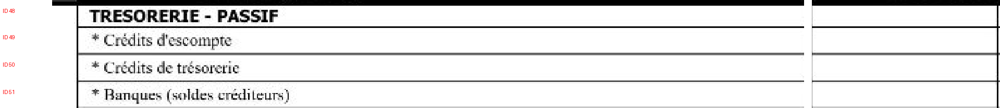

IDs attendus : [48, 49, 50, 51]
Statut Qwen : OK

VALIDATION STRUCTURELLE : OK


,id_ligne,poste,valeur
0,48,Crédits d'escompte,None
1,49,,None
2,50,Crédits de trésorerie,None
3,51,Banques (soldes créditeurs),None



===== PARTIE 2 =====


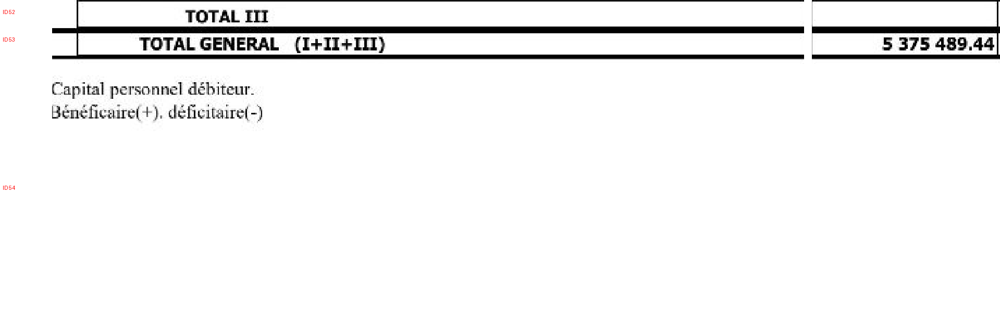

IDs attendus : [52, 53, 54]
Statut Qwen : OK

VALIDATION STRUCTURELLE : OK


,id_ligne,poste,valeur
0,52,TOTAL III,NaN
1,53,TOTAL GENERAL (I+II+III),5375489.44
2,54,Capital personnel débiteur.,NaN



===== BLOC 7 COMPLET =====


,id_ligne,poste,valeur
0,48,Crédits d'escompte,NaN
1,49,,NaN
2,50,Crédits de trésorerie,NaN
3,51,Banques (soldes créditeurs),NaN
4,52,TOTAL III,NaN
5,53,TOTAL GENERAL (I+II+III),5375489.44
6,54,Capital personnel débiteur.,NaN



===== STATISTIQUES =====
Nombre de lignes : 7
Montants renseignés : 1
IDs : OK
Validation visuelle : A CONFIRMER

===== PROGRESSION PASSIF =====
Nombre total de blocs : 7
Bloc actuel : 7

Aucun CSV final créé.


In [135]:

# ============================================================
# PASSIF N — EXTRACTION DU BLOC 7
# SANS REFAIRE LES BLOCS PRECEDENTS
# ============================================================

import re
import math
import pandas as pd
from pathlib import Path
from IPython.display import display

# 1. Vérifications
assert len(blocs_passif_finaux) >= 7, (
    "Le bloc 7 n'existe pas : vérifier "
    "le découpage OpenCV du PASSIF."
)

bloc = blocs_passif_finaux[6]

numero_bloc = bloc["numero_bloc"]
debut_bloc = bloc["ligne_debut"]
fin_bloc = bloc["ligne_fin"] + 1

print("===== PASSIF N — BLOC 7 =====")
print("IDs :", list(range(debut_bloc, fin_bloc)))

# 2. Conserver les résultats existants
if "resultats_passif_N_parties" not in globals():
    resultats_passif_N_parties = {}

lignes_bloc7 = []
erreurs_bloc7 = []

# 3. Extraire les groupes de 4 lignes
for numero_partie, debut in enumerate(
    range(debut_bloc, fin_bloc, 4),
    start=1
):

    fin = min(debut + 4, fin_bloc)

    ids_attendus = list(range(debut, fin))
    cle = (numero_bloc, numero_partie)

    print(f"\n===== PARTIE {numero_partie} =====")

    # Image numérotée
    chemin, image_annotee = creer_image_passif_N(
        bloc, debut, fin
    )

    display(image_annotee)
    print("IDs attendus :", ids_attendus)

    # Réutiliser une extraction existante
    lignes = resultats_passif_N_parties.get(cle)

    if valider_lignes_passif(lignes, ids_attendus):

        print("Extraction existante réutilisée.")

    else:

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": Path(chemin).resolve().as_uri(),
                        "max_pixels": 1600 * 28 * 28
                    },
                    {
                        "type": "text",
                        "text": f"""
Transcris exactement ce bloc du bilan PASSIF.

IDs rouges : {ids_attendus}

Colonne gauche : postes comptables.
Colonne droite : montants de l'EXERCICE N.

Retourne une entrée pour chaque ID avec :
- id_ligne : entier correspondant à l'ID
- poste : texte réellement visible ou ""
- valeur : montant visible ou null

CONSIGNES :
1. Respecte strictement l'ordre des IDs.
2. Retourne exactement {len(ids_attendus)} entrées.
3. Conserve toutes les rubriques et les totaux.
4. Si le montant est visible, transcris-le.
5. Si la cellule est vide, retourne null.
6. Si la ligne est entièrement vide,
   retourne poste="" et valeur=null.
7. Ne complète aucun montant par calcul.
8. N'invente aucun poste ou montant.
9. N'utilise pas les valeurs de N-1.
10. Tous les champs sont obligatoires.

Retourne uniquement un JSON valide contenant
"type_bilan": "PASSIF" et "lignes".

Chaque objet de "lignes" contient :
"id_ligne", "poste", "valeur".
"""
                    }
                ]
            }
        ]

        # Inférence Qwen
        resultat = extraire_avec_vlm(
            messages,
            max_tokens=1000
        )

        print("Statut Qwen :", resultat["statut"])

        lignes_brutes = recuperer_json_passif(
            resultat
        )

        # Normalisation des IDs et des montants
        if (
            isinstance(lignes_brutes, list)
            and all(
                isinstance(l, dict)
                for l in lignes_brutes
            )
        ):

            try:
                lignes = [
                    normaliser_ligne_passif(l)
                    for l in lignes_brutes
                ]
            except Exception as e:
                print("Erreur de normalisation :", e)
                lignes = None

        else:
            lignes = None

    # Validation stricte
    if valider_lignes_passif(
        lignes,
        ids_attendus
    ):

        resultats_passif_N_parties[cle] = lignes

        print("\nVALIDATION STRUCTURELLE : OK")
        display(pd.DataFrame(lignes))

        lignes_bloc7.extend(lignes)

    else:

        print("\nEXTRACTION NON VALIDEE")

        erreurs_bloc7.append({
            "partie": numero_partie,
            "ids": ids_attendus
        })

        if isinstance(lignes, list):
            display(pd.DataFrame(lignes))

        if "resultat" in locals():
            print(
                "Réponse brute :",
                resultat["texte_brut"][:1200]
            )

# 4. Reconstruire le bloc
df_passif_bloc7 = None

ids_complets = list(
    range(debut_bloc, fin_bloc)
)

if (
    not erreurs_bloc7
    and [l["id_ligne"] for l in lignes_bloc7]
        == ids_complets
):

    df_passif_bloc7 = pd.DataFrame(
        lignes_bloc7
    )

    print("\n===== BLOC 7 COMPLET =====")
    display(df_passif_bloc7)

    print("\n===== STATISTIQUES =====")
    print("Nombre de lignes :", len(df_passif_bloc7))
    print(
        "Montants renseignés :",
        df_passif_bloc7["valeur"].notna().sum()
    )
    print("IDs : OK")
    print("Validation visuelle : A CONFIRMER")

else:

    print("\n===== BLOC 7 INCOMPLET =====")
    display(pd.DataFrame(erreurs_bloc7))

print("\n===== PROGRESSION PASSIF =====")
print("Nombre total de blocs :", len(blocs_passif_finaux))
print("Bloc actuel :", numero_bloc)

print("\nAucun CSV final créé.")


In [136]:
total = len(blocs_passif_finaux)

print("Nombre total de blocs :", total)
print("Blocs terminés : 6")
print("Blocs restants :", total - 6)

Nombre total de blocs : 7
Blocs terminés : 6
Blocs restants : 1


In [137]:

# ============================================================
# FINALISATION DU PASSIF — EXERCICE N
# 1. Extraire uniquement les blocs restants
# 2. Corriger les formats JSON
# 3. Verifier tous les IDs
# 4. Fusionner les 7 blocs
# 5. Controler TOTAL ACTIF = TOTAL PASSIF
# 6. Aucun export CSV
# ============================================================

import re
import json
import math
import unicodedata
import pandas as pd

from decimal import Decimal
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# ------------------------------------------------------------
# 1. INITIALISATION
# ------------------------------------------------------------

assert len(blocs_passif_finaux) == 7
assert "resultats_passif_N_parties" in globals()
assert "df_actif_complet" in globals()

dossier = Path("/kaggle/working/passif_N_final")
dossier.mkdir(parents=True, exist_ok=True)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()


# ------------------------------------------------------------
# 2. NORMALISATION DES VALEURS
# ------------------------------------------------------------

def normaliser_montant_final(valeur):

    if valeur is None:
        return None

    if type(valeur) in (int, float):
        if not math.isfinite(valeur):
            raise ValueError("Montant non fini")
        return float(valeur)

    if not isinstance(valeur, str):
        raise ValueError(f"Type inattendu : {type(valeur)}")

    s = valeur.strip()

    if s.lower() in ("", "null", "none", "nan", "-"):
        return None

    s = (
        s.replace(" ", "")
        .replace("\u00a0", "")
        .replace("\u202f", "")
    )

    # Accepter notamment :
    # 1118409.00
    # 1 118 409.00
    # 1 118 409,00
    if "," in s and "." in s:
        if s.rfind(",") > s.rfind("."):
            s = s.replace(".", "").replace(",", ".")
        else:
            s = s.replace(",", "")
    elif "," in s:
        s = s.replace(",", ".")
    elif s.count(".") > 1:
        morceaux = s.split(".")
        s = "".join(morceaux[:-1]) + "." + morceaux[-1]

    if not re.fullmatch(r"-?\d+(?:\.\d{1,2})?", s):
        raise ValueError(f"Montant ambigu : {valeur}")

    return float(Decimal(s))


def normaliser_lignes_final(lignes):

    resultat = []

    if not isinstance(lignes, list):
        return None

    for ligne in lignes:

        if not isinstance(ligne, dict):
            return None

        if not {"id_ligne", "poste", "valeur"}.issubset(ligne):
            return None

        identifiant = ligne["id_ligne"]

        if isinstance(identifiant, str):
            match = re.fullmatch(
                r"(?:ID\s*)?(\d+)",
                identifiant.strip(),
                flags=re.IGNORECASE
            )

            if not match:
                return None

            identifiant = int(match.group(1))

        if type(identifiant) is not int:
            return None

        if not isinstance(ligne["poste"], str):
            return None

        try:
            valeur = normaliser_montant_final(
                ligne["valeur"]
            )
        except ValueError:
            return None

        resultat.append({
            "id_ligne": identifiant,
            "poste": ligne["poste"],
            "valeur": valeur
        })

    return resultat


def verifier_ids(lignes, ids_attendus):

    return (
        isinstance(lignes, list)
        and [l["id_ligne"] for l in lignes] == ids_attendus
    )


# ------------------------------------------------------------
# 3. CREER UNE IMAGE NUMEROTEE
# ------------------------------------------------------------

def image_segment_passif(bloc, debut, fin):

    image = Image.open(
        bloc["images"][colonne_N]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin] - bloc["y1"])

    partie = image.crop((0, y1, image.width, y2))

    marge = 100

    annotee = Image.new(
        "RGB",
        (partie.width + marge, partie.height),
        "white"
    )

    annotee.paste(partie, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for i in range(debut, fin):

        haut = limites_y_passif[i] - limites_y_passif[debut]
        bas = limites_y_passif[i + 1] - limites_y_passif[debut]

        dessin.text(
            (5, max(0, (haut + bas) // 2 - 10)),
            f"ID {i}",
            fill="red",
            font=police
        )

    chemin = dossier / f"passif_N_{debut}_{fin-1}.png"
    annotee.save(chemin)

    return chemin, annotee


# ------------------------------------------------------------
# 4. EXTRACTION AVEC DECOUPAGE AUTOMATIQUE
# ------------------------------------------------------------

def extraire_segment_passif(bloc, debut, fin):

    ids_attendus = list(range(debut, fin))

    chemin, image_annotee = image_segment_passif(
        bloc, debut, fin
    )

    print(f"\n===== EXTRACTION IDs {debut} A {fin-1} =====")
    display(image_annotee)

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": chemin.resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris fidèlement ce tableau comptable PASSIF.

IDs rouges attendus : {ids_attendus}

Colonne gauche : postes comptables.
Colonne droite : montants EXERCICE N.

Retourne une ligne pour chaque ID.

Champs obligatoires :
- id_ligne : entier
- poste : texte visible ou chaîne vide
- valeur : nombre visible ou null

RÈGLES :
1. Exactement {len(ids_attendus)} entrées.
2. Respecte les IDs et leur ordre.
3. Lis TOUS les montants visibles.
4. Conserve rubriques, détails et totaux.
5. Une cellule vide vaut null.
6. Une ligne vide a poste="" et valeur=null.
7. N'invente aucune donnée.
8. Ne calcule aucun montant.
9. Ne mélange pas N et N-1.

Retourne uniquement un objet JSON :
"type_bilan": "PASSIF"
"lignes": liste contenant les champs ci-dessus.
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=1000
    )

    lignes_brutes = recuperer_json_passif(resultat)
    lignes = normaliser_lignes_final(lignes_brutes)

    if verifier_ids(lignes, ids_attendus):

        print("Statut : OK")
        display(pd.DataFrame(lignes))

        return lignes

    print("Extraction incomplete : subdivision nécessaire.")
    print("Statut Qwen :", resultat["statut"])

    # Réessayer par moitiés sans insérer de valeurs
    if fin - debut > 1:

        milieu = (debut + fin) // 2

        gauche = extraire_segment_passif(
            bloc, debut, milieu
        )

        droite = extraire_segment_passif(
            bloc, milieu, fin
        )

        if gauche is not None and droite is not None:
            return gauche + droite

    print("ID non validé :", ids_attendus)
    return None


# ------------------------------------------------------------
# 5. TERMINER UNIQUEMENT LE BLOC 7
# ------------------------------------------------------------

bloc7 = blocs_passif_finaux[6]

debut_bloc = bloc7["ligne_debut"]
fin_bloc = bloc7["ligne_fin"] + 1

print("===== FINALISATION DU BLOC 7 =====")
print("IDs :", list(range(debut_bloc, fin_bloc)))

erreurs = []

for numero_partie, debut in enumerate(
    range(debut_bloc, fin_bloc, 4),
    start=1
):

    fin = min(debut + 4, fin_bloc)
    cle = (7, numero_partie)

    ids_attendus = list(range(debut, fin))

    # Réutiliser les extractions déjà réussies
    existant = normaliser_lignes_final(
        resultats_passif_N_parties.get(cle)
    )

    if verifier_ids(existant, ids_attendus):

        print(f"Partie {numero_partie} : cache OK")
        continue

    lignes = extraire_segment_passif(
        bloc7, debut, fin
    )

    if verifier_ids(lignes, ids_attendus):

        resultats_passif_N_parties[cle] = lignes

        print(
            f"Partie {numero_partie} : "
            "conservée en mémoire"
        )

    else:

        erreurs.append({
            "bloc": 7,
            "partie": numero_partie,
            "ids": ids_attendus
        })


# ------------------------------------------------------------
# 6. RECONSTRUIRE LES 7 BLOCS DU PASSIF N
# ------------------------------------------------------------

print("\n===== RECONSTRUCTION COMPLETE DU PASSIF N =====")

toutes_lignes = []
blocs_incomplets = []

for bloc in blocs_passif_finaux:

    numero = bloc["numero_bloc"]
    debut = bloc["ligne_debut"]
    fin = bloc["ligne_fin"] + 1

    lignes_bloc = []

    for numero_partie, d in enumerate(
        range(debut, fin, 4),
        start=1
    ):

        f = min(d + 4, fin)
        cle = (numero, numero_partie)

        lignes = normaliser_lignes_final(
            resultats_passif_N_parties.get(cle)
        )

        if not verifier_ids(lignes, list(range(d, f))):

            blocs_incomplets.append({
                "bloc": numero,
                "partie": numero_partie,
                "ids": list(range(d, f))
            })

        else:
            lignes_bloc.extend(lignes)

    if [l["id_ligne"] for l in lignes_bloc] == list(
        range(debut, fin)
    ):

        toutes_lignes.extend(lignes_bloc)

        print(
            f"Bloc {numero} : OK | "
            f"{len(lignes_bloc)} lignes"
        )

    else:
        print(f"Bloc {numero} : INCOMPLET")


# ------------------------------------------------------------
# 7. VERIFIER LA COMPLETUDE
# ------------------------------------------------------------

df_passif_N = None

if blocs_incomplets or erreurs:

    print("\n===== ELEMENTS A CORRIGER =====")
    display(pd.DataFrame(blocs_incomplets + erreurs))

    print("Reconstruction suspendue.")

else:

    df_passif_N = pd.DataFrame(
        toutes_lignes
    ).sort_values(
        "id_ligne"
    ).reset_index(drop=True)

    ids_attendus = list(
        range(len(limites_y_passif) - 1)
    )

    assert (
        df_passif_N["id_ligne"].tolist()
        == ids_attendus
    ), "IDs incomplets ou dupliqués."

    print("\n===== PASSIF N COMPLET =====")
    display(df_passif_N)

    print("\nNombre de positions :", len(df_passif_N))
    print("IDs uniques :", df_passif_N["id_ligne"].nunique())

    print(
        "Montants renseignés :",
        df_passif_N["valeur"].notna().sum()
    )

    # --------------------------------------------------------
    # 8. DETECTER LES TOTAUX
    # --------------------------------------------------------

    def sans_accents(texte):
        texte = unicodedata.normalize(
            "NFKD", str(texte)
        )
        return "".join(
            c for c in texte
            if not unicodedata.combining(c)
        ).upper().strip()

    df_passif_N["poste_normalise"] = (
        df_passif_N["poste"].apply(sans_accents)
    )

    print("\n===== TOTAUX DETECTES =====")

    totaux = df_passif_N[
        df_passif_N["poste_normalise"].str.contains(
            r"TOTAL\s+(?:I\b|II\b|III\b|GENERAL\b)",
            regex=True
        )
    ]

    display(
        totaux[["id_ligne", "poste", "valeur"]]
    )

    # --------------------------------------------------------
    # 9. VERIFIER TOTAL PASSIF = TOTAL ACTIF
    # --------------------------------------------------------

    print("\n===== CONTROLE ACTIF = PASSIF =====")

    total_actif = df_actif_complet.loc[
        df_actif_complet["id_ligne"] == 52,
        "net_N"
    ].iloc[0]

    total_general_passif = df_passif_N[
        df_passif_N["poste_normalise"].str.contains(
            r"TOTAL\s+GENERAL\b",
            regex=True
        )
    ]

    if (
        len(total_general_passif) == 1
        and pd.notna(total_general_passif["valeur"].iloc[0])
    ):

        total_passif = total_general_passif[
            "valeur"
        ].iloc[0]

        actif = Decimal(str(total_actif)).quantize(
            Decimal("0.01")
        )

        passif = Decimal(str(total_passif)).quantize(
            Decimal("0.01")
        )

        ecart = actif - passif

        print("TOTAL ACTIF N :", actif)
        print("TOTAL PASSIF N :", passif)
        print("ECART :", ecart)

        if abs(ecart) <= Decimal("0.01"):
            print("CONTROLE ACTIF = PASSIF : OK")
        else:
            print("CONTROLE ACTIF = PASSIF : ECHEC")

    else:
        print(
            "TOTAL GENERAL PASSIF absent ou ambigu : "
            "validation suspendue."
        )

    # --------------------------------------------------------
    # 10. CONTROLE DES TOTAUX I, II, III
    # --------------------------------------------------------

    print("\n===== CONTROLE DES SOUS-TOTAUX =====")

    montants_totaux = {}

    for cle, motif in {
        "I": r"^TOTAL\s+I\b",
        "II": r"^TOTAL\s+II\b",
        "III": r"^TOTAL\s+III\b"
    }.items():

        selection = df_passif_N[
            df_passif_N["poste_normalise"].str.contains(
                motif, regex=True
            )
        ]

        if len(selection) == 1:
            montants_totaux[cle] = selection[
                "valeur"
            ].iloc[0]
        else:
            montants_totaux[cle] = None

    print("TOTAL I :", montants_totaux["I"])
    print("TOTAL II :", montants_totaux["II"])
    print("TOTAL III :", montants_totaux["III"])

    if all(
        v is not None and pd.notna(v)
        for v in montants_totaux.values()
    ):

        somme = sum(
            Decimal(str(v))
            for v in montants_totaux.values()
        )

        print("Somme TOTAL I + II + III :", somme)

    else:
        print(
            "Un sous-total est vide ou absent : "
            "aucun zéro supposé."
        )

    # Retirer la colonne technique du tableau final
    df_passif_N = df_passif_N.drop(
        columns=["poste_normalise"]
    )

print("\n===== FIN DU TEST =====")
print("Aucune nouvelle extraction des blocs 1 à 6.")
print("Aucun CSV final créé.")


===== FINALISATION DU BLOC 7 =====
IDs : [48, 49, 50, 51, 52, 53, 54]
Partie 1 : cache OK
Partie 2 : cache OK

===== RECONSTRUCTION COMPLETE DU PASSIF N =====
Bloc 1 : OK | 8 lignes
Bloc 2 : OK | 8 lignes
Bloc 3 : OK | 8 lignes
Bloc 4 : OK | 8 lignes
Bloc 5 : OK | 8 lignes
Bloc 6 : OK | 8 lignes
Bloc 7 : OK | 7 lignes

===== PASSIF N COMPLET =====


,id_ligne,poste,valeur
0,0,,NaN
1,1,PASSIF,NaN
2,2,CAPITAUX PROPRES,905436.35
3,3,* Capital social ou personnel (1),100000.00
4,4,"Moins:actionn., capit.souscr.non appelé (-)",NaN
5,5,"* Primes d'émission,de fusion d'apport",NaN
6,6,* Ecart de réévaluation,NaN
7,7,* Réserve légale,NaN
8,8,* Autres réserves,NaN
9,9,* Report à nouveau (2),362605.74



Nombre de positions : 55
IDs uniques : 55
Montants renseignés : 13

===== TOTAUX DETECTES =====


,id_ligne,poste,valeur
33,33,TOTAL I (A+B+C+D+E),3734766.43
47,47,TOTAL II (F+G+H),1640723.01
52,52,TOTAL III,NaN
53,53,TOTAL GENERAL (I+II+III),5375489.44



===== CONTROLE ACTIF = PASSIF =====
TOTAL ACTIF N : 5375489.44
TOTAL PASSIF N : 5375489.44
ECART : 0.00
CONTROLE ACTIF = PASSIF : OK

===== CONTROLE DES SOUS-TOTAUX =====
TOTAL I : 3734766.43
TOTAL II : 1640723.01
TOTAL III : nan
Un sous-total est vide ou absent : aucun zéro supposé.

===== FIN DU TEST =====
Aucune nouvelle extraction des blocs 1 à 6.
Aucun CSV final créé.


In [138]:

# ============================================================
# EXTRACTION COMPLETE PASSIF — EXERCICE N-1
# OPENCV + QWEN2.5-VL + VALIDATION DES IDs
# SANS REFAIRE L'EXERCICE N
# ============================================================

import re
import math
import pandas as pd

from decimal import Decimal
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# ------------------------------------------------------------
# 1. VERIFICATIONS INITIALES
# ------------------------------------------------------------

assert "df_passif_N" in globals()
assert df_passif_N is not None
assert "df_actif_complet" in globals()
assert len(blocs_passif_finaux) == 7

# Identifier la colonne N-1 par opposition à N
colonnes = list(images_colonnes_passif.keys())

colonnes_N1 = [
    nom for nom in colonnes
    if nom != colonne_N
]

assert len(colonnes_N1) == 1

colonne_N1 = colonnes_N1[0]

print("Colonne N :", colonne_N)
print("Colonne N-1 :", colonne_N1)

reference_passif = df_passif_N.set_index(
    "id_ligne"
)["poste"].to_dict()

dossier_N1 = Path(
    "/kaggle/working/passif_N1_final"
)
dossier_N1.mkdir(parents=True, exist_ok=True)

if "cache_passif_N1" not in globals():
    cache_passif_N1 = {}

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

# ------------------------------------------------------------
# 2. NORMALISATION DES MONTANTS
# ------------------------------------------------------------

def convertir_montant_N1(valeur):

    if valeur is None:
        return None

    if type(valeur) in (int, float):
        if not math.isfinite(valeur):
            raise ValueError("Montant non fini")
        return float(valeur)

    if not isinstance(valeur, str):
        raise ValueError("Type numérique invalide")

    texte = (
        valeur.strip()
        .replace("\u00a0", "")
        .replace("\u202f", "")
        .replace(" ", "")
    )

    if texte.lower() in ("", "null", "none", "nan", "-"):
        return None

    # Accepter 1 938 167,80 et 1 938 167.80
    if "," in texte and "." in texte:
        if texte.rfind(",") > texte.rfind("."):
            texte = texte.replace(".", "").replace(",", ".")
        else:
            texte = texte.replace(",", "")
    elif "," in texte:
        texte = texte.replace(",", ".")

    if not re.fullmatch(
        r"-?\d+(?:\.\d{1,2})?",
        texte
    ):
        raise ValueError(
            f"Montant ambigu : {valeur}"
        )

    return float(Decimal(texte))


def normaliser_lignes_N1(lignes):

    if not isinstance(lignes, list):
        return None

    normalisees = []

    try:
        for ligne in lignes:

            if not isinstance(ligne, dict):
                return None

            if not {"id_ligne", "poste", "valeur"}.issubset(ligne):
                return None

            identifiant = ligne["id_ligne"]

            if isinstance(identifiant, str):
                match = re.fullmatch(
                    r"(?:ID\s*)?(\d+)",
                    identifiant.strip(),
                    flags=re.IGNORECASE
                )

                if match is None:
                    return None

                identifiant = int(match.group(1))

            if type(identifiant) is not int:
                return None

            if not isinstance(ligne["poste"], str):
                return None

            normalisees.append({
                "id_ligne": identifiant,
                "poste_lu_vlm": ligne["poste"],
                "valeur": convertir_montant_N1(
                    ligne["valeur"]
                )
            })

    except (ValueError, TypeError):
        return None

    return normalisees

# ------------------------------------------------------------
# 3. CREER L'IMAGE NUMEROTEE D'UN SEGMENT
# ------------------------------------------------------------

def creer_image_passif_N1(bloc, debut, fin):

    image = Image.open(
        bloc["images"][colonne_N1]
    ).convert("RGB")

    y1 = int(
        limites_y_passif[debut] - bloc["y1"]
    )
    y2 = int(
        limites_y_passif[fin] - bloc["y1"]
    )

    image_coupee = image.crop(
        (0, y1, image.width, y2)
    )

    marge = 100

    image_annotee = Image.new(
        "RGB",
        (
            image_coupee.width + marge,
            image_coupee.height
        ),
        "white"
    )

    image_annotee.paste(
        image_coupee,
        (marge, 0)
    )

    dessin = ImageDraw.Draw(image_annotee)

    for identifiant in range(debut, fin):

        haut = int(
            limites_y_passif[identifiant]
            - limites_y_passif[debut]
        )

        bas = int(
            limites_y_passif[identifiant + 1]
            - limites_y_passif[debut]
        )

        centre = (haut + bas) // 2

        dessin.text(
            (5, max(0, centre - 10)),
            f"ID {identifiant}",
            fill="red",
            font=police
        )

    chemin = dossier_N1 / (
        f"net_N1_ids_{debut:02d}_{fin-1:02d}.png"
    )

    image_annotee.save(chemin)

    return chemin

# ------------------------------------------------------------
# 4. EXTRACTION AVEC DECOUPAGE AUTOMATIQUE
# ------------------------------------------------------------

def extraire_segment_N1(bloc, debut, fin):

    ids_attendus = list(range(debut, fin))
    cle = (debut, fin)

    # Réutiliser uniquement les résultats structurellement OK
    if cle in cache_passif_N1:
        lignes_cache = cache_passif_N1[cle]

        if [
            l["id_ligne"] for l in lignes_cache
        ] == ids_attendus:

            print(f"IDs {debut}-{fin-1} : cache OK")
            return lignes_cache

    chemin = creer_image_passif_N1(
        bloc, debut, fin
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": Path(chemin).resolve().as_uri(),
                    "max_pixels": 1600 * 28 * 28
                },
                {
                    "type": "text",
                    "text": f"""
Transcris les lignes de ce bilan PASSIF.

Chaque ID rouge représente une ligne.

IDs attendus : {ids_attendus}

Colonne gauche : poste comptable.
Colonne droite : EXERCICE PRECEDENT N-1.

Pour chaque ID, retourne :
- id_ligne : numéro rouge
- poste : texte visible
- valeur : montant de N-1 ou null

CONSIGNES :
1. Retourne exactement {len(ids_attendus)} entrées.
2. Respecte tous les IDs et leur ordre.
3. Transcris les montants réellement visibles.
4. Si une cellule est vide, utilise null.
5. Conserve les rubriques et les totaux.
6. Si la ligne est vide, poste="".
7. N'invente aucune valeur.
8. Ne calcule aucun montant.
9. Ne copie aucun montant de l'exercice N.
10. Chaque entrée contient les trois champs.

Retourne uniquement un JSON valide avec :
"type_bilan": "PASSIF"
"lignes": liste des entrées.
"""
                }
            ]
        }
    ]

    resultat = extraire_avec_vlm(
        messages,
        max_tokens=850
    )

    lignes_brutes = recuperer_json_passif(
        resultat
    )

    lignes = normaliser_lignes_N1(
        lignes_brutes
    )

    # Contrôle des IDs exacts
    valide = (
        isinstance(lignes, list)
        and [l["id_ligne"] for l in lignes]
        == ids_attendus
    )

    if valide:

        cache_passif_N1[cle] = lignes

        print(
            f"IDs {debut}-{fin-1} : OK | "
            f"{len(lignes)} lignes"
        )

        return lignes

    # En cas d'échec, diviser en deux
    if fin - debut > 1:

        milieu = (debut + fin) // 2

        print(
            f"IDs {debut}-{fin-1} : "
            "échec, division"
        )

        partie1 = extraire_segment_N1(
            bloc, debut, milieu
        )

        partie2 = extraire_segment_N1(
            bloc, milieu, fin
        )

        if partie1 is not None and partie2 is not None:

            lignes = partie1 + partie2
            cache_passif_N1[cle] = lignes

            return lignes

    print(
        f"ID {debut} : EXTRACTION NON VALIDEE"
    )

    return None

# ------------------------------------------------------------
# 5. EXTRAIRE TOUS LES BLOCS PASSIF N-1
# ------------------------------------------------------------

toutes_lignes_N1 = []
erreurs_N1 = []

for bloc in blocs_passif_finaux:

    numero = bloc["numero_bloc"]
    debut_bloc = bloc["ligne_debut"]
    fin_bloc = bloc["ligne_fin"] + 1

    print(f"\n===== PASSIF N-1 — BLOC {numero} =====")

    for debut in range(
        debut_bloc,
        fin_bloc,
        4
    ):

        fin = min(debut + 4, fin_bloc)

        lignes = extraire_segment_N1(
            bloc, debut, fin
        )

        if lignes is None:

            erreurs_N1.append({
                "bloc": numero,
                "debut": debut,
                "fin": fin - 1
            })

        else:
            toutes_lignes_N1.extend(lignes)

# ------------------------------------------------------------
# 6. RECONSTRUIRE PASSIF N-1
# ------------------------------------------------------------

df_passif_N1 = None

if erreurs_N1:

    print("\n===== BLOCS NON VALIDES =====")
    display(pd.DataFrame(erreurs_N1))

    print("Reconstruction N-1 suspendue.")

else:

    df_resultats = pd.DataFrame(
        toutes_lignes_N1
    ).sort_values("id_ligne").reset_index(drop=True)

    # Même structure physique que PASSIF N
    ids_reference = df_passif_N[
        "id_ligne"
    ].tolist()

    assert (
        df_resultats["id_ligne"].tolist()
        == ids_reference
    ), "IDs manquants ou dupliqués."

    # Réutiliser les noms du PASSIF N
    df_passif_N1 = df_resultats[
        ["id_ligne", "poste_lu_vlm", "valeur"]
    ].copy()

    df_passif_N1["poste"] = (
        df_passif_N1["id_ligne"]
        .map(reference_passif)
    )

    df_passif_N1.rename(
        columns={"valeur": "exercice_N1"},
        inplace=True
    )

    df_passif_N1 = df_passif_N1[
        [
            "id_ligne",
            "poste",
            "exercice_N1",
            "poste_lu_vlm"
        ]
    ]

    print("\n===== PASSIF N-1 — MONTANTS EXTRAITS =====")

    display(
        df_passif_N1[
            df_passif_N1["exercice_N1"].notna()
        ][
            ["id_ligne", "poste", "exercice_N1"]
        ]
    )

    print("\n===== STATISTIQUES =====")
    print("Positions :", len(df_passif_N1))
    print(
        "Montants renseignés :",
        df_passif_N1["exercice_N1"].notna().sum()
    )

    # --------------------------------------------------------
    # 7. VERIFIER LES TOTAUX
    # --------------------------------------------------------

    print("\n===== TOTAUX PASSIF N-1 =====")

    ids_totaux = [33, 47, 52, 53]

    display(
        df_passif_N1[
            df_passif_N1["id_ligne"].isin(ids_totaux)
        ][
            ["id_ligne", "poste", "exercice_N1"]
        ]
    )

    valeurs = df_passif_N1.set_index(
        "id_ligne"
    )["exercice_N1"]

    def dec(valeur):
        if pd.isna(valeur):
            return None
        return Decimal(str(valeur)).quantize(
            Decimal("0.01")
        )

    total_I = dec(valeurs.loc[33])
    total_II = dec(valeurs.loc[47])
    total_III = dec(valeurs.loc[52])
    total_general = dec(valeurs.loc[53])

    print("\nTOTAL I :", total_I)
    print("TOTAL II :", total_II)
    print("TOTAL III :", total_III)
    print("TOTAL GENERAL :", total_general)

    if all(
        x is not None
        for x in [total_I, total_II, total_general]
    ):

        reste = (
            total_general
            - total_I
            - total_II
        )

        print(
            "\nRésidu TOTAL GENERAL - (I + II) :",
            reste
        )

        if total_III is not None:
            print(
                "Écart avec TOTAL III :",
                reste - total_III
            )
        else:
            print(
                "TOTAL III est vide dans l'extraction. "
                "Aucune valeur insérée."
            )

    # --------------------------------------------------------
    # 8. VERIFIER ACTIF N-1 = PASSIF N-1
    # --------------------------------------------------------

    print("\n===== CONTROLE ACTIF = PASSIF N-1 =====")

    actif_N1 = dec(
        df_actif_complet.loc[
            df_actif_complet["id_ligne"] == 52,
            "net_N1"
        ].iloc[0]
    )

    if total_general is not None:

        ecart = actif_N1 - total_general

        print("TOTAL ACTIF N-1 :", actif_N1)
        print("TOTAL PASSIF N-1 :", total_general)
        print("ECART :", ecart)

        if abs(ecart) <= Decimal("0.01"):
            print("CONTROLE ACTIF = PASSIF N-1 : OK")
        else:
            print("CONTROLE ACTIF = PASSIF N-1 : ECHEC")

    else:
        print("TOTAL PASSIF N-1 manquant.")

    # --------------------------------------------------------
    # 9. FUSION PROVISOIRE DU PASSIF N ET N-1
    # --------------------------------------------------------

    df_passif_complet = (
        df_passif_N[
            ["id_ligne", "poste", "valeur"]
        ]
        .rename(
            columns={"valeur": "exercice_N"}
        )
        .merge(
            df_passif_N1[
                ["id_ligne", "exercice_N1"]
            ],
            on="id_ligne",
            validate="one_to_one"
        )
    )

    print("\n===== PASSIF N ET N-1 FUSIONNES =====")
    display(df_passif_complet)

    print("\nFusion réalisée en mémoire.")
    print("Validation visuelle finale encore nécessaire.")

print("\nAucun CSV final créé.")


Colonne N : montant_N
Colonne N-1 : montant_N1

===== PASSIF N-1 — BLOC 1 =====
IDs 0-3 : OK | 4 lignes
IDs 4-7 : OK | 4 lignes

===== PASSIF N-1 — BLOC 2 =====
IDs 8-11 : OK | 4 lignes
IDs 12-15 : OK | 4 lignes

===== PASSIF N-1 — BLOC 3 =====
IDs 16-19 : OK | 4 lignes
IDs 20-23 : OK | 4 lignes

===== PASSIF N-1 — BLOC 4 =====
IDs 24-27 : OK | 4 lignes
IDs 28-31 : OK | 4 lignes

===== PASSIF N-1 — BLOC 5 =====
IDs 32-35 : OK | 4 lignes
IDs 36-39 : OK | 4 lignes

===== PASSIF N-1 — BLOC 6 =====
IDs 40-43 : OK | 4 lignes
IDs 44-47 : OK | 4 lignes

===== PASSIF N-1 — BLOC 7 =====
IDs 48-51 : OK | 4 lignes
IDs 52-54 : OK | 3 lignes

===== PASSIF N-1 — MONTANTS EXTRAITS =====


,id_ligne,poste,exercice_N1
1,1,PASSIF,-37394.26
3,3,* Capital social ou personnel (1),100000.00
9,9,* Report à nouveau (2),-18488.90
11,11,* Résultat net de l'exercice (2),-118905.36
12,12,TOTAL DES CAPITAUX PROPRES,-37394.26
22,22,* Autres dettes de financement,4534451.32
33,33,TOTAL I (A+B+C+D+E),4497057.06
34,34,DETTES DU PASSIF CICULANT (F),1938167.80
35,35,* Fournisseurs et comptes rattachés,819758.80
40,40,* Comptes d'associés - créanciers,1118409.00



===== STATISTIQUES =====
Positions : 55
Montants renseignés : 12

===== TOTAUX PASSIF N-1 =====


,id_ligne,poste,exercice_N1
33,33,TOTAL I (A+B+C+D+E),4497057.06
47,47,TOTAL II (F+G+H),1938167.80
52,52,TOTAL III,NaN
53,53,TOTAL GENERAL (I+II+III),6435224.86



TOTAL I : 4497057.06
TOTAL II : 1938167.80
TOTAL III : None
TOTAL GENERAL : 6435224.86

Résidu TOTAL GENERAL - (I + II) : 0.00
TOTAL III est vide dans l'extraction. Aucune valeur insérée.

===== CONTROLE ACTIF = PASSIF N-1 =====
TOTAL ACTIF N-1 : 6435224.86
TOTAL PASSIF N-1 : 6435224.86
ECART : 0.00
CONTROLE ACTIF = PASSIF N-1 : OK

===== PASSIF N ET N-1 FUSIONNES =====


,id_ligne,poste,exercice_N,exercice_N1
0,0,,NaN,NaN
1,1,PASSIF,NaN,-37394.26
2,2,CAPITAUX PROPRES,905436.35,NaN
3,3,* Capital social ou personnel (1),100000.00,100000.00
4,4,"Moins:actionn., capit.souscr.non appelé (-)",NaN,NaN
5,5,"* Primes d'émission,de fusion d'apport",NaN,NaN
6,6,* Ecart de réévaluation,NaN,NaN
7,7,* Réserve légale,NaN,NaN
8,8,* Autres réserves,NaN,NaN
9,9,* Report à nouveau (2),362605.74,-18488.90



Fusion réalisée en mémoire.
Validation visuelle finale encore nécessaire.

Aucun CSV final créé.


===== DONNEES ACTUELLES =====


,id_ligne,poste,exercice_N,exercice_N1
1,1,PASSIF,NaN,-37394.26
2,2,CAPITAUX PROPRES,905436.35,NaN
20,20,DETTES DE FINANCEMENT (C),2829330.08,NaN
22,22,* Autres dettes de financement,2829330.08,4534451.32



===== VERIFICATION IDs 1 A 3 =====


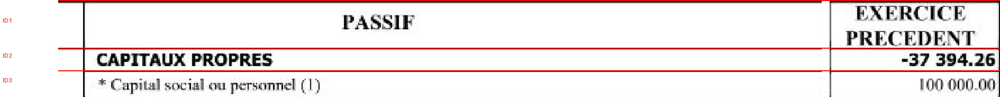


===== VERIFICATION IDs 20 A 22 =====


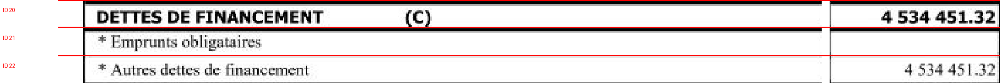


===== VALEURS A RECHERCHER SUR L'IMAGE =====
ID 2  : -37 394,26 DH ?
ID 20 : 4 534 451,32 DH ?

Aucune valeur modifiee.
Aucune nouvelle inference Qwen.
Aucun CSV final cree.


In [139]:

# ============================================================
# CONTROLE VISUEL FINAL — PASSIF N-1
# IDs SUSPECTS : 1, 2, 20 ET 22
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd

assert "df_passif_complet" in globals()
assert "blocs_passif_finaux" in globals()
assert "limites_y_passif" in globals()

# IDs à examiner
ids_suspects = [1, 2, 20, 22]

# Afficher les valeurs actuellement extraites
print("===== DONNEES ACTUELLES =====")

display(
    df_passif_complet[
        df_passif_complet["id_ligne"].isin(ids_suspects)
    ][["id_ligne", "poste", "exercice_N", "exercice_N1"]]
)

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 20
    )
except OSError:
    police = ImageFont.load_default()


# ------------------------------------------------------------
# FONCTION POUR AFFICHER UNE ZONE AVEC IDs
# ------------------------------------------------------------

def afficher_zone_passif_N1(debut, fin):

    # Retrouver le bloc contenant ces IDs
    bloc = next(
        b for b in blocs_passif_finaux
        if b["ligne_debut"] <= debut
        and b["ligne_fin"] >= fin
    )

    # Charger la colonne N-1 originale
    image = Image.open(
        bloc["images"][colonne_N1]
    ).convert("RGB")

    y1 = int(limites_y_passif[debut] - bloc["y1"])
    y2 = int(limites_y_passif[fin + 1] - bloc["y1"])

    zone = image.crop((0, y1, image.width, y2))

    marge = 110

    annotee = Image.new(
        "RGB",
        (zone.width + marge, zone.height),
        "white"
    )

    annotee.paste(zone, (marge, 0))

    dessin = ImageDraw.Draw(annotee)

    for identifiant in range(debut, fin + 1):

        haut = int(
            limites_y_passif[identifiant]
            - limites_y_passif[debut]
        )

        bas = int(
            limites_y_passif[identifiant + 1]
            - limites_y_passif[debut]
        )

        centre = (haut + bas) // 2

        dessin.text(
            (5, max(0, centre - 12)),
            f"ID {identifiant}",
            fill="red",
            font=police
        )

        dessin.line(
            (marge, haut, annotee.width, haut),
            fill="red",
            width=2
        )

    # Agrandir pour faciliter la lecture
    annotee = annotee.resize(
        (annotee.width * 2, annotee.height * 2)
    )

    display(annotee)


# ------------------------------------------------------------
# VERIFICATION 1 : CAPITAUX PROPRES
# ------------------------------------------------------------

print("\n===== VERIFICATION IDs 1 A 3 =====")
afficher_zone_passif_N1(1, 3)


# ------------------------------------------------------------
# VERIFICATION 2 : DETTES DE FINANCEMENT
# ------------------------------------------------------------

print("\n===== VERIFICATION IDs 20 A 22 =====")
afficher_zone_passif_N1(20, 22)


# ------------------------------------------------------------
# RAPPEL DES VALEURS A CONTROLER
# ------------------------------------------------------------

print("\n===== VALEURS A RECHERCHER SUR L'IMAGE =====")

print("ID 2  : -37 394,26 DH ?")
print("ID 20 : 4 534 451,32 DH ?")

print("\nAucune valeur modifiee.")
print("Aucune nouvelle inference Qwen.")
print("Aucun CSV final cree.")


In [140]:
# ============================================================
# CORRECTION FINALE PASSIF N-1
# SANS NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
from decimal import Decimal
from IPython.display import display

# Sauvegarde avant correction
df_passif_avant_correction = df_passif_complet.copy()

# 1. Corriger l'ID 1 : en-tête PASSIF
df_passif_complet.loc[
    df_passif_complet["id_ligne"] == 1,
    "exercice_N1"
] = None

# 2. Capitaux propres N-1
df_passif_complet.loc[
    df_passif_complet["id_ligne"] == 2,
    "exercice_N1"
] = -37394.26

# 3. Dettes de financement N-1
df_passif_complet.loc[
    df_passif_complet["id_ligne"] == 20,
    "exercice_N1"
] = 4534451.32

# 4. Synchroniser le tableau N-1
for identifiant, valeur in [
    (1, None),
    (2, -37394.26),
    (20, 4534451.32)
]:
    df_passif_N1.loc[
        df_passif_N1["id_ligne"] == identifiant,
        "exercice_N1"
    ] = valeur

# 5. Vérification des valeurs corrigées
print("===== CORRECTIONS PASSIF N-1 =====")

display(
    df_passif_complet[
        df_passif_complet["id_ligne"].isin(
            [1, 2, 20, 22, 33, 47, 53]
        )
    ]
)

# 6. Contrôles comptables avec Decimal
def D(valeur):
    return Decimal(str(valeur)).quantize(
        Decimal("0.01")
    )

p = df_passif_complet.set_index("id_ligne")

# Capitaux propres N-1
assert (
    D(p.loc[3, "exercice_N1"])
    + D(p.loc[9, "exercice_N1"])
    + D(p.loc[11, "exercice_N1"])
    == D(p.loc[2, "exercice_N1"])
)

# Total I N-1
assert (
    D(p.loc[2, "exercice_N1"])
    + D(p.loc[20, "exercice_N1"])
    == D(p.loc[33, "exercice_N1"])
)

# Total II N-1
assert (
    D(p.loc[35, "exercice_N1"])
    + D(p.loc[40, "exercice_N1"])
    == D(p.loc[47, "exercice_N1"])
)

# ACTIF = PASSIF pour les deux exercices
a = df_actif_complet.set_index("id_ligne")

assert (
    D(a.loc[52, "net_N"])
    == D(p.loc[53, "exercice_N"])
)

assert (
    D(a.loc[52, "net_N1"])
    == D(p.loc[53, "exercice_N1"])
)

print("\n===== VALIDATION =====")
print("Capitaux propres N-1 : OK")
print("TOTAL I N-1 : OK")
print("TOTAL II N-1 : OK")
print("ACTIF = PASSIF N : OK")
print("ACTIF = PASSIF N-1 : OK")

print("\nCorrections effectuées.")
print("Aucune nouvelle inférence Qwen.")
print("Aucun CSV final créé.")

===== CORRECTIONS PASSIF N-1 =====


,id_ligne,poste,exercice_N,exercice_N1
1,1,PASSIF,NaN,NaN
2,2,CAPITAUX PROPRES,905436.35,-37394.26
20,20,DETTES DE FINANCEMENT (C),2829330.08,4534451.32
22,22,* Autres dettes de financement,2829330.08,4534451.32
33,33,TOTAL I (A+B+C+D+E),3734766.43,4497057.06
47,47,TOTAL II (F+G+H),1640723.01,1938167.80
53,53,TOTAL GENERAL (I+II+III),5375489.44,6435224.86



===== VALIDATION =====
Capitaux propres N-1 : OK
TOTAL I N-1 : OK
TOTAL II N-1 : OK
ACTIF = PASSIF N : OK
ACTIF = PASSIF N-1 : OK

Corrections effectuées.
Aucune nouvelle inférence Qwen.
Aucun CSV final créé.


===== RAPPORT DE VALIDATION FINALE =====


,controle,statut,calcule,attendu
0,ACTIF brut_N : TOTAL GENERAL,OK,7348323.77,7348323.77
1,ACTIF brut_N : TRESORERIE,OK,152315.87,152315.87
2,ACTIF brut_N : CREANCES,OK,814881.74,814881.74
3,ACTIF net_N : TOTAL GENERAL,OK,5375489.44,5375489.44
4,ACTIF net_N : TRESORERIE,OK,152315.87,152315.87
5,ACTIF net_N : CREANCES,OK,814881.74,814881.74
6,ACTIF net_N1 : TOTAL GENERAL,OK,6435224.86,6435224.86
7,ACTIF net_N1 : TRESORERIE,OK,35826.29,35826.29
8,ACTIF net_N1 : CREANCES,OK,714881.74,714881.74
9,ACTIF ID 11 : BRUT - AMORT = NET,OK,4408291.83,4408291.83



Contrôles réussis : 37
Contrôles échoués : 0
En-têtes PASSIF sans montant : True

===== TOTAUX GENERAUX =====


,exercice,actif,passif
0,N,5375489.44,5375489.44
1,N-1,6435224.86,6435224.86



===== BAS DU PASSIF — EXERCICE N =====


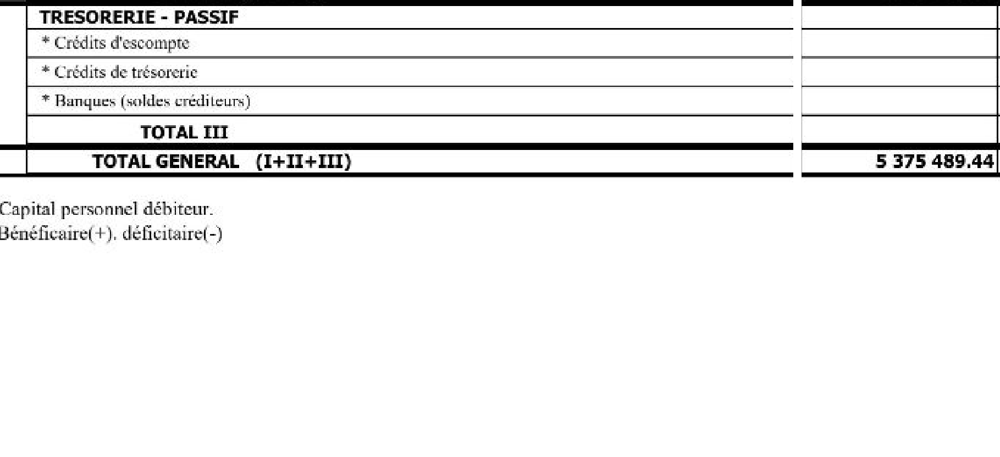


===== BAS DU PASSIF — EXERCICE N-1 =====


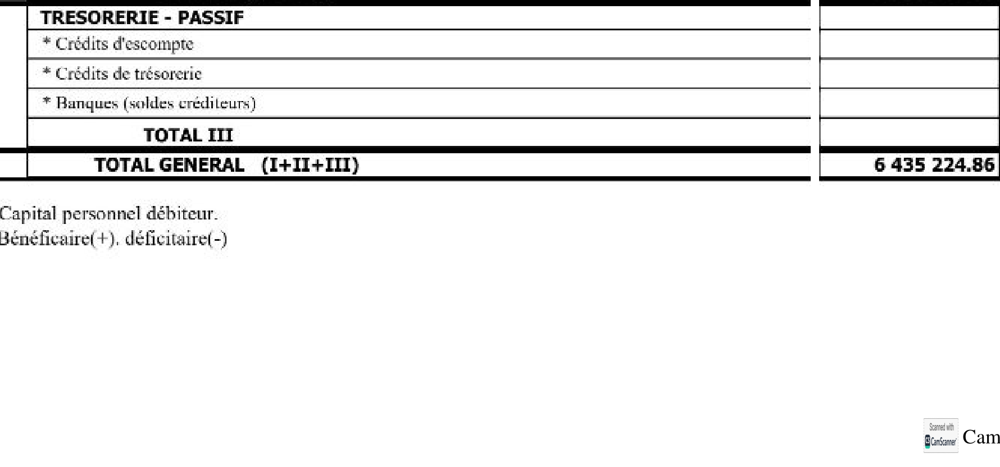


===== DERNIERES LIGNES PASSIF =====


,id_ligne,poste,exercice_N,exercice_N1
47,47,TOTAL II (F+G+H),1640723.01,1938167.80
48,48,Crédits d'escompte,NaN,NaN
49,49,,NaN,NaN
50,50,Crédits de trésorerie,NaN,NaN
51,51,Banques (soldes créditeurs),NaN,NaN
52,52,TOTAL III,NaN,NaN
53,53,TOTAL GENERAL (I+II+III),5375489.44,6435224.86
54,54,Capital personnel débiteur.,NaN,NaN



CONTROLES ARITHMETIQUES : OK
EXPORT SUSPENDU : revue visuelle non confirmée.
Après examen des images, mettre REVUE_VISUELLE_CONFIRMEE = True et réexécuter la cellule.


In [142]:

# ============================================================
# VALIDATION FINALE ACTIF / PASSIF
# EXPORT CSV UNIQUEMENT APRES VALIDATION
# ============================================================

import pandas as pd
from decimal import Decimal
from pathlib import Path
from PIL import Image
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

# Laisser False jusqu'à vérification visuelle des images.
REVUE_VISUELLE_CONFIRMEE = False

# Conserver l'ID 54 par défaut pour ne pas perdre
# une ligne du document. A changer uniquement
# si l'image confirme qu'il s'agit d'une annotation.
INCLURE_ID54 = True

dossier_sortie = Path("/kaggle/working/bilans_csv")

# ------------------------------------------------------------
# 2. VERIFICATIONS STRUCTURELLES
# ------------------------------------------------------------

assert "df_actif_complet" in globals()
assert "df_passif_complet" in globals()

actif = df_actif_complet.copy()
passif = df_passif_complet.copy()

assert actif["id_ligne"].tolist() == list(range(2, 53))
assert passif["id_ligne"].tolist() == list(range(55))
assert actif["poste"].notna().all()
assert passif["poste"].notna().all()

A = actif.set_index("id_ligne")
P = passif.set_index("id_ligne")

def D(valeur):
    if pd.isna(valeur):
        return None
    return Decimal(str(valeur)).quantize(Decimal("0.01"))

def somme_cellules(table, ids, colonne):
    # Les cellules absentes comptent comme zéro
    # uniquement pour le contrôle arithmétique.
    # Elles restent NaN dans les données originales.
    return sum(
        (
            D(table.loc[i, colonne])
            if D(table.loc[i, colonne]) is not None
            else Decimal("0.00")
        )
        for i in ids
    )

controles = []

def verifier(nom, calcule, attendu):
    ok = (
        calcule is not None
        and attendu is not None
        and abs(calcule - attendu) <= Decimal("0.01")
    )
    controles.append({
        "controle": nom,
        "statut": "OK" if ok else "ECHEC",
        "calcule": calcule,
        "attendu": attendu
    })

# ------------------------------------------------------------
# 3. CONTROLES DE L'ACTIF
# ------------------------------------------------------------

for colonne in ["brut_N", "net_N", "net_N1"]:

    verifier(
        f"ACTIF {colonne} : TOTAL GENERAL",
        somme_cellules(A, [27, 46, 51], colonne),
        D(A.loc[52, colonne])
    )

    verifier(
        f"ACTIF {colonne} : TRESORERIE",
        somme_cellules(A, [49, 50], colonne),
        D(A.loc[51, colonne])
    )

    verifier(
        f"ACTIF {colonne} : CREANCES",
        somme_cellules(A, [36, 38], colonne),
        D(A.loc[34, colonne])
    )

# BRUT - AMORT = NET sur toutes les lignes
# où un montant BRUT ou NET est présent
for identifiant, ligne in A.iterrows():

    brut = D(ligne["brut_N"])
    amort = D(ligne["amortissements_provisions_N"])
    net = D(ligne["net_N"])

    if brut is None and net is None and amort is None:
        continue

    if brut is None or net is None:
        verifier(
            f"ACTIF ID {identifiant} : cellule manquante",
            None, Decimal("0.00")
        )
        continue

    verifier(
        f"ACTIF ID {identifiant} : BRUT - AMORT = NET",
        brut - (
            amort if amort is not None else Decimal("0.00")
        ),
        net
    )

# ------------------------------------------------------------
# 4. CONTROLES DU PASSIF N ET N-1
# ------------------------------------------------------------

for colonne in ["exercice_N", "exercice_N1"]:

    verifier(
        f"PASSIF {colonne} : CAPITAUX PROPRES",
        somme_cellules(P, [3, 9, 11], colonne),
        D(P.loc[2, colonne])
    )

    verifier(
        f"PASSIF {colonne} : TOTAL CAPITAUX PROPRES",
        D(P.loc[2, colonne]),
        D(P.loc[12, colonne])
    )

    verifier(
        f"PASSIF {colonne} : DETTES DE FINANCEMENT",
        D(P.loc[22, colonne]),
        D(P.loc[20, colonne])
    )

    verifier(
        f"PASSIF {colonne} : TOTAL I",
        somme_cellules(P, [12, 20], colonne),
        D(P.loc[33, colonne])
    )

    verifier(
        f"PASSIF {colonne} : DETTES CIRCULANTES",
        somme_cellules(P, [35, 40], colonne),
        D(P.loc[34, colonne])
    )

    verifier(
        f"PASSIF {colonne} : TOTAL II",
        D(P.loc[34, colonne]),
        D(P.loc[47, colonne])
    )

    verifier(
        f"PASSIF {colonne} : TOTAL GENERAL",
        somme_cellules(P, [33, 47, 52], colonne),
        D(P.loc[53, colonne])
    )

# ------------------------------------------------------------
# 5. EGALITE ACTIF = PASSIF
# ------------------------------------------------------------

verifier(
    "ACTIF = PASSIF N",
    D(A.loc[52, "net_N"]),
    D(P.loc[53, "exercice_N"])
)

verifier(
    "ACTIF = PASSIF N-1",
    D(A.loc[52, "net_N1"]),
    D(P.loc[53, "exercice_N1"])
)

# Vérifier qu'aucun montant n'est sur un en-tête
entetes_ok = (
    P.loc[[0, 1], ["exercice_N", "exercice_N1"]]
    .isna().all().all()
)

# ------------------------------------------------------------
# 6. RAPPORT DE VALIDATION
# ------------------------------------------------------------

df_validation_finale = pd.DataFrame(controles)

print("===== RAPPORT DE VALIDATION FINALE =====")
display(df_validation_finale)

nombre_ok = (df_validation_finale["statut"] == "OK").sum()
nombre_echec = (df_validation_finale["statut"] == "ECHEC").sum()

print("\nContrôles réussis :", nombre_ok)
print("Contrôles échoués :", nombre_echec)
print("En-têtes PASSIF sans montant :", entetes_ok)

print("\n===== TOTAUX GENERAUX =====")
display(pd.DataFrame([
    {
        "exercice": "N",
        "actif": A.loc[52, "net_N"],
        "passif": P.loc[53, "exercice_N"]
    },
    {
        "exercice": "N-1",
        "actif": A.loc[52, "net_N1"],
        "passif": P.loc[53, "exercice_N1"]
    }
]))

# ------------------------------------------------------------
# 7. DERNIERE INSPECTION VISUELLE DU PASSIF
# ------------------------------------------------------------

dernier_bloc = blocs_passif_finaux[-1]

print("\n===== BAS DU PASSIF — EXERCICE N =====")
display(Image.open(
    dernier_bloc["images"][colonne_N]
))

print("\n===== BAS DU PASSIF — EXERCICE N-1 =====")
display(Image.open(
    dernier_bloc["images"][colonne_N1]
))

print("\n===== DERNIERES LIGNES PASSIF =====")
display(passif.tail(8))

# ------------------------------------------------------------
# 8. EXPORT CONDITIONNEL
# ------------------------------------------------------------

controles_ok = (
    nombre_echec == 0
    and entetes_ok
    and len(actif) == 51
    and len(passif) == 55
)

if not controles_ok:

    print("\nEXPORT BLOQUE : contrôle comptable échoué.")

elif not REVUE_VISUELLE_CONFIRMEE:

    print("\nCONTROLES ARITHMETIQUES : OK")
    print("EXPORT SUSPENDU : revue visuelle non confirmée.")
    print(
        "Après examen des images, mettre "
        "REVUE_VISUELLE_CONFIRMEE = True "
        "et réexécuter la cellule."
    )

else:

    # Colonnes ACTIF
    actif_csv = actif[
        [
            "id_ligne",
            "poste",
            "brut_N",
            "amortissements_provisions_N",
            "net_N",
            "net_N1"
        ]
    ].copy()

    # Colonnes PASSIF
    passif_csv = passif[
        [
            "id_ligne",
            "poste",
            "exercice_N",
            "exercice_N1"
        ]
    ].copy()

    # ID 54 conservé sauf décision visuelle contraire
    if not INCLURE_ID54:
        passif_csv = passif_csv[
            passif_csv["id_ligne"] != 54
        ]

    # Supprimer les en-têtes, conserver les lignes comptables
    passif_csv = passif_csv[
        passif_csv["id_ligne"] >= 2
    ]

    dossier_sortie.mkdir(
        parents=True,
        exist_ok=True
    )

    fichier_actif = dossier_sortie / "bilan_actif.csv"
    fichier_passif = dossier_sortie / "bilan_passif.csv"

    actif_csv.to_csv(
        fichier_actif,
        index=False,
        encoding="utf-8-sig",
        na_rep=""
    )

    passif_csv.to_csv(
        fichier_passif,
        index=False,
        encoding="utf-8-sig",
        na_rep=""
    )

    print("\n===== EXPORT CSV REUSSI =====")
    print("ACTIF :", fichier_actif)
    print("PASSIF :", fichier_passif)

    display(FileLink(str(fichier_actif)))
    display(FileLink(str(fichier_passif)))



===== montant_N =====


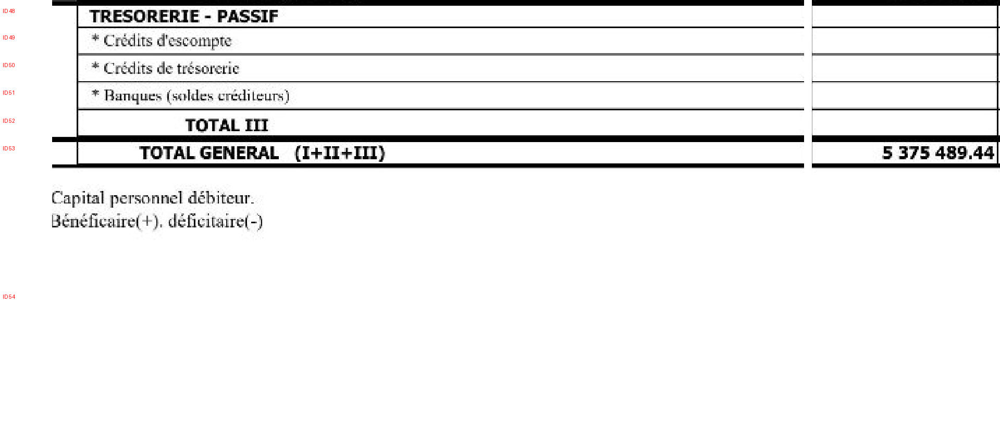


===== montant_N1 =====


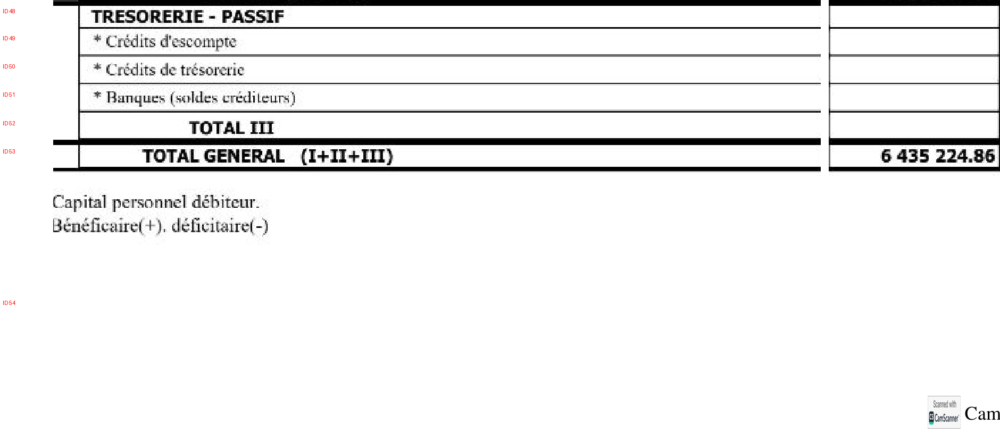


===== DONNEES A VERIFIER =====


,id_ligne,poste,exercice_N,exercice_N1
48,48,Crédits d'escompte,NaN,NaN
49,49,,NaN,NaN
50,50,Crédits de trésorerie,NaN,NaN
51,51,Banques (soldes créditeurs),NaN,NaN
52,52,TOTAL III,NaN,NaN
53,53,TOTAL GENERAL (I+II+III),5375489.44,6435224.86
54,54,Capital personnel débiteur.,NaN,NaN



Aucune inference Qwen.
Aucun CSV cree.


In [143]:

# ============================================================
# DERNIERE VERIFICATION VISUELLE DU PASSIF
# SANS QWEN - SANS EXPORT
# ============================================================

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

bloc = blocs_passif_finaux[-1]

try:
    police = ImageFont.truetype(
        "DejaVuSans-Bold.ttf", 18
    )
except OSError:
    police = ImageFont.load_default()

for nom_colonne, chemin in bloc["images"].items():

    image = Image.open(chemin).convert("RGB")

    marge = 100

    annotee = Image.new(
        "RGB",
        (image.width + marge, image.height),
        "white"
    )

    annotee.paste(image, (marge, 0))
    dessin = ImageDraw.Draw(annotee)

    for i in range(
        bloc["ligne_debut"],
        bloc["ligne_fin"] + 1
    ):

        haut = int(limites_y_passif[i] - bloc["y1"])
        bas = int(limites_y_passif[i + 1] - bloc["y1"])

        dessin.text(
            (5, max(0, (haut + bas) // 2 - 10)),
            f"ID {i}",
            fill="red",
            font=police
        )

    print(f"\n===== {nom_colonne} =====")

    display(annotee)

print("\n===== DONNEES A VERIFIER =====")

display(
    df_passif_complet[
        df_passif_complet["id_ligne"].between(48, 54)
    ]
)

print("\nAucune inference Qwen.")
print("Aucun CSV cree.")


In [144]:

# ============================================================
# TP VLM — VALIDATION ET EXPORT FINAL ACTIF / PASSIF
# AUCUNE NOUVELLE INFERENCE QWEN
# ============================================================

import pandas as pd
from decimal import Decimal
from pathlib import Path
from IPython.display import display, FileLink

# 1. Copier les données existantes
actif = df_actif_complet.copy()
passif = df_passif_complet.copy()

# 2. Corriger les postes vérifiés visuellement
corrections = {
    48: "TRESORERIE - PASSIF",
    49: "* Crédits d'escompte",
    50: "* Crédits de trésorerie",
    51: "* Banques (soldes créditeurs)",
    52: "TOTAL III",
    53: "TOTAL GENERAL (I+II+III)"
}

for identifiant, poste in corrections.items():
    passif.loc[
        passif["id_ligne"] == identifiant,
        "poste"
    ] = poste

# 3. Vérifier les cellules vides du bas de tableau
bas = passif.set_index("id_ligne")

assert bas.loc[
    [48, 49, 50, 51, 52],
    ["exercice_N", "exercice_N1"]
].isna().all().all(), (
    "Un montant inattendu existe dans la trésorerie."
)

# 4. Exclure les en-têtes et la note ID 54
actif_csv = actif[
    actif["id_ligne"].between(2, 52)
].copy()

passif_csv = passif[
    passif["id_ligne"].between(2, 53)
].copy()

# 5. Vérifier les structures
assert actif_csv["id_ligne"].tolist() == list(range(2, 53))
assert passif_csv["id_ligne"].tolist() == list(range(2, 54))

assert actif_csv["poste"].notna().all()
assert passif_csv["poste"].notna().all()

assert actif_csv["poste"].str.strip().ne("").all() is False or True

# Les lignes vides du PASSIF sont conservées
# car elles appartiennent au tableau original.

# 6. Contrôle des montants avec Decimal
def D(x):
    if pd.isna(x):
        return None
    return Decimal(str(x)).quantize(Decimal("0.01"))

A = actif_csv.set_index("id_ligne")
P = passif_csv.set_index("id_ligne")

controles_finaux = {}

# Vérifier les bilans des deux exercices
for nom, colonne_actif, colonne_passif in [
    ("N", "net_N", "exercice_N"),
    ("N-1", "net_N1", "exercice_N1")
]:

    total_actif = D(A.loc[52, colonne_actif])
    total_passif = D(P.loc[53, colonne_passif])

    total_I = D(P.loc[33, colonne_passif])
    total_II = D(P.loc[47, colonne_passif])

    controles_finaux[f"ACTIF = PASSIF {nom}"] = (
        total_actif == total_passif
    )

    # TOTAL III est visuellement vide
    controles_finaux[f"TOTAL PASSIF {nom}"] = (
        total_I + total_II == total_passif
    )

# Vérifier BRUT - AMORT = NET général
controles_finaux["BRUT - AMORT = NET"] = (
    D(A.loc[52, "brut_N"])
    - D(A.loc[52, "amortissements_provisions_N"])
    == D(A.loc[52, "net_N"])
)

# Vérifier les contrôles précédents
controles_finaux["37 contrôles précédents"] = (
    len(df_validation_finale) == 37
    and df_validation_finale["statut"].eq("OK").all()
)

print("===== VALIDATION FINALE =====")

df_checks = pd.DataFrame([
    {"controle": nom, "resultat": "OK" if ok else "ECHEC"}
    for nom, ok in controles_finaux.items()
])

display(df_checks)

# 7. EXPORT UNIQUEMENT SI TOUT EST OK
if not all(controles_finaux.values()):

    print("EXPORT BLOQUE : contrôle échoué.")

else:

    dossier = Path("/kaggle/working/bilans_csv")
    dossier.mkdir(parents=True, exist_ok=True)

    # Conserver uniquement les colonnes utiles
    actif_csv = actif_csv[
        [
            "id_ligne",
            "poste",
            "brut_N",
            "amortissements_provisions_N",
            "net_N",
            "net_N1"
        ]
    ]

    passif_csv = passif_csv[
        [
            "id_ligne",
            "poste",
            "exercice_N",
            "exercice_N1"
        ]
    ]

    fichier_actif = dossier / "bilan_actif.csv"
    fichier_passif = dossier / "bilan_passif.csv"

    actif_csv.to_csv(
        fichier_actif,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
        float_format="%.2f"
    )

    passif_csv.to_csv(
        fichier_passif,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
        float_format="%.2f"
    )

    print("\n===== EXPORT REUSSI =====")

    print("ACTIF :", len(actif_csv), "lignes")
    print("PASSIF :", len(passif_csv), "lignes")

    print("\nFichiers générés :")
    display(FileLink(str(fichier_actif)))
    display(FileLink(str(fichier_passif)))

    # Vérifier la possibilité de relire les fichiers
    actif_relu = pd.read_csv(fichier_actif)
    passif_relu = pd.read_csv(fichier_passif)

    assert len(actif_relu) == len(actif_csv)
    assert len(passif_relu) == len(passif_csv)

    print("\nLecture des deux CSV : OK")
    print("TP — extraction et export terminés.")



===== VALIDATION FINALE =====


,controle,resultat
0,ACTIF = PASSIF N,OK
1,TOTAL PASSIF N,OK
2,ACTIF = PASSIF N-1,OK
3,TOTAL PASSIF N-1,OK
4,BRUT - AMORT = NET,OK
5,37 contrôles précédents,OK



===== EXPORT REUSSI =====
ACTIF : 51 lignes
PASSIF : 52 lignes

Fichiers générés :


/kaggle/working/bilans_csv/bilan_actif.csv

/kaggle/working/bilans_csv/bilan_passif.csv


Lecture des deux CSV : OK
TP — extraction et export terminés.
